In [1]:
import pandas as pd
import numpy as np
import os
import seaborn as sns
import matplotlib.pyplot as plt
import librosa
import librosa.display
from IPython.display import Audio
import csv
import warnings
warnings.filterwarnings('ignore')
import pywt
import librosa
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

In [2]:
# Define CNN-LSTM model
class CNN_LSTM_Model(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, num_classes):
        super(CNN_LSTM_Model, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.conv1 = nn.Conv1d(1, 32, kernel_size=3, stride=1, padding=1)
        self.bn1 = nn.BatchNorm1d(32)  # Add batch normalization layer
        self.conv2 = nn.Conv1d(32, 64, kernel_size=3, stride=1, padding=1)
        self.bn2 = nn.BatchNorm1d(64)  # Add batch normalization layer
        self.pool = nn.MaxPool1d(kernel_size=2, stride=2)
        self.lstm = nn.LSTM(64, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, num_classes)
        self.relu = nn.ReLU()
        self.softmax = nn.Softmax(dim=1)
        
    def forward(self, x):
        x = x.unsqueeze(1)  # Add channel dimension
        x = self.conv1(x)
        x = self.bn1(x)  # Apply batch normalization
        x = self.relu(x)
        x = self.pool(x)
        x = self.conv2(x)
        x = self.bn2(x)  # Apply batch normalization
        x = self.relu(x)
        x = self.pool(x)
        x = x.permute(0, 2, 1)  # Reshape for LSTM input (batch_size, seq_len, input_size)
        lstm_out, _ = self.lstm(x)
        lstm_out = lstm_out[:, -1, :]  # Take only the output of the last time step
        out = self.fc(lstm_out)
        out = self.softmax(out)
        return out


In [3]:
# Define your custom dataset
class SpeechDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


In [4]:
# Function to calculate evaluation metrics
def calculate_metrics(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    
    # Convert from one-hot encoding to class labels if needed
    if len(y_true.shape) > 1:
        y_true = np.argmax(y_true, axis=1)
    if len(y_pred.shape) > 1:
        y_pred = np.argmax(y_pred, axis=1)
    
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='weighted')
    recall = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')
    return accuracy, precision, recall, f1


# Validation function
def validate(model, val_loader, criterion, device):
    model.eval()
    val_loss = 0.0
    y_true = []
    y_pred = []
    
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs = inputs.to(device)
            labels = torch.argmax(labels, axis=1).to(device)  # Convert one-hot to class labels
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs, 1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())

    val_loss /= len(val_loader.dataset)
    accuracy, precision, recall, f1 = calculate_metrics(y_true, y_pred)
    
    return val_loss, accuracy, precision, recall, f1


In [5]:
def plot_graphs(epochs_path,
                num_epochs,
                train_losses,
                val_losses,
                train_accuracies,
                val_accuracies,
                train_precisions,
                val_precisions,
                train_recalls,
                val_recalls,
                train_f1s,
                val_f1s):
    
    
    # Plotting the metrics
    epochs = list(range(num_epochs))

    plt.figure(figsize=(10, 6))
    
    plt.plot(epochs, train_losses, label='Training Loss')
    plt.plot(epochs, val_losses, label='Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.title('Training and Validation Loss')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'loss_plot.png'))
    plt.show()
    plt.close()

    plt.figure(figsize=(10, 6))
    
    plt.plot(epochs, train_accuracies, label='Training Accuracy')
    plt.plot(epochs, val_accuracies, label='Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'accuracy_plot.png'))
    plt.show()
    plt.close()


    plt.figure(figsize=(10, 6))

    plt.plot(epochs, train_precisions, label='Training Precision')
    plt.plot(epochs, val_precisions, label='Validation Precision')
    plt.xlabel('Epochs')
    plt.ylabel('Precision')
    plt.title('Training and Validation Precision')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'precision_plot.png'))
    plt.show()
    plt.close()
    
    plt.figure(figsize=(10, 6))

    plt.plot(epochs, train_recalls, label='Training Recall')
    plt.plot(epochs, val_recalls, label='Validation Recall')
    plt.xlabel('Epochs')
    plt.ylabel('Recall')
    plt.title('Training and Validation Recall')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'recall_plot.png'))
    plt.show()
    plt.close()

    plt.figure(figsize=(10, 6))
    
    plt.plot(epochs, train_f1s, label='Training F1-score')
    plt.plot(epochs, val_f1s, label='Validation F1-score')
    plt.xlabel('Epochs')
    plt.ylabel('F1-score')
    plt.title('Training and Validation F1-score')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'f1Score_plot.png'))
    plt.show()
    plt.close()

    return "Model Training and Evaluation Successfully completed"

In [6]:
def generate_confusion_matrix(model, test_loader, device):
    model.eval()
    y_true = []
    y_pred = []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            labels = torch.argmax(labels, axis=1).to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())
            
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='weighted')
    recall = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')        
    print(f"\nAccuracy : {accuracy}\nPrecision : {precision}\nRecall : {recall}\nF1-Score : {f1}")

    conf_matrix = confusion_matrix(y_true, y_pred)
    return conf_matrix, y_true, y_pred

def plot_confusion_matrices(conf_matrix, normalized_conf_matrix, class_labels, epochs_path):
    plt.figure(figsize=(10, 6))
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', annot_kws={"fontsize": 12})  
    plt.xlabel('Predicted labels')
    plt.ylabel('True labels')
    plt.title('Confusion Matrix')
    plt.xticks(ticks=np.arange(len(class_labels)), labels=class_labels)
    plt.yticks(ticks=np.arange(len(class_labels)), labels=class_labels)
    plt.savefig(os.path.join(epochs_path, 'Confusion Matrix.png'))
    plt.show()
    
    plt.figure(figsize=(10, 6))
    sns.heatmap(normalized_conf_matrix, annot=True, cmap='Blues', annot_kws={"fontsize": 12})
    plt.xlabel('Predicted labels')
    plt.ylabel('True labels')
    plt.title('Normalized Confusion Matrix')
    plt.xticks(ticks=np.arange(len(class_labels)), labels=class_labels)
    plt.yticks(ticks=np.arange(len(class_labels)), labels=class_labels)
    plt.savefig(os.path.join(epochs_path, 'Normalized Confusion Matrix.png'))
    plt.show()


In [7]:
def train_model():
    
    global dwt_level,model,mfcc
    
    dataset=input("Enter dataset name:\ntess, savee, crema, ravdess\n ")
    dwt_level = int(input("Enter dwt level:  "))
    mfcc=int(input("Enter Number of MFCC coefficients : "))
    if dataset=="tess":
        csv_file=r"C:\Users\Tharunraj_S\Desktop\Major project\Dataset\tess_dataset.csv"
    
    elif dataset=="savee":
        csv_file=r"C:\Users\Tharunraj_S\Desktop\Major project\Dataset\savee_dataset.csv"
    
    elif dataset=="crema":
        csv_file=r"C:\Users\Tharunraj_S\Desktop\Major project\Dataset\crema_dataset.csv"
    
    elif dataset=="ravdess":
        csv_file=r"C:\Users\Tharunraj_S\Desktop\Major project\Dataset\ravdess_dataset.csv"
    
    
    df = pd.read_csv(csv_file)
    X_mfcc = df['File_Path'].apply(lambda x: extract_features(x,dwt_level))
    
    X = [x for x in X_mfcc]
    X = np.array(X)
    
    
    class_labels = df['Emotion_Label'].unique().tolist()
    
    from sklearn.preprocessing import OneHotEncoder
    enc = OneHotEncoder()
    y = enc.fit_transform(df[['Emotion_Label']])
    y = y.toarray()
    
    train_loader, val_loader = Loader(X, y) 
      
    # Determine input size based on wavelet level
    input_size = mfcc*(dwt_level+1)
    hidden_size = 256
    num_layers = 1
        
    print(f"Input size for wavelet level {dwt_level} = {input_size}")
    # Initialize model

    model = CNN_LSTM_Model(input_size, hidden_size, num_layers, num_classes)
    
    model_path=model.__class__.__name__
    if not os.path.exists( model_path):
        os.makedirs( model_path)
        
    # Loss and optimizer
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # Reset model parameters
    model.apply(reset_parameters)
    
    # Reset optimizer state
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # Initialize variables to store best validation metrics and corresponding model state
    best_val_loss = float('inf')
    best_model_state = None
    
    # Training loop
    
    train_losses = []
    val_losses = []
    train_accuracies = []
    val_accuracies = []
    train_precisions = []
    val_precisions = []
    train_recalls = []
    val_recalls = []
    train_f1s = []
    val_f1s = []
    
    print("Training with DWT level:", dwt_level)
    print(
          f'Hidden Size : {hidden_size}\n' 
          f'Model Name: {model.__class__.__name__}\n' 
          f'\nX Shape : {X.shape}'
          f'\nY Shape : {y.shape}\n')
    num_epochs =int(input("Enter no. of epochs "))
    dataset_path = dataset
    dataset_dir = os.path.join(model_path,dataset_path)
    if not os.path.exists(dataset_dir):
        os.makedirs(dataset_dir)
        
    mfcc_path="N_MFCC"+str(mfcc)
    mfcc_dir=os.path.join(dataset_dir,mfcc_path)
    
    dwt_level_path = "level "+str(dwt_level)+" wavelet"
    dwt_level_dir = os.path.join(mfcc_dir,dwt_level_path)
    if not os.path.exists(dwt_level_dir):
        os.makedirs(dwt_level_dir)
    
    # Create a directory with the name as the number of epochs
    epochs_dir = str(num_epochs)+" Epochs"
    epochs_path = os.path.join(dwt_level_dir,epochs_dir)
    if not os.path.exists(epochs_path):
        os.makedirs(epochs_path)
        
    with open(os.path.join(epochs_path,'metrics.csv'), mode='w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(['Epoch', 'Training Loss', 'Training Accuracy','Training Precision', 'Training Recall', 'Training F1-Score'
                         , 'Validation Loss', 'Validation Accuracy','Validation Precision', 'Validation Recall', 'Validation F1-Score'])

        for epoch in range(num_epochs):
            model.train()
            running_loss = 0.0

            for inputs, labels in train_loader:
                inputs = inputs.to(device)
                labels = labels.to(device)
                optimizer.zero_grad()
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                loss.backward()
                optimizer.step()
                running_loss += loss.item() * inputs.size(0)

            # Calculate training loss
            train_loss = running_loss / len(train_loader.dataset)
            train_losses.append(train_loss)

            # Calculate training metrics
            y_true_train = []
            y_pred_train = []
            with torch.no_grad():
                for inputs, labels in train_loader:
                    inputs = inputs.to(device)
                    labels = labels.to(device)
                    outputs = model(inputs)
                    _, predicted = torch.max(outputs, 1)
                    y_true_train.extend(labels.cpu().numpy())
                    y_pred_train.extend(predicted.cpu().numpy())

            train_accuracy, train_precision, train_recall, train_f1 = calculate_metrics(y_true_train, y_pred_train)
            train_accuracies.append(train_accuracy)
            train_precisions.append(train_precision)
            train_recalls.append(train_recall)
            train_f1s.append(train_f1)

            # Validate the model
            val_loss, val_accuracy, val_precision, val_recall, val_f1 = validate(model, val_loader, criterion, device)
            val_losses.append(val_loss)
            val_accuracies.append(val_accuracy)
            val_precisions.append(val_precision)
            val_recalls.append(val_recall)
            val_f1s.append(val_f1)

            # Write metrics to CSV
            writer.writerow([epoch+1, train_loss, train_accuracy, train_precision, train_recall, train_f1,
                             val_loss, val_accuracy, val_precision, val_recall, val_f1])


            print(f'Epoch [{epoch+1}/{num_epochs}],\n'
                  f'Training Loss: {train_loss:.4f}, Training Accuracy: {train_accuracy:.4f}, '
                  f'Training Precision:{train_precision:.4f},Training Recall:{train_recall:.4f},Training F1-Score:{train_f1:.4f}\n'
                  f'Validation Loss: {val_loss:.4f}, Validation Accuracy: {val_accuracy:.4f}, '
                  f'Validation Precision:{val_precision:.4f},Validation Recall:{val_recall:.4f},Validation F1-Score:{val_f1:.4f}'
                  )
            # Save the model
            torch.save(model.state_dict(), os.path.join(epochs_path, 'LSTM_model_(last).pth'))

            # Save the model if it has the best validation loss so far
            if val_loss < best_val_loss:
                best_val_loss = val_loss
                best_model_state = model.state_dict()
                torch.save(model.state_dict(), os.path.join(epochs_path, 'LSTM_model_(best).pth'))

    # Load the best model state
    model.load_state_dict(best_model_state)
    conf_matrix, _, _ = generate_confusion_matrix(model, val_loader, device)
    normalized_conf_matrix = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]
    plot_confusion_matrices(conf_matrix, normalized_conf_matrix, class_labels, epochs_path)
     
    return plot_graphs(epochs_path,num_epochs,train_losses,val_losses,train_accuracies,val_accuracies,train_precisions,val_precisions,train_recalls,val_recalls,train_f1s,val_f1s)


def reset_parameters(layer):
    if isinstance(layer, nn.Conv1d) or isinstance(layer, nn.Linear):
        nn.init.xavier_uniform_(layer.weight)
        nn.init.zeros_(layer.bias)

In [8]:
def Loader(X,y):
    
    global num_classes

    
    num_classes = y.shape[1]
    print(f"No. of classes {num_classes}")
    
    # Train-test split
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Convert to PyTorch tensors
    X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
    X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
    y_train_tensor = torch.tensor(y_train, dtype=torch.float32)
    y_test_tensor = torch.tensor(y_test, dtype=torch.float32)

    train_dataset = SpeechDataset(X_train_tensor, y_train_tensor)
    val_dataset = SpeechDataset(X_test_tensor, y_test_tensor)


    train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
    val_loader= DataLoader(val_dataset, batch_size=64, shuffle=True)

    return train_loader, val_loader

In [9]:
def extract_features(filename,dwt_level):
    
    y, sr = librosa.load(filename, duration=3, offset=0.5)
    coeffs = pywt.wavedec(y, 'db1', level=dwt_level) # Adjust wavelet and decomposition level as needed
    mfcc_features = []
    for coeff in coeffs:
        mfcc_coeff = np.mean(librosa.feature.mfcc(y=coeff.astype(float), sr=sr, n_mfcc=mfcc).T, axis=0)
        mfcc_features.extend(mfcc_coeff)
    return np.array(mfcc_features)


In [10]:
# Define device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# SAVEE
# DWT 4
# N_MFCC 40
# 500 epoch

Enter dataset name:
tess, savee, crema, ravdess
 savee
Enter dwt level:  1
Enter Number of MFCC coefficients : 40
No. of classes 6
Input size for wavelet level 1 = 80
Training with DWT level: 1
Hidden Size : 256
Model Name: CNN_LSTM_Model

X Shape : (480, 80)
Y Shape : (480, 6)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.7880, Training Accuracy: 0.2474, Training Precision:0.0612,Training Recall:0.2474,Training F1-Score:0.0981
Validation Loss: 1.7611, Validation Accuracy: 0.2604, Validation Precision:0.0678,Validation Recall:0.2604,Validation F1-Score:0.1076
Epoch [2/500],
Training Loss: 1.7581, Training Accuracy: 0.2292, Training Precision:0.0525,Training Recall:0.2292,Training F1-Score:0.0855
Validation Loss: 1.6928, Validation Accuracy: 0.3333, Validation Precision:0.1111,Validation Recall:0.3333,Validation F1-Score:0.1667
Epoch [3/500],
Training Loss: 1.7543, Training Accuracy: 0.2448, Training Precision:0.1368,Training Recall:0.2448,Training F1-Score:0.1017
Validation 

Epoch [30/500],
Training Loss: 1.5205, Training Accuracy: 0.5156, Training Precision:0.3630,Training Recall:0.5156,Training F1-Score:0.3971
Validation Loss: 1.4753, Validation Accuracy: 0.5833, Validation Precision:0.4963,Validation Recall:0.5833,Validation F1-Score:0.4806
Epoch [31/500],
Training Loss: 1.5276, Training Accuracy: 0.5182, Training Precision:0.4500,Training Recall:0.5182,Training F1-Score:0.4028
Validation Loss: 1.5071, Validation Accuracy: 0.5312, Validation Precision:0.3877,Validation Recall:0.5312,Validation F1-Score:0.4396
Epoch [32/500],
Training Loss: 1.5265, Training Accuracy: 0.5391, Training Precision:0.4318,Training Recall:0.5391,Training F1-Score:0.4353
Validation Loss: 1.4692, Validation Accuracy: 0.5625, Validation Precision:0.4414,Validation Recall:0.5625,Validation F1-Score:0.4701
Epoch [33/500],
Training Loss: 1.5159, Training Accuracy: 0.5443, Training Precision:0.4544,Training Recall:0.5443,Training F1-Score:0.4418
Validation Loss: 1.4832, Validation Ac

Epoch [60/500],
Training Loss: 1.4593, Training Accuracy: 0.5859, Training Precision:0.4439,Training Recall:0.5859,Training F1-Score:0.4991
Validation Loss: 1.4254, Validation Accuracy: 0.6146, Validation Precision:0.4861,Validation Recall:0.6146,Validation F1-Score:0.5325
Epoch [61/500],
Training Loss: 1.4654, Training Accuracy: 0.5859, Training Precision:0.4488,Training Recall:0.5859,Training F1-Score:0.4971
Validation Loss: 1.4334, Validation Accuracy: 0.6042, Validation Precision:0.4837,Validation Recall:0.6042,Validation F1-Score:0.5158
Epoch [62/500],
Training Loss: 1.4669, Training Accuracy: 0.5964, Training Precision:0.4467,Training Recall:0.5964,Training F1-Score:0.5054
Validation Loss: 1.4117, Validation Accuracy: 0.6458, Validation Precision:0.4992,Validation Recall:0.6458,Validation F1-Score:0.5587
Epoch [63/500],
Training Loss: 1.4559, Training Accuracy: 0.5990, Training Precision:0.4523,Training Recall:0.5990,Training F1-Score:0.5095
Validation Loss: 1.4142, Validation Ac

Epoch [90/500],
Training Loss: 1.4390, Training Accuracy: 0.6562, Training Precision:0.6690,Training Recall:0.6562,Training F1-Score:0.6244
Validation Loss: 1.3761, Validation Accuracy: 0.6667, Validation Precision:0.6728,Validation Recall:0.6667,Validation F1-Score:0.6341
Epoch [91/500],
Training Loss: 1.4042, Training Accuracy: 0.6641, Training Precision:0.6691,Training Recall:0.6641,Training F1-Score:0.6371
Validation Loss: 1.3723, Validation Accuracy: 0.6771, Validation Precision:0.6577,Validation Recall:0.6771,Validation F1-Score:0.6453
Epoch [92/500],
Training Loss: 1.4012, Training Accuracy: 0.6562, Training Precision:0.6571,Training Recall:0.6562,Training F1-Score:0.6475
Validation Loss: 1.4185, Validation Accuracy: 0.6354, Validation Precision:0.6414,Validation Recall:0.6354,Validation F1-Score:0.6266
Epoch [93/500],
Training Loss: 1.3956, Training Accuracy: 0.6406, Training Precision:0.6398,Training Recall:0.6406,Training F1-Score:0.6093
Validation Loss: 1.3567, Validation Ac

Epoch [120/500],
Training Loss: 1.3644, Training Accuracy: 0.6667, Training Precision:0.6835,Training Recall:0.6667,Training F1-Score:0.6550
Validation Loss: 1.3616, Validation Accuracy: 0.6771, Validation Precision:0.6885,Validation Recall:0.6771,Validation F1-Score:0.6633
Epoch [121/500],
Training Loss: 1.3865, Training Accuracy: 0.6953, Training Precision:0.7020,Training Recall:0.6953,Training F1-Score:0.6795
Validation Loss: 1.3658, Validation Accuracy: 0.6667, Validation Precision:0.6638,Validation Recall:0.6667,Validation F1-Score:0.6400
Epoch [122/500],
Training Loss: 1.3455, Training Accuracy: 0.7240, Training Precision:0.7276,Training Recall:0.7240,Training F1-Score:0.7111
Validation Loss: 1.3659, Validation Accuracy: 0.6875, Validation Precision:0.6882,Validation Recall:0.6875,Validation F1-Score:0.6656
Epoch [123/500],
Training Loss: 1.3356, Training Accuracy: 0.7135, Training Precision:0.7092,Training Recall:0.7135,Training F1-Score:0.7000
Validation Loss: 1.3442, Validatio

...

Epoch [360/500],
Training Loss: 1.2172, Training Accuracy: 0.8281, Training Precision:0.8414,Training Recall:0.8281,Training F1-Score:0.8268
Validation Loss: 1.3741, Validation Accuracy: 0.6562, Validation Precision:0.6545,Validation Recall:0.6562,Validation F1-Score:0.6446
Epoch [361/500],
Training Loss: 1.2176, Training Accuracy: 0.8281, Training Precision:0.8388,Training Recall:0.8281,Training F1-Score:0.8263
Validation Loss: 1.3686, Validation Accuracy: 0.6667, Validation Precision:0.6690,Validation Recall:0.6667,Validation F1-Score:0.6540
Epoch [362/500],
Training Loss: 1.2103, Training Accuracy: 0.8359, Training Precision:0.8445,Training Recall:0.8359,Training F1-Score:0.8344
Validation Loss: 1.3563, Validation Accuracy: 0.6979, Validation Precision:0.7036,Validation Recall:0.6979,Validation F1-Score:0.6871
Epoch [363/500],
Training Loss: 1.2059, Training Accuracy: 0.8385, Training Precision:0.8492,Training Recall:0.8385,Training F1-Score:0.8369
Validation Loss: 1.3468, Validatio

Epoch [390/500],
Training Loss: 1.2063, Training Accuracy: 0.8385, Training Precision:0.8522,Training Recall:0.8385,Training F1-Score:0.8374
Validation Loss: 1.3265, Validation Accuracy: 0.7188, Validation Precision:0.7052,Validation Recall:0.7188,Validation F1-Score:0.7034
Epoch [391/500],
Training Loss: 1.2038, Training Accuracy: 0.8411, Training Precision:0.8508,Training Recall:0.8411,Training F1-Score:0.8396
Validation Loss: 1.3413, Validation Accuracy: 0.6979, Validation Precision:0.6830,Validation Recall:0.6979,Validation F1-Score:0.6820
Epoch [392/500],
Training Loss: 1.2008, Training Accuracy: 0.8464, Training Precision:0.8552,Training Recall:0.8464,Training F1-Score:0.8450
Validation Loss: 1.3234, Validation Accuracy: 0.7188, Validation Precision:0.7125,Validation Recall:0.7188,Validation F1-Score:0.7062
Epoch [393/500],
Training Loss: 1.2002, Training Accuracy: 0.8411, Training Precision:0.8530,Training Recall:0.8411,Training F1-Score:0.8401
Validation Loss: 1.3137, Validatio

Epoch [420/500],
Training Loss: 1.2137, Training Accuracy: 0.8307, Training Precision:0.8456,Training Recall:0.8307,Training F1-Score:0.8299
Validation Loss: 1.3772, Validation Accuracy: 0.6562, Validation Precision:0.6701,Validation Recall:0.6562,Validation F1-Score:0.6532
Epoch [421/500],
Training Loss: 1.2018, Training Accuracy: 0.8542, Training Precision:0.8643,Training Recall:0.8542,Training F1-Score:0.8530
Validation Loss: 1.3637, Validation Accuracy: 0.6771, Validation Precision:0.6862,Validation Recall:0.6771,Validation F1-Score:0.6744
Epoch [422/500],
Training Loss: 1.1968, Training Accuracy: 0.8464, Training Precision:0.8569,Training Recall:0.8464,Training F1-Score:0.8445
Validation Loss: 1.3651, Validation Accuracy: 0.6667, Validation Precision:0.6659,Validation Recall:0.6667,Validation F1-Score:0.6607
Epoch [423/500],
Training Loss: 1.1955, Training Accuracy: 0.8516, Training Precision:0.8625,Training Recall:0.8516,Training F1-Score:0.8505
Validation Loss: 1.3623, Validatio

Epoch [450/500],
Training Loss: 1.2111, Training Accuracy: 0.8385, Training Precision:0.8507,Training Recall:0.8385,Training F1-Score:0.8363
Validation Loss: 1.3659, Validation Accuracy: 0.6667, Validation Precision:0.6802,Validation Recall:0.6667,Validation F1-Score:0.6593
Epoch [451/500],
Training Loss: 1.2151, Training Accuracy: 0.8333, Training Precision:0.8485,Training Recall:0.8333,Training F1-Score:0.8306
Validation Loss: 1.3719, Validation Accuracy: 0.6667, Validation Precision:0.6584,Validation Recall:0.6667,Validation F1-Score:0.6530
Epoch [452/500],
Training Loss: 1.2034, Training Accuracy: 0.8516, Training Precision:0.8644,Training Recall:0.8516,Training F1-Score:0.8501
Validation Loss: 1.3275, Validation Accuracy: 0.7188, Validation Precision:0.7119,Validation Recall:0.7188,Validation F1-Score:0.7075
Epoch [453/500],
Training Loss: 1.1975, Training Accuracy: 0.8542, Training Precision:0.8644,Training Recall:0.8542,Training F1-Score:0.8527
Validation Loss: 1.3389, Validatio

Epoch [480/500],
Training Loss: 1.1843, Training Accuracy: 0.8646, Training Precision:0.8760,Training Recall:0.8646,Training F1-Score:0.8640
Validation Loss: 1.3908, Validation Accuracy: 0.6562, Validation Precision:0.6531,Validation Recall:0.6562,Validation F1-Score:0.6444
Epoch [481/500],
Training Loss: 1.1784, Training Accuracy: 0.8646, Training Precision:0.8763,Training Recall:0.8646,Training F1-Score:0.8640
Validation Loss: 1.3748, Validation Accuracy: 0.6771, Validation Precision:0.6746,Validation Recall:0.6771,Validation F1-Score:0.6707
Epoch [482/500],
Training Loss: 1.1783, Training Accuracy: 0.8646, Training Precision:0.8774,Training Recall:0.8646,Training F1-Score:0.8639
Validation Loss: 1.3939, Validation Accuracy: 0.6458, Validation Precision:0.6470,Validation Recall:0.6458,Validation F1-Score:0.6403
Epoch [483/500],
Training Loss: 1.1789, Training Accuracy: 0.8646, Training Precision:0.8778,Training Recall:0.8646,Training F1-Score:0.8640
Validation Loss: 1.3801, Validatio

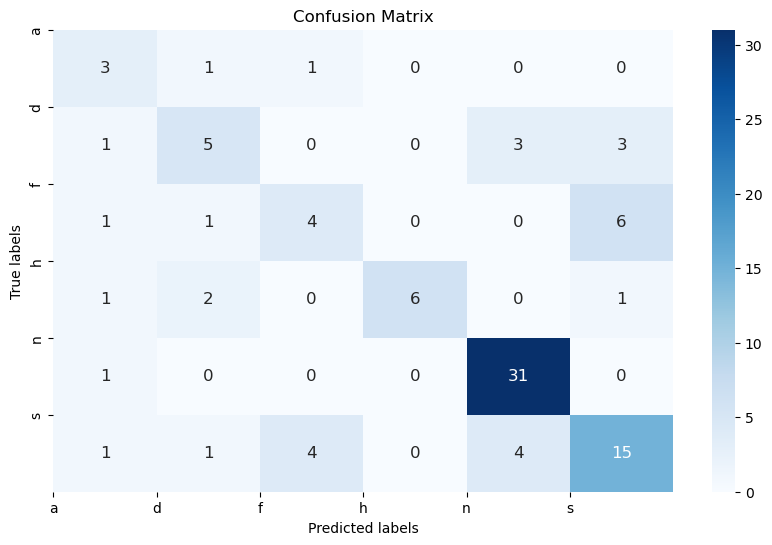

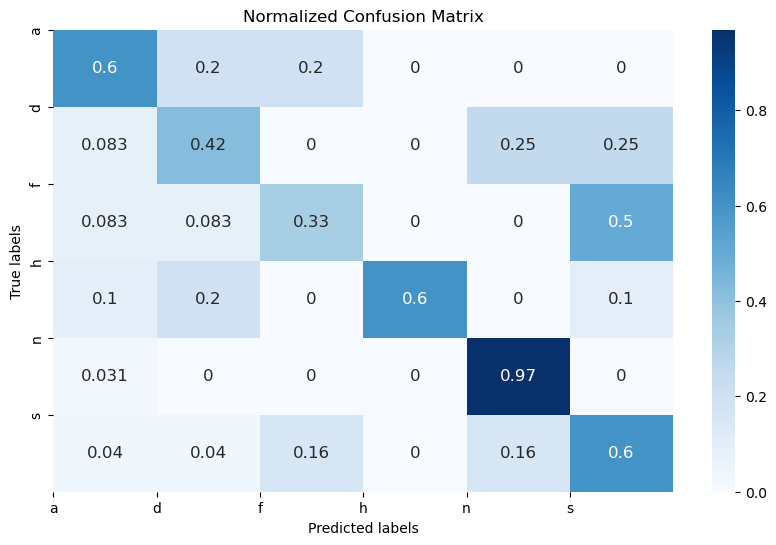

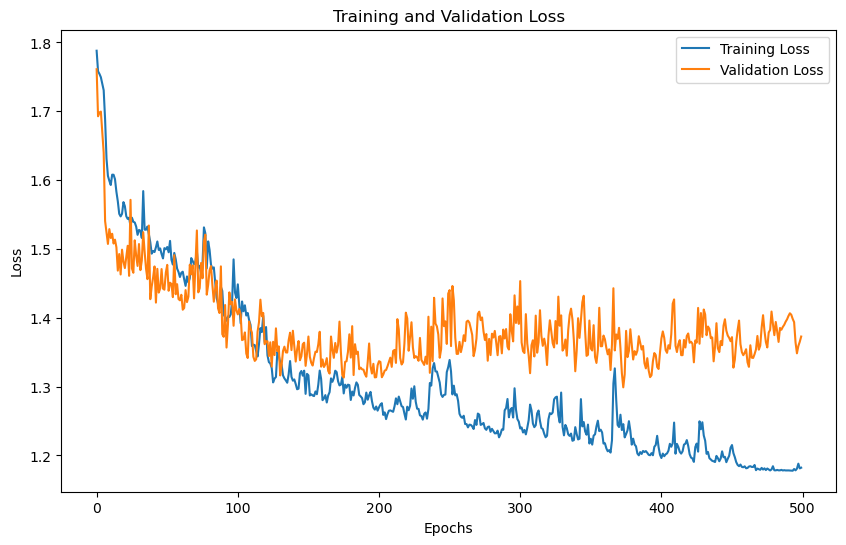

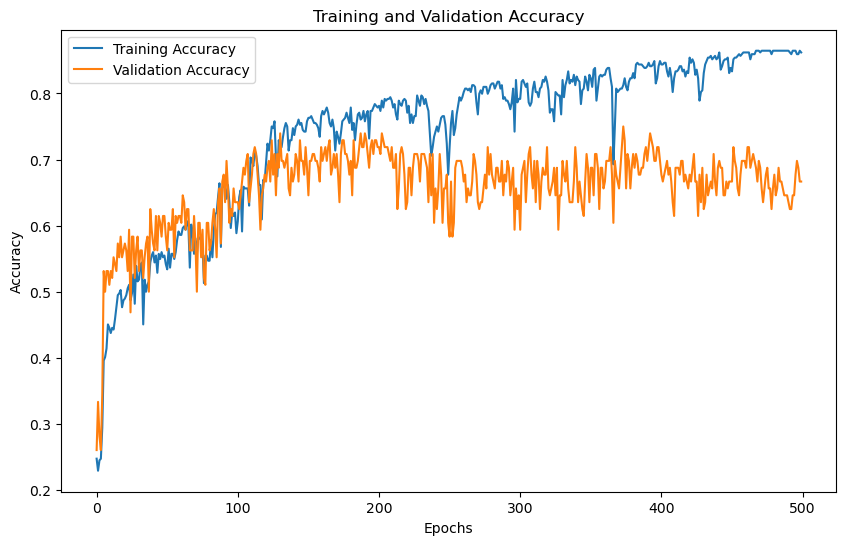

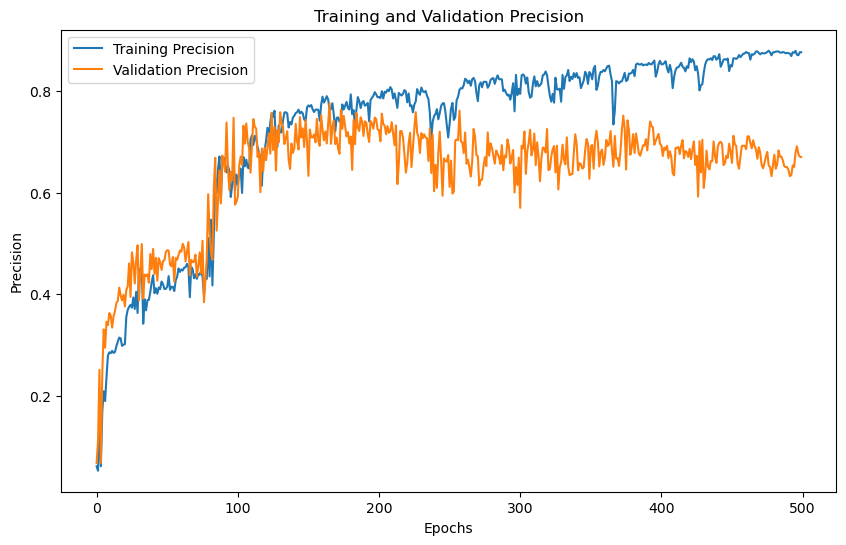

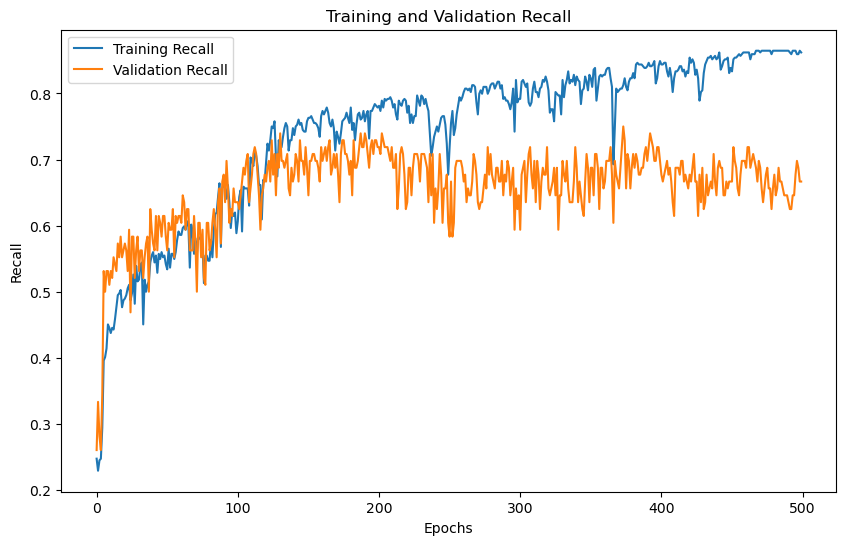

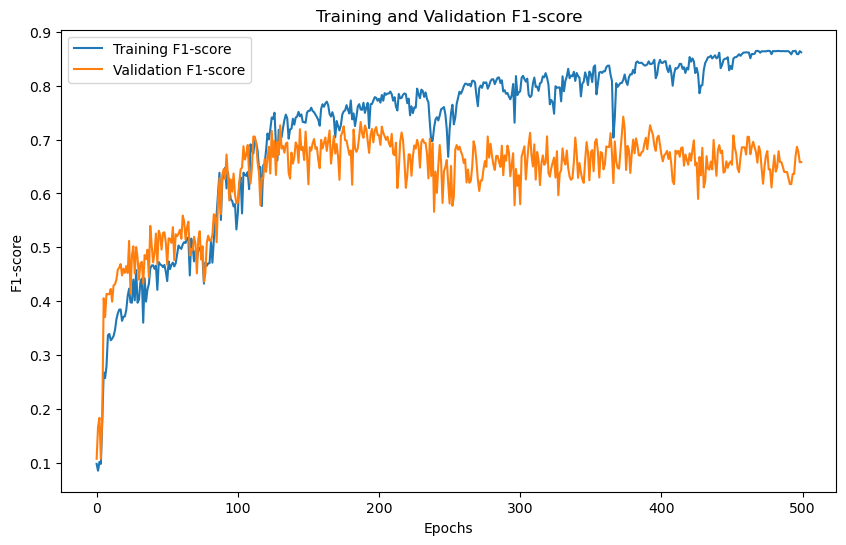

'Model Training and Evaluation Successfully completed'

In [14]:
train_model()

# SAVEE
# DWT 1
# N_MFCC 24
# 500 epoch

Enter dataset name:
tess, savee, crema, ravdess
 savee
Enter dwt level:  1
Enter Number of MFCC coefficients : 24
No. of classes 6
Input size for wavelet level 1 = 48
Training with DWT level: 1
Hidden Size : 256
Model Name: CNN_LSTM_Model

X Shape : (480, 48)
Y Shape : (480, 6)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.7812, Training Accuracy: 0.2474, Training Precision:0.0612,Training Recall:0.2474,Training F1-Score:0.0981
Validation Loss: 1.7488, Validation Accuracy: 0.2604, Validation Precision:0.0678,Validation Recall:0.2604,Validation F1-Score:0.1076
Epoch [2/500],
Training Loss: 1.7481, Training Accuracy: 0.2292, Training Precision:0.0525,Training Recall:0.2292,Training F1-Score:0.0855
Validation Loss: 1.6810, Validation Accuracy: 0.3333, Validation Precision:0.1111,Validation Recall:0.3333,Validation F1-Score:0.1667
Epoch [3/500],
Training Loss: 1.7480, Training Accuracy: 0.2552, Training Precision:0.1744,Training Recall:0.2552,Training F1-Score:0.1373
Validation 

Epoch [30/500],
Training Loss: 1.4678, Training Accuracy: 0.5781, Training Precision:0.4319,Training Recall:0.5781,Training F1-Score:0.4914
Validation Loss: 1.4409, Validation Accuracy: 0.6354, Validation Precision:0.4818,Validation Recall:0.6354,Validation F1-Score:0.5456
Epoch [31/500],
Training Loss: 1.4752, Training Accuracy: 0.5521, Training Precision:0.4270,Training Recall:0.5521,Training F1-Score:0.4647
Validation Loss: 1.4580, Validation Accuracy: 0.5833, Validation Precision:0.4501,Validation Recall:0.5833,Validation F1-Score:0.5007
Epoch [32/500],
Training Loss: 1.4826, Training Accuracy: 0.5312, Training Precision:0.4099,Training Recall:0.5312,Training F1-Score:0.4511
Validation Loss: 1.4741, Validation Accuracy: 0.5729, Validation Precision:0.4572,Validation Recall:0.5729,Validation F1-Score:0.5008
Epoch [33/500],
Training Loss: 1.4780, Training Accuracy: 0.5677, Training Precision:0.4301,Training Recall:0.5677,Training F1-Score:0.4817
Validation Loss: 1.4379, Validation Ac

Epoch [60/500],
Training Loss: 1.3743, Training Accuracy: 0.6719, Training Precision:0.6784,Training Recall:0.6719,Training F1-Score:0.6555
Validation Loss: 1.3757, Validation Accuracy: 0.6771, Validation Precision:0.7049,Validation Recall:0.6771,Validation F1-Score:0.6601
Epoch [61/500],
Training Loss: 1.3721, Training Accuracy: 0.6901, Training Precision:0.6964,Training Recall:0.6901,Training F1-Score:0.6702
Validation Loss: 1.4019, Validation Accuracy: 0.6354, Validation Precision:0.6536,Validation Recall:0.6354,Validation F1-Score:0.6166
Epoch [62/500],
Training Loss: 1.3745, Training Accuracy: 0.6719, Training Precision:0.6921,Training Recall:0.6719,Training F1-Score:0.6465
Validation Loss: 1.4116, Validation Accuracy: 0.6042, Validation Precision:0.5852,Validation Recall:0.6042,Validation F1-Score:0.5600
Epoch [63/500],
Training Loss: 1.3689, Training Accuracy: 0.6979, Training Precision:0.7129,Training Recall:0.6979,Training F1-Score:0.6792
Validation Loss: 1.3900, Validation Ac

Epoch [90/500],
Training Loss: 1.3219, Training Accuracy: 0.6849, Training Precision:0.6840,Training Recall:0.6849,Training F1-Score:0.6760
Validation Loss: 1.3807, Validation Accuracy: 0.6667, Validation Precision:0.6703,Validation Recall:0.6667,Validation F1-Score:0.6568
Epoch [91/500],
Training Loss: 1.3542, Training Accuracy: 0.7109, Training Precision:0.7443,Training Recall:0.7109,Training F1-Score:0.6932
Validation Loss: 1.4174, Validation Accuracy: 0.6250, Validation Precision:0.6555,Validation Recall:0.6250,Validation F1-Score:0.5950
Epoch [92/500],
Training Loss: 1.3470, Training Accuracy: 0.7214, Training Precision:0.7482,Training Recall:0.7214,Training F1-Score:0.7084
Validation Loss: 1.3720, Validation Accuracy: 0.6979, Validation Precision:0.7234,Validation Recall:0.6979,Validation F1-Score:0.6763
Epoch [93/500],
Training Loss: 1.3444, Training Accuracy: 0.7031, Training Precision:0.7112,Training Recall:0.7031,Training F1-Score:0.6965
Validation Loss: 1.4122, Validation Ac

Epoch [120/500],
Training Loss: 1.3091, Training Accuracy: 0.7526, Training Precision:0.7690,Training Recall:0.7526,Training F1-Score:0.7447
Validation Loss: 1.4091, Validation Accuracy: 0.6250, Validation Precision:0.6296,Validation Recall:0.6250,Validation F1-Score:0.6068
Epoch [121/500],
Training Loss: 1.2966, Training Accuracy: 0.7682, Training Precision:0.7842,Training Recall:0.7682,Training F1-Score:0.7595
Validation Loss: 1.3680, Validation Accuracy: 0.6771, Validation Precision:0.6746,Validation Recall:0.6771,Validation F1-Score:0.6515
Epoch [122/500],
Training Loss: 1.2876, Training Accuracy: 0.7552, Training Precision:0.7734,Training Recall:0.7552,Training F1-Score:0.7466
Validation Loss: 1.3703, Validation Accuracy: 0.6667, Validation Precision:0.6703,Validation Recall:0.6667,Validation F1-Score:0.6425
Epoch [123/500],
Training Loss: 1.2857, Training Accuracy: 0.7630, Training Precision:0.7814,Training Recall:0.7630,Training F1-Score:0.7555
Validation Loss: 1.3522, Validatio

...

Epoch [361/500],
Training Loss: 1.2305, Training Accuracy: 0.8151, Training Precision:0.8308,Training Recall:0.8151,Training F1-Score:0.8112
Validation Loss: 1.3642, Validation Accuracy: 0.6771, Validation Precision:0.7104,Validation Recall:0.6771,Validation F1-Score:0.6638
Epoch [362/500],
Training Loss: 1.2275, Training Accuracy: 0.8151, Training Precision:0.8290,Training Recall:0.8151,Training F1-Score:0.8097
Validation Loss: 1.3920, Validation Accuracy: 0.6458, Validation Precision:0.6867,Validation Recall:0.6458,Validation F1-Score:0.6342
Epoch [363/500],
Training Loss: 1.2278, Training Accuracy: 0.8151, Training Precision:0.8274,Training Recall:0.8151,Training F1-Score:0.8102
Validation Loss: 1.3740, Validation Accuracy: 0.6875, Validation Precision:0.7430,Validation Recall:0.6875,Validation F1-Score:0.6772
Epoch [364/500],
Training Loss: 1.2608, Training Accuracy: 0.8151, Training Precision:0.8277,Training Recall:0.8151,Training F1-Score:0.8116
Validation Loss: 1.3730, Validatio

Epoch [391/500],
Training Loss: 1.2225, Training Accuracy: 0.8177, Training Precision:0.8268,Training Recall:0.8177,Training F1-Score:0.8128
Validation Loss: 1.3647, Validation Accuracy: 0.6979, Validation Precision:0.7289,Validation Recall:0.6979,Validation F1-Score:0.6846
Epoch [392/500],
Training Loss: 1.2215, Training Accuracy: 0.8203, Training Precision:0.8313,Training Recall:0.8203,Training F1-Score:0.8153
Validation Loss: 1.3593, Validation Accuracy: 0.6979, Validation Precision:0.7289,Validation Recall:0.6979,Validation F1-Score:0.6846
Epoch [393/500],
Training Loss: 1.2216, Training Accuracy: 0.8203, Training Precision:0.8298,Training Recall:0.8203,Training F1-Score:0.8153
Validation Loss: 1.3589, Validation Accuracy: 0.6979, Validation Precision:0.7270,Validation Recall:0.6979,Validation F1-Score:0.6850
Epoch [394/500],
Training Loss: 1.2214, Training Accuracy: 0.8203, Training Precision:0.8325,Training Recall:0.8203,Training F1-Score:0.8156
Validation Loss: 1.3568, Validatio

Epoch [422/500],
Training Loss: 1.2238, Training Accuracy: 0.8229, Training Precision:0.8353,Training Recall:0.8229,Training F1-Score:0.8185
Validation Loss: 1.3779, Validation Accuracy: 0.6562, Validation Precision:0.6910,Validation Recall:0.6562,Validation F1-Score:0.6481
Epoch [423/500],
Training Loss: 1.2228, Training Accuracy: 0.8203, Training Precision:0.8339,Training Recall:0.8203,Training F1-Score:0.8158
Validation Loss: 1.3569, Validation Accuracy: 0.6875, Validation Precision:0.7226,Validation Recall:0.6875,Validation F1-Score:0.6718
Epoch [424/500],
Training Loss: 1.2200, Training Accuracy: 0.8229, Training Precision:0.8350,Training Recall:0.8229,Training F1-Score:0.8179
Validation Loss: 1.3846, Validation Accuracy: 0.6562, Validation Precision:0.6919,Validation Recall:0.6562,Validation F1-Score:0.6498
Epoch [425/500],
Training Loss: 1.2202, Training Accuracy: 0.8229, Training Precision:0.8333,Training Recall:0.8229,Training F1-Score:0.8185
Validation Loss: 1.3932, Validatio

Epoch [452/500],
Training Loss: 1.2188, Training Accuracy: 0.8229, Training Precision:0.8359,Training Recall:0.8229,Training F1-Score:0.8179
Validation Loss: 1.4012, Validation Accuracy: 0.6458, Validation Precision:0.6904,Validation Recall:0.6458,Validation F1-Score:0.6389
Epoch [453/500],
Training Loss: 1.2213, Training Accuracy: 0.8229, Training Precision:0.8340,Training Recall:0.8229,Training F1-Score:0.8183
Validation Loss: 1.3753, Validation Accuracy: 0.6562, Validation Precision:0.6947,Validation Recall:0.6562,Validation F1-Score:0.6475
Epoch [454/500],
Training Loss: 1.2205, Training Accuracy: 0.8229, Training Precision:0.8339,Training Recall:0.8229,Training F1-Score:0.8182
Validation Loss: 1.4004, Validation Accuracy: 0.6354, Validation Precision:0.6578,Validation Recall:0.6354,Validation F1-Score:0.6265
Epoch [455/500],
Training Loss: 1.2217, Training Accuracy: 0.8229, Training Precision:0.8347,Training Recall:0.8229,Training F1-Score:0.8181
Validation Loss: 1.3970, Validatio

Epoch [482/500],
Training Loss: 1.2153, Training Accuracy: 0.8255, Training Precision:0.8372,Training Recall:0.8255,Training F1-Score:0.8207
Validation Loss: 1.3719, Validation Accuracy: 0.6562, Validation Precision:0.6773,Validation Recall:0.6562,Validation F1-Score:0.6468
Epoch [483/500],
Training Loss: 1.2149, Training Accuracy: 0.8255, Training Precision:0.8365,Training Recall:0.8255,Training F1-Score:0.8204
Validation Loss: 1.3819, Validation Accuracy: 0.6354, Validation Precision:0.6547,Validation Recall:0.6354,Validation F1-Score:0.6281
Epoch [484/500],
Training Loss: 1.2144, Training Accuracy: 0.8255, Training Precision:0.8349,Training Recall:0.8255,Training F1-Score:0.8201
Validation Loss: 1.3842, Validation Accuracy: 0.6354, Validation Precision:0.6547,Validation Recall:0.6354,Validation F1-Score:0.6281
Epoch [485/500],
Training Loss: 1.2152, Training Accuracy: 0.8255, Training Precision:0.8341,Training Recall:0.8255,Training F1-Score:0.8202
Validation Loss: 1.3825, Validatio

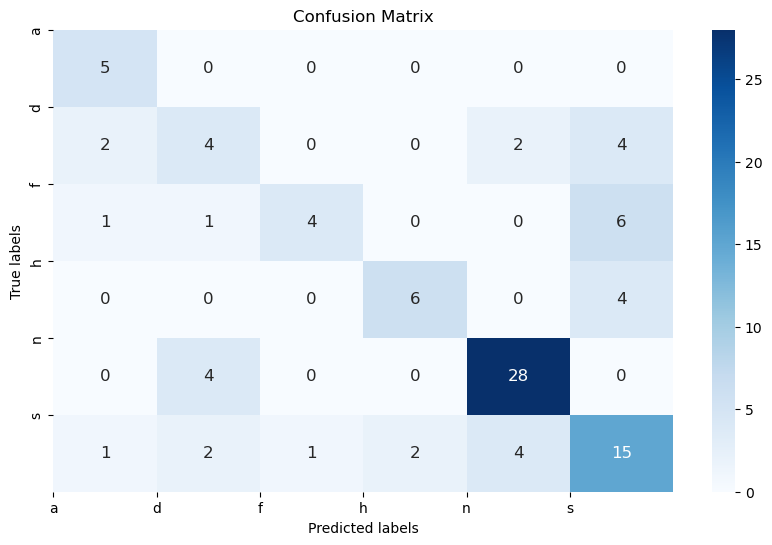

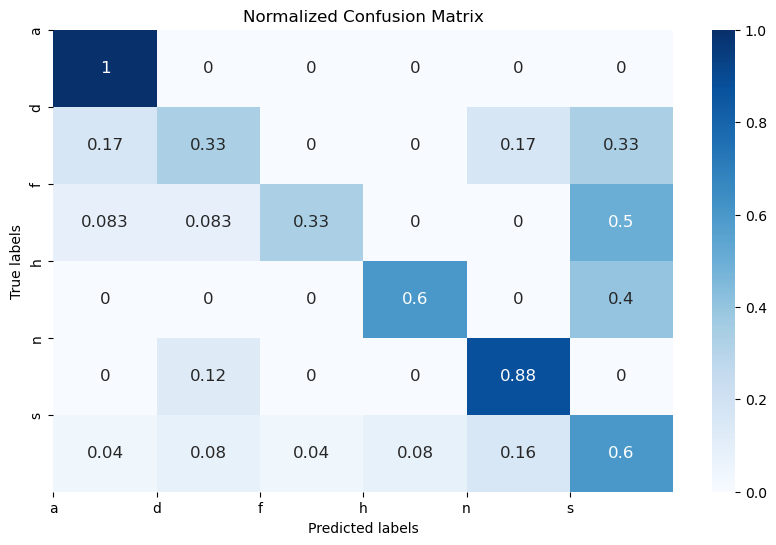

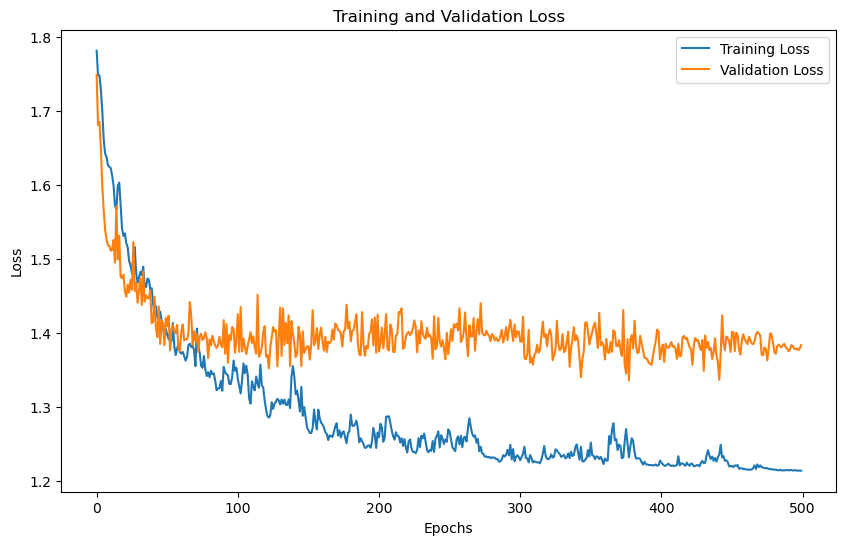

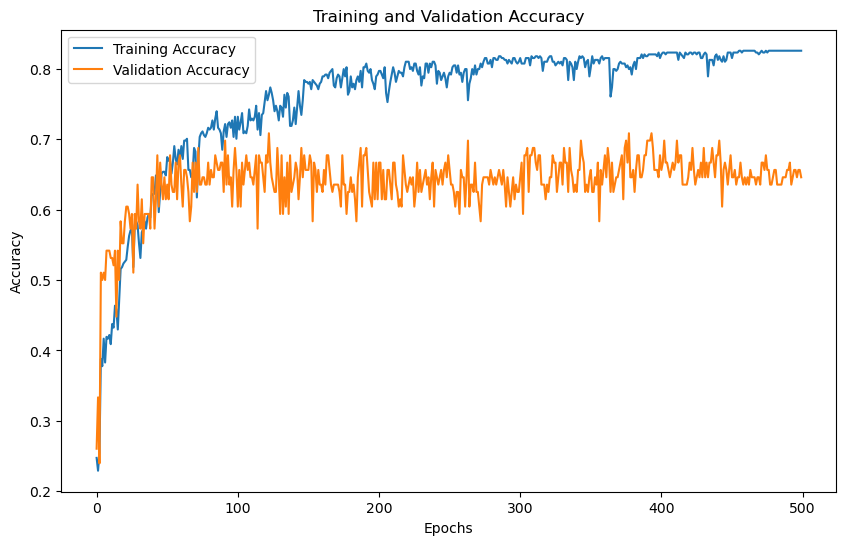

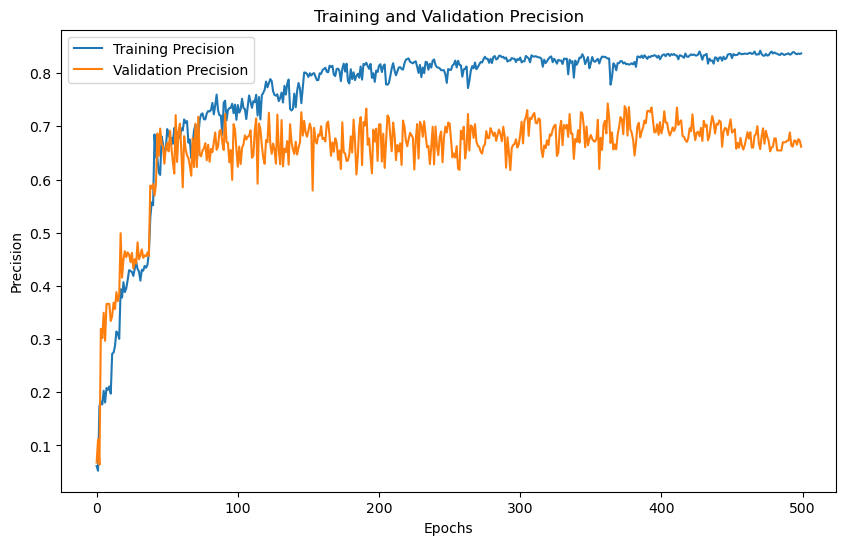

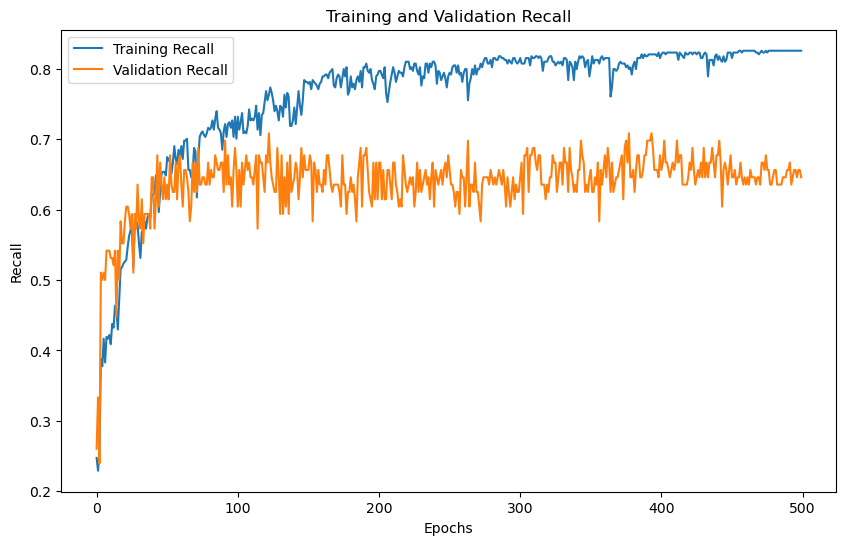

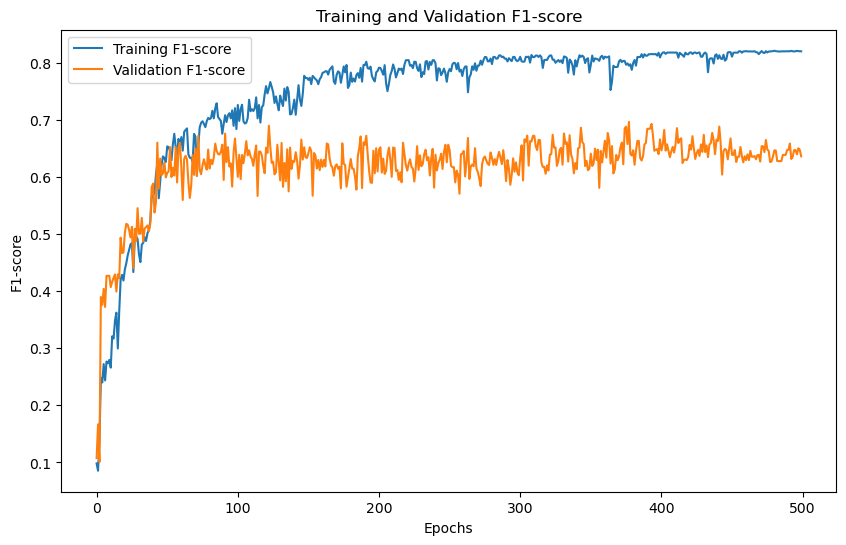

'Model Training and Evaluation Successfully completed'

In [15]:
train_model()

# SAVEE
# DWT 5
# N_MFCC 24
# 500 epoch

Enter dataset name:
tess, savee, crema, ravdess
 savee
Enter dwt level:  5
Enter Number of MFCC coefficients : 24
No. of classes 6
Input size for wavelet level 5 = 144
Training with DWT level: 5
Hidden Size : 256
Model Name: CNN_LSTM_Model

X Shape : (480, 144)
Y Shape : (480, 6)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.7722, Training Accuracy: 0.2917, Training Precision:0.1915,Training Recall:0.2917,Training F1-Score:0.1886
Validation Loss: 1.7041, Validation Accuracy: 0.3021, Validation Precision:0.2795,Validation Recall:0.3021,Validation F1-Score:0.2127
Epoch [2/500],
Training Loss: 1.7392, Training Accuracy: 0.3516, Training Precision:0.2052,Training Recall:0.3516,Training F1-Score:0.2413
Validation Loss: 1.6791, Validation Accuracy: 0.2708, Validation Precision:0.2658,Validation Recall:0.2708,Validation F1-Score:0.1573
Epoch [3/500],
Training Loss: 1.7184, Training Accuracy: 0.2526, Training Precision:0.1120,Training Recall:0.2526,Training F1-Score:0.1263
Validatio

Epoch [30/500],
Training Loss: 1.4556, Training Accuracy: 0.6016, Training Precision:0.5446,Training Recall:0.6016,Training F1-Score:0.5583
Validation Loss: 1.4207, Validation Accuracy: 0.6354, Validation Precision:0.6096,Validation Recall:0.6354,Validation F1-Score:0.6026
Epoch [31/500],
Training Loss: 1.4414, Training Accuracy: 0.5964, Training Precision:0.5481,Training Recall:0.5964,Training F1-Score:0.5454
Validation Loss: 1.4090, Validation Accuracy: 0.6458, Validation Precision:0.6059,Validation Recall:0.6458,Validation F1-Score:0.5829
Epoch [32/500],
Training Loss: 1.4782, Training Accuracy: 0.5365, Training Precision:0.6029,Training Recall:0.5365,Training F1-Score:0.4826
Validation Loss: 1.4206, Validation Accuracy: 0.5938, Validation Precision:0.4936,Validation Recall:0.5938,Validation F1-Score:0.4970
Epoch [33/500],
Training Loss: 1.4524, Training Accuracy: 0.6380, Training Precision:0.6408,Training Recall:0.6380,Training F1-Score:0.6249
Validation Loss: 1.3905, Validation Ac

Epoch [60/500],
Training Loss: 1.3270, Training Accuracy: 0.7448, Training Precision:0.7660,Training Recall:0.7448,Training F1-Score:0.7312
Validation Loss: 1.4114, Validation Accuracy: 0.6250, Validation Precision:0.6721,Validation Recall:0.6250,Validation F1-Score:0.6140
Epoch [61/500],
Training Loss: 1.3154, Training Accuracy: 0.7526, Training Precision:0.7754,Training Recall:0.7526,Training F1-Score:0.7462
Validation Loss: 1.3695, Validation Accuracy: 0.6771, Validation Precision:0.6743,Validation Recall:0.6771,Validation F1-Score:0.6559
Epoch [62/500],
Training Loss: 1.3122, Training Accuracy: 0.7526, Training Precision:0.7710,Training Recall:0.7526,Training F1-Score:0.7445
Validation Loss: 1.4149, Validation Accuracy: 0.6146, Validation Precision:0.6573,Validation Recall:0.6146,Validation F1-Score:0.6023
Epoch [63/500],
Training Loss: 1.3023, Training Accuracy: 0.7552, Training Precision:0.7729,Training Recall:0.7552,Training F1-Score:0.7464
Validation Loss: 1.3794, Validation Ac

Epoch [90/500],
Training Loss: 1.2825, Training Accuracy: 0.7708, Training Precision:0.7906,Training Recall:0.7708,Training F1-Score:0.7647
Validation Loss: 1.4005, Validation Accuracy: 0.6354, Validation Precision:0.6397,Validation Recall:0.6354,Validation F1-Score:0.6068
Epoch [91/500],
Training Loss: 1.2658, Training Accuracy: 0.7708, Training Precision:0.8058,Training Recall:0.7708,Training F1-Score:0.7676
Validation Loss: 1.4484, Validation Accuracy: 0.5833, Validation Precision:0.6155,Validation Recall:0.5833,Validation F1-Score:0.5695
Epoch [92/500],
Training Loss: 1.2806, Training Accuracy: 0.8021, Training Precision:0.8132,Training Recall:0.8021,Training F1-Score:0.7971
Validation Loss: 1.3861, Validation Accuracy: 0.6458, Validation Precision:0.6481,Validation Recall:0.6458,Validation F1-Score:0.6344
Epoch [93/500],
Training Loss: 1.2775, Training Accuracy: 0.8099, Training Precision:0.8179,Training Recall:0.8099,Training F1-Score:0.8041
Validation Loss: 1.3671, Validation Ac

Epoch [120/500],
Training Loss: 1.2141, Training Accuracy: 0.8281, Training Precision:0.8429,Training Recall:0.8281,Training F1-Score:0.8236
Validation Loss: 1.4281, Validation Accuracy: 0.6042, Validation Precision:0.5975,Validation Recall:0.6042,Validation F1-Score:0.5834
Epoch [121/500],
Training Loss: 1.2192, Training Accuracy: 0.8333, Training Precision:0.8464,Training Recall:0.8333,Training F1-Score:0.8284
Validation Loss: 1.3956, Validation Accuracy: 0.6458, Validation Precision:0.6536,Validation Recall:0.6458,Validation F1-Score:0.6255
Epoch [122/500],
Training Loss: 1.2091, Training Accuracy: 0.8359, Training Precision:0.8466,Training Recall:0.8359,Training F1-Score:0.8315
Validation Loss: 1.3949, Validation Accuracy: 0.6354, Validation Precision:0.6254,Validation Recall:0.6354,Validation F1-Score:0.6163
Epoch [123/500],
Training Loss: 1.2089, Training Accuracy: 0.8359, Training Precision:0.8478,Training Recall:0.8359,Training F1-Score:0.8316
Validation Loss: 1.3990, Validatio

...

Epoch [360/500],
Training Loss: 1.1685, Training Accuracy: 0.8724, Training Precision:0.8826,Training Recall:0.8724,Training F1-Score:0.8685
Validation Loss: 1.4137, Validation Accuracy: 0.6250, Validation Precision:0.6063,Validation Recall:0.6250,Validation F1-Score:0.6019
Epoch [361/500],
Training Loss: 1.1685, Training Accuracy: 0.8724, Training Precision:0.8851,Training Recall:0.8724,Training F1-Score:0.8684
Validation Loss: 1.4165, Validation Accuracy: 0.6250, Validation Precision:0.6070,Validation Recall:0.6250,Validation F1-Score:0.6016
Epoch [362/500],
Training Loss: 1.1685, Training Accuracy: 0.8724, Training Precision:0.8850,Training Recall:0.8724,Training F1-Score:0.8689
Validation Loss: 1.4131, Validation Accuracy: 0.6250, Validation Precision:0.6063,Validation Recall:0.6250,Validation F1-Score:0.6019
Epoch [363/500],
Training Loss: 1.1683, Training Accuracy: 0.8724, Training Precision:0.8806,Training Recall:0.8724,Training F1-Score:0.8681
Validation Loss: 1.4155, Validatio

Epoch [390/500],
Training Loss: 1.1683, Training Accuracy: 0.8724, Training Precision:0.8821,Training Recall:0.8724,Training F1-Score:0.8680
Validation Loss: 1.4153, Validation Accuracy: 0.6354, Validation Precision:0.6200,Validation Recall:0.6354,Validation F1-Score:0.6154
Epoch [391/500],
Training Loss: 1.1682, Training Accuracy: 0.8724, Training Precision:0.8839,Training Recall:0.8724,Training F1-Score:0.8685
Validation Loss: 1.4111, Validation Accuracy: 0.6354, Validation Precision:0.6200,Validation Recall:0.6354,Validation F1-Score:0.6154
Epoch [392/500],
Training Loss: 1.1684, Training Accuracy: 0.8724, Training Precision:0.8857,Training Recall:0.8724,Training F1-Score:0.8689
Validation Loss: 1.4082, Validation Accuracy: 0.6250, Validation Precision:0.6070,Validation Recall:0.6250,Validation F1-Score:0.6008
Epoch [393/500],
Training Loss: 1.1684, Training Accuracy: 0.8724, Training Precision:0.8885,Training Recall:0.8724,Training F1-Score:0.8691
Validation Loss: 1.4125, Validatio

Epoch [420/500],
Training Loss: 1.1681, Training Accuracy: 0.8724, Training Precision:0.8826,Training Recall:0.8724,Training F1-Score:0.8682
Validation Loss: 1.4175, Validation Accuracy: 0.6354, Validation Precision:0.6186,Validation Recall:0.6354,Validation F1-Score:0.6141
Epoch [421/500],
Training Loss: 1.1681, Training Accuracy: 0.8724, Training Precision:0.8827,Training Recall:0.8724,Training F1-Score:0.8683
Validation Loss: 1.4169, Validation Accuracy: 0.6250, Validation Precision:0.6107,Validation Recall:0.6250,Validation F1-Score:0.6056
Epoch [422/500],
Training Loss: 1.1681, Training Accuracy: 0.8724, Training Precision:0.8821,Training Recall:0.8724,Training F1-Score:0.8683
Validation Loss: 1.4156, Validation Accuracy: 0.6354, Validation Precision:0.6200,Validation Recall:0.6354,Validation F1-Score:0.6154
Epoch [423/500],
Training Loss: 1.1681, Training Accuracy: 0.8724, Training Precision:0.8858,Training Recall:0.8724,Training F1-Score:0.8688
Validation Loss: 1.4156, Validatio

Epoch [450/500],
Training Loss: 1.1679, Training Accuracy: 0.8724, Training Precision:0.8842,Training Recall:0.8724,Training F1-Score:0.8682
Validation Loss: 1.4218, Validation Accuracy: 0.6250, Validation Precision:0.6292,Validation Recall:0.6250,Validation F1-Score:0.6062
Epoch [451/500],
Training Loss: 1.1679, Training Accuracy: 0.8724, Training Precision:0.8820,Training Recall:0.8724,Training F1-Score:0.8683
Validation Loss: 1.4192, Validation Accuracy: 0.6250, Validation Precision:0.6292,Validation Recall:0.6250,Validation F1-Score:0.6062
Epoch [452/500],
Training Loss: 1.1678, Training Accuracy: 0.8724, Training Precision:0.8816,Training Recall:0.8724,Training F1-Score:0.8688
Validation Loss: 1.4192, Validation Accuracy: 0.6250, Validation Precision:0.6292,Validation Recall:0.6250,Validation F1-Score:0.6062
Epoch [453/500],
Training Loss: 1.1678, Training Accuracy: 0.8724, Training Precision:0.8841,Training Recall:0.8724,Training F1-Score:0.8681
Validation Loss: 1.4205, Validatio

Epoch [480/500],
Training Loss: 1.1631, Training Accuracy: 0.8776, Training Precision:0.8888,Training Recall:0.8776,Training F1-Score:0.8749
Validation Loss: 1.4097, Validation Accuracy: 0.6146, Validation Precision:0.6197,Validation Recall:0.6146,Validation F1-Score:0.5963
Epoch [481/500],
Training Loss: 1.1629, Training Accuracy: 0.8776, Training Precision:0.8871,Training Recall:0.8776,Training F1-Score:0.8747
Validation Loss: 1.4118, Validation Accuracy: 0.6146, Validation Precision:0.6197,Validation Recall:0.6146,Validation F1-Score:0.5963
Epoch [482/500],
Training Loss: 1.1629, Training Accuracy: 0.8776, Training Precision:0.8875,Training Recall:0.8776,Training F1-Score:0.8747
Validation Loss: 1.4092, Validation Accuracy: 0.6146, Validation Precision:0.6197,Validation Recall:0.6146,Validation F1-Score:0.5963
Epoch [483/500],
Training Loss: 1.1629, Training Accuracy: 0.8776, Training Precision:0.8884,Training Recall:0.8776,Training F1-Score:0.8746
Validation Loss: 1.4130, Validatio

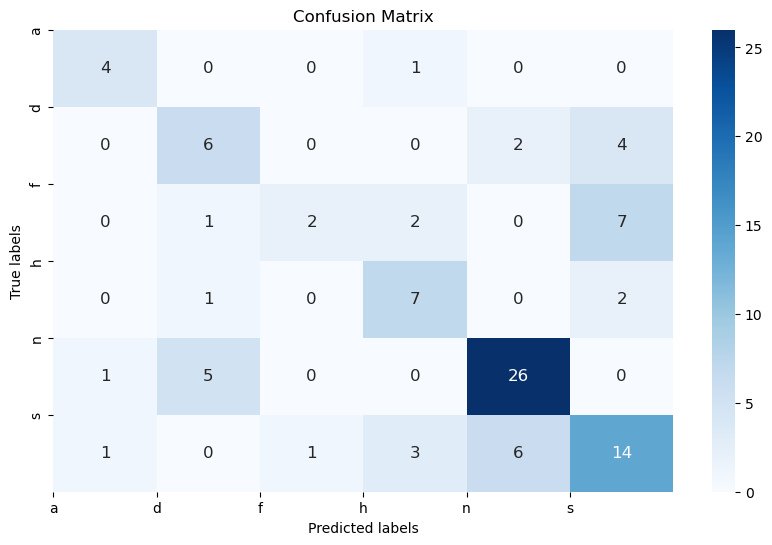

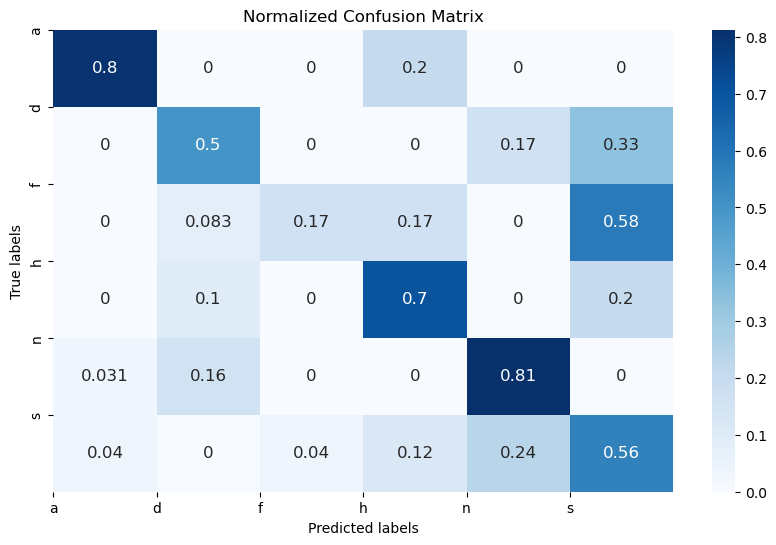

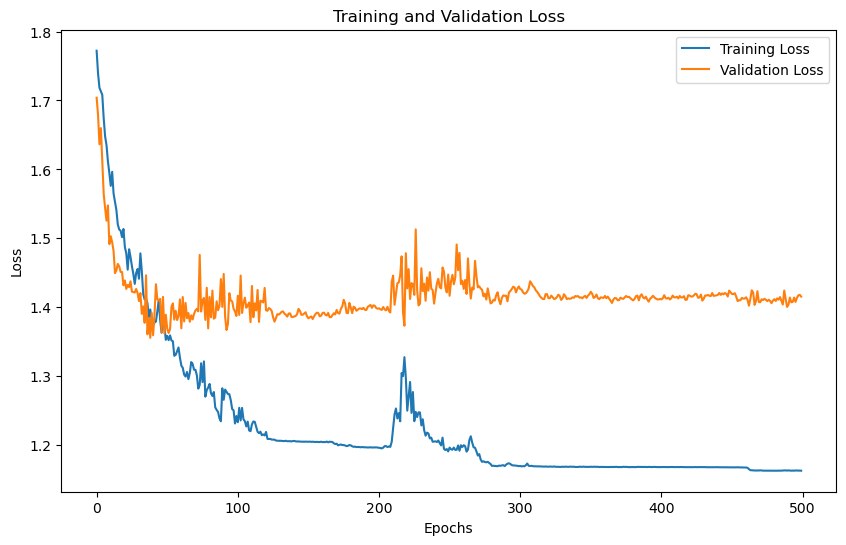

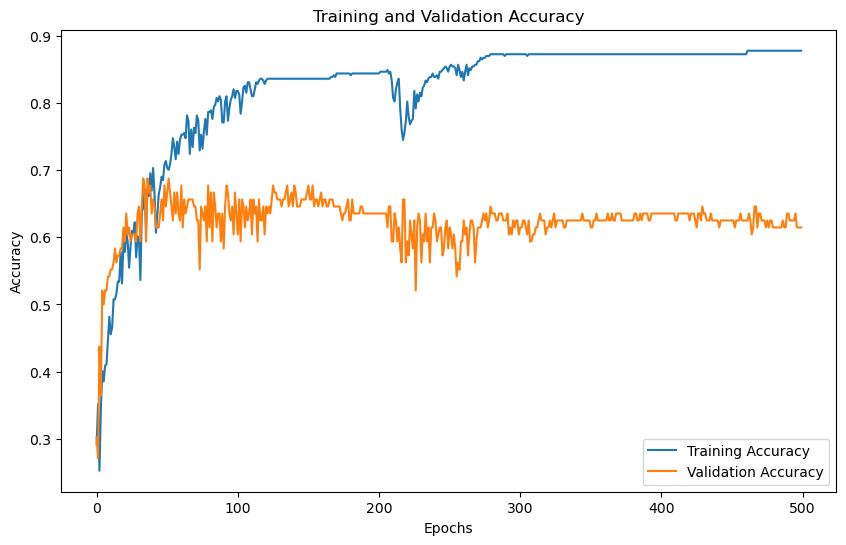

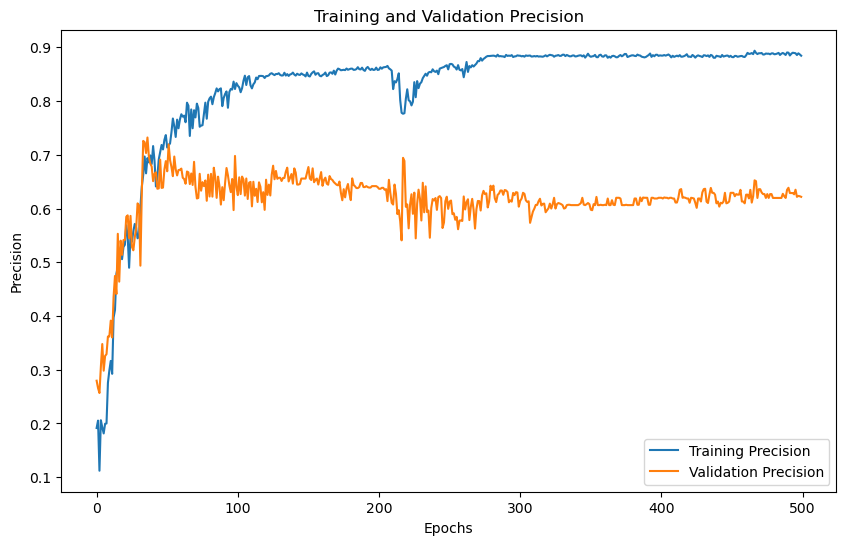

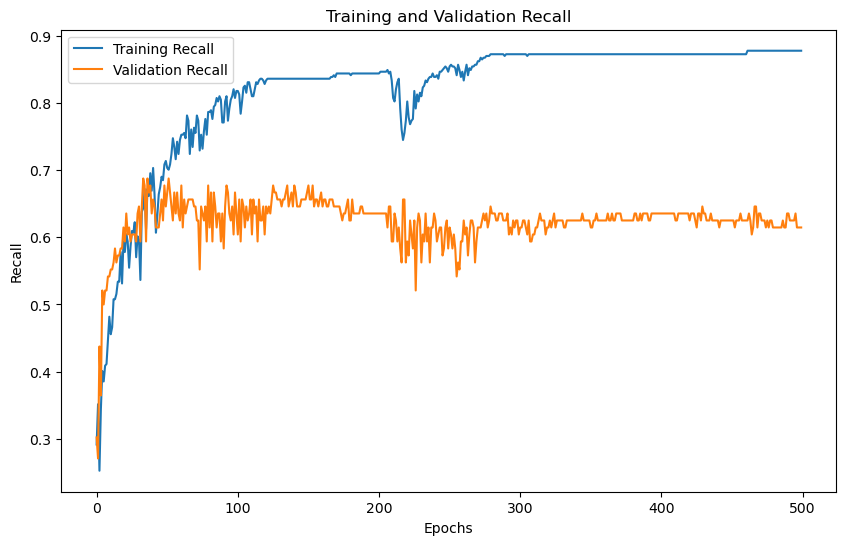

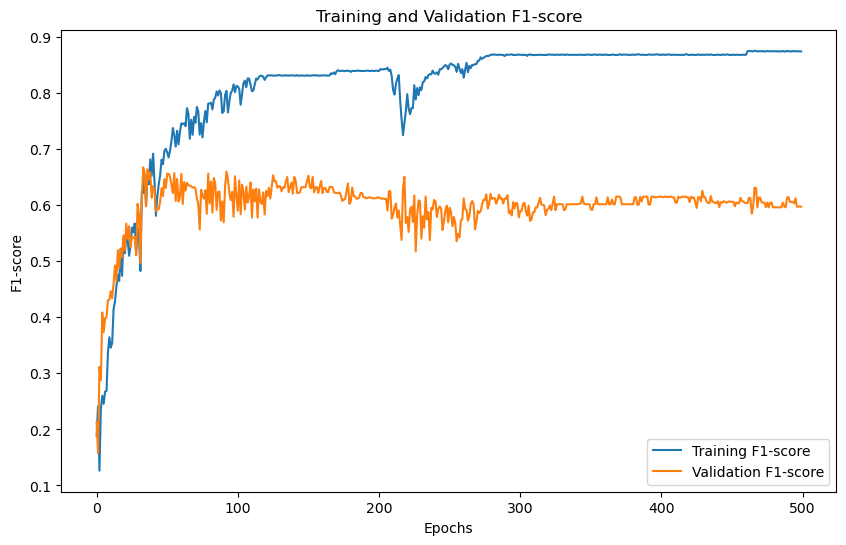

'Model Training and Evaluation Successfully completed'

In [17]:
train_model()

# RAVDESS
# DWT 1
# N_MFCC 24

Enter dataset name:
tess, savee, crema, ravdess
 ravdess
Enter dwt level:  1
Enter Number of MFCC coefficients : 24
No. of classes 8
Input size for wavelet level 1 = 48
Training with DWT level: 1
Hidden Size : 256
Model Name: CNN_LSTM_Model

X Shape : (1440, 48)
Y Shape : (1440, 8)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 2.0751, Training Accuracy: 0.2127, Training Precision:0.1728,Training Recall:0.2127,Training F1-Score:0.1437
Validation Loss: 2.0655, Validation Accuracy: 0.2674, Validation Precision:0.2372,Validation Recall:0.2674,Validation F1-Score:0.1978
Epoch [2/500],
Training Loss: 2.0441, Training Accuracy: 0.2335, Training Precision:0.1040,Training Recall:0.2335,Training F1-Score:0.1045
Validation Loss: 1.9977, Validation Accuracy: 0.2674, Validation Precision:0.1351,Validation Recall:0.2674,Validation F1-Score:0.1287
Epoch [3/500],
Training Loss: 2.0172, Training Accuracy: 0.2439, Training Precision:0.0952,Training Recall:0.2439,Training F1-Score:0.1297
Validat

Epoch [30/500],
Training Loss: 1.9077, Training Accuracy: 0.3811, Training Precision:0.3788,Training Recall:0.3811,Training F1-Score:0.3500
Validation Loss: 1.8889, Validation Accuracy: 0.3646, Validation Precision:0.3709,Validation Recall:0.3646,Validation F1-Score:0.3379
Epoch [31/500],
Training Loss: 1.8938, Training Accuracy: 0.3411, Training Precision:0.3579,Training Recall:0.3411,Training F1-Score:0.2970
Validation Loss: 1.9111, Validation Accuracy: 0.3368, Validation Precision:0.3091,Validation Recall:0.3368,Validation F1-Score:0.2774
Epoch [32/500],
Training Loss: 1.9098, Training Accuracy: 0.4080, Training Precision:0.3899,Training Recall:0.4080,Training F1-Score:0.3722
Validation Loss: 1.8787, Validation Accuracy: 0.3958, Validation Precision:0.3828,Validation Recall:0.3958,Validation F1-Score:0.3631
Epoch [33/500],
Training Loss: 1.9114, Training Accuracy: 0.4106, Training Precision:0.3940,Training Recall:0.4106,Training F1-Score:0.3735
Validation Loss: 1.8799, Validation Ac

Epoch [60/500],
Training Loss: 1.8528, Training Accuracy: 0.4158, Training Precision:0.4318,Training Recall:0.4158,Training F1-Score:0.3853
Validation Loss: 1.8608, Validation Accuracy: 0.4062, Validation Precision:0.4359,Validation Recall:0.4062,Validation F1-Score:0.3716
Epoch [61/500],
Training Loss: 1.8299, Training Accuracy: 0.4340, Training Precision:0.4544,Training Recall:0.4340,Training F1-Score:0.4047
Validation Loss: 1.8545, Validation Accuracy: 0.4062, Validation Precision:0.4248,Validation Recall:0.4062,Validation F1-Score:0.3819
Epoch [62/500],
Training Loss: 1.8225, Training Accuracy: 0.4653, Training Precision:0.4637,Training Recall:0.4653,Training F1-Score:0.4381
Validation Loss: 1.8562, Validation Accuracy: 0.4062, Validation Precision:0.3908,Validation Recall:0.4062,Validation F1-Score:0.3760
Epoch [63/500],
Training Loss: 1.8144, Training Accuracy: 0.4696, Training Precision:0.4474,Training Recall:0.4696,Training F1-Score:0.4504
Validation Loss: 1.8620, Validation Ac

Epoch [90/500],
Training Loss: 1.7746, Training Accuracy: 0.4852, Training Precision:0.4539,Training Recall:0.4852,Training F1-Score:0.4644
Validation Loss: 1.8520, Validation Accuracy: 0.4132, Validation Precision:0.3938,Validation Recall:0.4132,Validation F1-Score:0.3953
Epoch [91/500],
Training Loss: 1.7584, Training Accuracy: 0.5252, Training Precision:0.4959,Training Recall:0.5252,Training F1-Score:0.5062
Validation Loss: 1.8484, Validation Accuracy: 0.4201, Validation Precision:0.4140,Validation Recall:0.4201,Validation F1-Score:0.4069
Epoch [92/500],
Training Loss: 1.7620, Training Accuracy: 0.5061, Training Precision:0.5044,Training Recall:0.5061,Training F1-Score:0.4730
Validation Loss: 1.8171, Validation Accuracy: 0.4549, Validation Precision:0.4361,Validation Recall:0.4549,Validation F1-Score:0.4151
Epoch [93/500],
Training Loss: 1.7758, Training Accuracy: 0.5061, Training Precision:0.5254,Training Recall:0.5061,Training F1-Score:0.4792
Validation Loss: 1.8456, Validation Ac

Epoch [120/500],
Training Loss: 1.6982, Training Accuracy: 0.5877, Training Precision:0.5722,Training Recall:0.5877,Training F1-Score:0.5654
Validation Loss: 1.8193, Validation Accuracy: 0.4514, Validation Precision:0.4258,Validation Recall:0.4514,Validation F1-Score:0.4321
Epoch [121/500],
Training Loss: 1.7148, Training Accuracy: 0.5964, Training Precision:0.5780,Training Recall:0.5964,Training F1-Score:0.5744
Validation Loss: 1.8032, Validation Accuracy: 0.4688, Validation Precision:0.4506,Validation Recall:0.4688,Validation F1-Score:0.4371
Epoch [122/500],
Training Loss: 1.7053, Training Accuracy: 0.6007, Training Precision:0.6531,Training Recall:0.6007,Training F1-Score:0.5817
Validation Loss: 1.8259, Validation Accuracy: 0.4514, Validation Precision:0.4697,Validation Recall:0.4514,Validation F1-Score:0.4246
Epoch [123/500],
Training Loss: 1.6942, Training Accuracy: 0.6085, Training Precision:0.5868,Training Recall:0.6085,Training F1-Score:0.5893
Validation Loss: 1.7900, Validatio

...

Epoch [360/500],
Training Loss: 1.4376, Training Accuracy: 0.8264, Training Precision:0.8272,Training Recall:0.8264,Training F1-Score:0.8244
Validation Loss: 1.7149, Validation Accuracy: 0.5625, Validation Precision:0.5585,Validation Recall:0.5625,Validation F1-Score:0.5539
Epoch [361/500],
Training Loss: 1.4486, Training Accuracy: 0.8333, Training Precision:0.8378,Training Recall:0.8333,Training F1-Score:0.8319
Validation Loss: 1.7560, Validation Accuracy: 0.5104, Validation Precision:0.5225,Validation Recall:0.5104,Validation F1-Score:0.5037
Epoch [362/500],
Training Loss: 1.4451, Training Accuracy: 0.8385, Training Precision:0.8458,Training Recall:0.8385,Training F1-Score:0.8373
Validation Loss: 1.7232, Validation Accuracy: 0.5660, Validation Precision:0.5628,Validation Recall:0.5660,Validation F1-Score:0.5578
Epoch [363/500],
Training Loss: 1.4659, Training Accuracy: 0.8194, Training Precision:0.8231,Training Recall:0.8194,Training F1-Score:0.8186
Validation Loss: 1.7643, Validatio

Epoch [390/500],
Training Loss: 1.4283, Training Accuracy: 0.8498, Training Precision:0.8534,Training Recall:0.8498,Training F1-Score:0.8481
Validation Loss: 1.7319, Validation Accuracy: 0.5382, Validation Precision:0.5546,Validation Recall:0.5382,Validation F1-Score:0.5359
Epoch [391/500],
Training Loss: 1.4302, Training Accuracy: 0.8446, Training Precision:0.8473,Training Recall:0.8446,Training F1-Score:0.8430
Validation Loss: 1.7478, Validation Accuracy: 0.5208, Validation Precision:0.5262,Validation Recall:0.5208,Validation F1-Score:0.5154
Epoch [392/500],
Training Loss: 1.4230, Training Accuracy: 0.8533, Training Precision:0.8583,Training Recall:0.8533,Training F1-Score:0.8521
Validation Loss: 1.7382, Validation Accuracy: 0.5347, Validation Precision:0.5474,Validation Recall:0.5347,Validation F1-Score:0.5316
Epoch [393/500],
Training Loss: 1.4280, Training Accuracy: 0.8490, Training Precision:0.8533,Training Recall:0.8490,Training F1-Score:0.8471
Validation Loss: 1.7213, Validatio

Epoch [420/500],
Training Loss: 1.4293, Training Accuracy: 0.8394, Training Precision:0.8450,Training Recall:0.8394,Training F1-Score:0.8382
Validation Loss: 1.7474, Validation Accuracy: 0.5243, Validation Precision:0.5394,Validation Recall:0.5243,Validation F1-Score:0.5181
Epoch [421/500],
Training Loss: 1.4471, Training Accuracy: 0.8220, Training Precision:0.8330,Training Recall:0.8220,Training F1-Score:0.8214
Validation Loss: 1.7265, Validation Accuracy: 0.5451, Validation Precision:0.5566,Validation Recall:0.5451,Validation F1-Score:0.5377
Epoch [422/500],
Training Loss: 1.4615, Training Accuracy: 0.8325, Training Precision:0.8447,Training Recall:0.8325,Training F1-Score:0.8310
Validation Loss: 1.7299, Validation Accuracy: 0.5347, Validation Precision:0.5311,Validation Recall:0.5347,Validation F1-Score:0.5260
Epoch [423/500],
Training Loss: 1.4575, Training Accuracy: 0.8420, Training Precision:0.8467,Training Recall:0.8420,Training F1-Score:0.8406
Validation Loss: 1.7261, Validatio

Epoch [450/500],
Training Loss: 1.4166, Training Accuracy: 0.8542, Training Precision:0.8555,Training Recall:0.8542,Training F1-Score:0.8525
Validation Loss: 1.7268, Validation Accuracy: 0.5382, Validation Precision:0.5417,Validation Recall:0.5382,Validation F1-Score:0.5331
Epoch [451/500],
Training Loss: 1.4220, Training Accuracy: 0.8594, Training Precision:0.8612,Training Recall:0.8594,Training F1-Score:0.8583
Validation Loss: 1.7480, Validation Accuracy: 0.5208, Validation Precision:0.5339,Validation Recall:0.5208,Validation F1-Score:0.5192
Epoch [452/500],
Training Loss: 1.4155, Training Accuracy: 0.8585, Training Precision:0.8609,Training Recall:0.8585,Training F1-Score:0.8572
Validation Loss: 1.7460, Validation Accuracy: 0.5312, Validation Precision:0.5374,Validation Recall:0.5312,Validation F1-Score:0.5271
Epoch [453/500],
Training Loss: 1.4289, Training Accuracy: 0.8550, Training Precision:0.8578,Training Recall:0.8550,Training F1-Score:0.8542
Validation Loss: 1.7501, Validatio

Epoch [480/500],
Training Loss: 1.4138, Training Accuracy: 0.8576, Training Precision:0.8610,Training Recall:0.8576,Training F1-Score:0.8576
Validation Loss: 1.7317, Validation Accuracy: 0.5382, Validation Precision:0.5635,Validation Recall:0.5382,Validation F1-Score:0.5401
Epoch [481/500],
Training Loss: 1.4184, Training Accuracy: 0.8594, Training Precision:0.8631,Training Recall:0.8594,Training F1-Score:0.8595
Validation Loss: 1.7404, Validation Accuracy: 0.5312, Validation Precision:0.5545,Validation Recall:0.5312,Validation F1-Score:0.5339
Epoch [482/500],
Training Loss: 1.4311, Training Accuracy: 0.8559, Training Precision:0.8571,Training Recall:0.8559,Training F1-Score:0.8554
Validation Loss: 1.7597, Validation Accuracy: 0.5139, Validation Precision:0.5342,Validation Recall:0.5139,Validation F1-Score:0.5160
Epoch [483/500],
Training Loss: 1.4181, Training Accuracy: 0.8411, Training Precision:0.8438,Training Recall:0.8411,Training F1-Score:0.8403
Validation Loss: 1.7290, Validatio

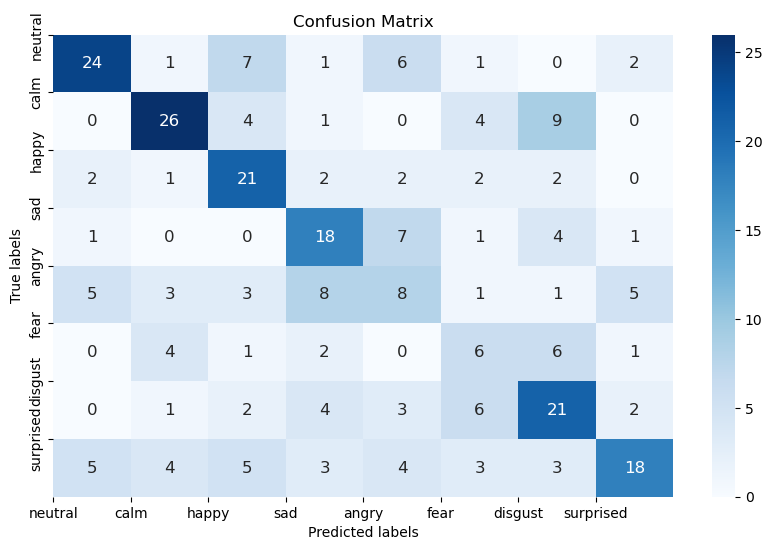

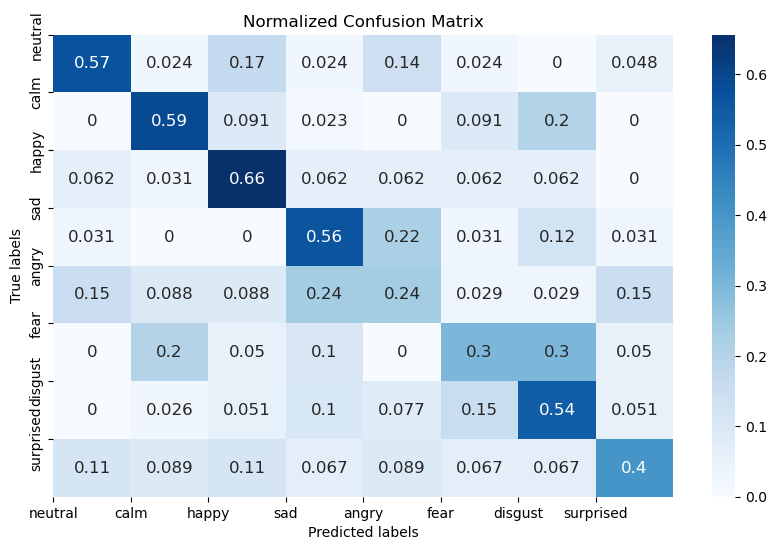

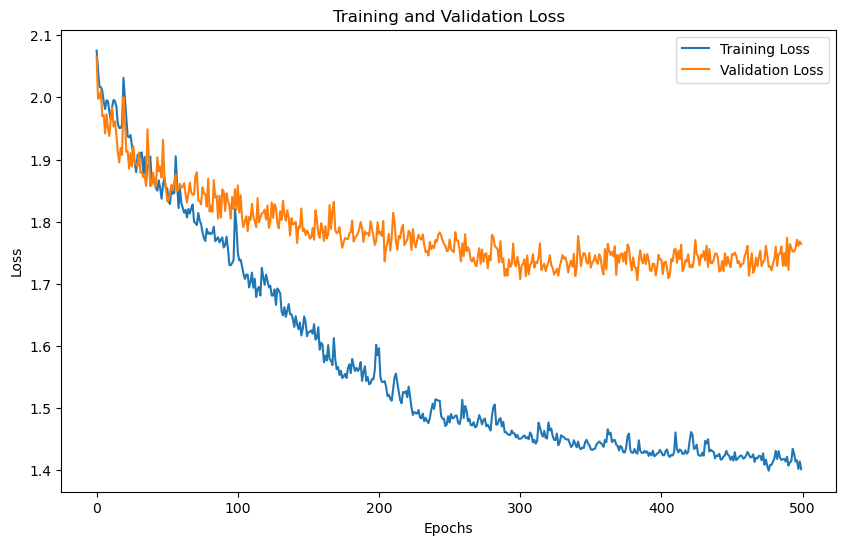

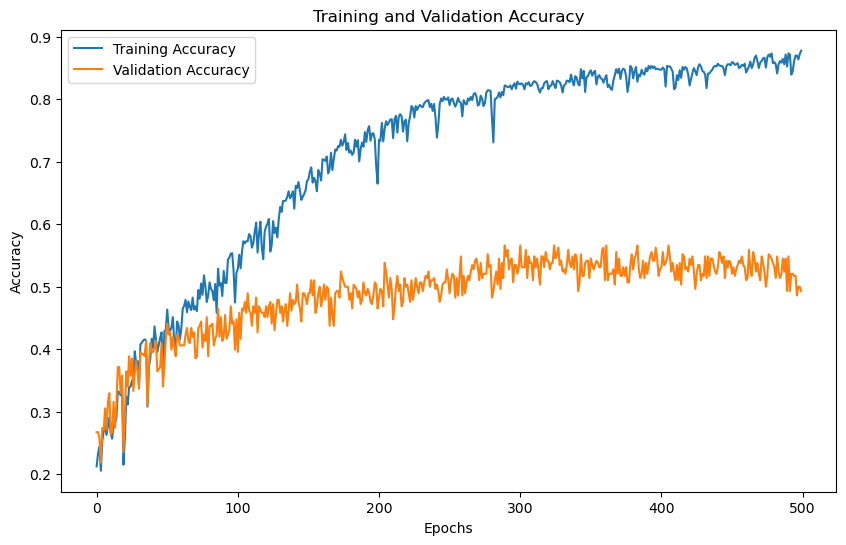

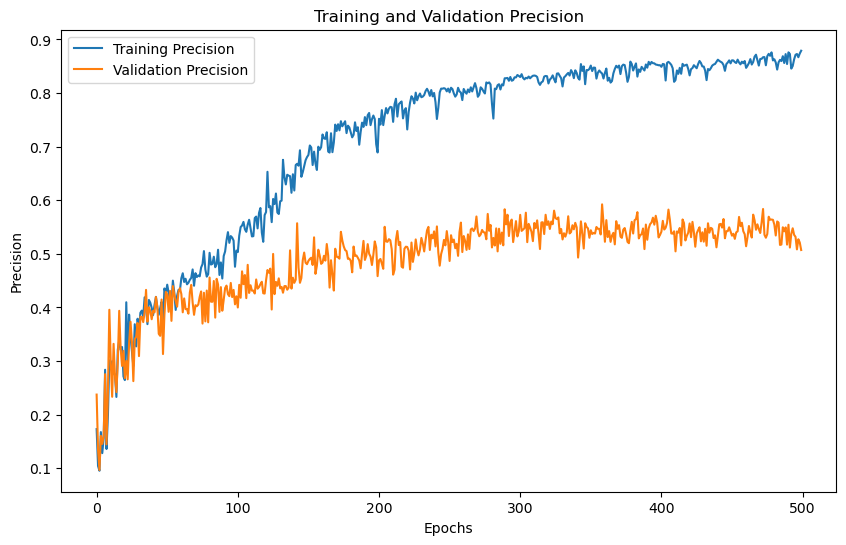

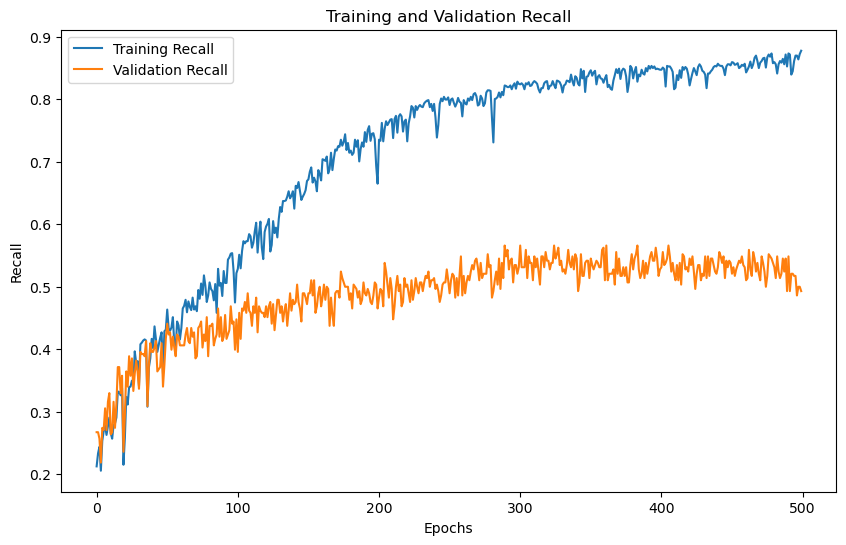

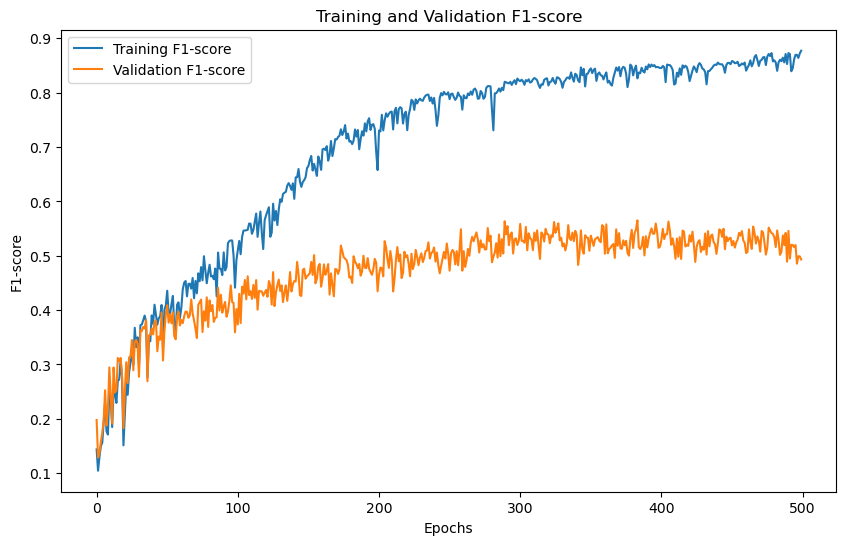

'Model Training and Evaluation Successfully completed'

In [13]:
train_model()

# RAVDESS
# DWT 2
# N_MFCC 24

Enter dataset name:
tess, savee, crema, ravdess
 ravdess
Enter dwt level:  2
Enter Number of MFCC coefficients : 24
No. of classes 8
Input size for wavelet level 2 = 72
Training with DWT level: 2
Hidden Size : 256
Model Name: CNN_LSTM_Model

X Shape : (1440, 72)
Y Shape : (1440, 8)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 2.0773, Training Accuracy: 0.1389, Training Precision:0.0193,Training Recall:0.1389,Training F1-Score:0.0339
Validation Loss: 2.0747, Validation Accuracy: 0.1111, Validation Precision:0.0123,Validation Recall:0.1111,Validation F1-Score:0.0222
Epoch [2/500],
Training Loss: 2.0722, Training Accuracy: 0.2127, Training Precision:0.0566,Training Recall:0.2127,Training F1-Score:0.0893
Validation Loss: 2.0210, Validation Accuracy: 0.2118, Validation Precision:0.0561,Validation Recall:0.2118,Validation F1-Score:0.0887
Epoch [3/500],
Training Loss: 2.0230, Training Accuracy: 0.2109, Training Precision:0.1043,Training Recall:0.2109,Training F1-Score:0.1067
Validat

Epoch [30/500],
Training Loss: 2.0044, Training Accuracy: 0.2266, Training Precision:0.1584,Training Recall:0.2266,Training F1-Score:0.1358
Validation Loss: 1.9813, Validation Accuracy: 0.2743, Validation Precision:0.1992,Validation Recall:0.2743,Validation F1-Score:0.1748
Epoch [31/500],
Training Loss: 2.0582, Training Accuracy: 0.2214, Training Precision:0.1319,Training Recall:0.2214,Training F1-Score:0.1441
Validation Loss: 2.0175, Validation Accuracy: 0.2326, Validation Precision:0.1345,Validation Recall:0.2326,Validation F1-Score:0.1602
Epoch [32/500],
Training Loss: 2.0310, Training Accuracy: 0.1415, Training Precision:0.0764,Training Recall:0.1415,Training F1-Score:0.0512
Validation Loss: 2.1086, Validation Accuracy: 0.1597, Validation Precision:0.1334,Validation Recall:0.1597,Validation F1-Score:0.0649
Epoch [33/500],
Training Loss: 2.1150, Training Accuracy: 0.1380, Training Precision:0.0676,Training Recall:0.1380,Training F1-Score:0.0441
Validation Loss: 2.1100, Validation Ac

Epoch [60/500],
Training Loss: 2.0376, Training Accuracy: 0.2135, Training Precision:0.0912,Training Recall:0.2135,Training F1-Score:0.1122
Validation Loss: 2.0283, Validation Accuracy: 0.2153, Validation Precision:0.1022,Validation Recall:0.2153,Validation F1-Score:0.1206
Epoch [61/500],
Training Loss: 2.0343, Training Accuracy: 0.2266, Training Precision:0.1220,Training Recall:0.2266,Training F1-Score:0.1481
Validation Loss: 2.0266, Validation Accuracy: 0.2153, Validation Precision:0.1122,Validation Recall:0.2153,Validation F1-Score:0.1372
Epoch [62/500],
Training Loss: 2.0387, Training Accuracy: 0.2231, Training Precision:0.1140,Training Recall:0.2231,Training F1-Score:0.1434
Validation Loss: 2.0235, Validation Accuracy: 0.2396, Validation Precision:0.1249,Validation Recall:0.2396,Validation F1-Score:0.1579
Epoch [63/500],
Training Loss: 2.0351, Training Accuracy: 0.2031, Training Precision:0.0765,Training Recall:0.2031,Training F1-Score:0.1064
Validation Loss: 2.0296, Validation Ac

Epoch [90/500],
Training Loss: 2.0327, Training Accuracy: 0.2196, Training Precision:0.1105,Training Recall:0.2196,Training F1-Score:0.1371
Validation Loss: 2.0200, Validation Accuracy: 0.2431, Validation Precision:0.1313,Validation Recall:0.2431,Validation F1-Score:0.1596
Epoch [91/500],
Training Loss: 2.0321, Training Accuracy: 0.2283, Training Precision:0.1174,Training Recall:0.2283,Training F1-Score:0.1488
Validation Loss: 2.0228, Validation Accuracy: 0.2257, Validation Precision:0.1173,Validation Recall:0.2257,Validation F1-Score:0.1478
Epoch [92/500],
Training Loss: 2.0315, Training Accuracy: 0.2205, Training Precision:0.1203,Training Recall:0.2205,Training F1-Score:0.1383
Validation Loss: 2.0210, Validation Accuracy: 0.2326, Validation Precision:0.1451,Validation Recall:0.2326,Validation F1-Score:0.1561
Epoch [93/500],
Training Loss: 2.0263, Training Accuracy: 0.2214, Training Precision:0.1168,Training Recall:0.2214,Training F1-Score:0.1409
Validation Loss: 2.0231, Validation Ac

Epoch [120/500],
Training Loss: 2.0200, Training Accuracy: 0.2448, Training Precision:0.1528,Training Recall:0.2448,Training F1-Score:0.1827
Validation Loss: 2.0306, Validation Accuracy: 0.2083, Validation Precision:0.1325,Validation Recall:0.2083,Validation F1-Score:0.1576
Epoch [121/500],
Training Loss: 2.0156, Training Accuracy: 0.2509, Training Precision:0.1497,Training Recall:0.2509,Training F1-Score:0.1701
Validation Loss: 2.0297, Validation Accuracy: 0.2222, Validation Precision:0.1135,Validation Recall:0.2222,Validation F1-Score:0.1408
Epoch [122/500],
Training Loss: 2.0145, Training Accuracy: 0.2405, Training Precision:0.1467,Training Recall:0.2405,Training F1-Score:0.1658
Validation Loss: 2.0288, Validation Accuracy: 0.2083, Validation Precision:0.1234,Validation Recall:0.2083,Validation F1-Score:0.1419
Epoch [123/500],
Training Loss: 2.0215, Training Accuracy: 0.2240, Training Precision:0.1355,Training Recall:0.2240,Training F1-Score:0.1516
Validation Loss: 2.0288, Validatio

...

Epoch [360/500],
Training Loss: 1.5745, Training Accuracy: 0.7049, Training Precision:0.6014,Training Recall:0.7049,Training F1-Score:0.6435
Validation Loss: 1.8377, Validation Accuracy: 0.4271, Validation Precision:0.3611,Validation Recall:0.4271,Validation F1-Score:0.3876
Epoch [361/500],
Training Loss: 1.5747, Training Accuracy: 0.7031, Training Precision:0.6165,Training Recall:0.7031,Training F1-Score:0.6421
Validation Loss: 1.8511, Validation Accuracy: 0.4132, Validation Precision:0.3390,Validation Recall:0.4132,Validation F1-Score:0.3627
Epoch [362/500],
Training Loss: 1.5766, Training Accuracy: 0.7014, Training Precision:0.5980,Training Recall:0.7014,Training F1-Score:0.6368
Validation Loss: 1.8432, Validation Accuracy: 0.4306, Validation Precision:0.3715,Validation Recall:0.4306,Validation F1-Score:0.3898
Epoch [363/500],
Training Loss: 1.5699, Training Accuracy: 0.6953, Training Precision:0.5960,Training Recall:0.6953,Training F1-Score:0.6318
Validation Loss: 1.8770, Validatio

Epoch [390/500],
Training Loss: 1.4912, Training Accuracy: 0.8003, Training Precision:0.8063,Training Recall:0.8003,Training F1-Score:0.7967
Validation Loss: 1.7956, Validation Accuracy: 0.4688, Validation Precision:0.4772,Validation Recall:0.4688,Validation F1-Score:0.4630
Epoch [391/500],
Training Loss: 1.4842, Training Accuracy: 0.8108, Training Precision:0.8169,Training Recall:0.8108,Training F1-Score:0.8065
Validation Loss: 1.7984, Validation Accuracy: 0.4792, Validation Precision:0.4926,Validation Recall:0.4792,Validation F1-Score:0.4740
Epoch [392/500],
Training Loss: 1.4850, Training Accuracy: 0.7830, Training Precision:0.7857,Training Recall:0.7830,Training F1-Score:0.7802
Validation Loss: 1.8080, Validation Accuracy: 0.4549, Validation Precision:0.4870,Validation Recall:0.4549,Validation F1-Score:0.4556
Epoch [393/500],
Training Loss: 1.4827, Training Accuracy: 0.8134, Training Precision:0.8167,Training Recall:0.8134,Training F1-Score:0.8111
Validation Loss: 1.8154, Validatio

Epoch [420/500],
Training Loss: 1.4375, Training Accuracy: 0.8559, Training Precision:0.8635,Training Recall:0.8559,Training F1-Score:0.8561
Validation Loss: 1.7726, Validation Accuracy: 0.5000, Validation Precision:0.5375,Validation Recall:0.5000,Validation F1-Score:0.5057
Epoch [421/500],
Training Loss: 1.4349, Training Accuracy: 0.8602, Training Precision:0.8691,Training Recall:0.8602,Training F1-Score:0.8607
Validation Loss: 1.7777, Validation Accuracy: 0.4931, Validation Precision:0.5033,Validation Recall:0.4931,Validation F1-Score:0.4843
Epoch [422/500],
Training Loss: 1.4325, Training Accuracy: 0.8516, Training Precision:0.8588,Training Recall:0.8516,Training F1-Score:0.8520
Validation Loss: 1.7753, Validation Accuracy: 0.4861, Validation Precision:0.5105,Validation Recall:0.4861,Validation F1-Score:0.4886
Epoch [423/500],
Training Loss: 1.4244, Training Accuracy: 0.8542, Training Precision:0.8622,Training Recall:0.8542,Training F1-Score:0.8545
Validation Loss: 1.7867, Validatio

Epoch [450/500],
Training Loss: 1.3993, Training Accuracy: 0.8733, Training Precision:0.8795,Training Recall:0.8733,Training F1-Score:0.8735
Validation Loss: 1.7878, Validation Accuracy: 0.4861, Validation Precision:0.5218,Validation Recall:0.4861,Validation F1-Score:0.4783
Epoch [451/500],
Training Loss: 1.4074, Training Accuracy: 0.8715, Training Precision:0.8780,Training Recall:0.8715,Training F1-Score:0.8719
Validation Loss: 1.7962, Validation Accuracy: 0.4722, Validation Precision:0.4859,Validation Recall:0.4722,Validation F1-Score:0.4678
Epoch [452/500],
Training Loss: 1.4066, Training Accuracy: 0.8767, Training Precision:0.8821,Training Recall:0.8767,Training F1-Score:0.8771
Validation Loss: 1.7802, Validation Accuracy: 0.4965, Validation Precision:0.5156,Validation Recall:0.4965,Validation F1-Score:0.4931
Epoch [453/500],
Training Loss: 1.4023, Training Accuracy: 0.8811, Training Precision:0.8863,Training Recall:0.8811,Training F1-Score:0.8812
Validation Loss: 1.7649, Validatio

Epoch [480/500],
Training Loss: 1.4092, Training Accuracy: 0.8724, Training Precision:0.8811,Training Recall:0.8724,Training F1-Score:0.8733
Validation Loss: 1.7681, Validation Accuracy: 0.5069, Validation Precision:0.5217,Validation Recall:0.5069,Validation F1-Score:0.5033
Epoch [481/500],
Training Loss: 1.3978, Training Accuracy: 0.8828, Training Precision:0.8898,Training Recall:0.8828,Training F1-Score:0.8833
Validation Loss: 1.7666, Validation Accuracy: 0.5000, Validation Precision:0.5315,Validation Recall:0.5000,Validation F1-Score:0.5020
Epoch [482/500],
Training Loss: 1.4076, Training Accuracy: 0.8602, Training Precision:0.8674,Training Recall:0.8602,Training F1-Score:0.8610
Validation Loss: 1.7711, Validation Accuracy: 0.5174, Validation Precision:0.5318,Validation Recall:0.5174,Validation F1-Score:0.5111
Epoch [483/500],
Training Loss: 1.4275, Training Accuracy: 0.8490, Training Precision:0.8576,Training Recall:0.8490,Training F1-Score:0.8498
Validation Loss: 1.7580, Validatio

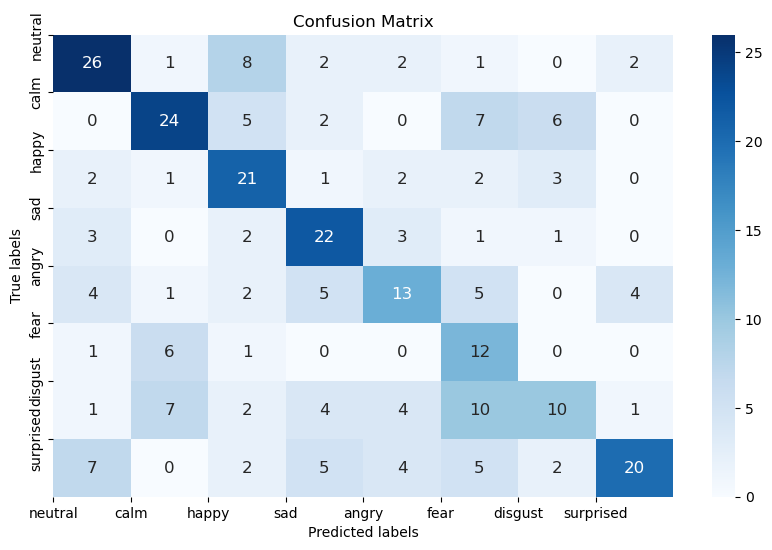

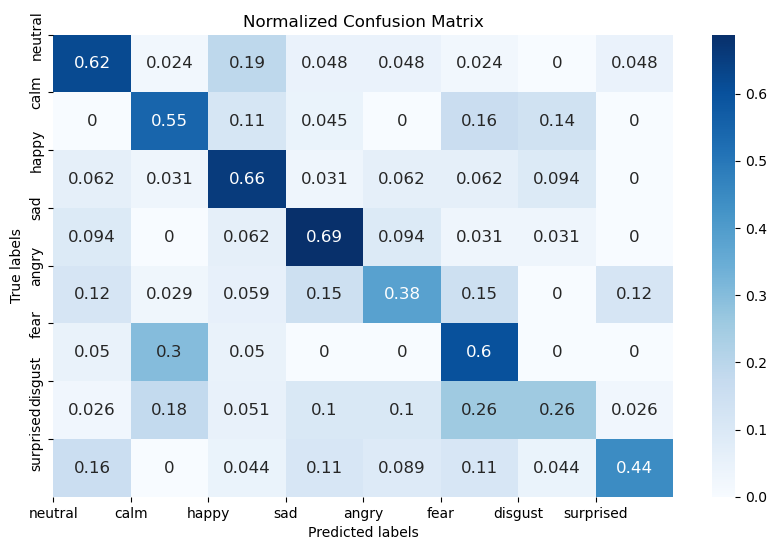

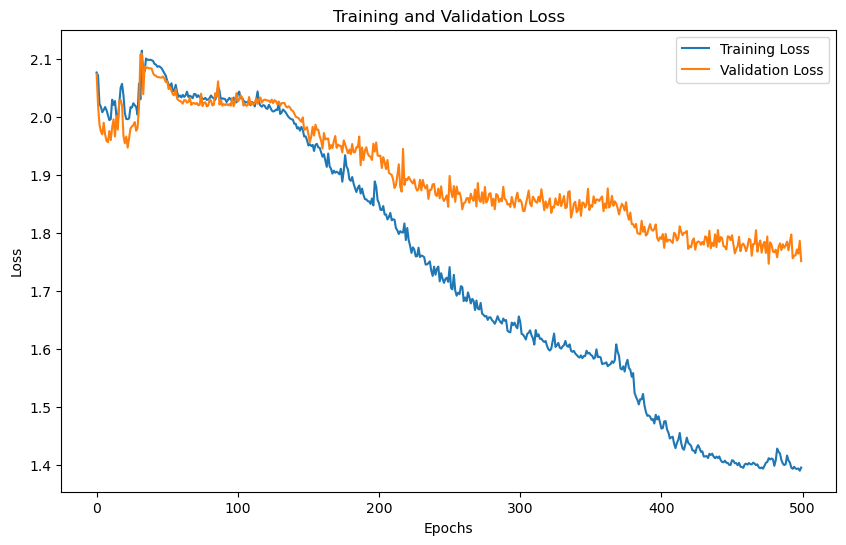

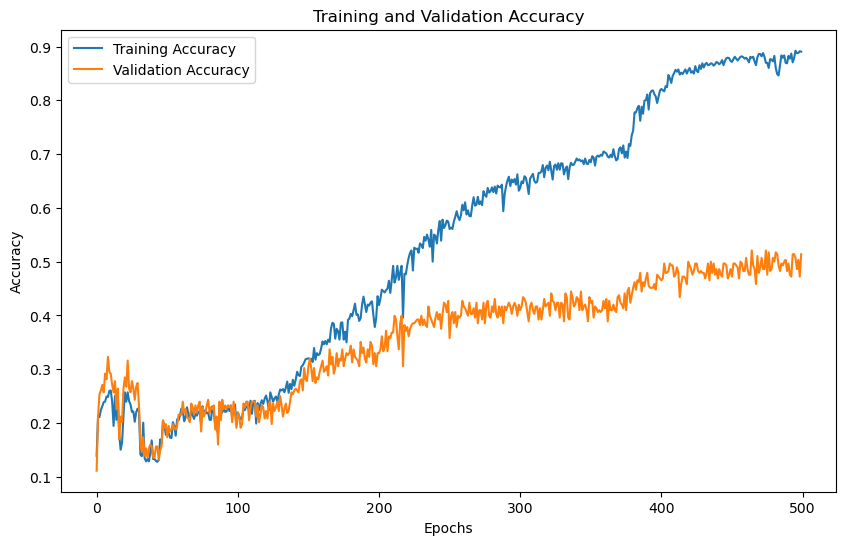

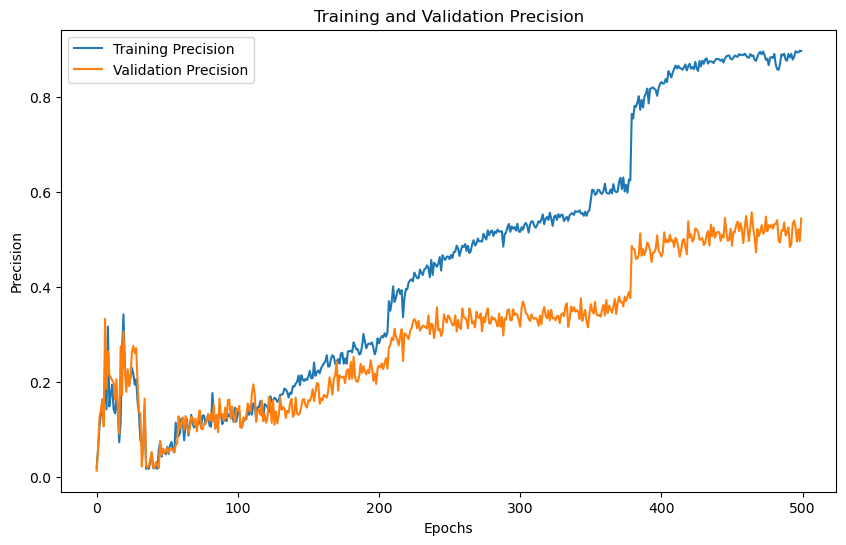

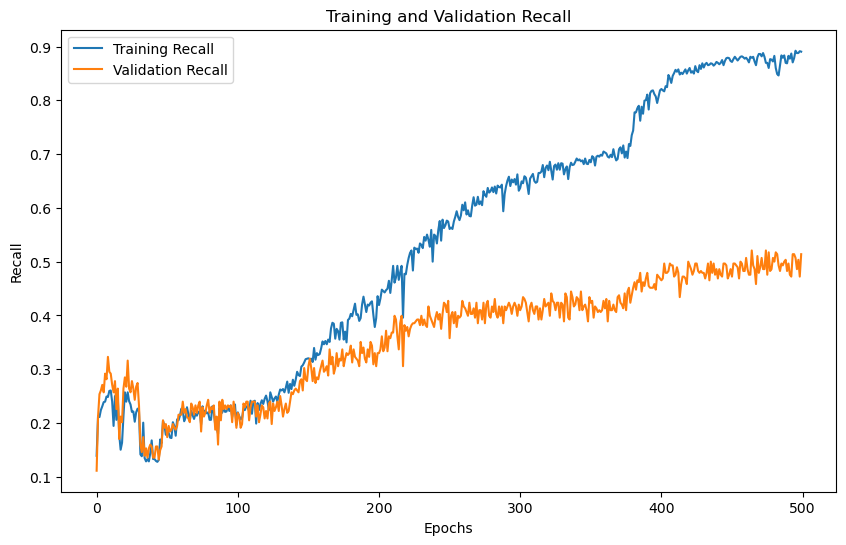

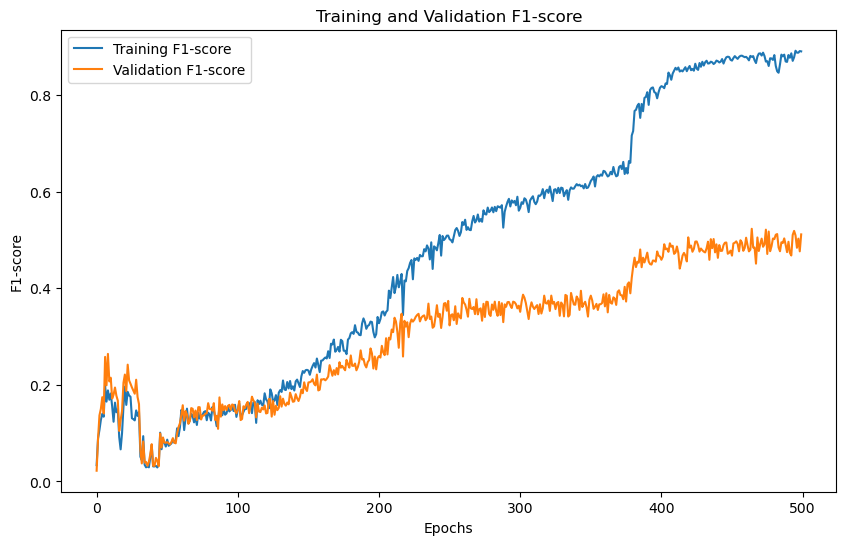

'Model Training and Evaluation Successfully completed'

In [18]:
train_model()

# TESS
# DWT 1
# N_MFCC 32

Enter dataset name:
tess, savee, crema, ravdess
 tess
Enter dwt level:  1
Enter Number of MFCC coefficients : 32
No. of classes 7
Input size for wavelet level 1 = 64
Training with DWT level: 1
Hidden Size : 256
Model Name: CNN_LSTM_Model

X Shape : (2800, 64)
Y Shape : (2800, 7)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.8738, Training Accuracy: 0.4661, Training Precision:0.3564,Training Recall:0.4661,Training F1-Score:0.3575
Validation Loss: 1.7303, Validation Accuracy: 0.4446, Validation Precision:0.3977,Validation Recall:0.4446,Validation F1-Score:0.3383
Epoch [2/500],
Training Loss: 1.6849, Training Accuracy: 0.5237, Training Precision:0.4166,Training Recall:0.5237,Training F1-Score:0.4548
Validation Loss: 1.6338, Validation Accuracy: 0.5179, Validation Precision:0.3990,Validation Recall:0.5179,Validation F1-Score:0.4424
Epoch [3/500],
Training Loss: 1.5395, Training Accuracy: 0.6857, Training Precision:0.6258,Training Recall:0.6857,Training F1-Score:0.6361
Validation

Epoch [30/500],
Training Loss: 1.2618, Training Accuracy: 0.9076, Training Precision:0.9312,Training Recall:0.9076,Training F1-Score:0.8996
Validation Loss: 1.2741, Validation Accuracy: 0.8911, Validation Precision:0.9127,Validation Recall:0.8911,Validation F1-Score:0.8803
Epoch [31/500],
Training Loss: 1.2666, Training Accuracy: 0.9080, Training Precision:0.9324,Training Recall:0.9080,Training F1-Score:0.9005
Validation Loss: 1.2768, Validation Accuracy: 0.8857, Validation Precision:0.9098,Validation Recall:0.8857,Validation F1-Score:0.8758
Epoch [32/500],
Training Loss: 1.2551, Training Accuracy: 0.9089, Training Precision:0.9281,Training Recall:0.9089,Training F1-Score:0.9003
Validation Loss: 1.2631, Validation Accuracy: 0.9000, Validation Precision:0.9156,Validation Recall:0.9000,Validation F1-Score:0.8906
Epoch [33/500],
Training Loss: 1.2724, Training Accuracy: 0.8929, Training Precision:0.9205,Training Recall:0.8929,Training F1-Score:0.8868
Validation Loss: 1.2819, Validation Ac

Epoch [60/500],
Training Loss: 1.2608, Training Accuracy: 0.9116, Training Precision:0.9398,Training Recall:0.9116,Training F1-Score:0.9077
Validation Loss: 1.2567, Validation Accuracy: 0.9089, Validation Precision:0.9257,Validation Recall:0.9089,Validation F1-Score:0.9035
Epoch [61/500],
Training Loss: 1.2635, Training Accuracy: 0.8790, Training Precision:0.9036,Training Recall:0.8790,Training F1-Score:0.8769
Validation Loss: 1.2902, Validation Accuracy: 0.8768, Validation Precision:0.8944,Validation Recall:0.8768,Validation F1-Score:0.8740
Epoch [62/500],
Training Loss: 1.2405, Training Accuracy: 0.9621, Training Precision:0.9633,Training Recall:0.9621,Training F1-Score:0.9619
Validation Loss: 1.2152, Validation Accuracy: 0.9518, Validation Precision:0.9543,Validation Recall:0.9518,Validation F1-Score:0.9515
Epoch [63/500],
Training Loss: 1.1928, Training Accuracy: 0.9866, Training Precision:0.9867,Training Recall:0.9866,Training F1-Score:0.9866
Validation Loss: 1.1789, Validation Ac

Epoch [90/500],
Training Loss: 1.1721, Training Accuracy: 0.9911, Training Precision:0.9914,Training Recall:0.9911,Training F1-Score:0.9911
Validation Loss: 1.1901, Validation Accuracy: 0.9750, Validation Precision:0.9758,Validation Recall:0.9750,Validation F1-Score:0.9750
Epoch [91/500],
Training Loss: 1.1815, Training Accuracy: 0.9643, Training Precision:0.9684,Training Recall:0.9643,Training F1-Score:0.9649
Validation Loss: 1.2020, Validation Accuracy: 0.9643, Validation Precision:0.9662,Validation Recall:0.9643,Validation F1-Score:0.9644
Epoch [92/500],
Training Loss: 1.1857, Training Accuracy: 0.9951, Training Precision:0.9951,Training Recall:0.9951,Training F1-Score:0.9951
Validation Loss: 1.1850, Validation Accuracy: 0.9786, Validation Precision:0.9789,Validation Recall:0.9786,Validation F1-Score:0.9786
Epoch [93/500],
Training Loss: 1.1775, Training Accuracy: 0.9866, Training Precision:0.9877,Training Recall:0.9866,Training F1-Score:0.9866
Validation Loss: 1.1919, Validation Ac

Epoch [120/500],
Training Loss: 1.1722, Training Accuracy: 0.9862, Training Precision:0.9867,Training Recall:0.9862,Training F1-Score:0.9860
Validation Loss: 1.1950, Validation Accuracy: 0.9714, Validation Precision:0.9727,Validation Recall:0.9714,Validation F1-Score:0.9713
Epoch [121/500],
Training Loss: 1.1781, Training Accuracy: 0.9924, Training Precision:0.9926,Training Recall:0.9924,Training F1-Score:0.9924
Validation Loss: 1.1888, Validation Accuracy: 0.9768, Validation Precision:0.9779,Validation Recall:0.9768,Validation F1-Score:0.9768
Epoch [122/500],
Training Loss: 1.2048, Training Accuracy: 0.9746, Training Precision:0.9757,Training Recall:0.9746,Training F1-Score:0.9746
Validation Loss: 1.2137, Validation Accuracy: 0.9482, Validation Precision:0.9503,Validation Recall:0.9482,Validation F1-Score:0.9484
Epoch [123/500],
Training Loss: 1.1812, Training Accuracy: 0.9924, Training Precision:0.9925,Training Recall:0.9924,Training F1-Score:0.9924
Validation Loss: 1.1923, Validatio

...

Epoch [360/500],
Training Loss: 1.1654, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.1762, Validation Accuracy: 0.9893, Validation Precision:0.9898,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [361/500],
Training Loss: 1.1654, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.1762, Validation Accuracy: 0.9893, Validation Precision:0.9898,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [362/500],
Training Loss: 1.1654, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.1762, Validation Accuracy: 0.9893, Validation Precision:0.9898,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [363/500],
Training Loss: 1.1654, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.1762, Validatio

Epoch [390/500],
Training Loss: 1.1654, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.1762, Validation Accuracy: 0.9893, Validation Precision:0.9898,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [391/500],
Training Loss: 1.1654, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.1762, Validation Accuracy: 0.9893, Validation Precision:0.9898,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [392/500],
Training Loss: 1.1654, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.1762, Validation Accuracy: 0.9893, Validation Precision:0.9898,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [393/500],
Training Loss: 1.1654, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.1762, Validatio

Epoch [420/500],
Training Loss: 1.1654, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.1762, Validation Accuracy: 0.9893, Validation Precision:0.9898,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [421/500],
Training Loss: 1.1654, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.1761, Validation Accuracy: 0.9893, Validation Precision:0.9898,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [422/500],
Training Loss: 1.1654, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.1761, Validation Accuracy: 0.9893, Validation Precision:0.9898,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [423/500],
Training Loss: 1.1654, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.1763, Validatio

Epoch [450/500],
Training Loss: 1.1654, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.1762, Validation Accuracy: 0.9893, Validation Precision:0.9898,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [451/500],
Training Loss: 1.1654, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.1762, Validation Accuracy: 0.9893, Validation Precision:0.9898,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [452/500],
Training Loss: 1.1654, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.1762, Validation Accuracy: 0.9893, Validation Precision:0.9898,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [453/500],
Training Loss: 1.1654, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.1762, Validatio

Epoch [480/500],
Training Loss: 1.1654, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.1763, Validation Accuracy: 0.9893, Validation Precision:0.9898,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [481/500],
Training Loss: 1.1654, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.1762, Validation Accuracy: 0.9893, Validation Precision:0.9898,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [482/500],
Training Loss: 1.1654, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.1763, Validation Accuracy: 0.9893, Validation Precision:0.9898,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [483/500],
Training Loss: 1.1654, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.1762, Validatio

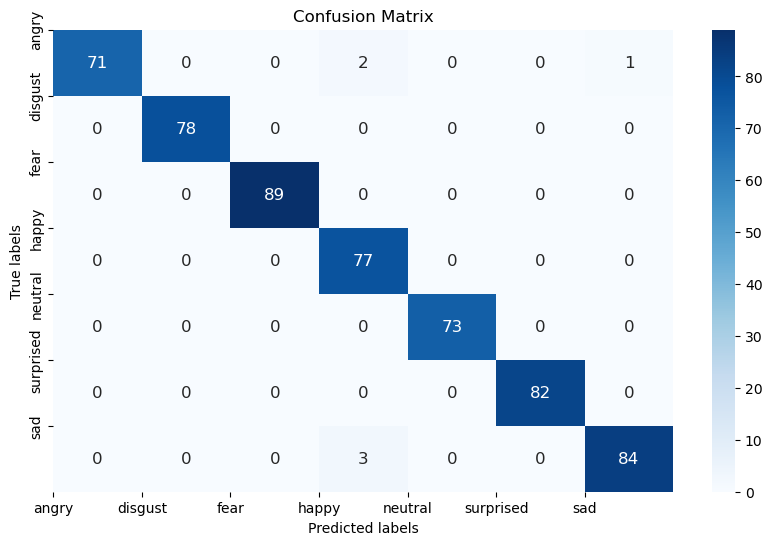

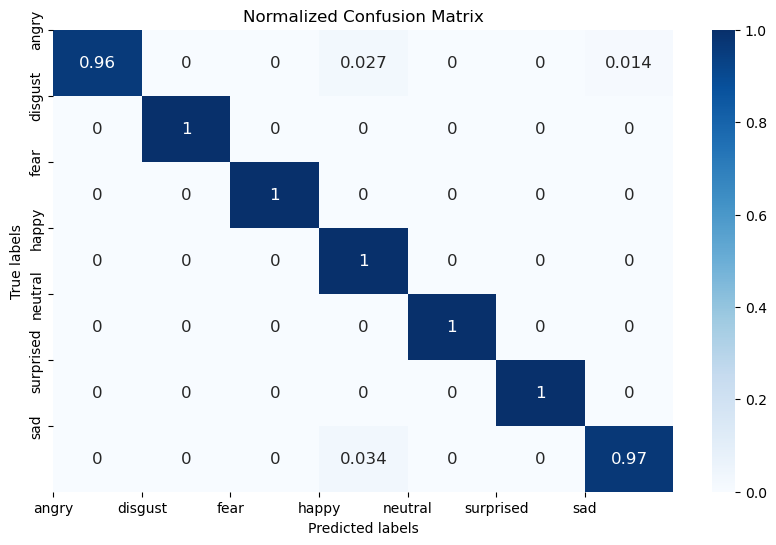

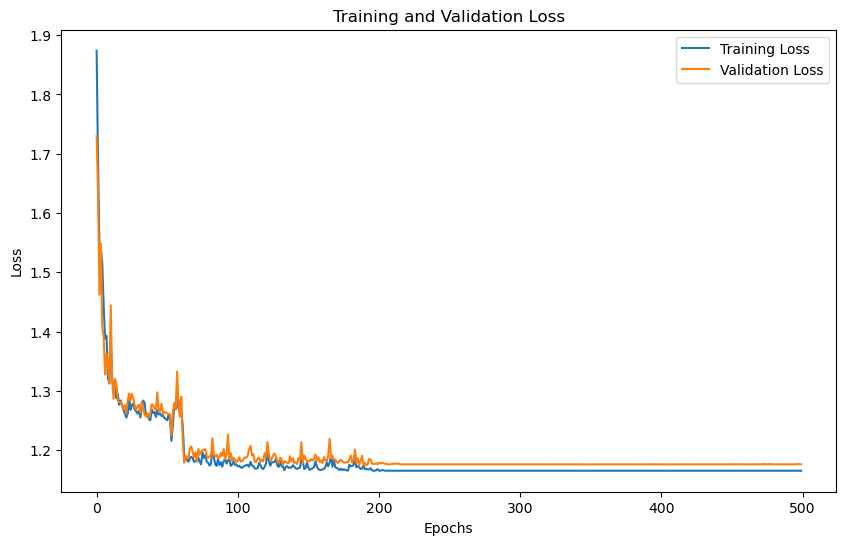

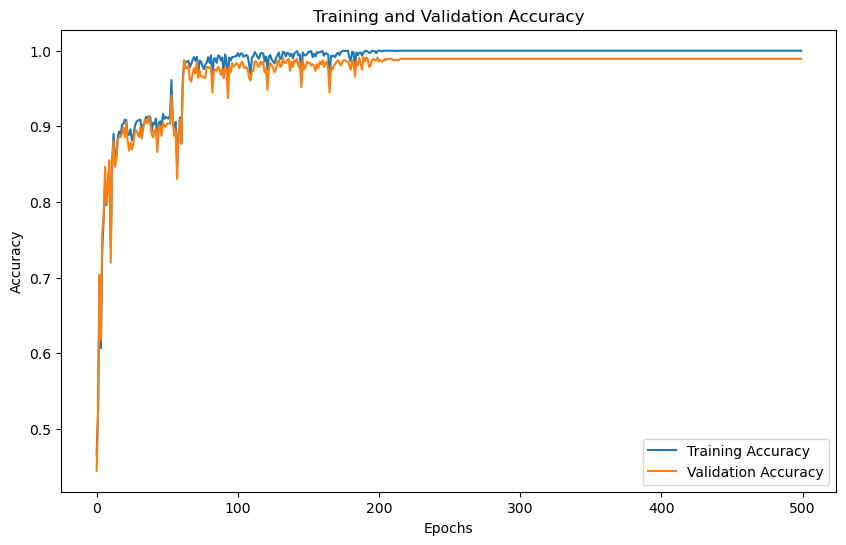

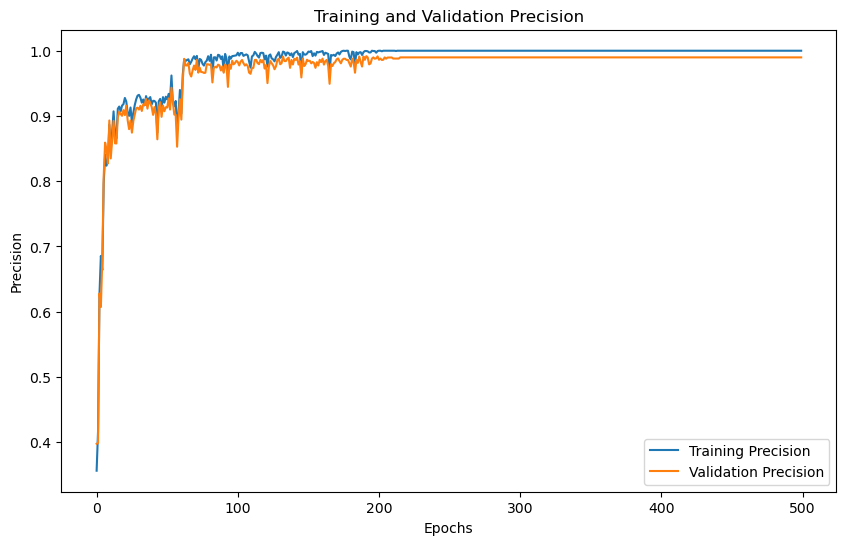

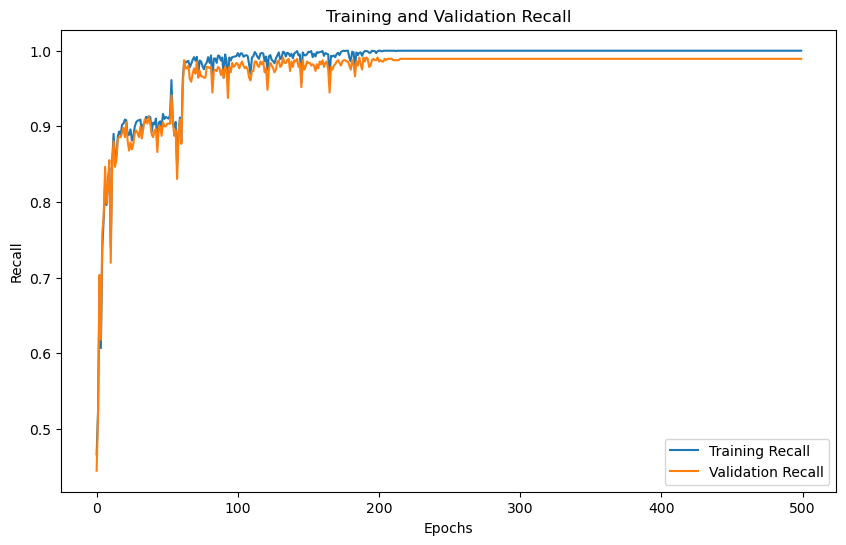

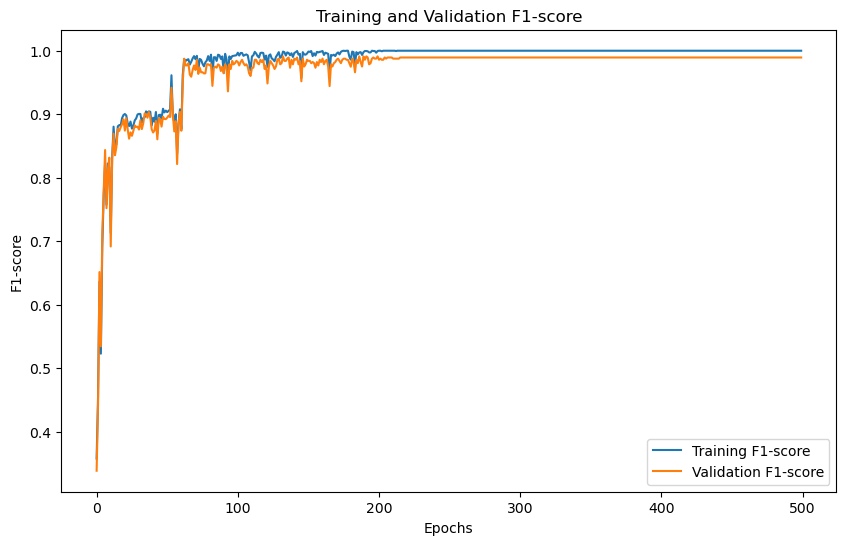

'Model Training and Evaluation Successfully completed'

In [19]:
train_model()

# TESS
# DWT 3
# N_MFCC 32

Enter dataset name:
tess, savee, crema, ravdess
 tess
Enter dwt level:  3
Enter Number of MFCC coefficients : 32
No. of classes 7
Input size for wavelet level 3 = 128
Training with DWT level: 3
Hidden Size : 256
Model Name: CNN_LSTM_Model

X Shape : (2800, 128)
Y Shape : (2800, 7)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.8829, Training Accuracy: 0.3054, Training Precision:0.1490,Training Recall:0.3054,Training F1-Score:0.1903
Validation Loss: 1.8028, Validation Accuracy: 0.3036, Validation Precision:0.1342,Validation Recall:0.3036,Validation F1-Score:0.1792
Epoch [2/500],
Training Loss: 1.6871, Training Accuracy: 0.5848, Training Precision:0.5291,Training Recall:0.5848,Training F1-Score:0.5414
Validation Loss: 1.5787, Validation Accuracy: 0.6036, Validation Precision:0.5501,Validation Recall:0.6036,Validation F1-Score:0.5622
Epoch [3/500],
Training Loss: 1.5503, Training Accuracy: 0.6741, Training Precision:0.6018,Training Recall:0.6741,Training F1-Score:0.6236
Validati

Epoch [30/500],
Training Loss: 1.2530, Training Accuracy: 0.9147, Training Precision:0.9297,Training Recall:0.9147,Training F1-Score:0.9085
Validation Loss: 1.2643, Validation Accuracy: 0.9018, Validation Precision:0.9153,Validation Recall:0.9018,Validation F1-Score:0.8968
Epoch [31/500],
Training Loss: 1.2479, Training Accuracy: 0.9187, Training Precision:0.9316,Training Recall:0.9187,Training F1-Score:0.9109
Validation Loss: 1.2539, Validation Accuracy: 0.9107, Validation Precision:0.9189,Validation Recall:0.9107,Validation F1-Score:0.9029
Epoch [32/500],
Training Loss: 1.2511, Training Accuracy: 0.9161, Training Precision:0.9313,Training Recall:0.9161,Training F1-Score:0.9087
Validation Loss: 1.2631, Validation Accuracy: 0.9036, Validation Precision:0.9179,Validation Recall:0.9036,Validation F1-Score:0.8979
Epoch [33/500],
Training Loss: 1.2479, Training Accuracy: 0.9125, Training Precision:0.9265,Training Recall:0.9125,Training F1-Score:0.9045
Validation Loss: 1.2628, Validation Ac

Epoch [60/500],
Training Loss: 1.1729, Training Accuracy: 0.9955, Training Precision:0.9955,Training Recall:0.9955,Training F1-Score:0.9955
Validation Loss: 1.1854, Validation Accuracy: 0.9821, Validation Precision:0.9825,Validation Recall:0.9821,Validation F1-Score:0.9821
Epoch [61/500],
Training Loss: 1.1779, Training Accuracy: 0.9879, Training Precision:0.9882,Training Recall:0.9879,Training F1-Score:0.9880
Validation Loss: 1.1943, Validation Accuracy: 0.9732, Validation Precision:0.9741,Validation Recall:0.9732,Validation F1-Score:0.9733
Epoch [62/500],
Training Loss: 1.1766, Training Accuracy: 0.9835, Training Precision:0.9840,Training Recall:0.9835,Training F1-Score:0.9835
Validation Loss: 1.1976, Validation Accuracy: 0.9696, Validation Precision:0.9712,Validation Recall:0.9696,Validation F1-Score:0.9696
Epoch [63/500],
Training Loss: 1.1882, Training Accuracy: 0.9911, Training Precision:0.9912,Training Recall:0.9911,Training F1-Score:0.9911
Validation Loss: 1.1932, Validation Ac

Epoch [90/500],
Training Loss: 1.1704, Training Accuracy: 0.9973, Training Precision:0.9973,Training Recall:0.9973,Training F1-Score:0.9973
Validation Loss: 1.1821, Validation Accuracy: 0.9839, Validation Precision:0.9843,Validation Recall:0.9839,Validation F1-Score:0.9839
Epoch [91/500],
Training Loss: 1.1829, Training Accuracy: 0.9821, Training Precision:0.9826,Training Recall:0.9821,Training F1-Score:0.9821
Validation Loss: 1.2001, Validation Accuracy: 0.9661, Validation Precision:0.9670,Validation Recall:0.9661,Validation F1-Score:0.9658
Epoch [92/500],
Training Loss: 1.1771, Training Accuracy: 0.9924, Training Precision:0.9924,Training Recall:0.9924,Training F1-Score:0.9924
Validation Loss: 1.1920, Validation Accuracy: 0.9732, Validation Precision:0.9738,Validation Recall:0.9732,Validation F1-Score:0.9732
Epoch [93/500],
Training Loss: 1.1697, Training Accuracy: 0.9973, Training Precision:0.9973,Training Recall:0.9973,Training F1-Score:0.9973
Validation Loss: 1.1861, Validation Ac

Epoch [120/500],
Training Loss: 1.1675, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1777, Validation Accuracy: 0.9875, Validation Precision:0.9876,Validation Recall:0.9875,Validation F1-Score:0.9875
Epoch [121/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1764, Validation Accuracy: 0.9893, Validation Precision:0.9893,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [122/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1768, Validation Accuracy: 0.9875, Validation Precision:0.9876,Validation Recall:0.9875,Validation F1-Score:0.9875
Epoch [123/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1765, Validatio

...

Epoch [360/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1820, Validation Accuracy: 0.9839, Validation Precision:0.9841,Validation Recall:0.9839,Validation F1-Score:0.9839
Epoch [361/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1819, Validation Accuracy: 0.9839, Validation Precision:0.9841,Validation Recall:0.9839,Validation F1-Score:0.9839
Epoch [362/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1820, Validation Accuracy: 0.9839, Validation Precision:0.9841,Validation Recall:0.9839,Validation F1-Score:0.9839
Epoch [363/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1820, Validatio

Epoch [390/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1819, Validation Accuracy: 0.9839, Validation Precision:0.9841,Validation Recall:0.9839,Validation F1-Score:0.9839
Epoch [391/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1824, Validation Accuracy: 0.9839, Validation Precision:0.9841,Validation Recall:0.9839,Validation F1-Score:0.9839
Epoch [392/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1821, Validation Accuracy: 0.9839, Validation Precision:0.9841,Validation Recall:0.9839,Validation F1-Score:0.9839
Epoch [393/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1819, Validatio

Epoch [420/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1821, Validation Accuracy: 0.9839, Validation Precision:0.9841,Validation Recall:0.9839,Validation F1-Score:0.9839
Epoch [421/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1829, Validation Accuracy: 0.9821, Validation Precision:0.9823,Validation Recall:0.9821,Validation F1-Score:0.9822
Epoch [422/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1825, Validation Accuracy: 0.9821, Validation Precision:0.9823,Validation Recall:0.9821,Validation F1-Score:0.9822
Epoch [423/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1822, Validatio

Epoch [450/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1830, Validation Accuracy: 0.9821, Validation Precision:0.9823,Validation Recall:0.9821,Validation F1-Score:0.9822
Epoch [451/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1831, Validation Accuracy: 0.9821, Validation Precision:0.9823,Validation Recall:0.9821,Validation F1-Score:0.9822
Epoch [452/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1830, Validation Accuracy: 0.9821, Validation Precision:0.9823,Validation Recall:0.9821,Validation F1-Score:0.9822
Epoch [453/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1830, Validatio

Epoch [480/500],
Training Loss: 1.1856, Training Accuracy: 0.9915, Training Precision:0.9915,Training Recall:0.9915,Training F1-Score:0.9915
Validation Loss: 1.1864, Validation Accuracy: 0.9786, Validation Precision:0.9792,Validation Recall:0.9786,Validation F1-Score:0.9785
Epoch [481/500],
Training Loss: 1.1772, Training Accuracy: 0.9942, Training Precision:0.9942,Training Recall:0.9942,Training F1-Score:0.9942
Validation Loss: 1.1793, Validation Accuracy: 0.9857, Validation Precision:0.9858,Validation Recall:0.9857,Validation F1-Score:0.9857
Epoch [482/500],
Training Loss: 1.1745, Training Accuracy: 0.9942, Training Precision:0.9943,Training Recall:0.9942,Training F1-Score:0.9942
Validation Loss: 1.1842, Validation Accuracy: 0.9804, Validation Precision:0.9808,Validation Recall:0.9804,Validation F1-Score:0.9803
Epoch [483/500],
Training Loss: 1.1713, Training Accuracy: 0.9924, Training Precision:0.9927,Training Recall:0.9924,Training F1-Score:0.9924
Validation Loss: 1.1801, Validatio

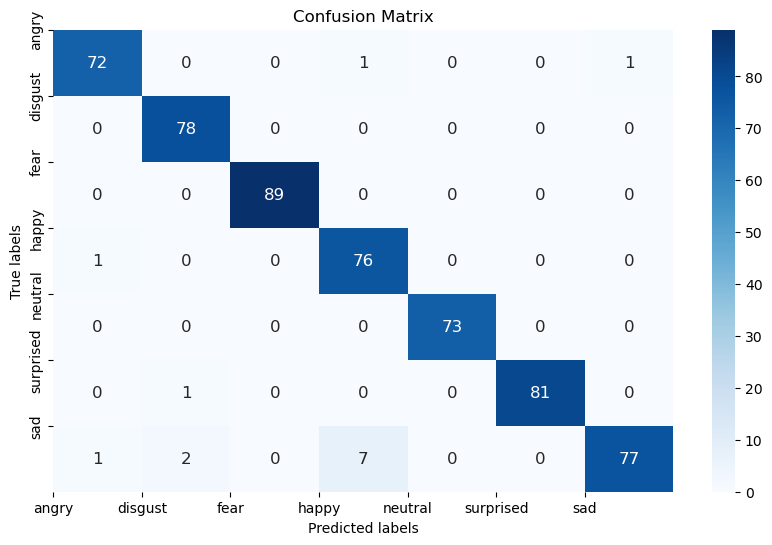

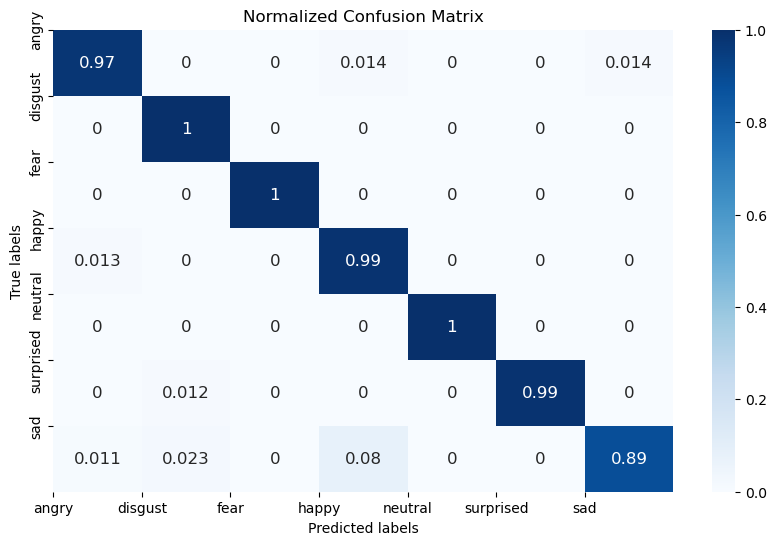

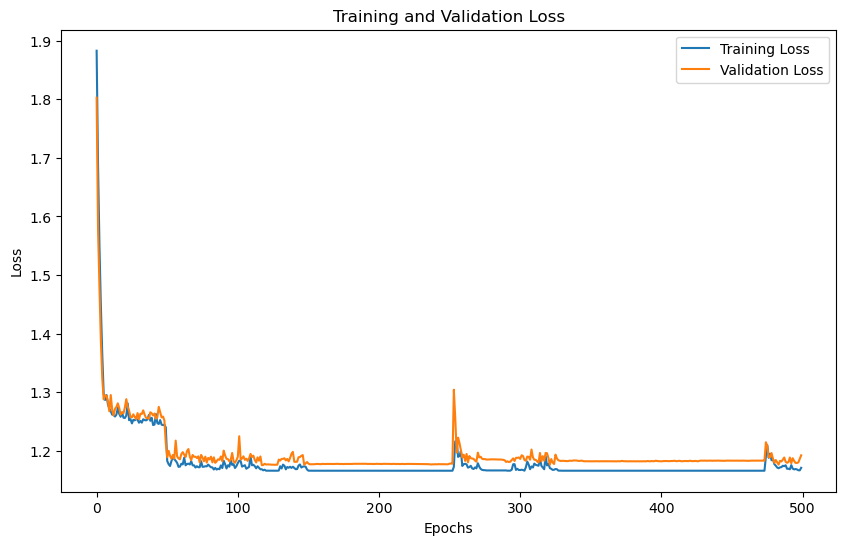

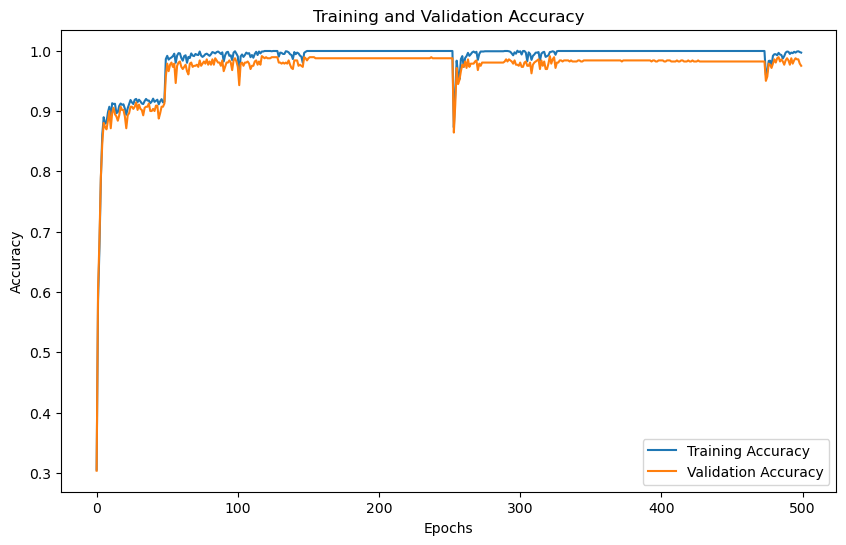

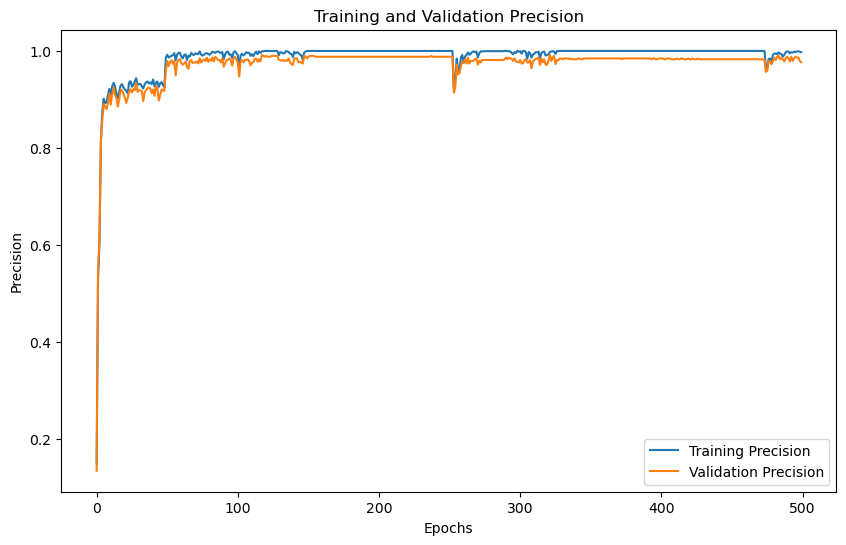

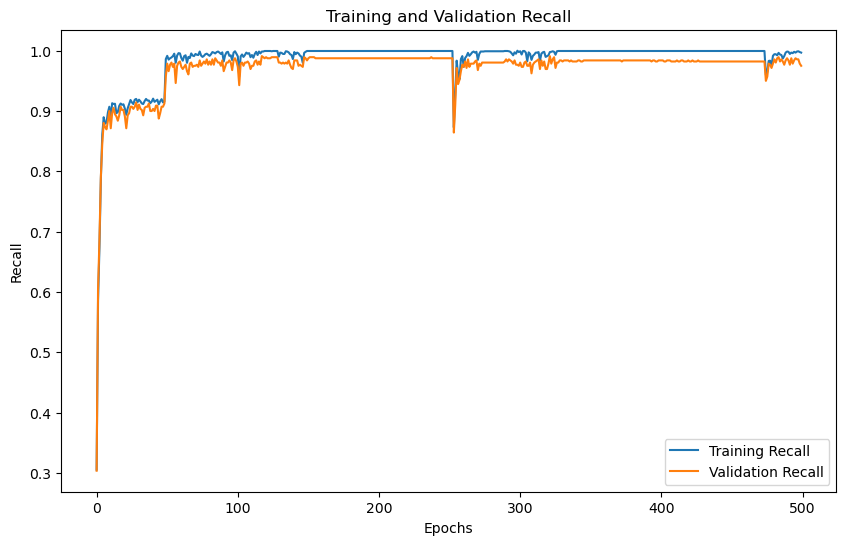

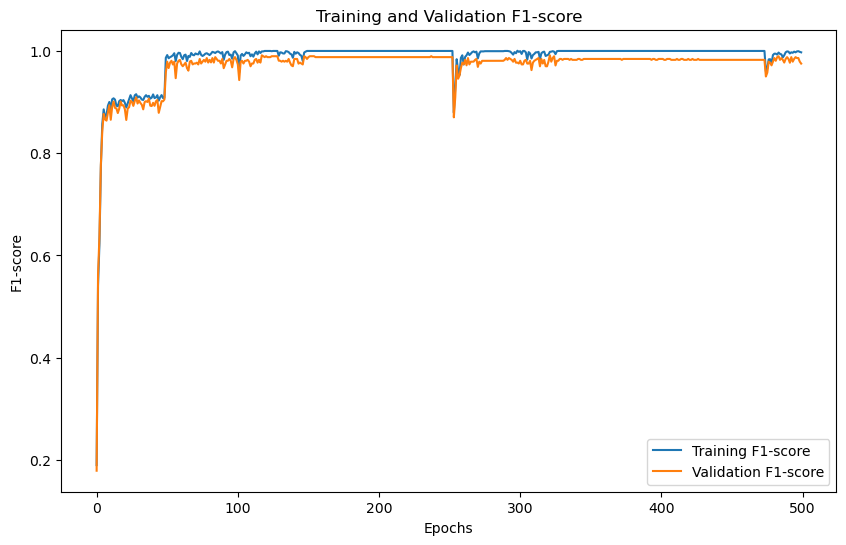

'Model Training and Evaluation Successfully completed'

In [11]:
train_model()

# TESS
# DWT 3
# N_MFCC 32

Enter dataset name:
tess, savee, crema, ravdess
 tess
Enter dwt level:  4
Enter Number of MFCC coefficients : 32
No. of classes 7
Input size for wavelet level 4 = 160
Training with DWT level: 4
Hidden Size : 256
Model Name: CNN_LSTM_Model

X Shape : (2800, 160)
Y Shape : (2800, 7)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.9167, Training Accuracy: 0.2799, Training Precision:0.1405,Training Recall:0.2799,Training F1-Score:0.1730
Validation Loss: 1.8868, Validation Accuracy: 0.2571, Validation Precision:0.1224,Validation Recall:0.2571,Validation F1-Score:0.1528
Epoch [2/500],
Training Loss: 1.7701, Training Accuracy: 0.4830, Training Precision:0.3182,Training Recall:0.4830,Training F1-Score:0.3706
Validation Loss: 1.6626, Validation Accuracy: 0.4946, Validation Precision:0.3280,Validation Recall:0.4946,Validation F1-Score:0.3803
Epoch [3/500],
Training Loss: 1.5801, Training Accuracy: 0.6424, Training Precision:0.6027,Training Recall:0.6424,Training F1-Score:0.5767
Validati

Epoch [30/500],
Training Loss: 1.2477, Training Accuracy: 0.9201, Training Precision:0.9346,Training Recall:0.9201,Training F1-Score:0.9130
Validation Loss: 1.2572, Validation Accuracy: 0.9054, Validation Precision:0.9155,Validation Recall:0.9054,Validation F1-Score:0.8987
Epoch [31/500],
Training Loss: 1.2448, Training Accuracy: 0.9187, Training Precision:0.9349,Training Recall:0.9187,Training F1-Score:0.9123
Validation Loss: 1.2566, Validation Accuracy: 0.9089, Validation Precision:0.9228,Validation Recall:0.9089,Validation F1-Score:0.9033
Epoch [32/500],
Training Loss: 1.2480, Training Accuracy: 0.9116, Training Precision:0.9298,Training Recall:0.9116,Training F1-Score:0.9062
Validation Loss: 1.2585, Validation Accuracy: 0.9089, Validation Precision:0.9234,Validation Recall:0.9089,Validation F1-Score:0.9035
Epoch [33/500],
Training Loss: 1.2495, Training Accuracy: 0.9246, Training Precision:0.9371,Training Recall:0.9246,Training F1-Score:0.9166
Validation Loss: 1.2512, Validation Ac

Epoch [60/500],
Training Loss: 1.2487, Training Accuracy: 0.9067, Training Precision:0.9146,Training Recall:0.9067,Training F1-Score:0.8992
Validation Loss: 1.2680, Validation Accuracy: 0.8964, Validation Precision:0.8967,Validation Recall:0.8964,Validation F1-Score:0.8887
Epoch [61/500],
Training Loss: 1.2467, Training Accuracy: 0.9250, Training Precision:0.9467,Training Recall:0.9250,Training F1-Score:0.9199
Validation Loss: 1.2463, Validation Accuracy: 0.9179, Validation Precision:0.9371,Validation Recall:0.9179,Validation F1-Score:0.9125
Epoch [62/500],
Training Loss: 1.2406, Training Accuracy: 0.9201, Training Precision:0.9336,Training Recall:0.9201,Training F1-Score:0.9125
Validation Loss: 1.2565, Validation Accuracy: 0.9089, Validation Precision:0.9215,Validation Recall:0.9089,Validation F1-Score:0.8998
Epoch [63/500],
Training Loss: 1.2415, Training Accuracy: 0.9250, Training Precision:0.9448,Training Recall:0.9250,Training F1-Score:0.9191
Validation Loss: 1.2507, Validation Ac

Epoch [90/500],
Training Loss: 1.2343, Training Accuracy: 0.9277, Training Precision:0.9418,Training Recall:0.9277,Training F1-Score:0.9198
Validation Loss: 1.2421, Validation Accuracy: 0.9214, Validation Precision:0.9347,Validation Recall:0.9214,Validation F1-Score:0.9134
Epoch [91/500],
Training Loss: 1.2343, Training Accuracy: 0.9277, Training Precision:0.9470,Training Recall:0.9277,Training F1-Score:0.9216
Validation Loss: 1.2421, Validation Accuracy: 0.9214, Validation Precision:0.9359,Validation Recall:0.9214,Validation F1-Score:0.9137
Epoch [92/500],
Training Loss: 1.2343, Training Accuracy: 0.9277, Training Precision:0.9416,Training Recall:0.9277,Training F1-Score:0.9198
Validation Loss: 1.2424, Validation Accuracy: 0.9196, Validation Precision:0.9324,Validation Recall:0.9196,Validation F1-Score:0.9114
Epoch [93/500],
Training Loss: 1.2343, Training Accuracy: 0.9277, Training Precision:0.9416,Training Recall:0.9277,Training F1-Score:0.9198
Validation Loss: 1.2430, Validation Ac

Epoch [120/500],
Training Loss: 1.2343, Training Accuracy: 0.9277, Training Precision:0.9439,Training Recall:0.9277,Training F1-Score:0.9205
Validation Loss: 1.2408, Validation Accuracy: 0.9232, Validation Precision:0.9359,Validation Recall:0.9232,Validation F1-Score:0.9149
Epoch [121/500],
Training Loss: 1.2343, Training Accuracy: 0.9277, Training Precision:0.9419,Training Recall:0.9277,Training F1-Score:0.9199
Validation Loss: 1.2411, Validation Accuracy: 0.9214, Validation Precision:0.9355,Validation Recall:0.9214,Validation F1-Score:0.9137
Epoch [122/500],
Training Loss: 1.2343, Training Accuracy: 0.9277, Training Precision:0.9418,Training Recall:0.9277,Training F1-Score:0.9198
Validation Loss: 1.2419, Validation Accuracy: 0.9214, Validation Precision:0.9352,Validation Recall:0.9214,Validation F1-Score:0.9135
Epoch [123/500],
Training Loss: 1.2343, Training Accuracy: 0.9277, Training Precision:0.9423,Training Recall:0.9277,Training F1-Score:0.9200
Validation Loss: 1.2408, Validatio

...

Epoch [360/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1809, Validation Accuracy: 0.9839, Validation Precision:0.9843,Validation Recall:0.9839,Validation F1-Score:0.9839
Epoch [361/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1808, Validation Accuracy: 0.9839, Validation Precision:0.9843,Validation Recall:0.9839,Validation F1-Score:0.9839
Epoch [362/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1809, Validation Accuracy: 0.9839, Validation Precision:0.9843,Validation Recall:0.9839,Validation F1-Score:0.9839
Epoch [363/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1809, Validatio

Epoch [390/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1806, Validation Accuracy: 0.9839, Validation Precision:0.9843,Validation Recall:0.9839,Validation F1-Score:0.9839
Epoch [391/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1807, Validation Accuracy: 0.9839, Validation Precision:0.9843,Validation Recall:0.9839,Validation F1-Score:0.9839
Epoch [392/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1809, Validation Accuracy: 0.9839, Validation Precision:0.9843,Validation Recall:0.9839,Validation F1-Score:0.9839
Epoch [393/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1809, Validatio

Epoch [420/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1807, Validation Accuracy: 0.9839, Validation Precision:0.9843,Validation Recall:0.9839,Validation F1-Score:0.9839
Epoch [421/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1808, Validation Accuracy: 0.9839, Validation Precision:0.9843,Validation Recall:0.9839,Validation F1-Score:0.9839
Epoch [422/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1805, Validation Accuracy: 0.9839, Validation Precision:0.9843,Validation Recall:0.9839,Validation F1-Score:0.9839
Epoch [423/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1805, Validatio

Epoch [450/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1804, Validation Accuracy: 0.9839, Validation Precision:0.9843,Validation Recall:0.9839,Validation F1-Score:0.9839
Epoch [451/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1806, Validation Accuracy: 0.9839, Validation Precision:0.9843,Validation Recall:0.9839,Validation F1-Score:0.9839
Epoch [452/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1806, Validation Accuracy: 0.9839, Validation Precision:0.9843,Validation Recall:0.9839,Validation F1-Score:0.9839
Epoch [453/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1806, Validatio

Epoch [480/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1805, Validation Accuracy: 0.9839, Validation Precision:0.9843,Validation Recall:0.9839,Validation F1-Score:0.9839
Epoch [481/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1805, Validation Accuracy: 0.9839, Validation Precision:0.9843,Validation Recall:0.9839,Validation F1-Score:0.9839
Epoch [482/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1804, Validation Accuracy: 0.9839, Validation Precision:0.9843,Validation Recall:0.9839,Validation F1-Score:0.9839
Epoch [483/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1805, Validatio

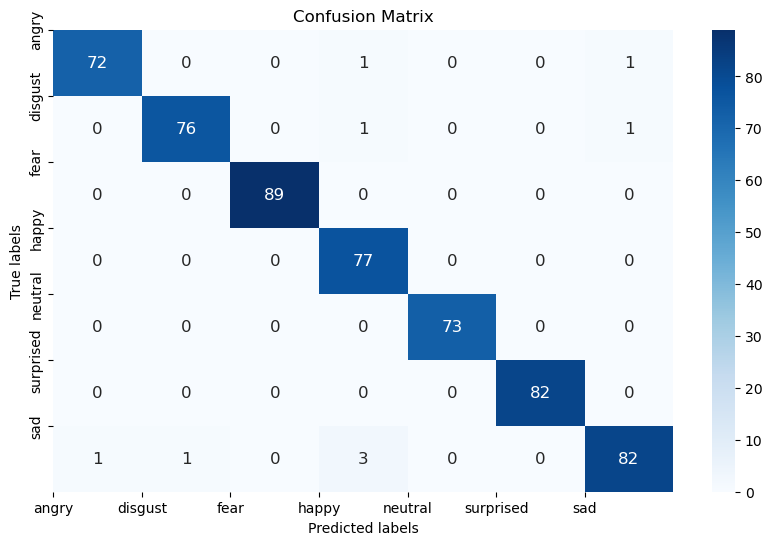

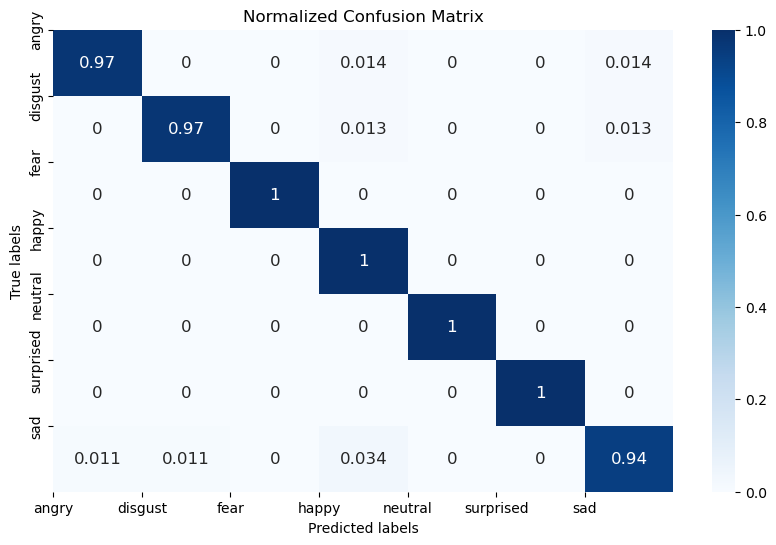

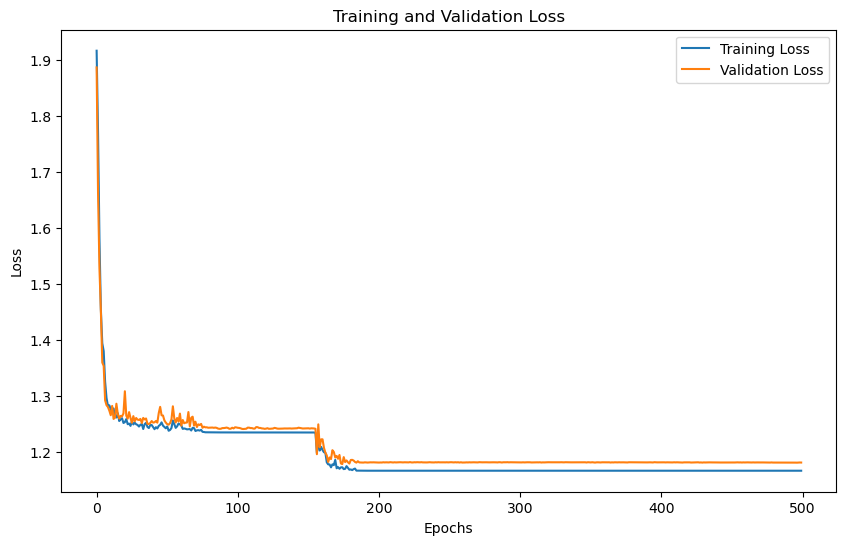

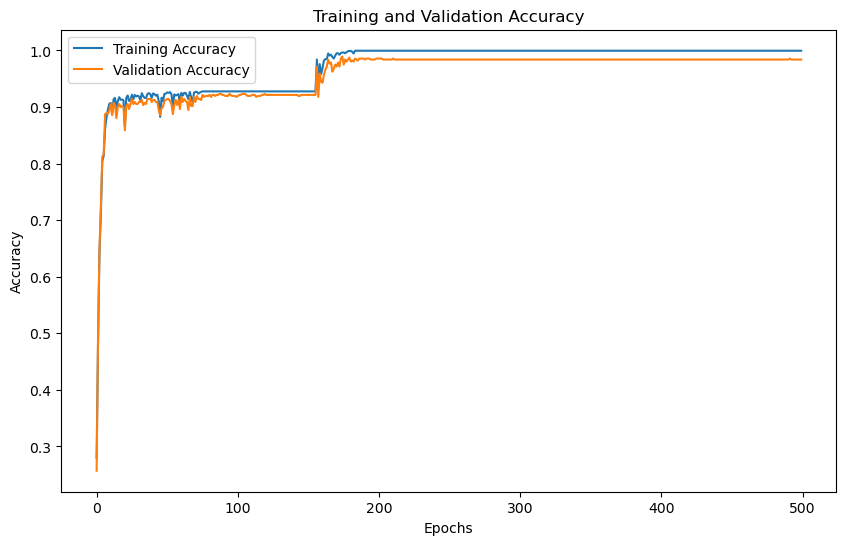

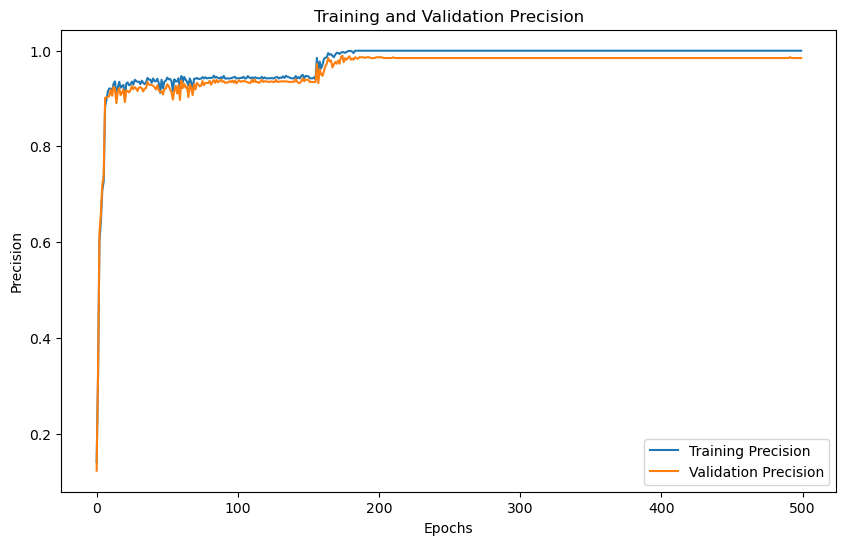

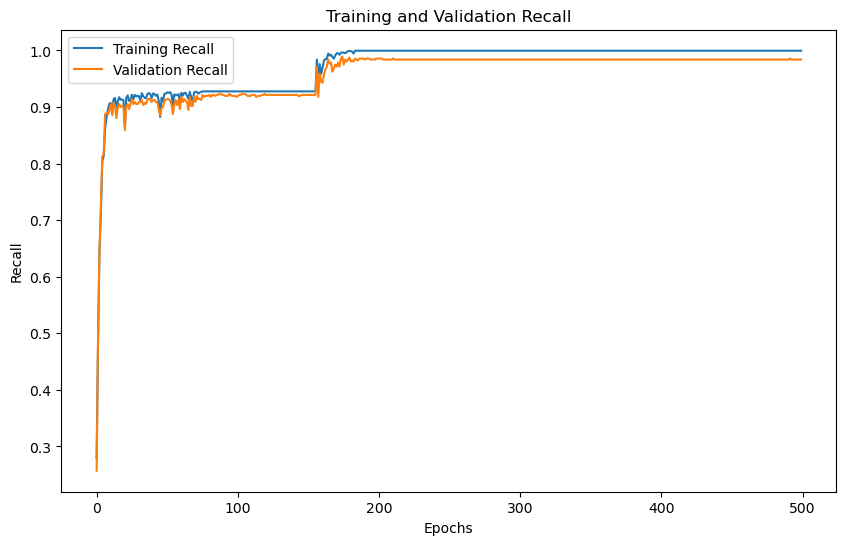

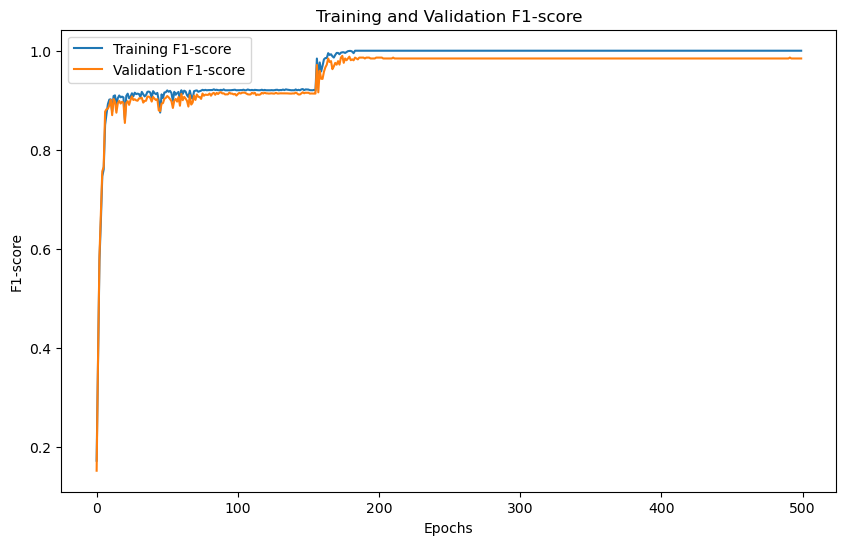

'Model Training and Evaluation Successfully completed'

In [13]:
train_model()

# TESS
# DWT 5
# N_MFCC 32

Enter dataset name:
tess, savee, crema, ravdess
 tess
Enter dwt level:  5
Enter Number of MFCC coefficients : 32
No. of classes 7
Input size for wavelet level 5 = 192
Training with DWT level: 5
Hidden Size : 256
Model Name: CNN_LSTM_Model

X Shape : (2800, 192)
Y Shape : (2800, 7)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.8821, Training Accuracy: 0.3339, Training Precision:0.2278,Training Recall:0.3339,Training F1-Score:0.2265
Validation Loss: 1.8273, Validation Accuracy: 0.3250, Validation Precision:0.1676,Validation Recall:0.3250,Validation F1-Score:0.2092
Epoch [2/500],
Training Loss: 1.7485, Training Accuracy: 0.4138, Training Precision:0.3805,Training Recall:0.4138,Training F1-Score:0.3526
Validation Loss: 1.7636, Validation Accuracy: 0.4036, Validation Precision:0.3663,Validation Recall:0.4036,Validation F1-Score:0.3405
Epoch [3/500],
Training Loss: 1.6732, Training Accuracy: 0.5683, Training Precision:0.5566,Training Recall:0.5683,Training F1-Score:0.5364
Validati

Epoch [30/500],
Training Loss: 1.2666, Training Accuracy: 0.9170, Training Precision:0.9300,Training Recall:0.9170,Training F1-Score:0.9091
Validation Loss: 1.2558, Validation Accuracy: 0.9089, Validation Precision:0.9244,Validation Recall:0.9089,Validation F1-Score:0.9022
Epoch [31/500],
Training Loss: 1.2520, Training Accuracy: 0.9085, Training Precision:0.9269,Training Recall:0.9085,Training F1-Score:0.8971
Validation Loss: 1.2643, Validation Accuracy: 0.8982, Validation Precision:0.9171,Validation Recall:0.8982,Validation F1-Score:0.8847
Epoch [32/500],
Training Loss: 1.2621, Training Accuracy: 0.9156, Training Precision:0.9325,Training Recall:0.9156,Training F1-Score:0.9085
Validation Loss: 1.2633, Validation Accuracy: 0.9000, Validation Precision:0.9144,Validation Recall:0.9000,Validation F1-Score:0.8945
Epoch [33/500],
Training Loss: 1.2489, Training Accuracy: 0.9143, Training Precision:0.9276,Training Recall:0.9143,Training F1-Score:0.9063
Validation Loss: 1.2642, Validation Ac

Epoch [60/500],
Training Loss: 1.1754, Training Accuracy: 0.9911, Training Precision:0.9912,Training Recall:0.9911,Training F1-Score:0.9911
Validation Loss: 1.2009, Validation Accuracy: 0.9643, Validation Precision:0.9661,Validation Recall:0.9643,Validation F1-Score:0.9645
Epoch [61/500],
Training Loss: 1.1792, Training Accuracy: 0.9960, Training Precision:0.9960,Training Recall:0.9960,Training F1-Score:0.9960
Validation Loss: 1.1857, Validation Accuracy: 0.9821, Validation Precision:0.9824,Validation Recall:0.9821,Validation F1-Score:0.9821
Epoch [62/500],
Training Loss: 1.1731, Training Accuracy: 0.9955, Training Precision:0.9956,Training Recall:0.9955,Training F1-Score:0.9955
Validation Loss: 1.1858, Validation Accuracy: 0.9768, Validation Precision:0.9774,Validation Recall:0.9768,Validation F1-Score:0.9768
Epoch [63/500],
Training Loss: 1.1710, Training Accuracy: 0.9955, Training Precision:0.9956,Training Recall:0.9955,Training F1-Score:0.9955
Validation Loss: 1.1870, Validation Ac

Epoch [90/500],
Training Loss: 1.1789, Training Accuracy: 0.9866, Training Precision:0.9869,Training Recall:0.9866,Training F1-Score:0.9866
Validation Loss: 1.1944, Validation Accuracy: 0.9732, Validation Precision:0.9747,Validation Recall:0.9732,Validation F1-Score:0.9733
Epoch [91/500],
Training Loss: 1.1769, Training Accuracy: 0.9969, Training Precision:0.9969,Training Recall:0.9969,Training F1-Score:0.9969
Validation Loss: 1.1905, Validation Accuracy: 0.9750, Validation Precision:0.9762,Validation Recall:0.9750,Validation F1-Score:0.9751
Epoch [92/500],
Training Loss: 1.1689, Training Accuracy: 0.9982, Training Precision:0.9982,Training Recall:0.9982,Training F1-Score:0.9982
Validation Loss: 1.1829, Validation Accuracy: 0.9821, Validation Precision:0.9827,Validation Recall:0.9821,Validation F1-Score:0.9821
Epoch [93/500],
Training Loss: 1.1669, Training Accuracy: 0.9987, Training Precision:0.9987,Training Recall:0.9987,Training F1-Score:0.9987
Validation Loss: 1.1841, Validation Ac

Epoch [120/500],
Training Loss: 1.1712, Training Accuracy: 0.9946, Training Precision:0.9947,Training Recall:0.9946,Training F1-Score:0.9946
Validation Loss: 1.1896, Validation Accuracy: 0.9750, Validation Precision:0.9755,Validation Recall:0.9750,Validation F1-Score:0.9750
Epoch [121/500],
Training Loss: 1.1704, Training Accuracy: 0.9835, Training Precision:0.9851,Training Recall:0.9835,Training F1-Score:0.9834
Validation Loss: 1.1936, Validation Accuracy: 0.9732, Validation Precision:0.9748,Validation Recall:0.9732,Validation F1-Score:0.9733
Epoch [122/500],
Training Loss: 1.1696, Training Accuracy: 0.9933, Training Precision:0.9934,Training Recall:0.9933,Training F1-Score:0.9933
Validation Loss: 1.1859, Validation Accuracy: 0.9804, Validation Precision:0.9805,Validation Recall:0.9804,Validation F1-Score:0.9804
Epoch [123/500],
Training Loss: 1.1704, Training Accuracy: 0.9982, Training Precision:0.9982,Training Recall:0.9982,Training F1-Score:0.9982
Validation Loss: 1.1782, Validatio

...

Epoch [360/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1852, Validation Accuracy: 0.9786, Validation Precision:0.9791,Validation Recall:0.9786,Validation F1-Score:0.9786
Epoch [361/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1846, Validation Accuracy: 0.9786, Validation Precision:0.9791,Validation Recall:0.9786,Validation F1-Score:0.9786
Epoch [362/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1842, Validation Accuracy: 0.9821, Validation Precision:0.9826,Validation Recall:0.9821,Validation F1-Score:0.9822
Epoch [363/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1849, Validatio

Epoch [390/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1847, Validation Accuracy: 0.9804, Validation Precision:0.9808,Validation Recall:0.9804,Validation F1-Score:0.9804
Epoch [391/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1844, Validation Accuracy: 0.9804, Validation Precision:0.9808,Validation Recall:0.9804,Validation F1-Score:0.9804
Epoch [392/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1849, Validation Accuracy: 0.9804, Validation Precision:0.9808,Validation Recall:0.9804,Validation F1-Score:0.9804
Epoch [393/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1849, Validatio

Epoch [420/500],
Training Loss: 1.1711, Training Accuracy: 0.9964, Training Precision:0.9965,Training Recall:0.9964,Training F1-Score:0.9964
Validation Loss: 1.1896, Validation Accuracy: 0.9768, Validation Precision:0.9782,Validation Recall:0.9768,Validation F1-Score:0.9769
Epoch [421/500],
Training Loss: 1.1721, Training Accuracy: 0.9960, Training Precision:0.9960,Training Recall:0.9960,Training F1-Score:0.9960
Validation Loss: 1.1872, Validation Accuracy: 0.9786, Validation Precision:0.9788,Validation Recall:0.9786,Validation F1-Score:0.9786
Epoch [422/500],
Training Loss: 1.1720, Training Accuracy: 0.9946, Training Precision:0.9947,Training Recall:0.9946,Training F1-Score:0.9946
Validation Loss: 1.1878, Validation Accuracy: 0.9786, Validation Precision:0.9788,Validation Recall:0.9786,Validation F1-Score:0.9786
Epoch [423/500],
Training Loss: 1.1725, Training Accuracy: 0.9924, Training Precision:0.9925,Training Recall:0.9924,Training F1-Score:0.9924
Validation Loss: 1.1988, Validatio

Epoch [450/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1823, Validation Accuracy: 0.9839, Validation Precision:0.9842,Validation Recall:0.9839,Validation F1-Score:0.9840
Epoch [451/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1822, Validation Accuracy: 0.9857, Validation Precision:0.9859,Validation Recall:0.9857,Validation F1-Score:0.9857
Epoch [452/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1822, Validation Accuracy: 0.9839, Validation Precision:0.9842,Validation Recall:0.9839,Validation F1-Score:0.9840
Epoch [453/500],
Training Loss: 1.1662, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1822, Validatio

Epoch [480/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1850, Validation Accuracy: 0.9804, Validation Precision:0.9806,Validation Recall:0.9804,Validation F1-Score:0.9804
Epoch [481/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1849, Validation Accuracy: 0.9804, Validation Precision:0.9806,Validation Recall:0.9804,Validation F1-Score:0.9804
Epoch [482/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1855, Validation Accuracy: 0.9804, Validation Precision:0.9806,Validation Recall:0.9804,Validation F1-Score:0.9804
Epoch [483/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1857, Validatio

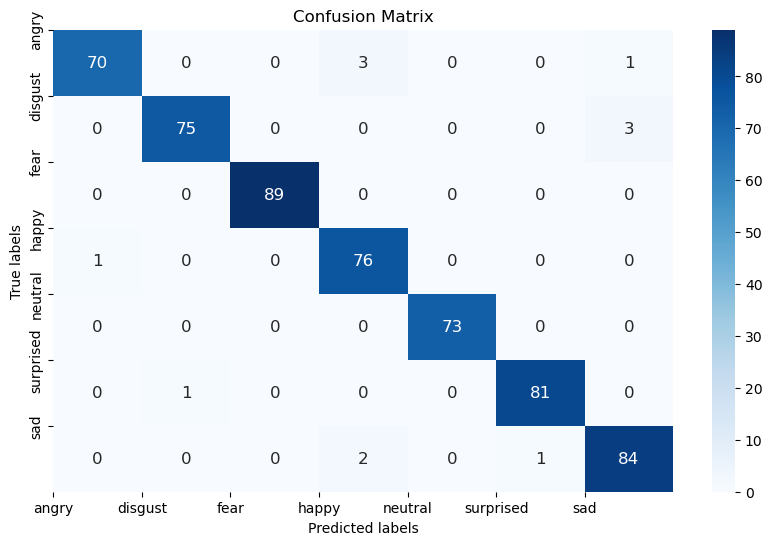

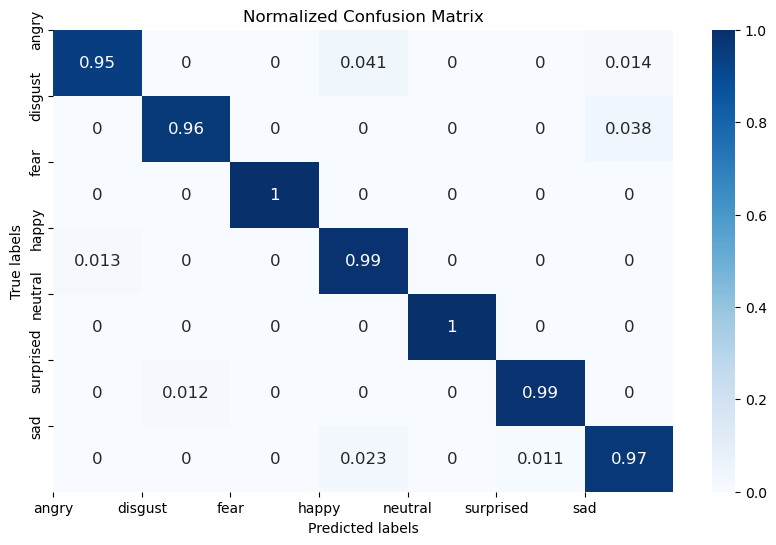

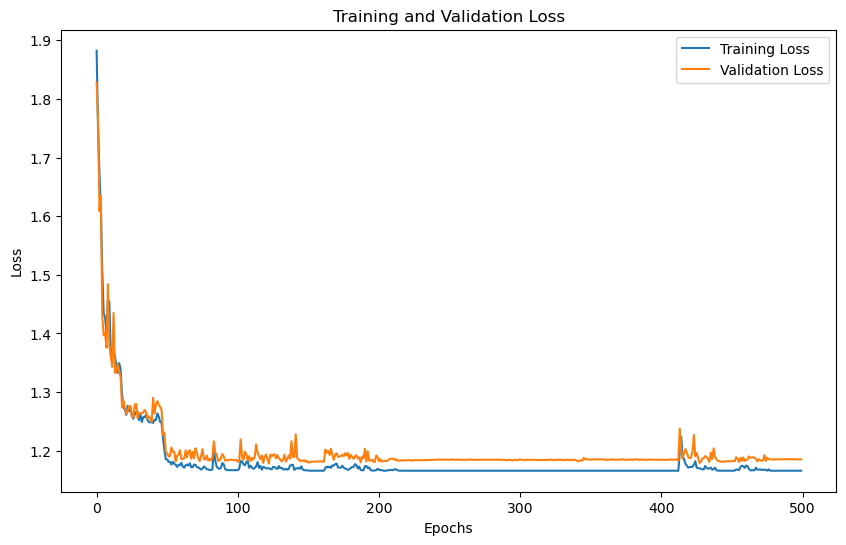

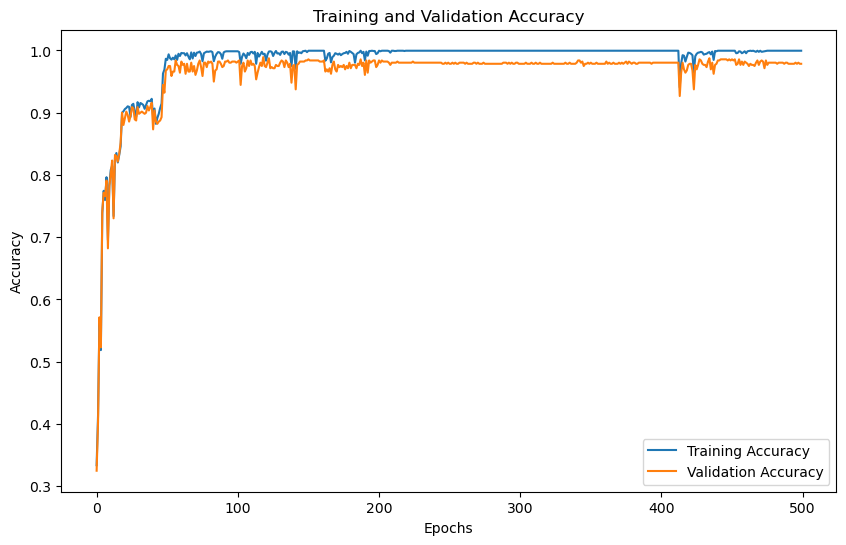

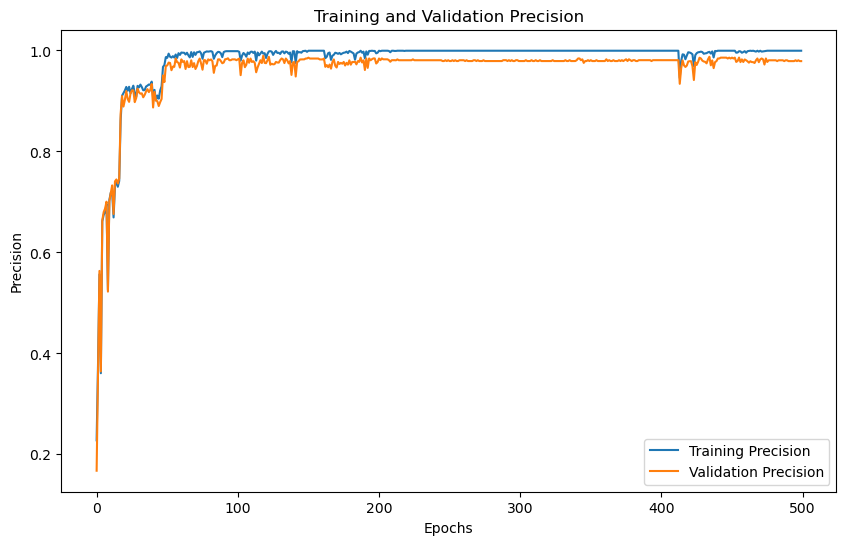

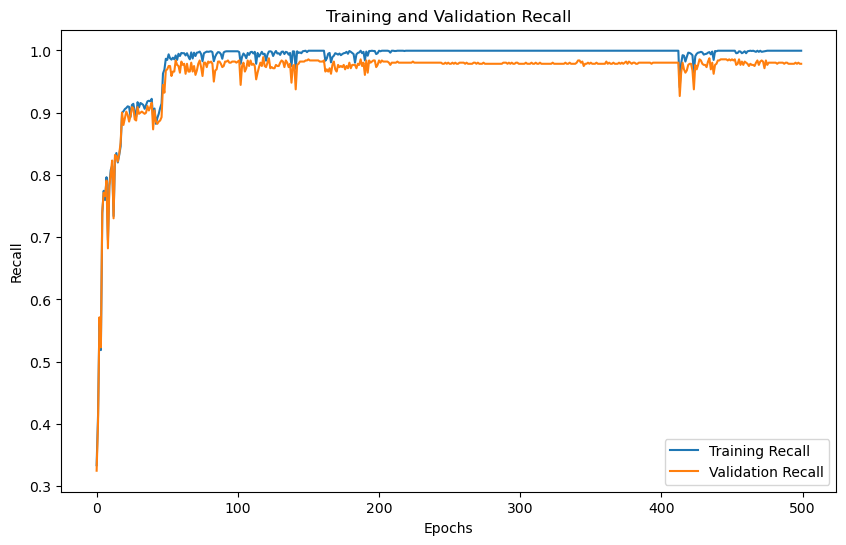

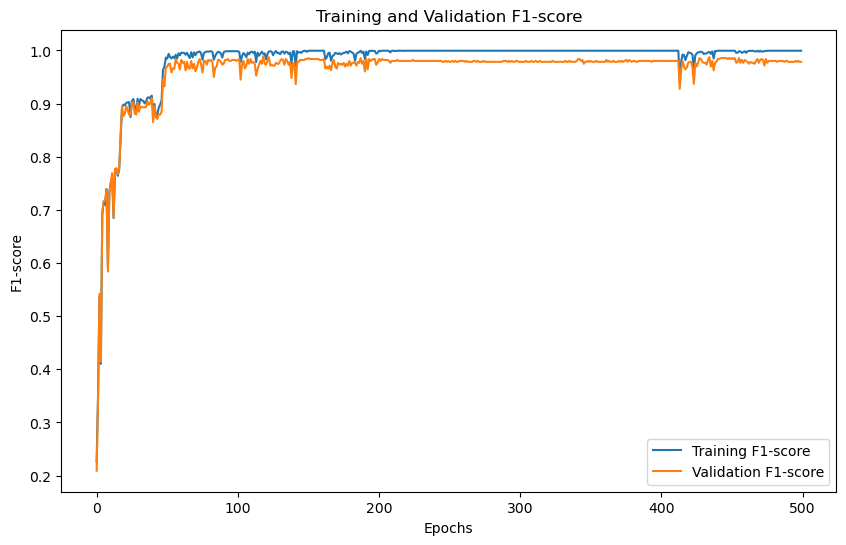

'Model Training and Evaluation Successfully completed'

In [15]:
train_model()

# CREMA
# DWT 3
# N_MFCC 32

Enter dataset name:
tess, savee, crema, ravdess
 crema
Enter dwt level:  3
Enter Number of MFCC coefficients : 32
No. of classes 6
Input size for wavelet level 3 = 128
Training with DWT level: 3
Hidden Size : 256
Model Name: CNN_LSTM_Model

X Shape : (7442, 128)
Y Shape : (7442, 6)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.8108, Training Accuracy: 0.1740, Training Precision:0.0303,Training Recall:0.1740,Training F1-Score:0.0516
Validation Loss: 1.8855, Validation Accuracy: 0.1585, Validation Precision:0.2009,Validation Recall:0.1585,Validation F1-Score:0.0444
Epoch [2/500],
Training Loss: 1.8493, Training Accuracy: 0.1698, Training Precision:0.0288,Training Recall:0.1698,Training F1-Score:0.0493
Validation Loss: 1.8374, Validation Accuracy: 0.1753, Validation Precision:0.2065,Validation Recall:0.1753,Validation F1-Score:0.0533
Epoch [3/500],
Training Loss: 1.8186, Training Accuracy: 0.1740, Training Precision:0.0303,Training Recall:0.1740,Training F1-Score:0.0516
Validat

Epoch [30/500],
Training Loss: 1.6997, Training Accuracy: 0.3822, Training Precision:0.3154,Training Recall:0.3822,Training F1-Score:0.3103
Validation Loss: 1.6486, Validation Accuracy: 0.3828, Validation Precision:0.3345,Validation Recall:0.3828,Validation F1-Score:0.3140
Epoch [31/500],
Training Loss: 1.6448, Training Accuracy: 0.3958, Training Precision:0.3228,Training Recall:0.3958,Training F1-Score:0.3354
Validation Loss: 1.6257, Validation Accuracy: 0.4070, Validation Precision:0.3425,Validation Recall:0.4070,Validation F1-Score:0.3505
Epoch [32/500],
Training Loss: 1.6377, Training Accuracy: 0.4001, Training Precision:0.3195,Training Recall:0.4001,Training F1-Score:0.3458
Validation Loss: 1.6282, Validation Accuracy: 0.3989, Validation Precision:0.3256,Validation Recall:0.3989,Validation F1-Score:0.3495
Epoch [33/500],
Training Loss: 1.6320, Training Accuracy: 0.3953, Training Precision:0.3137,Training Recall:0.3953,Training F1-Score:0.3301
Validation Loss: 1.6268, Validation Ac

Epoch [60/500],
Training Loss: 1.6211, Training Accuracy: 0.4321, Training Precision:0.4241,Training Recall:0.4321,Training F1-Score:0.3758
Validation Loss: 1.6090, Validation Accuracy: 0.4191, Validation Precision:0.3585,Validation Recall:0.4191,Validation F1-Score:0.3649
Epoch [61/500],
Training Loss: 1.6146, Training Accuracy: 0.4247, Training Precision:0.4055,Training Recall:0.4247,Training F1-Score:0.3655
Validation Loss: 1.6108, Validation Accuracy: 0.4177, Validation Precision:0.4086,Validation Recall:0.4177,Validation F1-Score:0.3629
Epoch [62/500],
Training Loss: 1.6154, Training Accuracy: 0.4280, Training Precision:0.4021,Training Recall:0.4280,Training F1-Score:0.3798
Validation Loss: 1.6056, Validation Accuracy: 0.4184, Validation Precision:0.4021,Validation Recall:0.4184,Validation F1-Score:0.3757
Epoch [63/500],
Training Loss: 1.6100, Training Accuracy: 0.4314, Training Precision:0.4316,Training Recall:0.4314,Training F1-Score:0.3816
Validation Loss: 1.6093, Validation Ac

Epoch [90/500],
Training Loss: 1.5308, Training Accuracy: 0.5194, Training Precision:0.5346,Training Recall:0.5194,Training F1-Score:0.5113
Validation Loss: 1.5692, Validation Accuracy: 0.4647, Validation Precision:0.4699,Validation Recall:0.4647,Validation F1-Score:0.4547
Epoch [91/500],
Training Loss: 1.5563, Training Accuracy: 0.4845, Training Precision:0.4876,Training Recall:0.4845,Training F1-Score:0.4726
Validation Loss: 1.5957, Validation Accuracy: 0.4312, Validation Precision:0.4272,Validation Recall:0.4312,Validation F1-Score:0.4170
Epoch [92/500],
Training Loss: 1.5248, Training Accuracy: 0.5169, Training Precision:0.5229,Training Recall:0.5169,Training F1-Score:0.5074
Validation Loss: 1.5751, Validation Accuracy: 0.4600, Validation Precision:0.4600,Validation Recall:0.4600,Validation F1-Score:0.4485
Epoch [93/500],
Training Loss: 1.5160, Training Accuracy: 0.5414, Training Precision:0.5431,Training Recall:0.5414,Training F1-Score:0.5388
Validation Loss: 1.5745, Validation Ac

Epoch [120/500],
Training Loss: 1.4437, Training Accuracy: 0.6361, Training Precision:0.6374,Training Recall:0.6361,Training F1-Score:0.6315
Validation Loss: 1.5651, Validation Accuracy: 0.4741, Validation Precision:0.4725,Validation Recall:0.4741,Validation F1-Score:0.4688
Epoch [121/500],
Training Loss: 1.4043, Training Accuracy: 0.6314, Training Precision:0.6362,Training Recall:0.6314,Training F1-Score:0.6262
Validation Loss: 1.5721, Validation Accuracy: 0.4600, Validation Precision:0.4692,Validation Recall:0.4600,Validation F1-Score:0.4547
Epoch [122/500],
Training Loss: 1.5176, Training Accuracy: 0.6005, Training Precision:0.6158,Training Recall:0.6005,Training F1-Score:0.5894
Validation Loss: 1.5638, Validation Accuracy: 0.4701, Validation Precision:0.4600,Validation Recall:0.4701,Validation F1-Score:0.4502
Epoch [123/500],
Training Loss: 1.4229, Training Accuracy: 0.6588, Training Precision:0.6674,Training Recall:0.6588,Training F1-Score:0.6537
Validation Loss: 1.5595, Validatio

...

Epoch [360/500],
Training Loss: 1.1843, Training Accuracy: 0.8602, Training Precision:0.8613,Training Recall:0.8602,Training F1-Score:0.8600
Validation Loss: 1.5885, Validation Accuracy: 0.4459, Validation Precision:0.4408,Validation Recall:0.4459,Validation F1-Score:0.4423
Epoch [361/500],
Training Loss: 1.1856, Training Accuracy: 0.8582, Training Precision:0.8594,Training Recall:0.8582,Training F1-Score:0.8580
Validation Loss: 1.5946, Validation Accuracy: 0.4412, Validation Precision:0.4354,Validation Recall:0.4412,Validation F1-Score:0.4361
Epoch [362/500],
Training Loss: 1.1851, Training Accuracy: 0.8609, Training Precision:0.8612,Training Recall:0.8609,Training F1-Score:0.8606
Validation Loss: 1.5859, Validation Accuracy: 0.4520, Validation Precision:0.4472,Validation Recall:0.4520,Validation F1-Score:0.4486
Epoch [363/500],
Training Loss: 1.1839, Training Accuracy: 0.8606, Training Precision:0.8622,Training Recall:0.8606,Training F1-Score:0.8604
Validation Loss: 1.5789, Validatio

Epoch [390/500],
Training Loss: 1.1824, Training Accuracy: 0.8624, Training Precision:0.8638,Training Recall:0.8624,Training F1-Score:0.8622
Validation Loss: 1.6014, Validation Accuracy: 0.4332, Validation Precision:0.4287,Validation Recall:0.4332,Validation F1-Score:0.4296
Epoch [391/500],
Training Loss: 1.1804, Training Accuracy: 0.8636, Training Precision:0.8638,Training Recall:0.8636,Training F1-Score:0.8633
Validation Loss: 1.6013, Validation Accuracy: 0.4338, Validation Precision:0.4302,Validation Recall:0.4338,Validation F1-Score:0.4309
Epoch [392/500],
Training Loss: 1.1804, Training Accuracy: 0.8631, Training Precision:0.8649,Training Recall:0.8631,Training F1-Score:0.8629
Validation Loss: 1.6010, Validation Accuracy: 0.4365, Validation Precision:0.4318,Validation Recall:0.4365,Validation F1-Score:0.4307
Epoch [393/500],
Training Loss: 1.1793, Training Accuracy: 0.8651, Training Precision:0.8663,Training Recall:0.8651,Training F1-Score:0.8649
Validation Loss: 1.6023, Validatio

Epoch [420/500],
Training Loss: 1.1993, Training Accuracy: 0.8601, Training Precision:0.8612,Training Recall:0.8601,Training F1-Score:0.8600
Validation Loss: 1.5987, Validation Accuracy: 0.4379, Validation Precision:0.4380,Validation Recall:0.4379,Validation F1-Score:0.4362
Epoch [421/500],
Training Loss: 1.1818, Training Accuracy: 0.8656, Training Precision:0.8671,Training Recall:0.8656,Training F1-Score:0.8655
Validation Loss: 1.5881, Validation Accuracy: 0.4466, Validation Precision:0.4435,Validation Recall:0.4466,Validation F1-Score:0.4443
Epoch [422/500],
Training Loss: 1.1848, Training Accuracy: 0.8666, Training Precision:0.8671,Training Recall:0.8666,Training F1-Score:0.8664
Validation Loss: 1.5883, Validation Accuracy: 0.4500, Validation Precision:0.4464,Validation Recall:0.4500,Validation F1-Score:0.4474
Epoch [423/500],
Training Loss: 1.1762, Training Accuracy: 0.8705, Training Precision:0.8714,Training Recall:0.8705,Training F1-Score:0.8703
Validation Loss: 1.5980, Validatio

Epoch [450/500],
Training Loss: 1.1689, Training Accuracy: 0.8765, Training Precision:0.8774,Training Recall:0.8765,Training F1-Score:0.8764
Validation Loss: 1.6054, Validation Accuracy: 0.4271, Validation Precision:0.4276,Validation Recall:0.4271,Validation F1-Score:0.4271
Epoch [451/500],
Training Loss: 1.1744, Training Accuracy: 0.8764, Training Precision:0.8771,Training Recall:0.8764,Training F1-Score:0.8762
Validation Loss: 1.6058, Validation Accuracy: 0.4298, Validation Precision:0.4238,Validation Recall:0.4298,Validation F1-Score:0.4254
Epoch [452/500],
Training Loss: 1.1667, Training Accuracy: 0.8775, Training Precision:0.8780,Training Recall:0.8775,Training F1-Score:0.8773
Validation Loss: 1.6031, Validation Accuracy: 0.4359, Validation Precision:0.4318,Validation Recall:0.4359,Validation F1-Score:0.4327
Epoch [453/500],
Training Loss: 1.1656, Training Accuracy: 0.8780, Training Precision:0.8788,Training Recall:0.8780,Training F1-Score:0.8779
Validation Loss: 1.5966, Validatio

Epoch [480/500],
Training Loss: 1.1800, Training Accuracy: 0.8675, Training Precision:0.8689,Training Recall:0.8675,Training F1-Score:0.8674
Validation Loss: 1.5964, Validation Accuracy: 0.4406, Validation Precision:0.4384,Validation Recall:0.4406,Validation F1-Score:0.4378
Epoch [481/500],
Training Loss: 1.1755, Training Accuracy: 0.8723, Training Precision:0.8733,Training Recall:0.8723,Training F1-Score:0.8721
Validation Loss: 1.6152, Validation Accuracy: 0.4150, Validation Precision:0.4137,Validation Recall:0.4150,Validation F1-Score:0.4132
Epoch [482/500],
Training Loss: 1.1720, Training Accuracy: 0.8742, Training Precision:0.8751,Training Recall:0.8742,Training F1-Score:0.8739
Validation Loss: 1.6085, Validation Accuracy: 0.4238, Validation Precision:0.4177,Validation Recall:0.4238,Validation F1-Score:0.4196
Epoch [483/500],
Training Loss: 1.1697, Training Accuracy: 0.8759, Training Precision:0.8767,Training Recall:0.8759,Training F1-Score:0.8756
Validation Loss: 1.5961, Validatio

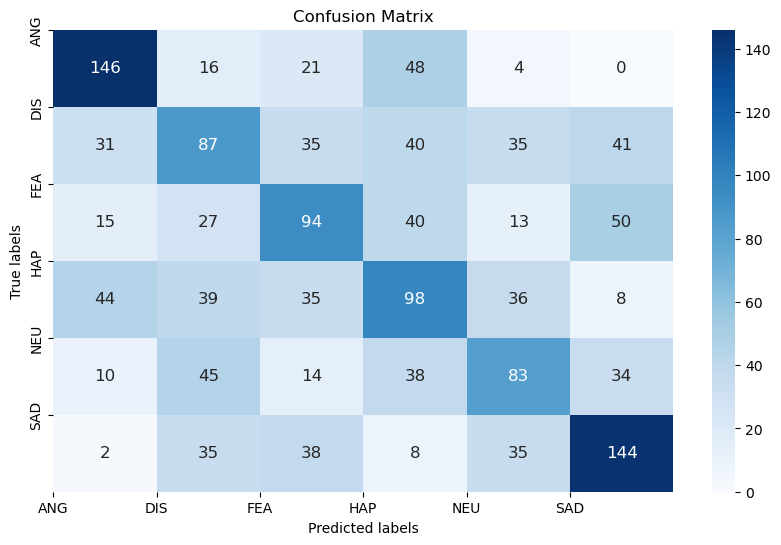

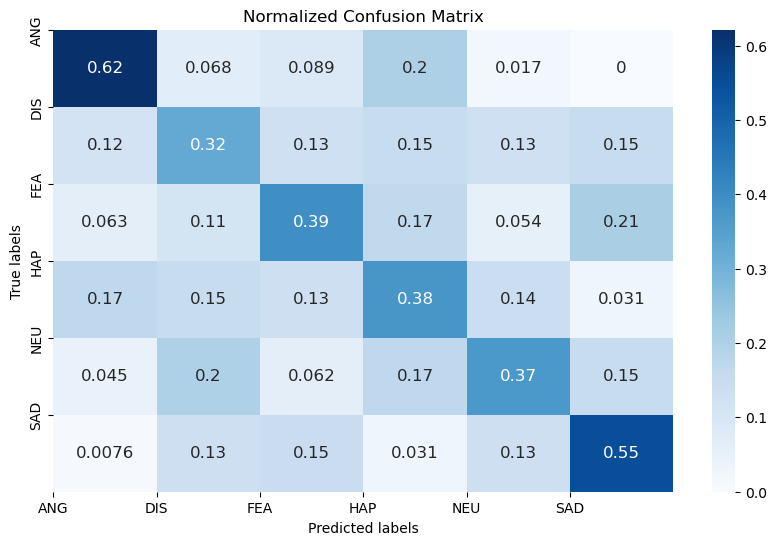

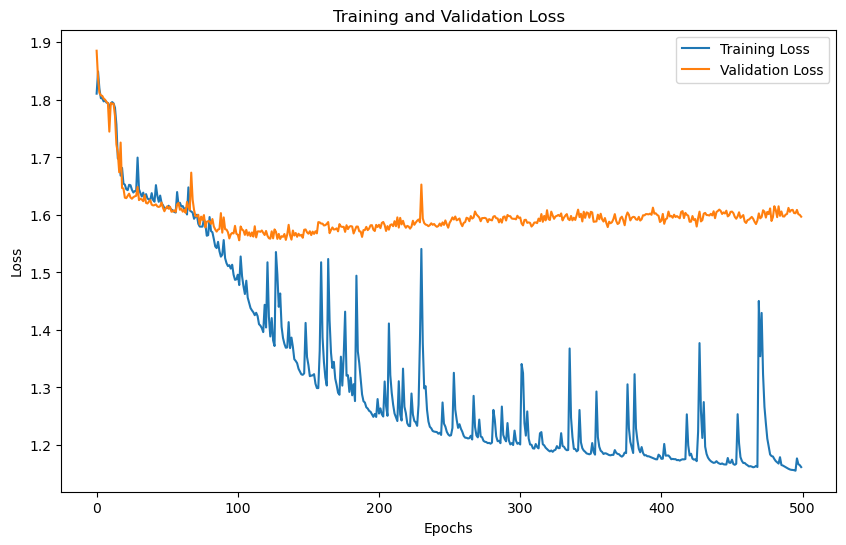

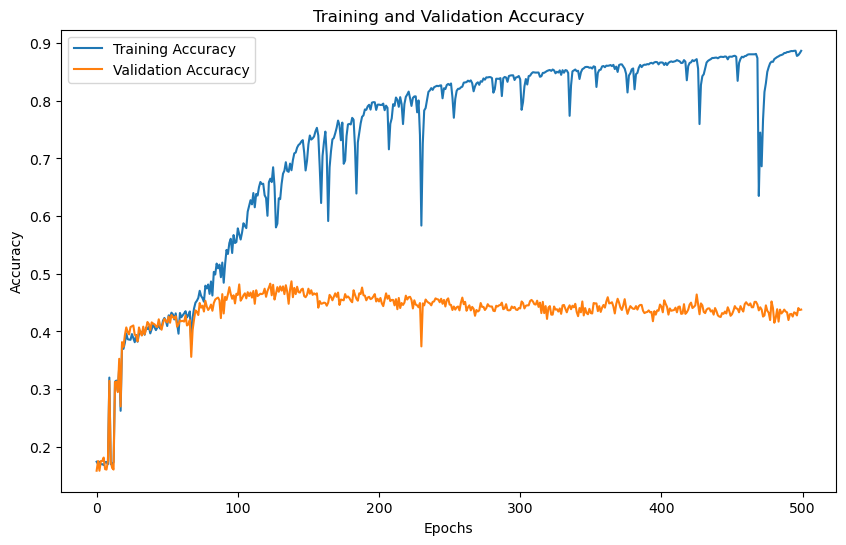

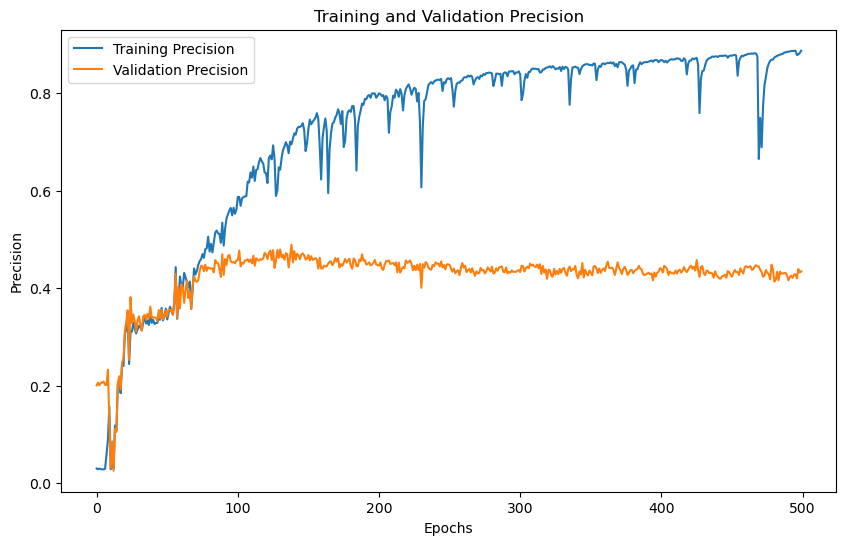

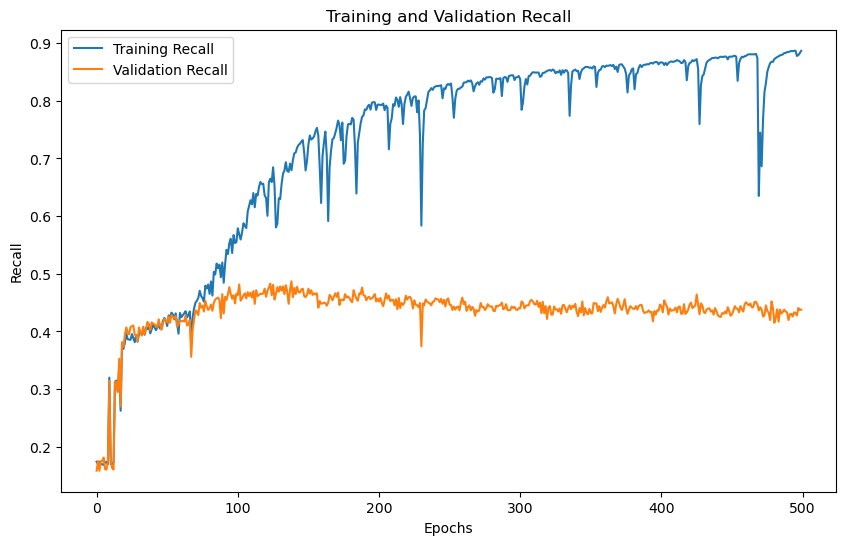

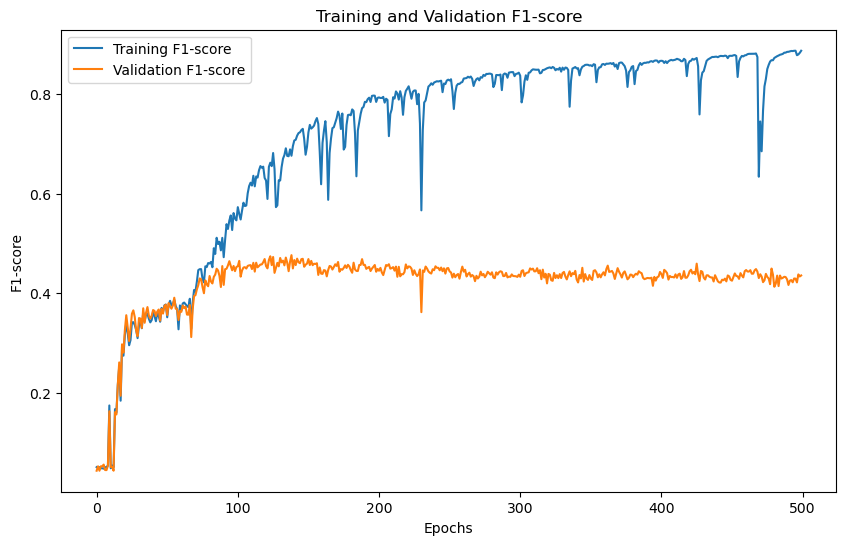

'Model Training and Evaluation Successfully completed'

In [12]:
train_model()

# restart kernel and run

In [2]:
import pandas as pd
import numpy as np
import os
import seaborn as sns
import matplotlib.pyplot as plt
import librosa
import librosa.display
from IPython.display import Audio
import csv
import warnings
warnings.filterwarnings('ignore')
import pywt
import librosa
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import train_test_split


In [3]:
# Define the LSTM model in PyTorch
class LSTMModel(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, num_classes):
        super(LSTMModel, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        self.fc1 = nn.Linear(hidden_size, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, num_classes)
        self.relu = nn.ReLU()
        self.softmax = nn.Softmax(dim=1)

    def forward(self, x):
        batch_size = x.size(0)
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(device)
        
        out, _ = self.lstm(x, (h0, c0))
        out = self.relu(out[:, -1, :])  # Consider only the output of the last time step
        out = self.fc1(out)
        out = self.relu(out)
        out = self.fc2(out)
        out = self.relu(out)
        out = self.fc3(out)
        out = self.softmax(out)
        return out


In [4]:
# Define your custom dataset
class SpeechDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


In [5]:
# Function to calculate evaluation metrics
def calculate_metrics(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    
    # Convert from one-hot encoding to class labels if needed
    if len(y_true.shape) > 1:
        y_true = np.argmax(y_true, axis=1)
    if len(y_pred.shape) > 1:
        y_pred = np.argmax(y_pred, axis=1)
    
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='weighted')
    recall = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')
    return accuracy, precision, recall, f1


# Validation function
def validate(model, val_loader, criterion, device):
    model.eval()
    val_loss = 0.0
    y_true = []
    y_pred = []
    
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs = inputs.to(device)
            labels = torch.argmax(labels, axis=1).to(device)  # Convert one-hot to class labels
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs, 1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())

    val_loss /= len(val_loader.dataset)
    accuracy, precision, recall, f1 = calculate_metrics(y_true, y_pred)
    
    return val_loss, accuracy, precision, recall, f1


In [6]:
def plot_graphs(epochs_path,
                num_epochs,
                train_losses,
                val_losses,
                train_accuracies,
                val_accuracies,
                train_precisions,
                val_precisions,
                train_recalls,
                val_recalls,
                train_f1s,
                val_f1s):
    
    
    # Plotting the metrics
    epochs = list(range(num_epochs))

    plt.figure(figsize=(10, 6))
    
    plt.plot(epochs, train_losses, label='Training Loss')
    plt.plot(epochs, val_losses, label='Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.title('Training and Validation Loss')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'loss_plot.png'))
    plt.show()
    plt.close()

    plt.figure(figsize=(10, 6))
    
    plt.plot(epochs, train_accuracies, label='Training Accuracy')
    plt.plot(epochs, val_accuracies, label='Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'accuracy_plot.png'))
    plt.show()
    plt.close()


    plt.figure(figsize=(10, 6))

    plt.plot(epochs, train_precisions, label='Training Precision')
    plt.plot(epochs, val_precisions, label='Validation Precision')
    plt.xlabel('Epochs')
    plt.ylabel('Precision')
    plt.title('Training and Validation Precision')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'precision_plot.png'))
    plt.show()
    plt.close()
    
    plt.figure(figsize=(10, 6))

    plt.plot(epochs, train_recalls, label='Training Recall')
    plt.plot(epochs, val_recalls, label='Validation Recall')
    plt.xlabel('Epochs')
    plt.ylabel('Recall')
    plt.title('Training and Validation Recall')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'recall_plot.png'))
    plt.show()
    plt.close()

    plt.figure(figsize=(10, 6))
    
    plt.plot(epochs, train_f1s, label='Training F1-score')
    plt.plot(epochs, val_f1s, label='Validation F1-score')
    plt.xlabel('Epochs')
    plt.ylabel('F1-score')
    plt.title('Training and Validation F1-score')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'f1Score_plot.png'))
    plt.show()
    plt.close()

    return "Model Training and Evaluation Successfully completed"

In [7]:
def generate_confusion_matrix(model, test_loader, device):
    model.eval()
    y_true = []
    y_pred = []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            labels = torch.argmax(labels, axis=1).to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())
            
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='weighted')
    recall = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')        
    print(f"\nAccuracy : {accuracy}\nPrecision : {precision}\nRecall : {recall}\nF1-Score : {f1}")

    conf_matrix = confusion_matrix(y_true, y_pred)
    return conf_matrix, y_true, y_pred

def plot_confusion_matrices(conf_matrix, normalized_conf_matrix, class_labels, epochs_path):
    plt.figure(figsize=(10, 6))
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', annot_kws={"fontsize": 12})  
    plt.xlabel('Predicted labels')
    plt.ylabel('True labels')
    plt.title('Confusion Matrix')
    plt.xticks(ticks=np.arange(len(class_labels)), labels=class_labels)
    plt.yticks(ticks=np.arange(len(class_labels)), labels=class_labels)
    plt.savefig(os.path.join(epochs_path, 'Confusion Matrix.png'))
    plt.show()
    
    plt.figure(figsize=(10, 6))
    sns.heatmap(normalized_conf_matrix, annot=True, cmap='Blues', annot_kws={"fontsize": 12})
    plt.xlabel('Predicted labels')
    plt.ylabel('True labels')
    plt.title('Normalized Confusion Matrix')
    plt.xticks(ticks=np.arange(len(class_labels)), labels=class_labels)
    plt.yticks(ticks=np.arange(len(class_labels)), labels=class_labels)
    plt.savefig(os.path.join(epochs_path, 'Normalized Confusion Matrix.png'))
    plt.show()


In [8]:
def train_model():
    
    global dwt_level,model,mfcc
    
    dataset=input("Enter dataset name:\ntess, savee, crema, ravdess\n ")
    dwt_level = int(input("Enter dwt level:  "))
    mfcc=int(input("Enter Number of MFCC coefficients : "))
    if dataset=="tess":
        csv_file=r"C:\Users\Tharunraj_S\Desktop\Major project\Dataset\tess_dataset.csv"
    
    elif dataset=="savee":
        csv_file=r"C:\Users\Tharunraj_S\Desktop\Major project\Dataset\savee_dataset.csv"
    
    elif dataset=="crema":
        csv_file=r"C:\Users\Tharunraj_S\Desktop\Major project\Dataset\crema_dataset.csv"
    
    elif dataset=="ravdess":
        csv_file=r"C:\Users\Tharunraj_S\Desktop\Major project\Dataset\ravdess_dataset.csv"
    
    
    df = pd.read_csv(csv_file)
    X_mfcc = df['File_Path'].apply(lambda x: extract_features(x,dwt_level))
    
    X = [x for x in X_mfcc]
    X = np.array(X)
    X = np.expand_dims(X, -1)
    
    class_labels = df['Emotion_Label'].unique().tolist()
    
    from sklearn.preprocessing import OneHotEncoder
    enc = OneHotEncoder()
    y = enc.fit_transform(df[['Emotion_Label']])
    y = y.toarray()
    
    train_loader, val_loader = Loader(X, y) 
      
    # Determine input size based on wavelet level
    input_size = 1
    hidden_size = 256
    num_layers = 1

        
    print(f"Input size for wavelet level {dwt_level} = {input_size}")
    # Initialize model

    model = LSTMModel(input_size, hidden_size, num_layers, num_classes)
    
    model_path=model.__class__.__name__
    if not os.path.exists( model_path):
        os.makedirs( model_path)
        
    # Loss and optimizer
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # Reset model parameters
    model.apply(reset_parameters)
    
    # Reset optimizer state
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # Initialize variables to store best validation metrics and corresponding model state
    best_val_loss = float('inf')
    best_model_state = None
    
    # Training loop
    
    train_losses = []
    val_losses = []
    train_accuracies = []
    val_accuracies = []
    train_precisions = []
    val_precisions = []
    train_recalls = []
    val_recalls = []
    train_f1s = []
    val_f1s = []
    
    print("Training with DWT level:", dwt_level)
    print(
          f'Hidden Size : {hidden_size}\n' 
          f'Model Name: {model.__class__.__name__}\n' 
          f'\nX Shape : {X.shape}'
          f'\nY Shape : {y.shape}\n')
    num_epochs =int(input("Enter no. of epochs "))
    dataset_path = dataset
    dataset_dir = os.path.join(model_path,dataset_path)
    if not os.path.exists(dataset_dir):
        os.makedirs(dataset_dir)
        
    mfcc_path="N_MFCC"+str(mfcc)
    mfcc_dir=os.path.join(dataset_dir,mfcc_path)
    
    dwt_level_path = "level "+str(dwt_level)+" wavelet"
    dwt_level_dir = os.path.join(mfcc_dir,dwt_level_path)
    if not os.path.exists(dwt_level_dir):
        os.makedirs(dwt_level_dir)
    
    # Create a directory with the name as the number of epochs
    epochs_dir = str(num_epochs)+" Epochs"
    epochs_path = os.path.join(dwt_level_dir,epochs_dir)
    if not os.path.exists(epochs_path):
        os.makedirs(epochs_path)
        
    with open(os.path.join(epochs_path,'metrics.csv'), mode='w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(['Epoch', 'Training Loss', 'Training Accuracy','Training Precision', 'Training Recall', 'Training F1-Score'
                         , 'Validation Loss', 'Validation Accuracy','Validation Precision', 'Validation Recall', 'Validation F1-Score'])

        for epoch in range(num_epochs):
            model.train()
            running_loss = 0.0

            for inputs, labels in train_loader:
                inputs = inputs.to(device)
                labels = labels.to(device)
                optimizer.zero_grad()
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                loss.backward()
                optimizer.step()
                running_loss += loss.item() * inputs.size(0)

            # Calculate training loss
            train_loss = running_loss / len(train_loader.dataset)
            train_losses.append(train_loss)

            # Calculate training metrics
            y_true_train = []
            y_pred_train = []
            with torch.no_grad():
                for inputs, labels in train_loader:
                    inputs = inputs.to(device)
                    labels = labels.to(device)
                    outputs = model(inputs)
                    _, predicted = torch.max(outputs, 1)
                    y_true_train.extend(labels.cpu().numpy())
                    y_pred_train.extend(predicted.cpu().numpy())

            train_accuracy, train_precision, train_recall, train_f1 = calculate_metrics(y_true_train, y_pred_train)
            train_accuracies.append(train_accuracy)
            train_precisions.append(train_precision)
            train_recalls.append(train_recall)
            train_f1s.append(train_f1)

            # Validate the model
            val_loss, val_accuracy, val_precision, val_recall, val_f1 = validate(model, val_loader, criterion, device)
            val_losses.append(val_loss)
            val_accuracies.append(val_accuracy)
            val_precisions.append(val_precision)
            val_recalls.append(val_recall)
            val_f1s.append(val_f1)

            # Write metrics to CSV
            writer.writerow([epoch+1, train_loss, train_accuracy, train_precision, train_recall, train_f1,
                             val_loss, val_accuracy, val_precision, val_recall, val_f1])


            print(f'Epoch [{epoch+1}/{num_epochs}],\n'
                  f'Training Loss: {train_loss:.4f}, Training Accuracy: {train_accuracy:.4f}, '
                  f'Training Precision:{train_precision:.4f},Training Recall:{train_recall:.4f},Training F1-Score:{train_f1:.4f}\n'
                  f'Validation Loss: {val_loss:.4f}, Validation Accuracy: {val_accuracy:.4f}, '
                  f'Validation Precision:{val_precision:.4f},Validation Recall:{val_recall:.4f},Validation F1-Score:{val_f1:.4f}'
                  )
            # Save the model
            torch.save(model.state_dict(), os.path.join(epochs_path, 'LSTM_model_(last).pth'))

            # Save the model if it has the best validation loss so far
            if val_loss < best_val_loss:
                best_val_loss = val_loss
                best_model_state = model.state_dict()
                torch.save(model.state_dict(), os.path.join(epochs_path, 'LSTM_model_(best).pth'))

    # Load the best model state
    model.load_state_dict(best_model_state)
    conf_matrix, _, _ = generate_confusion_matrix(model, val_loader, device)
    normalized_conf_matrix = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]
    plot_confusion_matrices(conf_matrix, normalized_conf_matrix, class_labels, epochs_path)
     
    return plot_graphs(epochs_path,num_epochs,train_losses,val_losses,train_accuracies,val_accuracies,train_precisions,val_precisions,train_recalls,val_recalls,train_f1s,val_f1s)


def reset_parameters(layer):
    if isinstance(layer, nn.Conv1d) or isinstance(layer, nn.Linear):
        nn.init.xavier_uniform_(layer.weight)
        nn.init.zeros_(layer.bias)

In [9]:
def Loader(X,y):
    
    global num_classes

    
    num_classes = y.shape[1]
    print(f"No. of classes {num_classes}")
    
    # Train-test split
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Convert to PyTorch tensors
    X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
    X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
    y_train_tensor = torch.tensor(y_train, dtype=torch.float32)
    y_test_tensor = torch.tensor(y_test, dtype=torch.float32)

    train_dataset = SpeechDataset(X_train_tensor, y_train_tensor)
    val_dataset = SpeechDataset(X_test_tensor, y_test_tensor)


    train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
    val_loader= DataLoader(val_dataset, batch_size=64, shuffle=True)

    return train_loader, val_loader

In [10]:
def extract_features(filename,dwt_level):
    
    y, sr = librosa.load(filename, duration=3, offset=0.5)
    coeffs = pywt.wavedec(y, 'db1', level=dwt_level) # Adjust wavelet and decomposition level as needed
    mfcc_features = []
    for coeff in coeffs:
        mfcc_coeff = np.mean(librosa.feature.mfcc(y=coeff.astype(float), sr=sr, n_mfcc=mfcc).T, axis=0)
        mfcc_features.extend(mfcc_coeff)
    return np.array(mfcc_features)


In [11]:
# Define device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


# SAVEE

# dwt 1
# n_mfcc 16

# 500 epochs

Enter dataset name:
tess, savee, crema, ravdess
 savee
Enter dwt level:  1
Enter Number of MFCC coefficients : 16
No. of classes 6
Input size for wavelet level 1 = 1
Training with DWT level: 1
Hidden Size : 256
Model Name: LSTMModel

X Shape : (480, 32, 1)
Y Shape : (480, 6)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.7807, Training Accuracy: 0.3229, Training Precision:0.4438,Training Recall:0.3229,Training F1-Score:0.2172
Validation Loss: 1.7561, Validation Accuracy: 0.4167, Validation Precision:0.2594,Validation Recall:0.4167,Validation F1-Score:0.2932
Epoch [2/500],
Training Loss: 1.7415, Training Accuracy: 0.3542, Training Precision:0.4789,Training Recall:0.3542,Training F1-Score:0.2584
Validation Loss: 1.6903, Validation Accuracy: 0.4375, Validation Precision:0.5385,Validation Recall:0.4375,Validation F1-Score:0.3290
Epoch [3/500],
Training Loss: 1.6928, Training Accuracy: 0.3516, Training Precision:0.4754,Training Recall:0.3516,Training F1-Score:0.2492
Validation Los

Epoch [30/500],
Training Loss: 1.5048, Training Accuracy: 0.5573, Training Precision:0.4986,Training Recall:0.5573,Training F1-Score:0.5057
Validation Loss: 1.5381, Validation Accuracy: 0.4792, Validation Precision:0.4070,Validation Recall:0.4792,Validation F1-Score:0.4151
Epoch [31/500],
Training Loss: 1.4943, Training Accuracy: 0.5182, Training Precision:0.5197,Training Recall:0.5182,Training F1-Score:0.4918
Validation Loss: 1.6133, Validation Accuracy: 0.4167, Validation Precision:0.4947,Validation Recall:0.4167,Validation F1-Score:0.4194
Epoch [32/500],
Training Loss: 1.5088, Training Accuracy: 0.5625, Training Precision:0.5057,Training Recall:0.5625,Training F1-Score:0.5141
Validation Loss: 1.5531, Validation Accuracy: 0.4792, Validation Precision:0.4640,Validation Recall:0.4792,Validation F1-Score:0.4354
Epoch [33/500],
Training Loss: 1.4834, Training Accuracy: 0.5651, Training Precision:0.5279,Training Recall:0.5651,Training F1-Score:0.5225
Validation Loss: 1.5787, Validation Ac

Epoch [60/500],
Training Loss: 1.3684, Training Accuracy: 0.6797, Training Precision:0.6137,Training Recall:0.6797,Training F1-Score:0.6235
Validation Loss: 1.5423, Validation Accuracy: 0.4792, Validation Precision:0.4696,Validation Recall:0.4792,Validation F1-Score:0.4448
Epoch [61/500],
Training Loss: 1.3718, Training Accuracy: 0.6849, Training Precision:0.6217,Training Recall:0.6849,Training F1-Score:0.6331
Validation Loss: 1.5346, Validation Accuracy: 0.5104, Validation Precision:0.5251,Validation Recall:0.5104,Validation F1-Score:0.4857
Epoch [62/500],
Training Loss: 1.3783, Training Accuracy: 0.7083, Training Precision:0.6376,Training Recall:0.7083,Training F1-Score:0.6523
Validation Loss: 1.5217, Validation Accuracy: 0.5000, Validation Precision:0.5282,Validation Recall:0.5000,Validation F1-Score:0.4665
Epoch [63/500],
Training Loss: 1.3595, Training Accuracy: 0.6875, Training Precision:0.6230,Training Recall:0.6875,Training F1-Score:0.6316
Validation Loss: 1.5036, Validation Ac

Epoch [90/500],
Training Loss: 1.2689, Training Accuracy: 0.7969, Training Precision:0.8109,Training Recall:0.7969,Training F1-Score:0.7879
Validation Loss: 1.4824, Validation Accuracy: 0.5625, Validation Precision:0.6132,Validation Recall:0.5625,Validation F1-Score:0.5612
Epoch [91/500],
Training Loss: 1.2608, Training Accuracy: 0.7891, Training Precision:0.8057,Training Recall:0.7891,Training F1-Score:0.7775
Validation Loss: 1.4435, Validation Accuracy: 0.6042, Validation Precision:0.6416,Validation Recall:0.6042,Validation F1-Score:0.6019
Epoch [92/500],
Training Loss: 1.2532, Training Accuracy: 0.7995, Training Precision:0.8114,Training Recall:0.7995,Training F1-Score:0.7908
Validation Loss: 1.4664, Validation Accuracy: 0.5938, Validation Precision:0.6563,Validation Recall:0.5938,Validation F1-Score:0.5967
Epoch [93/500],
Training Loss: 1.2475, Training Accuracy: 0.8047, Training Precision:0.8197,Training Recall:0.8047,Training F1-Score:0.7946
Validation Loss: 1.4516, Validation Ac

Epoch [120/500],
Training Loss: 1.2222, Training Accuracy: 0.8203, Training Precision:0.8303,Training Recall:0.8203,Training F1-Score:0.8124
Validation Loss: 1.4601, Validation Accuracy: 0.5938, Validation Precision:0.6346,Validation Recall:0.5938,Validation F1-Score:0.5939
Epoch [121/500],
Training Loss: 1.2235, Training Accuracy: 0.8203, Training Precision:0.8306,Training Recall:0.8203,Training F1-Score:0.8133
Validation Loss: 1.4547, Validation Accuracy: 0.6042, Validation Precision:0.6480,Validation Recall:0.6042,Validation F1-Score:0.6045
Epoch [122/500],
Training Loss: 1.2216, Training Accuracy: 0.8203, Training Precision:0.8346,Training Recall:0.8203,Training F1-Score:0.8137
Validation Loss: 1.4522, Validation Accuracy: 0.6042, Validation Precision:0.6418,Validation Recall:0.6042,Validation F1-Score:0.6027
Epoch [123/500],
Training Loss: 1.2225, Training Accuracy: 0.8177, Training Precision:0.8267,Training Recall:0.8177,Training F1-Score:0.8092
Validation Loss: 1.4661, Validatio

...

Epoch [364/500],
Training Loss: 1.2148, Training Accuracy: 0.8333, Training Precision:0.8477,Training Recall:0.8333,Training F1-Score:0.8257
Validation Loss: 1.4903, Validation Accuracy: 0.5208, Validation Precision:0.5696,Validation Recall:0.5208,Validation F1-Score:0.5225
Epoch [365/500],
Training Loss: 1.2163, Training Accuracy: 0.8281, Training Precision:0.8294,Training Recall:0.8281,Training F1-Score:0.8201
Validation Loss: 1.4854, Validation Accuracy: 0.5625, Validation Precision:0.5861,Validation Recall:0.5625,Validation F1-Score:0.5607
Epoch [366/500],
Training Loss: 1.2206, Training Accuracy: 0.8281, Training Precision:0.8419,Training Recall:0.8281,Training F1-Score:0.8216
Validation Loss: 1.4965, Validation Accuracy: 0.5417, Validation Precision:0.6508,Validation Recall:0.5417,Validation F1-Score:0.5451
Epoch [367/500],
Training Loss: 1.2169, Training Accuracy: 0.8307, Training Precision:0.8482,Training Recall:0.8307,Training F1-Score:0.8242
Validation Loss: 1.4934, Validatio

Epoch [394/500],
Training Loss: 1.2177, Training Accuracy: 0.8359, Training Precision:0.8427,Training Recall:0.8359,Training F1-Score:0.8287
Validation Loss: 1.4517, Validation Accuracy: 0.6042, Validation Precision:0.6537,Validation Recall:0.6042,Validation F1-Score:0.6096
Epoch [395/500],
Training Loss: 1.2078, Training Accuracy: 0.8385, Training Precision:0.8487,Training Recall:0.8385,Training F1-Score:0.8322
Validation Loss: 1.4757, Validation Accuracy: 0.5625, Validation Precision:0.6007,Validation Recall:0.5625,Validation F1-Score:0.5597
Epoch [396/500],
Training Loss: 1.2047, Training Accuracy: 0.8385, Training Precision:0.8537,Training Recall:0.8385,Training F1-Score:0.8317
Validation Loss: 1.4666, Validation Accuracy: 0.5833, Validation Precision:0.6271,Validation Recall:0.5833,Validation F1-Score:0.5762
Epoch [397/500],
Training Loss: 1.2040, Training Accuracy: 0.8411, Training Precision:0.8557,Training Recall:0.8411,Training F1-Score:0.8346
Validation Loss: 1.4529, Validatio

Epoch [424/500],
Training Loss: 1.1944, Training Accuracy: 0.8464, Training Precision:0.8464,Training Recall:0.8464,Training F1-Score:0.8380
Validation Loss: 1.4613, Validation Accuracy: 0.5729, Validation Precision:0.6037,Validation Recall:0.5729,Validation F1-Score:0.5675
Epoch [425/500],
Training Loss: 1.1944, Training Accuracy: 0.8464, Training Precision:0.8469,Training Recall:0.8464,Training F1-Score:0.8378
Validation Loss: 1.4624, Validation Accuracy: 0.5833, Validation Precision:0.6152,Validation Recall:0.5833,Validation F1-Score:0.5750
Epoch [426/500],
Training Loss: 1.1943, Training Accuracy: 0.8464, Training Precision:0.8583,Training Recall:0.8464,Training F1-Score:0.8387
Validation Loss: 1.4618, Validation Accuracy: 0.5938, Validation Precision:0.6542,Validation Recall:0.5938,Validation F1-Score:0.5896
Epoch [427/500],
Training Loss: 1.1943, Training Accuracy: 0.8464, Training Precision:0.8493,Training Recall:0.8464,Training F1-Score:0.8379
Validation Loss: 1.4624, Validatio

Epoch [454/500],
Training Loss: 1.1940, Training Accuracy: 0.8464, Training Precision:0.8548,Training Recall:0.8464,Training F1-Score:0.8383
Validation Loss: 1.4703, Validation Accuracy: 0.5833, Validation Precision:0.6507,Validation Recall:0.5833,Validation F1-Score:0.5858
Epoch [455/500],
Training Loss: 1.1940, Training Accuracy: 0.8464, Training Precision:0.8505,Training Recall:0.8464,Training F1-Score:0.8387
Validation Loss: 1.4717, Validation Accuracy: 0.5729, Validation Precision:0.6246,Validation Recall:0.5729,Validation F1-Score:0.5744
Epoch [456/500],
Training Loss: 1.1940, Training Accuracy: 0.8464, Training Precision:0.8551,Training Recall:0.8464,Training F1-Score:0.8381
Validation Loss: 1.4729, Validation Accuracy: 0.5729, Validation Precision:0.6461,Validation Recall:0.5729,Validation F1-Score:0.5756
Epoch [457/500],
Training Loss: 1.1940, Training Accuracy: 0.8464, Training Precision:0.8492,Training Recall:0.8464,Training F1-Score:0.8382
Validation Loss: 1.4731, Validatio

Epoch [484/500],
Training Loss: 1.1936, Training Accuracy: 0.8464, Training Precision:0.8488,Training Recall:0.8464,Training F1-Score:0.8380
Validation Loss: 1.4788, Validation Accuracy: 0.5521, Validation Precision:0.6198,Validation Recall:0.5521,Validation F1-Score:0.5561
Epoch [485/500],
Training Loss: 1.1938, Training Accuracy: 0.8464, Training Precision:0.8500,Training Recall:0.8464,Training F1-Score:0.8387
Validation Loss: 1.4787, Validation Accuracy: 0.5521, Validation Precision:0.6198,Validation Recall:0.5521,Validation F1-Score:0.5561
Epoch [486/500],
Training Loss: 1.1937, Training Accuracy: 0.8464, Training Precision:0.8561,Training Recall:0.8464,Training F1-Score:0.8387
Validation Loss: 1.4791, Validation Accuracy: 0.5625, Validation Precision:0.6231,Validation Recall:0.5625,Validation F1-Score:0.5657
Epoch [487/500],
Training Loss: 1.1937, Training Accuracy: 0.8464, Training Precision:0.8500,Training Recall:0.8464,Training F1-Score:0.8385
Validation Loss: 1.4796, Validatio

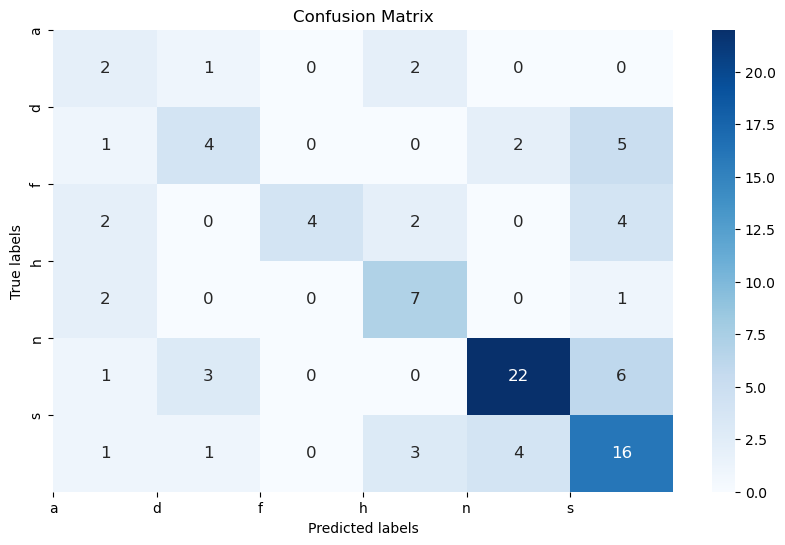

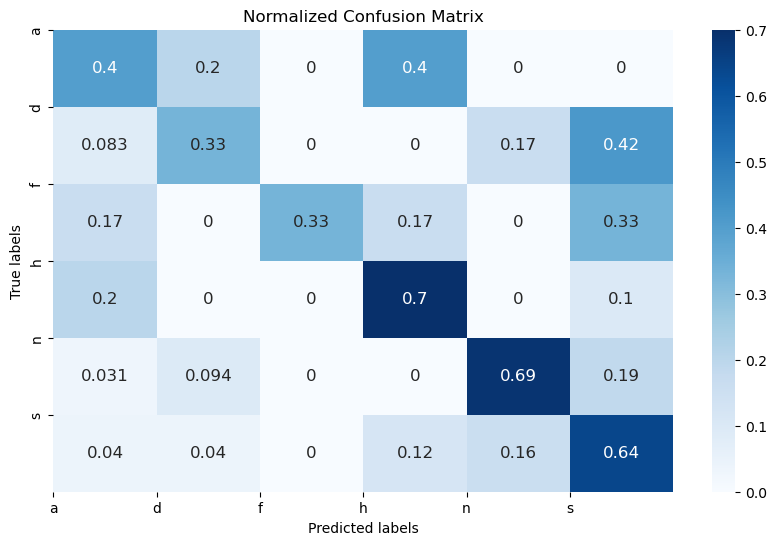

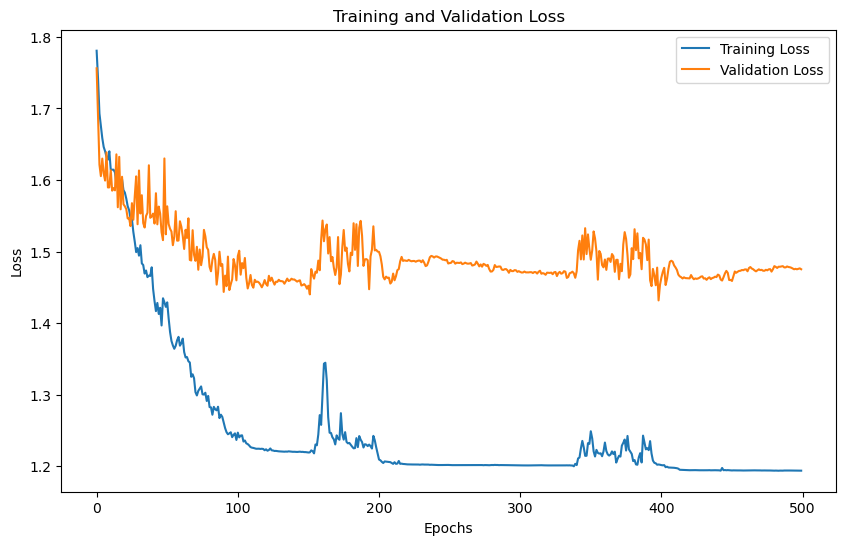

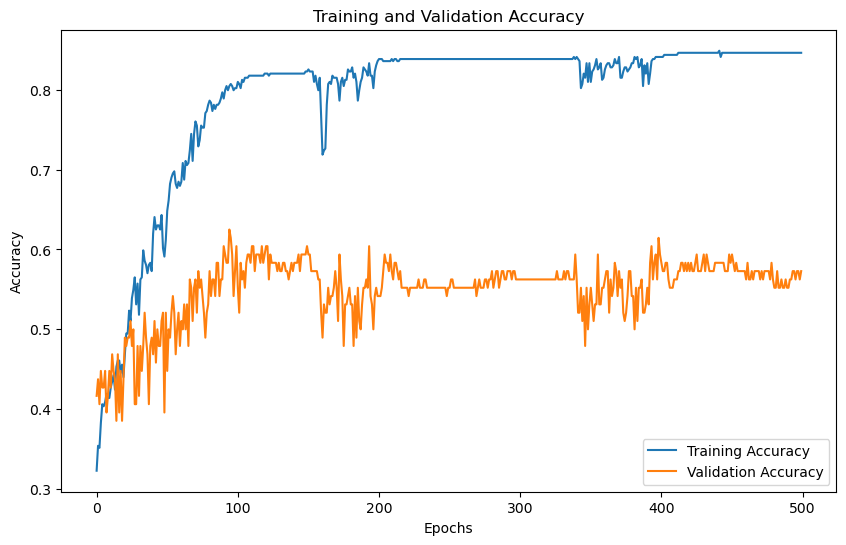

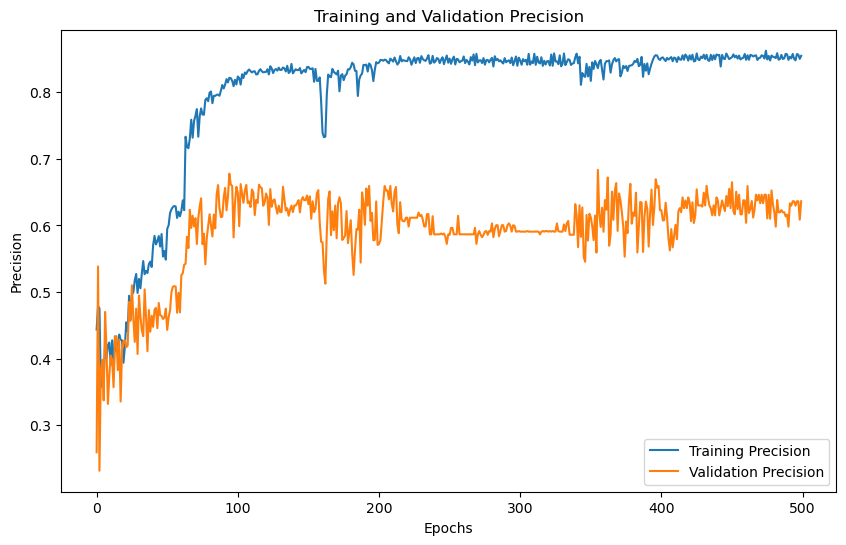

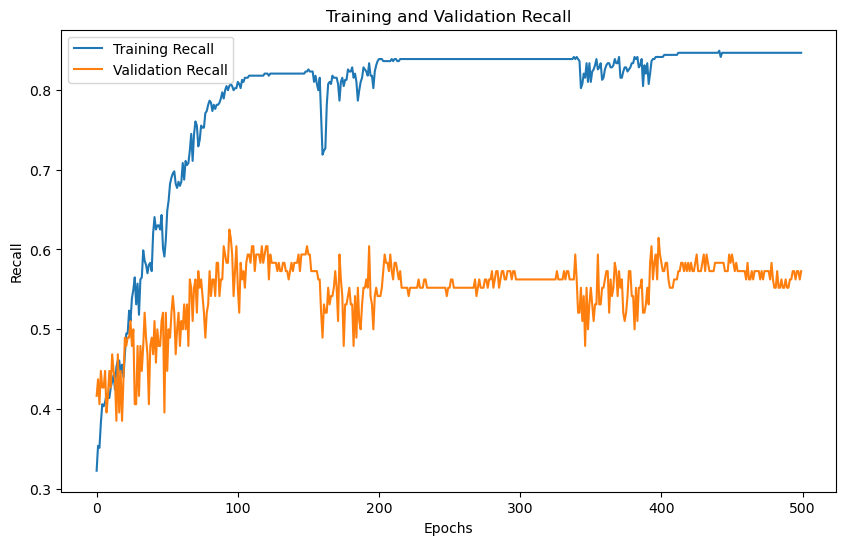

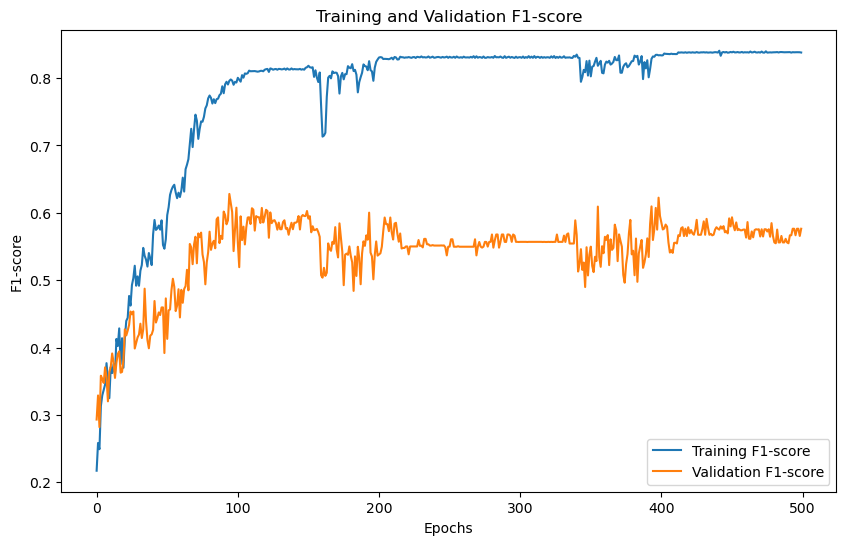

'Model Training and Evaluation Successfully completed'

In [15]:
train_model()

# Ravdess
# dwt level 3
# n_mfcc 16

# 500 epochs

Enter dataset name:
tess, savee, crema, ravdess
 ravdess
Enter dwt level:  3
Enter Number of MFCC coefficients : 16
No. of classes 8
Input size for wavelet level 3 = 1
Training with DWT level: 3
Hidden Size : 256
Model Name: LSTMModel

X Shape : (1440, 64, 1)
Y Shape : (1440, 8)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 2.0724, Training Accuracy: 0.2109, Training Precision:0.1573,Training Recall:0.2109,Training F1-Score:0.1464
Validation Loss: 2.0582, Validation Accuracy: 0.1875, Validation Precision:0.1238,Validation Recall:0.1875,Validation F1-Score:0.1312
Epoch [2/500],
Training Loss: 2.0430, Training Accuracy: 0.2231, Training Precision:0.1788,Training Recall:0.2231,Training F1-Score:0.1682
Validation Loss: 2.0481, Validation Accuracy: 0.2049, Validation Precision:0.1590,Validation Recall:0.2049,Validation F1-Score:0.1587
Epoch [3/500],
Training Loss: 2.0104, Training Accuracy: 0.2595, Training Precision:0.1965,Training Recall:0.2595,Training F1-Score:0.1993
Validation

Epoch [30/500],
Training Loss: 1.8817, Training Accuracy: 0.4080, Training Precision:0.3831,Training Recall:0.4080,Training F1-Score:0.3850
Validation Loss: 1.9281, Validation Accuracy: 0.3472, Validation Precision:0.3076,Validation Recall:0.3472,Validation F1-Score:0.3196
Epoch [31/500],
Training Loss: 1.8757, Training Accuracy: 0.4158, Training Precision:0.3928,Training Recall:0.4158,Training F1-Score:0.3864
Validation Loss: 1.9141, Validation Accuracy: 0.3542, Validation Precision:0.3185,Validation Recall:0.3542,Validation F1-Score:0.3186
Epoch [32/500],
Training Loss: 1.8768, Training Accuracy: 0.4245, Training Precision:0.4025,Training Recall:0.4245,Training F1-Score:0.3982
Validation Loss: 1.9181, Validation Accuracy: 0.3611, Validation Precision:0.3189,Validation Recall:0.3611,Validation F1-Score:0.3296
Epoch [33/500],
Training Loss: 1.8612, Training Accuracy: 0.4062, Training Precision:0.3957,Training Recall:0.4062,Training F1-Score:0.3790
Validation Loss: 1.9131, Validation Ac

Epoch [60/500],
Training Loss: 1.7175, Training Accuracy: 0.5694, Training Precision:0.5433,Training Recall:0.5694,Training F1-Score:0.5460
Validation Loss: 1.8701, Validation Accuracy: 0.4028, Validation Precision:0.3814,Validation Recall:0.4028,Validation F1-Score:0.3803
Epoch [61/500],
Training Loss: 1.7195, Training Accuracy: 0.5799, Training Precision:0.5529,Training Recall:0.5799,Training F1-Score:0.5567
Validation Loss: 1.9032, Validation Accuracy: 0.3611, Validation Precision:0.3506,Validation Recall:0.3611,Validation F1-Score:0.3415
Epoch [62/500],
Training Loss: 1.7069, Training Accuracy: 0.5833, Training Precision:0.5528,Training Recall:0.5833,Training F1-Score:0.5602
Validation Loss: 1.8932, Validation Accuracy: 0.3715, Validation Precision:0.3548,Validation Recall:0.3715,Validation F1-Score:0.3503
Epoch [63/500],
Training Loss: 1.7034, Training Accuracy: 0.5842, Training Precision:0.5536,Training Recall:0.5842,Training F1-Score:0.5599
Validation Loss: 1.9049, Validation Ac

Epoch [90/500],
Training Loss: 1.6383, Training Accuracy: 0.6363, Training Precision:0.5962,Training Recall:0.6363,Training F1-Score:0.6128
Validation Loss: 1.8885, Validation Accuracy: 0.3750, Validation Precision:0.3626,Validation Recall:0.3750,Validation F1-Score:0.3580
Epoch [91/500],
Training Loss: 1.6476, Training Accuracy: 0.6476, Training Precision:0.6099,Training Recall:0.6476,Training F1-Score:0.6248
Validation Loss: 1.9089, Validation Accuracy: 0.3646, Validation Precision:0.3571,Validation Recall:0.3646,Validation F1-Score:0.3520
Epoch [92/500],
Training Loss: 1.6292, Training Accuracy: 0.6510, Training Precision:0.6162,Training Recall:0.6510,Training F1-Score:0.6289
Validation Loss: 1.8853, Validation Accuracy: 0.3819, Validation Precision:0.3570,Validation Recall:0.3819,Validation F1-Score:0.3632
Epoch [93/500],
Training Loss: 1.6267, Training Accuracy: 0.6606, Training Precision:0.6246,Training Recall:0.6606,Training F1-Score:0.6374
Validation Loss: 1.8756, Validation Ac

Epoch [120/500],
Training Loss: 1.5691, Training Accuracy: 0.7023, Training Precision:0.6601,Training Recall:0.7023,Training F1-Score:0.6784
Validation Loss: 1.8741, Validation Accuracy: 0.3854, Validation Precision:0.3561,Validation Recall:0.3854,Validation F1-Score:0.3637
Epoch [121/500],
Training Loss: 1.5708, Training Accuracy: 0.7040, Training Precision:0.6616,Training Recall:0.7040,Training F1-Score:0.6798
Validation Loss: 1.8615, Validation Accuracy: 0.4028, Validation Precision:0.3786,Validation Recall:0.4028,Validation F1-Score:0.3810
Epoch [122/500],
Training Loss: 1.5697, Training Accuracy: 0.7040, Training Precision:0.6602,Training Recall:0.7040,Training F1-Score:0.6797
Validation Loss: 1.8685, Validation Accuracy: 0.3958, Validation Precision:0.3690,Validation Recall:0.3958,Validation F1-Score:0.3752
Epoch [123/500],
Training Loss: 1.5671, Training Accuracy: 0.7040, Training Precision:0.6615,Training Recall:0.7040,Training F1-Score:0.6798
Validation Loss: 1.8739, Validatio

...

Epoch [360/500],
Training Loss: 1.4632, Training Accuracy: 0.8082, Training Precision:0.8120,Training Recall:0.8082,Training F1-Score:0.8076
Validation Loss: 1.8611, Validation Accuracy: 0.4062, Validation Precision:0.4223,Validation Recall:0.4062,Validation F1-Score:0.4065
Epoch [361/500],
Training Loss: 1.4629, Training Accuracy: 0.8090, Training Precision:0.8200,Training Recall:0.8090,Training F1-Score:0.8093
Validation Loss: 1.8641, Validation Accuracy: 0.4062, Validation Precision:0.4251,Validation Recall:0.4062,Validation F1-Score:0.4055
Epoch [362/500],
Training Loss: 1.4619, Training Accuracy: 0.8090, Training Precision:0.8138,Training Recall:0.8090,Training F1-Score:0.8085
Validation Loss: 1.8632, Validation Accuracy: 0.4028, Validation Precision:0.4149,Validation Recall:0.4028,Validation F1-Score:0.4021
Epoch [363/500],
Training Loss: 1.4620, Training Accuracy: 0.8090, Training Precision:0.8163,Training Recall:0.8090,Training F1-Score:0.8088
Validation Loss: 1.8680, Validatio

Epoch [390/500],
Training Loss: 1.4642, Training Accuracy: 0.8082, Training Precision:0.8144,Training Recall:0.8082,Training F1-Score:0.8078
Validation Loss: 1.8542, Validation Accuracy: 0.4167, Validation Precision:0.4223,Validation Recall:0.4167,Validation F1-Score:0.4124
Epoch [391/500],
Training Loss: 1.4696, Training Accuracy: 0.8038, Training Precision:0.8096,Training Recall:0.8038,Training F1-Score:0.8031
Validation Loss: 1.8801, Validation Accuracy: 0.3924, Validation Precision:0.4296,Validation Recall:0.3924,Validation F1-Score:0.3967
Epoch [392/500],
Training Loss: 1.4965, Training Accuracy: 0.7682, Training Precision:0.7712,Training Recall:0.7682,Training F1-Score:0.7669
Validation Loss: 1.8742, Validation Accuracy: 0.3924, Validation Precision:0.4071,Validation Recall:0.3924,Validation F1-Score:0.3853
Epoch [393/500],
Training Loss: 1.5196, Training Accuracy: 0.7300, Training Precision:0.7369,Training Recall:0.7300,Training F1-Score:0.7306
Validation Loss: 1.8909, Validatio

Epoch [420/500],
Training Loss: 1.4579, Training Accuracy: 0.8134, Training Precision:0.8153,Training Recall:0.8134,Training F1-Score:0.8124
Validation Loss: 1.8649, Validation Accuracy: 0.4097, Validation Precision:0.4211,Validation Recall:0.4097,Validation F1-Score:0.4097
Epoch [421/500],
Training Loss: 1.4578, Training Accuracy: 0.8134, Training Precision:0.8167,Training Recall:0.8134,Training F1-Score:0.8121
Validation Loss: 1.8628, Validation Accuracy: 0.4062, Validation Precision:0.4177,Validation Recall:0.4062,Validation F1-Score:0.4065
Epoch [422/500],
Training Loss: 1.4577, Training Accuracy: 0.8134, Training Precision:0.8164,Training Recall:0.8134,Training F1-Score:0.8125
Validation Loss: 1.8643, Validation Accuracy: 0.4062, Validation Precision:0.4201,Validation Recall:0.4062,Validation F1-Score:0.4075
Epoch [423/500],
Training Loss: 1.4576, Training Accuracy: 0.8134, Training Precision:0.8189,Training Recall:0.8134,Training F1-Score:0.8129
Validation Loss: 1.8641, Validatio

Epoch [450/500],
Training Loss: 1.4546, Training Accuracy: 0.8160, Training Precision:0.8219,Training Recall:0.8160,Training F1-Score:0.8156
Validation Loss: 1.8837, Validation Accuracy: 0.3785, Validation Precision:0.3960,Validation Recall:0.3785,Validation F1-Score:0.3802
Epoch [451/500],
Training Loss: 1.4544, Training Accuracy: 0.8160, Training Precision:0.8186,Training Recall:0.8160,Training F1-Score:0.8149
Validation Loss: 1.8819, Validation Accuracy: 0.3819, Validation Precision:0.3963,Validation Recall:0.3819,Validation F1-Score:0.3832
Epoch [452/500],
Training Loss: 1.4545, Training Accuracy: 0.8160, Training Precision:0.8192,Training Recall:0.8160,Training F1-Score:0.8147
Validation Loss: 1.8809, Validation Accuracy: 0.3924, Validation Precision:0.4075,Validation Recall:0.3924,Validation F1-Score:0.3935
Epoch [453/500],
Training Loss: 1.4544, Training Accuracy: 0.8160, Training Precision:0.8204,Training Recall:0.8160,Training F1-Score:0.8150
Validation Loss: 1.8798, Validatio

Epoch [480/500],
Training Loss: 1.4530, Training Accuracy: 0.8168, Training Precision:0.8212,Training Recall:0.8168,Training F1-Score:0.8159
Validation Loss: 1.8743, Validation Accuracy: 0.3958, Validation Precision:0.4116,Validation Recall:0.3958,Validation F1-Score:0.3974
Epoch [481/500],
Training Loss: 1.4530, Training Accuracy: 0.8168, Training Precision:0.8189,Training Recall:0.8168,Training F1-Score:0.8159
Validation Loss: 1.8765, Validation Accuracy: 0.3958, Validation Precision:0.4116,Validation Recall:0.3958,Validation F1-Score:0.3978
Epoch [482/500],
Training Loss: 1.4532, Training Accuracy: 0.8168, Training Precision:0.8203,Training Recall:0.8168,Training F1-Score:0.8157
Validation Loss: 1.8751, Validation Accuracy: 0.3924, Validation Precision:0.4071,Validation Recall:0.3924,Validation F1-Score:0.3934
Epoch [483/500],
Training Loss: 1.4529, Training Accuracy: 0.8168, Training Precision:0.8207,Training Recall:0.8168,Training F1-Score:0.8162
Validation Loss: 1.8771, Validatio

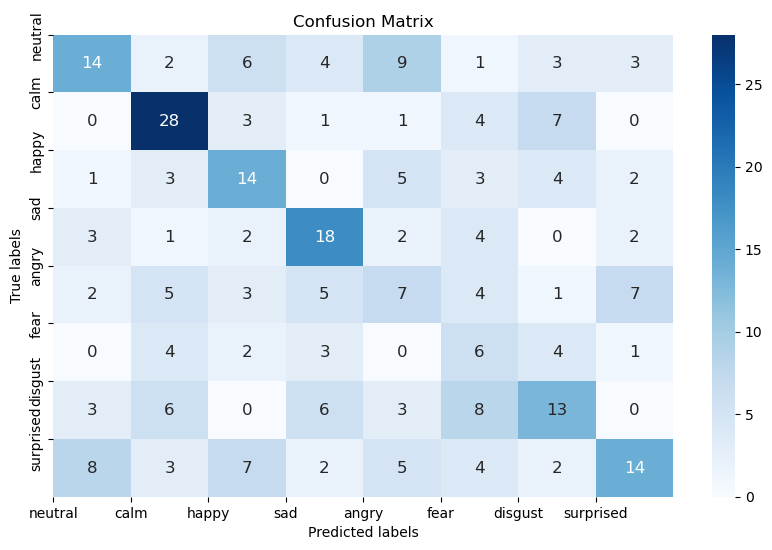

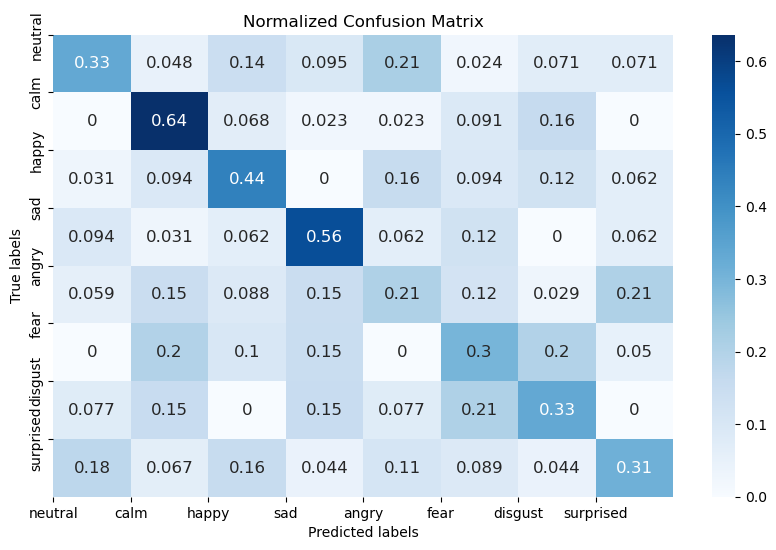

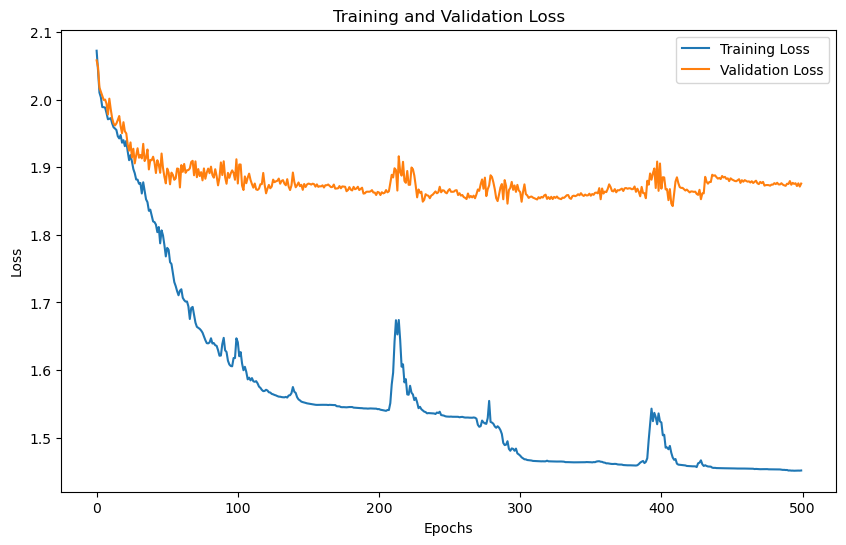

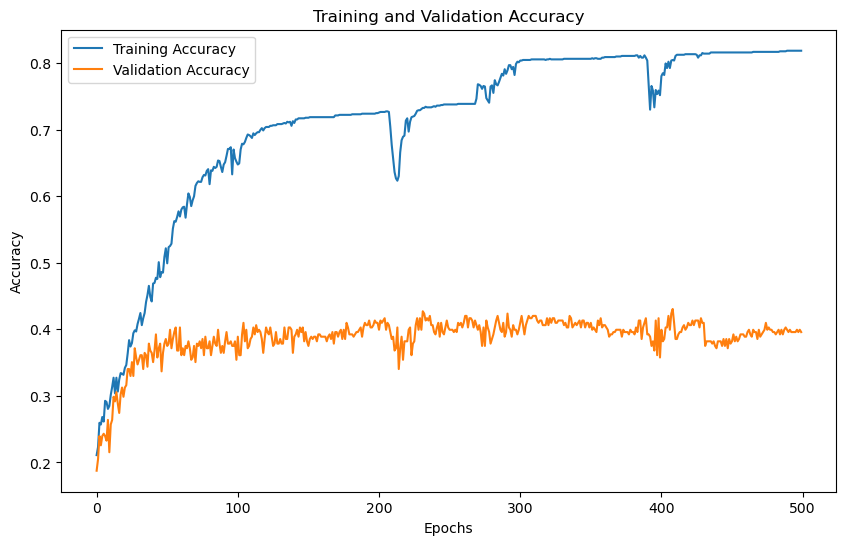

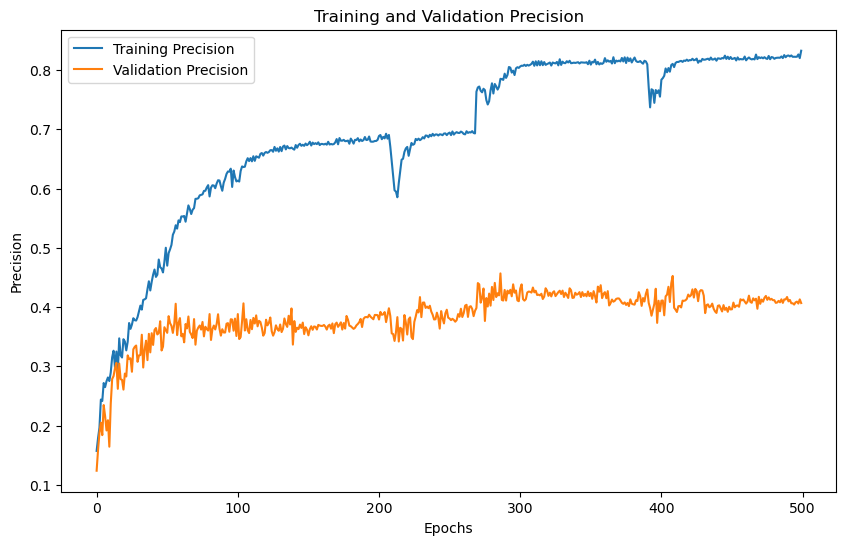

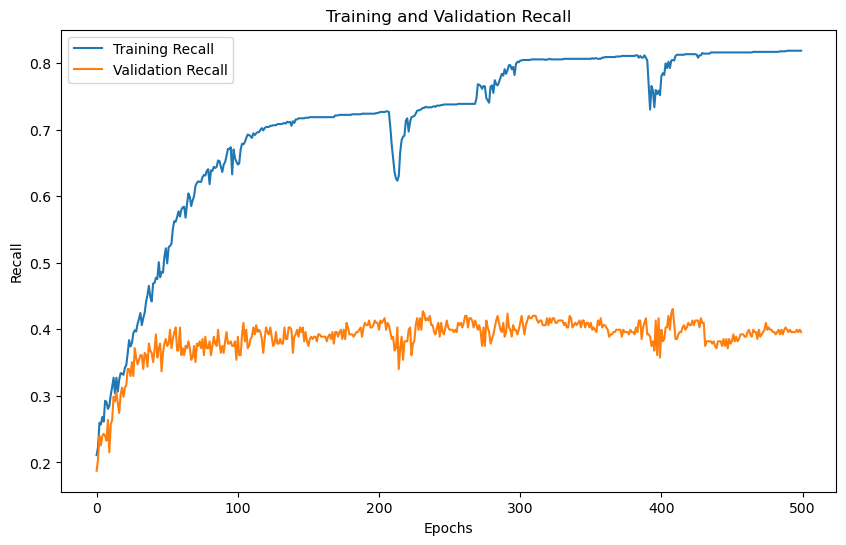

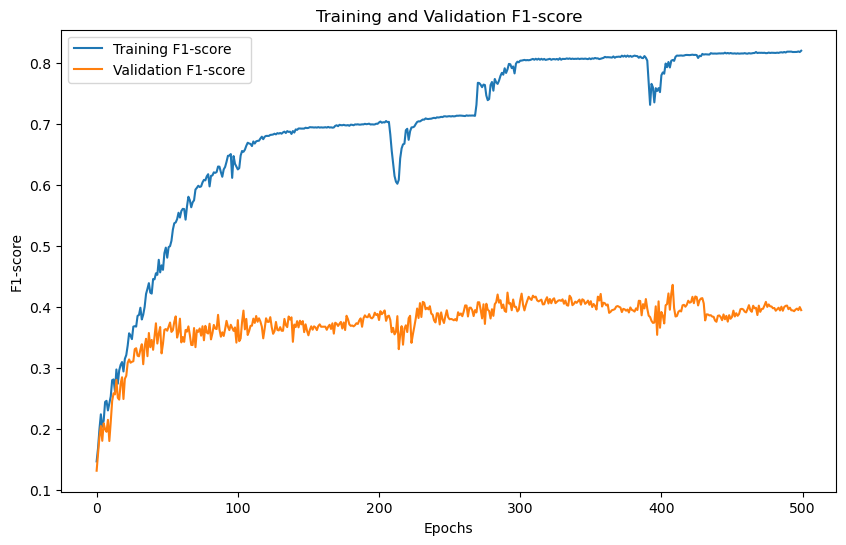

'Model Training and Evaluation Successfully completed'

In [16]:
train_model()

# Crema
# dwt level 3
# nmfcc 32

# 500 epochs

In [ ]:
train_model()

# crema
# dwt level 3
# nmfcc 16

# 500 epochs

In [ ]:
train_model()

# 500 epochs

Enter dataset name:
tess, savee, crema, ravdess
 savee
Enter dwt level:  5
No. of classes 6
Input size : 1
Hidden Size : 256
Model Name: LSTMModel

X Shape : (480, 240, 1)
Y Shape : (480, 6)
Training with DWT level: 5
Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.7915, Training Accuracy: 0.2526, Training Precision:0.1132,Training Recall:0.2526,Training F1-Score:0.1209
Validation Loss: 1.7871, Validation Accuracy: 0.3021, Validation Precision:0.3418,Validation Recall:0.3021,Validation F1-Score:0.1857
Epoch [2/500],
Training Loss: 1.7853, Training Accuracy: 0.2969, Training Precision:0.1940,Training Recall:0.2969,Training F1-Score:0.1851
Validation Loss: 1.7525, Validation Accuracy: 0.4062, Validation Precision:0.3063,Validation Recall:0.4062,Validation F1-Score:0.2850
Epoch [3/500],
Training Loss: 1.7624, Training Accuracy: 0.2604, Training Precision:0.1849,Training Recall:0.2604,Training F1-Score:0.1401
Validation Loss: 1.6758, Validation Accuracy: 0.3750, Validation Precisio

Epoch [31/500],
Training Loss: 1.5697, Training Accuracy: 0.4922, Training Precision:0.3827,Training Recall:0.4922,Training F1-Score:0.4210
Validation Loss: 1.5678, Validation Accuracy: 0.4688, Validation Precision:0.4379,Validation Recall:0.4688,Validation F1-Score:0.4260
Epoch [32/500],
Training Loss: 1.5687, Training Accuracy: 0.4583, Training Precision:0.3451,Training Recall:0.4583,Training F1-Score:0.3852
Validation Loss: 1.5614, Validation Accuracy: 0.4688, Validation Precision:0.4036,Validation Recall:0.4688,Validation F1-Score:0.4228
Epoch [33/500],
Training Loss: 1.5900, Training Accuracy: 0.4635, Training Precision:0.3580,Training Recall:0.4635,Training F1-Score:0.3808
Validation Loss: 1.5367, Validation Accuracy: 0.4792, Validation Precision:0.3841,Validation Recall:0.4792,Validation F1-Score:0.4074
Epoch [34/500],
Training Loss: 1.5701, Training Accuracy: 0.3958, Training Precision:0.3266,Training Recall:0.3958,Training F1-Score:0.3515
Validation Loss: 1.6580, Validation Ac

Epoch [61/500],
Training Loss: 1.5362, Training Accuracy: 0.5078, Training Precision:0.3891,Training Recall:0.5078,Training F1-Score:0.4323
Validation Loss: 1.5102, Validation Accuracy: 0.5312, Validation Precision:0.4449,Validation Recall:0.5312,Validation F1-Score:0.4657
Epoch [62/500],
Training Loss: 1.5445, Training Accuracy: 0.5078, Training Precision:0.3881,Training Recall:0.5078,Training F1-Score:0.4281
Validation Loss: 1.5031, Validation Accuracy: 0.5208, Validation Precision:0.4481,Validation Recall:0.5208,Validation F1-Score:0.4604
Epoch [63/500],
Training Loss: 1.5344, Training Accuracy: 0.5260, Training Precision:0.4391,Training Recall:0.5260,Training F1-Score:0.4699
Validation Loss: 1.5285, Validation Accuracy: 0.5104, Validation Precision:0.4401,Validation Recall:0.5104,Validation F1-Score:0.4561
Epoch [64/500],
Training Loss: 1.5179, Training Accuracy: 0.5286, Training Precision:0.4351,Training Recall:0.5286,Training F1-Score:0.4660
Validation Loss: 1.5066, Validation Ac

Epoch [91/500],
Training Loss: 1.5227, Training Accuracy: 0.5260, Training Precision:0.5264,Training Recall:0.5260,Training F1-Score:0.4844
Validation Loss: 1.5258, Validation Accuracy: 0.5104, Validation Precision:0.5668,Validation Recall:0.5104,Validation F1-Score:0.4752
Epoch [92/500],
Training Loss: 1.5165, Training Accuracy: 0.5286, Training Precision:0.5199,Training Recall:0.5286,Training F1-Score:0.5044
Validation Loss: 1.5131, Validation Accuracy: 0.5208, Validation Precision:0.5262,Validation Recall:0.5208,Validation F1-Score:0.5123
Epoch [93/500],
Training Loss: 1.5062, Training Accuracy: 0.5469, Training Precision:0.5548,Training Recall:0.5469,Training F1-Score:0.5175
Validation Loss: 1.4929, Validation Accuracy: 0.5625, Validation Precision:0.5454,Validation Recall:0.5625,Validation F1-Score:0.5394
Epoch [94/500],
Training Loss: 1.4917, Training Accuracy: 0.5625, Training Precision:0.5964,Training Recall:0.5625,Training F1-Score:0.5380
Validation Loss: 1.4964, Validation Ac

Epoch [121/500],
Training Loss: 1.4491, Training Accuracy: 0.5885, Training Precision:0.6149,Training Recall:0.5885,Training F1-Score:0.5673
Validation Loss: 1.5215, Validation Accuracy: 0.5208, Validation Precision:0.5093,Validation Recall:0.5208,Validation F1-Score:0.5040
Epoch [122/500],
Training Loss: 1.4658, Training Accuracy: 0.5885, Training Precision:0.5946,Training Recall:0.5885,Training F1-Score:0.5652
Validation Loss: 1.5069, Validation Accuracy: 0.5312, Validation Precision:0.5283,Validation Recall:0.5312,Validation F1-Score:0.5108
Epoch [123/500],
Training Loss: 1.4637, Training Accuracy: 0.5729, Training Precision:0.5971,Training Recall:0.5729,Training F1-Score:0.5458
Validation Loss: 1.5173, Validation Accuracy: 0.5208, Validation Precision:0.5804,Validation Recall:0.5208,Validation F1-Score:0.4795
Epoch [124/500],
Training Loss: 1.4607, Training Accuracy: 0.5755, Training Precision:0.6073,Training Recall:0.5755,Training F1-Score:0.5574
Validation Loss: 1.5357, Validatio

...

Epoch [361/500],
Training Loss: 1.3074, Training Accuracy: 0.7396, Training Precision:0.7510,Training Recall:0.7396,Training F1-Score:0.7311
Validation Loss: 1.5498, Validation Accuracy: 0.4792, Validation Precision:0.4768,Validation Recall:0.4792,Validation F1-Score:0.4654
Epoch [362/500],
Training Loss: 1.3058, Training Accuracy: 0.7422, Training Precision:0.7541,Training Recall:0.7422,Training F1-Score:0.7344
Validation Loss: 1.5322, Validation Accuracy: 0.5104, Validation Precision:0.5080,Validation Recall:0.5104,Validation F1-Score:0.4986
Epoch [363/500],
Training Loss: 1.3017, Training Accuracy: 0.7422, Training Precision:0.7558,Training Recall:0.7422,Training F1-Score:0.7345
Validation Loss: 1.5131, Validation Accuracy: 0.5208, Validation Precision:0.5164,Validation Recall:0.5208,Validation F1-Score:0.5089
Epoch [364/500],
Training Loss: 1.3013, Training Accuracy: 0.7474, Training Precision:0.7589,Training Recall:0.7474,Training F1-Score:0.7404
Validation Loss: 1.5166, Validatio

Epoch [391/500],
Training Loss: 1.3188, Training Accuracy: 0.7292, Training Precision:0.7383,Training Recall:0.7292,Training F1-Score:0.7213
Validation Loss: 1.5061, Validation Accuracy: 0.5312, Validation Precision:0.5671,Validation Recall:0.5312,Validation F1-Score:0.5339
Epoch [392/500],
Training Loss: 1.3181, Training Accuracy: 0.7292, Training Precision:0.7403,Training Recall:0.7292,Training F1-Score:0.7209
Validation Loss: 1.4978, Validation Accuracy: 0.5417, Validation Precision:0.5714,Validation Recall:0.5417,Validation F1-Score:0.5381
Epoch [393/500],
Training Loss: 1.3152, Training Accuracy: 0.7448, Training Precision:0.7563,Training Recall:0.7448,Training F1-Score:0.7380
Validation Loss: 1.4963, Validation Accuracy: 0.5417, Validation Precision:0.5369,Validation Recall:0.5417,Validation F1-Score:0.5310
Epoch [394/500],
Training Loss: 1.3058, Training Accuracy: 0.7344, Training Precision:0.7483,Training Recall:0.7344,Training F1-Score:0.7258
Validation Loss: 1.5208, Validatio

Epoch [421/500],
Training Loss: 1.2962, Training Accuracy: 0.7448, Training Precision:0.7561,Training Recall:0.7448,Training F1-Score:0.7370
Validation Loss: 1.5273, Validation Accuracy: 0.5104, Validation Precision:0.5295,Validation Recall:0.5104,Validation F1-Score:0.5059
Epoch [422/500],
Training Loss: 1.2959, Training Accuracy: 0.7474, Training Precision:0.7620,Training Recall:0.7474,Training F1-Score:0.7406
Validation Loss: 1.5296, Validation Accuracy: 0.5104, Validation Precision:0.5354,Validation Recall:0.5104,Validation F1-Score:0.5070
Epoch [423/500],
Training Loss: 1.2950, Training Accuracy: 0.7474, Training Precision:0.7631,Training Recall:0.7474,Training F1-Score:0.7405
Validation Loss: 1.5304, Validation Accuracy: 0.5000, Validation Precision:0.5223,Validation Recall:0.5000,Validation F1-Score:0.4941
Epoch [424/500],
Training Loss: 1.2943, Training Accuracy: 0.7474, Training Precision:0.7587,Training Recall:0.7474,Training F1-Score:0.7396
Validation Loss: 1.5299, Validatio

Epoch [451/500],
Training Loss: 1.2929, Training Accuracy: 0.7474, Training Precision:0.7602,Training Recall:0.7474,Training F1-Score:0.7386
Validation Loss: 1.5181, Validation Accuracy: 0.5208, Validation Precision:0.5457,Validation Recall:0.5208,Validation F1-Score:0.5188
Epoch [452/500],
Training Loss: 1.2929, Training Accuracy: 0.7474, Training Precision:0.7656,Training Recall:0.7474,Training F1-Score:0.7400
Validation Loss: 1.5181, Validation Accuracy: 0.5208, Validation Precision:0.5388,Validation Recall:0.5208,Validation F1-Score:0.5139
Epoch [453/500],
Training Loss: 1.2929, Training Accuracy: 0.7474, Training Precision:0.7558,Training Recall:0.7474,Training F1-Score:0.7396
Validation Loss: 1.5170, Validation Accuracy: 0.5208, Validation Precision:0.5457,Validation Recall:0.5208,Validation F1-Score:0.5188
Epoch [454/500],
Training Loss: 1.2929, Training Accuracy: 0.7474, Training Precision:0.7623,Training Recall:0.7474,Training F1-Score:0.7407
Validation Loss: 1.5187, Validatio

Epoch [481/500],
Training Loss: 1.2900, Training Accuracy: 0.7500, Training Precision:0.7688,Training Recall:0.7500,Training F1-Score:0.7423
Validation Loss: 1.5194, Validation Accuracy: 0.5208, Validation Precision:0.5415,Validation Recall:0.5208,Validation F1-Score:0.5146
Epoch [482/500],
Training Loss: 1.2899, Training Accuracy: 0.7500, Training Precision:0.7618,Training Recall:0.7500,Training F1-Score:0.7411
Validation Loss: 1.5199, Validation Accuracy: 0.5208, Validation Precision:0.5415,Validation Recall:0.5208,Validation F1-Score:0.5146
Epoch [483/500],
Training Loss: 1.2899, Training Accuracy: 0.7500, Training Precision:0.7660,Training Recall:0.7500,Training F1-Score:0.7446
Validation Loss: 1.5206, Validation Accuracy: 0.5104, Validation Precision:0.5278,Validation Recall:0.5104,Validation F1-Score:0.5012
Epoch [484/500],
Training Loss: 1.2899, Training Accuracy: 0.7500, Training Precision:0.7619,Training Recall:0.7500,Training F1-Score:0.7413
Validation Loss: 1.5195, Validatio

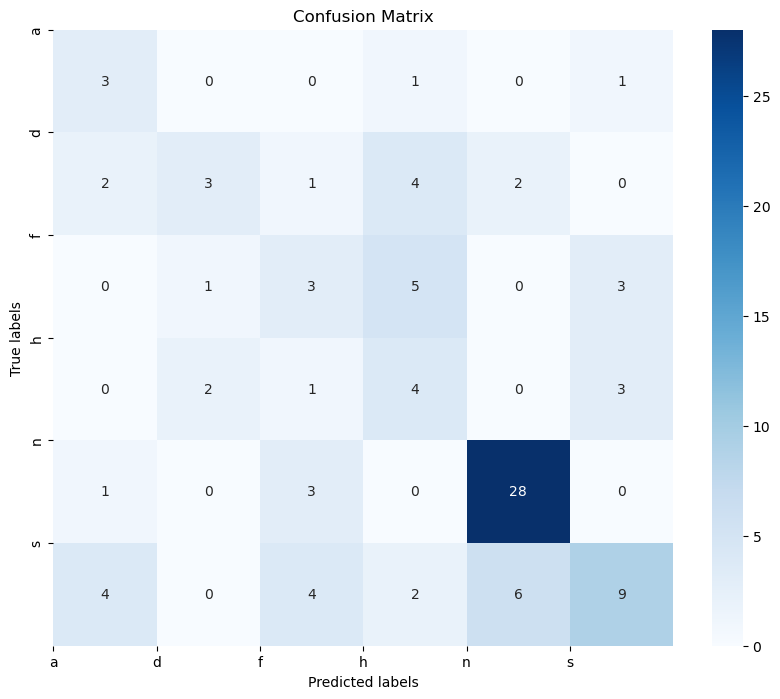

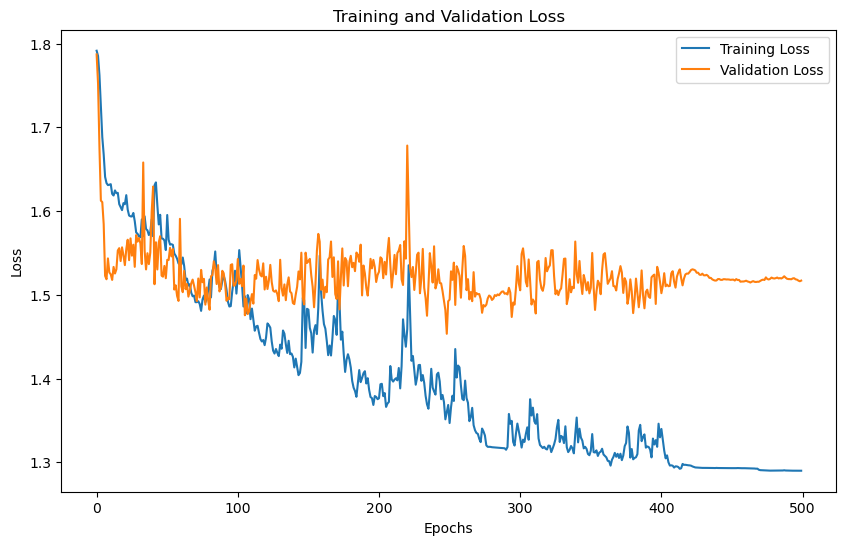

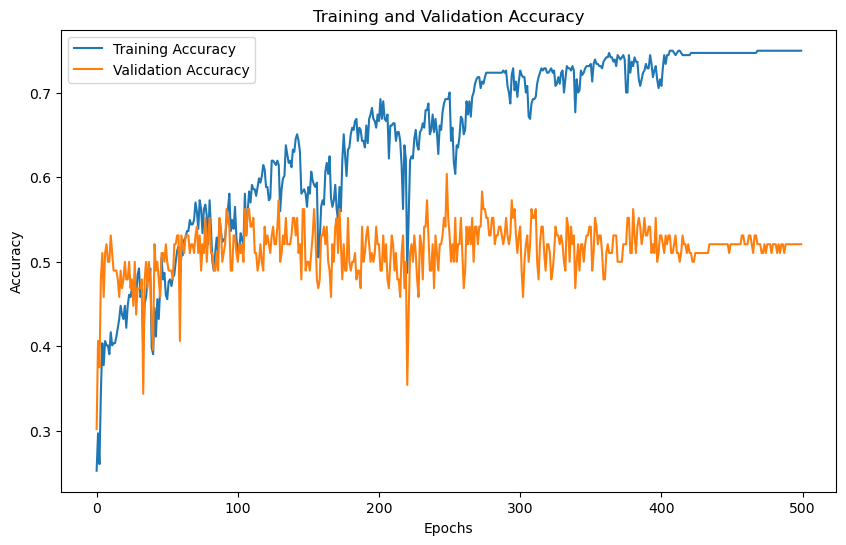

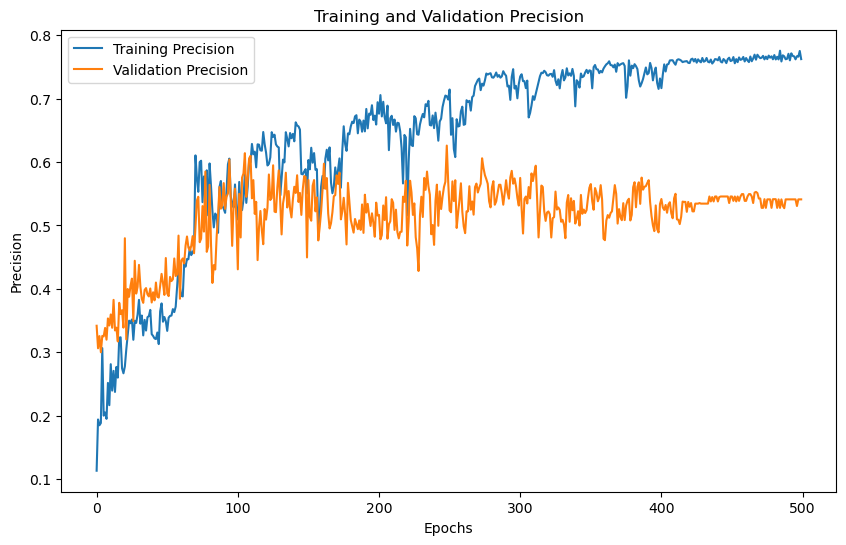

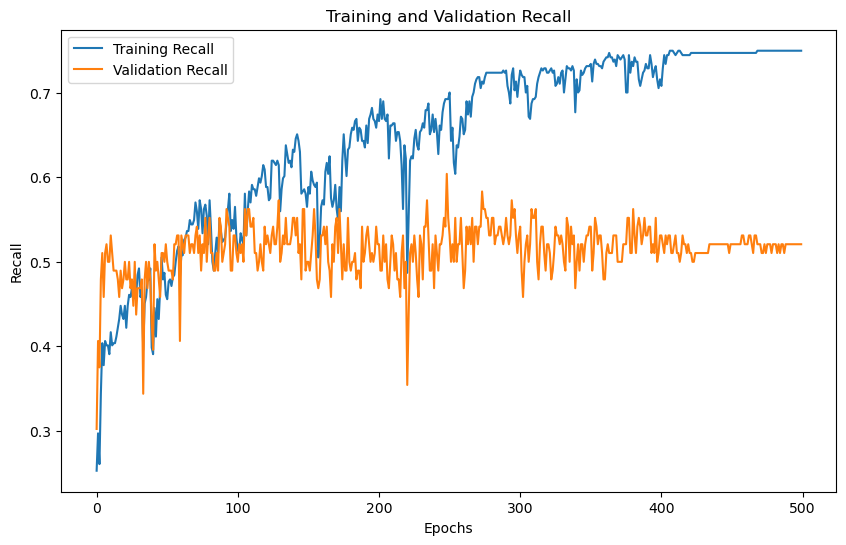

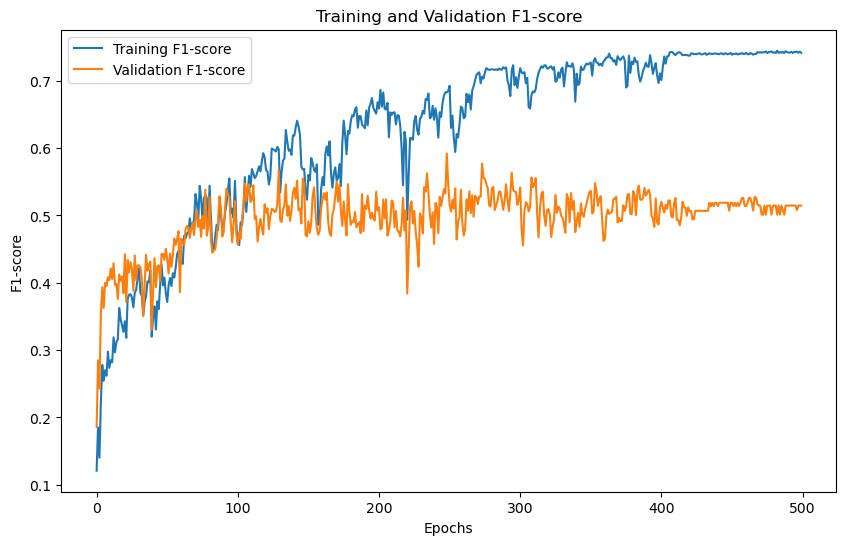

'Model Training and Evaluation Successfully completed'

In [20]:
train_model()

# RAVDESS

# dwt 1

# 500 epochs

Enter dataset name:
tess, savee, crema, ravdess
 ravdess
Enter dwt level:  1
No. of classes 8
Input size : 1
Hidden Size : 256
Model Name: LSTMModel

X Shape : (1440, 80, 1)
Y Shape : (1440, 8)
Training with DWT level: 1
Enter no. of epochs 500
Epoch [1/500],
Training Loss: 2.0750, Training Accuracy: 0.1797, Training Precision:0.0547,Training Recall:0.1797,Training F1-Score:0.0818
Validation Loss: 2.0660, Validation Accuracy: 0.1667, Validation Precision:0.0534,Validation Recall:0.1667,Validation F1-Score:0.0777
Epoch [2/500],
Training Loss: 2.0482, Training Accuracy: 0.1997, Training Precision:0.0683,Training Recall:0.1997,Training F1-Score:0.0952
Validation Loss: 2.0338, Validation Accuracy: 0.2014, Validation Precision:0.0747,Validation Recall:0.2014,Validation F1-Score:0.0994
Epoch [3/500],
Training Loss: 2.0370, Training Accuracy: 0.2031, Training Precision:0.0696,Training Recall:0.2031,Training F1-Score:0.0969
Validation Loss: 2.0283, Validation Accuracy: 0.1979, Validation Preci

Epoch [31/500],
Training Loss: 1.9418, Training Accuracy: 0.3646, Training Precision:0.3350,Training Recall:0.3646,Training F1-Score:0.3445
Validation Loss: 1.9639, Validation Accuracy: 0.2812, Validation Precision:0.2522,Validation Recall:0.2812,Validation F1-Score:0.2598
Epoch [32/500],
Training Loss: 1.9228, Training Accuracy: 0.3776, Training Precision:0.3640,Training Recall:0.3776,Training F1-Score:0.3544
Validation Loss: 1.9298, Validation Accuracy: 0.3333, Validation Precision:0.3159,Validation Recall:0.3333,Validation F1-Score:0.3075
Epoch [33/500],
Training Loss: 1.9200, Training Accuracy: 0.3594, Training Precision:0.3326,Training Recall:0.3594,Training F1-Score:0.3311
Validation Loss: 1.9651, Validation Accuracy: 0.2882, Validation Precision:0.2543,Validation Recall:0.2882,Validation F1-Score:0.2584
Epoch [34/500],
Training Loss: 1.9019, Training Accuracy: 0.3828, Training Precision:0.3643,Training Recall:0.3828,Training F1-Score:0.3599
Validation Loss: 1.9329, Validation Ac

Epoch [61/500],
Training Loss: 1.8883, Training Accuracy: 0.3819, Training Precision:0.3536,Training Recall:0.3819,Training F1-Score:0.3612
Validation Loss: 1.9403, Validation Accuracy: 0.3264, Validation Precision:0.2870,Validation Recall:0.3264,Validation F1-Score:0.2970
Epoch [62/500],
Training Loss: 1.8927, Training Accuracy: 0.3698, Training Precision:0.3552,Training Recall:0.3698,Training F1-Score:0.3317
Validation Loss: 1.9451, Validation Accuracy: 0.3125, Validation Precision:0.3112,Validation Recall:0.3125,Validation F1-Score:0.2738
Epoch [63/500],
Training Loss: 1.8986, Training Accuracy: 0.3950, Training Precision:0.3652,Training Recall:0.3950,Training F1-Score:0.3719
Validation Loss: 1.9332, Validation Accuracy: 0.3438, Validation Precision:0.3250,Validation Recall:0.3438,Validation F1-Score:0.3208
Epoch [64/500],
Training Loss: 1.8769, Training Accuracy: 0.3924, Training Precision:0.3601,Training Recall:0.3924,Training F1-Score:0.3705
Validation Loss: 1.9260, Validation Ac

Epoch [91/500],
Training Loss: 1.8366, Training Accuracy: 0.4418, Training Precision:0.4310,Training Recall:0.4418,Training F1-Score:0.4126
Validation Loss: 1.9269, Validation Accuracy: 0.3507, Validation Precision:0.3070,Validation Recall:0.3507,Validation F1-Score:0.3080
Epoch [92/500],
Training Loss: 1.8410, Training Accuracy: 0.4436, Training Precision:0.4347,Training Recall:0.4436,Training F1-Score:0.4202
Validation Loss: 1.9341, Validation Accuracy: 0.3403, Validation Precision:0.3138,Validation Recall:0.3403,Validation F1-Score:0.3116
Epoch [93/500],
Training Loss: 1.8194, Training Accuracy: 0.4714, Training Precision:0.4435,Training Recall:0.4714,Training F1-Score:0.4452
Validation Loss: 1.9211, Validation Accuracy: 0.3507, Validation Precision:0.3167,Validation Recall:0.3507,Validation F1-Score:0.3266
Epoch [94/500],
Training Loss: 1.8145, Training Accuracy: 0.4323, Training Precision:0.4058,Training Recall:0.4323,Training F1-Score:0.4070
Validation Loss: 1.9384, Validation Ac

Epoch [121/500],
Training Loss: 1.7681, Training Accuracy: 0.4809, Training Precision:0.4479,Training Recall:0.4809,Training F1-Score:0.4600
Validation Loss: 1.9549, Validation Accuracy: 0.3229, Validation Precision:0.2942,Validation Recall:0.3229,Validation F1-Score:0.3049
Epoch [122/500],
Training Loss: 1.7936, Training Accuracy: 0.4800, Training Precision:0.4539,Training Recall:0.4800,Training F1-Score:0.4590
Validation Loss: 1.9303, Validation Accuracy: 0.3368, Validation Precision:0.3164,Validation Recall:0.3368,Validation F1-Score:0.3156
Epoch [123/500],
Training Loss: 1.7846, Training Accuracy: 0.4957, Training Precision:0.4727,Training Recall:0.4957,Training F1-Score:0.4724
Validation Loss: 1.9154, Validation Accuracy: 0.3472, Validation Precision:0.2971,Validation Recall:0.3472,Validation F1-Score:0.3089
Epoch [124/500],
Training Loss: 1.8871, Training Accuracy: 0.2361, Training Precision:0.3916,Training Recall:0.2361,Training F1-Score:0.2022
Validation Loss: 2.0745, Validatio

...

Epoch [361/500],
Training Loss: 1.6057, Training Accuracy: 0.6727, Training Precision:0.6316,Training Recall:0.6727,Training F1-Score:0.6471
Validation Loss: 1.9282, Validation Accuracy: 0.3403, Validation Precision:0.3111,Validation Recall:0.3403,Validation F1-Score:0.3229
Epoch [362/500],
Training Loss: 1.6042, Training Accuracy: 0.6814, Training Precision:0.6383,Training Recall:0.6814,Training F1-Score:0.6553
Validation Loss: 1.9226, Validation Accuracy: 0.3403, Validation Precision:0.3160,Validation Recall:0.3403,Validation F1-Score:0.3256
Epoch [363/500],
Training Loss: 1.6065, Training Accuracy: 0.6589, Training Precision:0.6143,Training Recall:0.6589,Training F1-Score:0.6343
Validation Loss: 1.9223, Validation Accuracy: 0.3368, Validation Precision:0.3162,Validation Recall:0.3368,Validation F1-Score:0.3232
Epoch [364/500],
Training Loss: 1.6105, Training Accuracy: 0.6840, Training Precision:0.6399,Training Recall:0.6840,Training F1-Score:0.6574
Validation Loss: 1.9497, Validatio

Epoch [391/500],
Training Loss: 1.6291, Training Accuracy: 0.6354, Training Precision:0.5962,Training Recall:0.6354,Training F1-Score:0.6099
Validation Loss: 1.9280, Validation Accuracy: 0.3438, Validation Precision:0.3309,Validation Recall:0.3438,Validation F1-Score:0.3274
Epoch [392/500],
Training Loss: 1.6169, Training Accuracy: 0.6849, Training Precision:0.6377,Training Recall:0.6849,Training F1-Score:0.6573
Validation Loss: 1.9387, Validation Accuracy: 0.3299, Validation Precision:0.3039,Validation Recall:0.3299,Validation F1-Score:0.3133
Epoch [393/500],
Training Loss: 1.5935, Training Accuracy: 0.6849, Training Precision:0.6397,Training Recall:0.6849,Training F1-Score:0.6575
Validation Loss: 1.9151, Validation Accuracy: 0.3576, Validation Precision:0.3333,Validation Recall:0.3576,Validation F1-Score:0.3418
Epoch [394/500],
Training Loss: 1.5798, Training Accuracy: 0.7066, Training Precision:0.6593,Training Recall:0.7066,Training F1-Score:0.6789
Validation Loss: 1.9387, Validatio

Epoch [421/500],
Training Loss: 1.5280, Training Accuracy: 0.7205, Training Precision:0.7187,Training Recall:0.7205,Training F1-Score:0.7138
Validation Loss: 1.9526, Validation Accuracy: 0.3229, Validation Precision:0.3231,Validation Recall:0.3229,Validation F1-Score:0.3189
Epoch [422/500],
Training Loss: 1.5658, Training Accuracy: 0.7266, Training Precision:0.7259,Training Recall:0.7266,Training F1-Score:0.7205
Validation Loss: 1.9700, Validation Accuracy: 0.2951, Validation Precision:0.2943,Validation Recall:0.2951,Validation F1-Score:0.2921
Epoch [423/500],
Training Loss: 1.5489, Training Accuracy: 0.7405, Training Precision:0.7381,Training Recall:0.7405,Training F1-Score:0.7348
Validation Loss: 1.9437, Validation Accuracy: 0.3264, Validation Precision:0.3376,Validation Recall:0.3264,Validation F1-Score:0.3241
Epoch [424/500],
Training Loss: 1.5297, Training Accuracy: 0.7543, Training Precision:0.7545,Training Recall:0.7543,Training F1-Score:0.7483
Validation Loss: 1.9546, Validatio

Epoch [451/500],
Training Loss: 1.4883, Training Accuracy: 0.7865, Training Precision:0.7865,Training Recall:0.7865,Training F1-Score:0.7846
Validation Loss: 1.9354, Validation Accuracy: 0.3264, Validation Precision:0.3497,Validation Recall:0.3264,Validation F1-Score:0.3338
Epoch [452/500],
Training Loss: 1.4859, Training Accuracy: 0.7865, Training Precision:0.7877,Training Recall:0.7865,Training F1-Score:0.7848
Validation Loss: 1.9289, Validation Accuracy: 0.3333, Validation Precision:0.3590,Validation Recall:0.3333,Validation F1-Score:0.3406
Epoch [453/500],
Training Loss: 1.4855, Training Accuracy: 0.7865, Training Precision:0.7863,Training Recall:0.7865,Training F1-Score:0.7846
Validation Loss: 1.9299, Validation Accuracy: 0.3229, Validation Precision:0.3448,Validation Recall:0.3229,Validation F1-Score:0.3305
Epoch [454/500],
Training Loss: 1.4850, Training Accuracy: 0.7882, Training Precision:0.7888,Training Recall:0.7882,Training F1-Score:0.7869
Validation Loss: 1.9267, Validatio

Epoch [481/500],
Training Loss: 1.5353, Training Accuracy: 0.7526, Training Precision:0.7514,Training Recall:0.7526,Training F1-Score:0.7496
Validation Loss: 1.9247, Validation Accuracy: 0.3542, Validation Precision:0.3637,Validation Recall:0.3542,Validation F1-Score:0.3535
Epoch [482/500],
Training Loss: 1.5339, Training Accuracy: 0.7613, Training Precision:0.7645,Training Recall:0.7613,Training F1-Score:0.7602
Validation Loss: 1.9499, Validation Accuracy: 0.3194, Validation Precision:0.3271,Validation Recall:0.3194,Validation F1-Score:0.3205
Epoch [483/500],
Training Loss: 1.5175, Training Accuracy: 0.7769, Training Precision:0.7783,Training Recall:0.7769,Training F1-Score:0.7753
Validation Loss: 1.9363, Validation Accuracy: 0.3403, Validation Precision:0.3358,Validation Recall:0.3403,Validation F1-Score:0.3363
Epoch [484/500],
Training Loss: 1.5025, Training Accuracy: 0.7691, Training Precision:0.7717,Training Recall:0.7691,Training F1-Score:0.7676
Validation Loss: 1.9385, Validatio

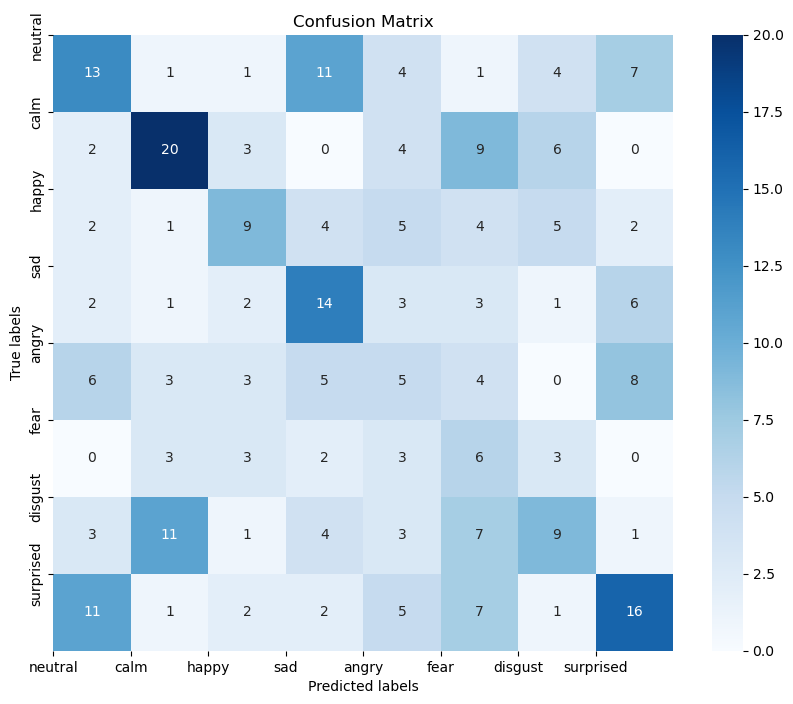

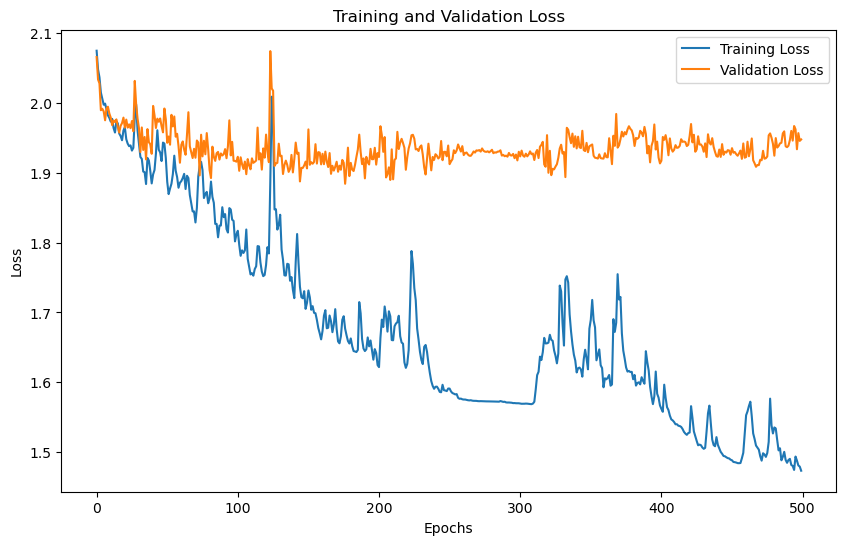

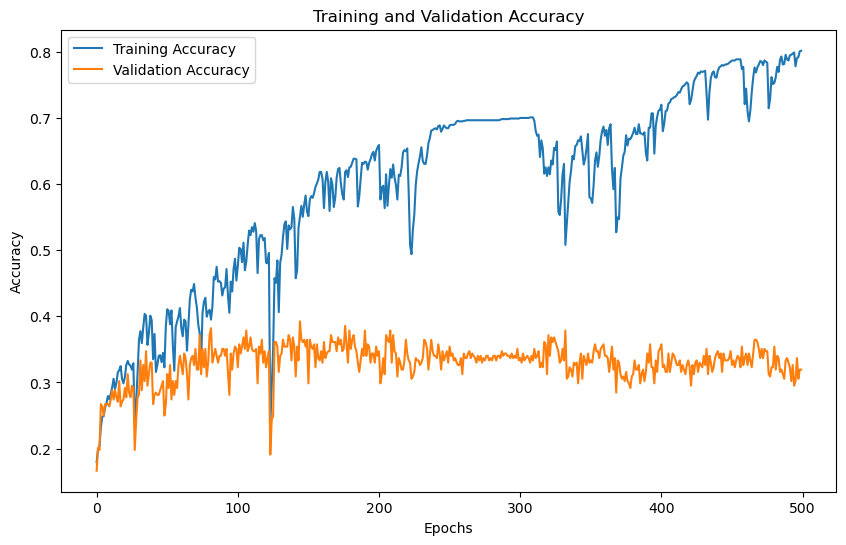

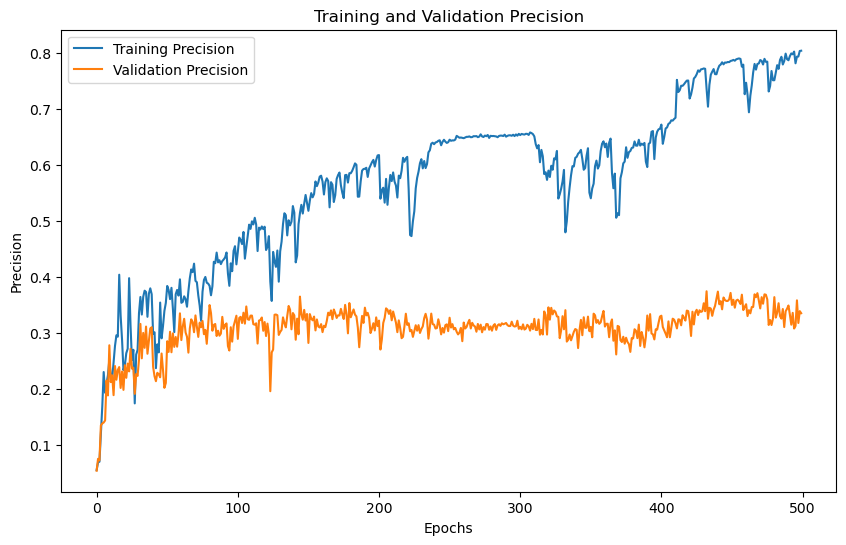

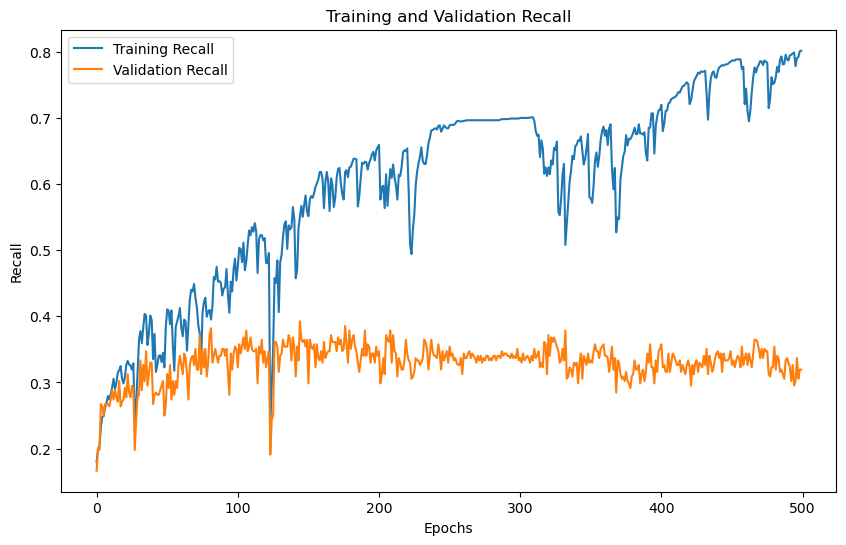

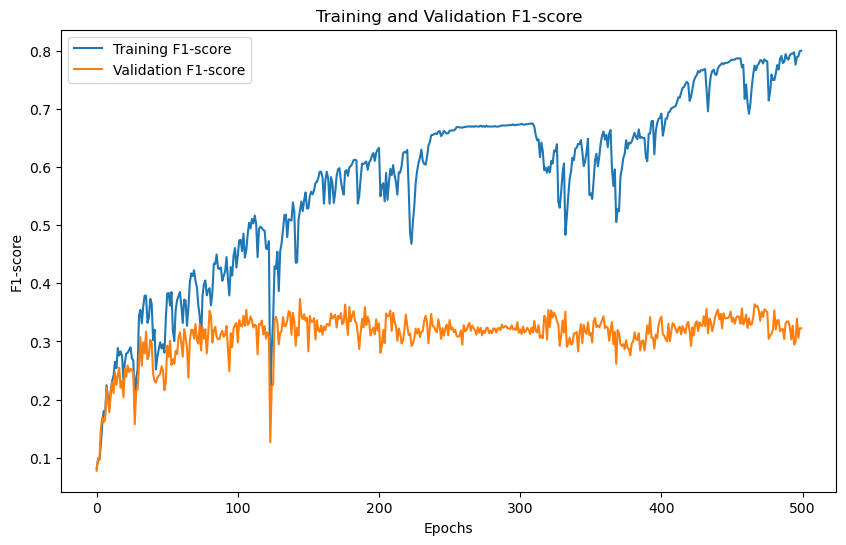

'Model Training and Evaluation Successfully completed'

In [21]:
train_model()

# dwt 2

# 500 epochs

Enter dataset name:
tess, savee, crema, ravdess
 ravdess
Enter dwt level:  2
No. of classes 8
Input size : 1
Hidden Size : 256
Model Name: LSTMModel

X Shape : (1440, 120, 1)
Y Shape : (1440, 8)
Training with DWT level: 2
Enter no. of epochs 500
Epoch [1/500],
Training Loss: 2.0769, Training Accuracy: 0.1823, Training Precision:0.0621,Training Recall:0.1823,Training F1-Score:0.0841
Validation Loss: 2.0662, Validation Accuracy: 0.1701, Validation Precision:0.0595,Validation Recall:0.1701,Validation F1-Score:0.0777
Epoch [2/500],
Training Loss: 2.0547, Training Accuracy: 0.1823, Training Precision:0.0641,Training Recall:0.1823,Training F1-Score:0.0846
Validation Loss: 2.0382, Validation Accuracy: 0.2326, Validation Precision:0.0847,Validation Recall:0.2326,Validation F1-Score:0.1162
Epoch [3/500],
Training Loss: 2.0313, Training Accuracy: 0.2144, Training Precision:0.1764,Training Recall:0.2144,Training F1-Score:0.1164
Validation Loss: 1.9970, Validation Accuracy: 0.2604, Validation Prec

Epoch [31/500],
Training Loss: 1.9414, Training Accuracy: 0.3472, Training Precision:0.3263,Training Recall:0.3472,Training F1-Score:0.3233
Validation Loss: 1.9588, Validation Accuracy: 0.3090, Validation Precision:0.2844,Validation Recall:0.3090,Validation F1-Score:0.2876
Epoch [32/500],
Training Loss: 1.9406, Training Accuracy: 0.3385, Training Precision:0.3119,Training Recall:0.3385,Training F1-Score:0.3059
Validation Loss: 1.9675, Validation Accuracy: 0.2951, Validation Precision:0.2573,Validation Recall:0.2951,Validation F1-Score:0.2581
Epoch [33/500],
Training Loss: 1.9322, Training Accuracy: 0.3385, Training Precision:0.3104,Training Recall:0.3385,Training F1-Score:0.3131
Validation Loss: 1.9718, Validation Accuracy: 0.2743, Validation Precision:0.2414,Validation Recall:0.2743,Validation F1-Score:0.2510
Epoch [34/500],
Training Loss: 1.9268, Training Accuracy: 0.3698, Training Precision:0.3565,Training Recall:0.3698,Training F1-Score:0.3376
Validation Loss: 1.9746, Validation Ac

Epoch [61/500],
Training Loss: 1.8631, Training Accuracy: 0.4366, Training Precision:0.4360,Training Recall:0.4366,Training F1-Score:0.3954
Validation Loss: 1.9478, Validation Accuracy: 0.3090, Validation Precision:0.2520,Validation Recall:0.3090,Validation F1-Score:0.2746
Epoch [62/500],
Training Loss: 1.8538, Training Accuracy: 0.4462, Training Precision:0.4180,Training Recall:0.4462,Training F1-Score:0.4188
Validation Loss: 1.9452, Validation Accuracy: 0.3229, Validation Precision:0.3086,Validation Recall:0.3229,Validation F1-Score:0.3069
Epoch [63/500],
Training Loss: 1.8517, Training Accuracy: 0.4149, Training Precision:0.4113,Training Recall:0.4149,Training F1-Score:0.3949
Validation Loss: 1.9723, Validation Accuracy: 0.2847, Validation Precision:0.2979,Validation Recall:0.2847,Validation F1-Score:0.2752
Epoch [64/500],
Training Loss: 1.8293, Training Accuracy: 0.4479, Training Precision:0.4389,Training Recall:0.4479,Training F1-Score:0.4165
Validation Loss: 1.9376, Validation Ac

Epoch [91/500],
Training Loss: 1.7378, Training Accuracy: 0.5503, Training Precision:0.5165,Training Recall:0.5503,Training F1-Score:0.5264
Validation Loss: 1.9552, Validation Accuracy: 0.3021, Validation Precision:0.3007,Validation Recall:0.3021,Validation F1-Score:0.2972
Epoch [92/500],
Training Loss: 1.7480, Training Accuracy: 0.5373, Training Precision:0.5065,Training Recall:0.5373,Training F1-Score:0.5106
Validation Loss: 1.9420, Validation Accuracy: 0.3264, Validation Precision:0.3208,Validation Recall:0.3264,Validation F1-Score:0.3130
Epoch [93/500],
Training Loss: 1.7330, Training Accuracy: 0.5356, Training Precision:0.5158,Training Recall:0.5356,Training F1-Score:0.5121
Validation Loss: 1.9498, Validation Accuracy: 0.3194, Validation Precision:0.3296,Validation Recall:0.3194,Validation F1-Score:0.3138
Epoch [94/500],
Training Loss: 1.7390, Training Accuracy: 0.5573, Training Precision:0.5310,Training Recall:0.5573,Training F1-Score:0.5302
Validation Loss: 1.9531, Validation Ac

Epoch [121/500],
Training Loss: 1.6784, Training Accuracy: 0.6120, Training Precision:0.5700,Training Recall:0.6120,Training F1-Score:0.5871
Validation Loss: 1.9402, Validation Accuracy: 0.3333, Validation Precision:0.3362,Validation Recall:0.3333,Validation F1-Score:0.3301
Epoch [122/500],
Training Loss: 1.6965, Training Accuracy: 0.6007, Training Precision:0.5698,Training Recall:0.6007,Training F1-Score:0.5714
Validation Loss: 1.9571, Validation Accuracy: 0.3090, Validation Precision:0.3232,Validation Recall:0.3090,Validation F1-Score:0.3020
Epoch [123/500],
Training Loss: 1.7029, Training Accuracy: 0.5642, Training Precision:0.5281,Training Recall:0.5642,Training F1-Score:0.5366
Validation Loss: 1.9647, Validation Accuracy: 0.2917, Validation Precision:0.2822,Validation Recall:0.2917,Validation F1-Score:0.2816
Epoch [124/500],
Training Loss: 1.7137, Training Accuracy: 0.5729, Training Precision:0.5374,Training Recall:0.5729,Training F1-Score:0.5465
Validation Loss: 1.9355, Validatio

...

Epoch [361/500],
Training Loss: 1.5630, Training Accuracy: 0.7205, Training Precision:0.7291,Training Recall:0.7205,Training F1-Score:0.7159
Validation Loss: 1.9619, Validation Accuracy: 0.3056, Validation Precision:0.2999,Validation Recall:0.3056,Validation F1-Score:0.2982
Epoch [362/500],
Training Loss: 1.5679, Training Accuracy: 0.7378, Training Precision:0.7372,Training Recall:0.7378,Training F1-Score:0.7335
Validation Loss: 1.9400, Validation Accuracy: 0.3368, Validation Precision:0.3417,Validation Recall:0.3368,Validation F1-Score:0.3375
Epoch [363/500],
Training Loss: 1.5488, Training Accuracy: 0.7474, Training Precision:0.7486,Training Recall:0.7474,Training F1-Score:0.7434
Validation Loss: 1.9450, Validation Accuracy: 0.3299, Validation Precision:0.3439,Validation Recall:0.3299,Validation F1-Score:0.3315
Epoch [364/500],
Training Loss: 1.5277, Training Accuracy: 0.7465, Training Precision:0.7496,Training Recall:0.7465,Training F1-Score:0.7424
Validation Loss: 1.9301, Validatio

Epoch [391/500],
Training Loss: 1.5535, Training Accuracy: 0.7326, Training Precision:0.7355,Training Recall:0.7326,Training F1-Score:0.7285
Validation Loss: 1.9751, Validation Accuracy: 0.2986, Validation Precision:0.3060,Validation Recall:0.2986,Validation F1-Score:0.2997
Epoch [392/500],
Training Loss: 1.5449, Training Accuracy: 0.7352, Training Precision:0.7404,Training Recall:0.7352,Training F1-Score:0.7315
Validation Loss: 1.9665, Validation Accuracy: 0.3056, Validation Precision:0.3180,Validation Recall:0.3056,Validation F1-Score:0.3058
Epoch [393/500],
Training Loss: 1.5349, Training Accuracy: 0.7509, Training Precision:0.7514,Training Recall:0.7509,Training F1-Score:0.7470
Validation Loss: 1.9786, Validation Accuracy: 0.2917, Validation Precision:0.3108,Validation Recall:0.2917,Validation F1-Score:0.2963
Epoch [394/500],
Training Loss: 1.5243, Training Accuracy: 0.7622, Training Precision:0.7657,Training Recall:0.7622,Training F1-Score:0.7580
Validation Loss: 1.9752, Validatio

Epoch [421/500],
Training Loss: 1.4979, Training Accuracy: 0.7734, Training Precision:0.7743,Training Recall:0.7734,Training F1-Score:0.7695
Validation Loss: 1.9758, Validation Accuracy: 0.3021, Validation Precision:0.3300,Validation Recall:0.3021,Validation F1-Score:0.3066
Epoch [422/500],
Training Loss: 1.4982, Training Accuracy: 0.7743, Training Precision:0.7781,Training Recall:0.7743,Training F1-Score:0.7702
Validation Loss: 1.9745, Validation Accuracy: 0.2951, Validation Precision:0.3215,Validation Recall:0.2951,Validation F1-Score:0.2989
Epoch [423/500],
Training Loss: 1.4974, Training Accuracy: 0.7743, Training Precision:0.7741,Training Recall:0.7743,Training F1-Score:0.7700
Validation Loss: 1.9819, Validation Accuracy: 0.2917, Validation Precision:0.3214,Validation Recall:0.2917,Validation F1-Score:0.2979
Epoch [424/500],
Training Loss: 1.4966, Training Accuracy: 0.7752, Training Precision:0.7777,Training Recall:0.7752,Training F1-Score:0.7713
Validation Loss: 1.9806, Validatio

Epoch [451/500],
Training Loss: 1.4992, Training Accuracy: 0.7778, Training Precision:0.7829,Training Recall:0.7778,Training F1-Score:0.7738
Validation Loss: 1.9835, Validation Accuracy: 0.2847, Validation Precision:0.3038,Validation Recall:0.2847,Validation F1-Score:0.2874
Epoch [452/500],
Training Loss: 1.4954, Training Accuracy: 0.7795, Training Precision:0.7794,Training Recall:0.7795,Training F1-Score:0.7757
Validation Loss: 1.9770, Validation Accuracy: 0.2917, Validation Precision:0.3022,Validation Recall:0.2917,Validation F1-Score:0.2933
Epoch [453/500],
Training Loss: 1.4933, Training Accuracy: 0.7795, Training Precision:0.7828,Training Recall:0.7795,Training F1-Score:0.7760
Validation Loss: 1.9707, Validation Accuracy: 0.3021, Validation Precision:0.3086,Validation Recall:0.3021,Validation F1-Score:0.3009
Epoch [454/500],
Training Loss: 1.4926, Training Accuracy: 0.7795, Training Precision:0.7809,Training Recall:0.7795,Training F1-Score:0.7759
Validation Loss: 1.9781, Validatio

Epoch [481/500],
Training Loss: 1.4810, Training Accuracy: 0.7917, Training Precision:0.7942,Training Recall:0.7917,Training F1-Score:0.7893
Validation Loss: 1.9837, Validation Accuracy: 0.2847, Validation Precision:0.3086,Validation Recall:0.2847,Validation F1-Score:0.2924
Epoch [482/500],
Training Loss: 1.4807, Training Accuracy: 0.7917, Training Precision:0.7927,Training Recall:0.7917,Training F1-Score:0.7889
Validation Loss: 1.9825, Validation Accuracy: 0.2882, Validation Precision:0.3103,Validation Recall:0.2882,Validation F1-Score:0.2939
Epoch [483/500],
Training Loss: 1.4795, Training Accuracy: 0.7917, Training Precision:0.7923,Training Recall:0.7917,Training F1-Score:0.7893
Validation Loss: 1.9794, Validation Accuracy: 0.2951, Validation Precision:0.3196,Validation Recall:0.2951,Validation F1-Score:0.3024
Epoch [484/500],
Training Loss: 1.4793, Training Accuracy: 0.7917, Training Precision:0.7929,Training Recall:0.7917,Training F1-Score:0.7892
Validation Loss: 1.9793, Validatio

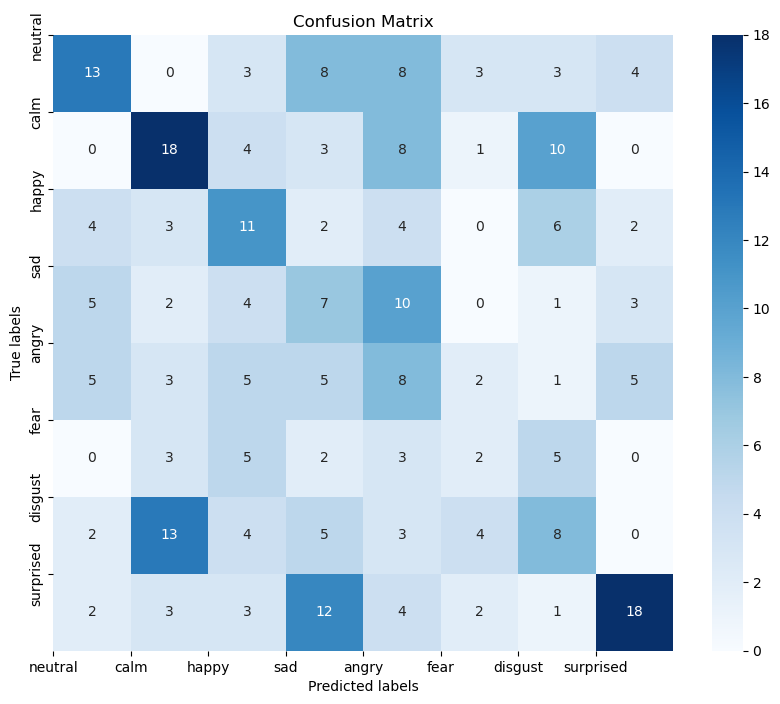

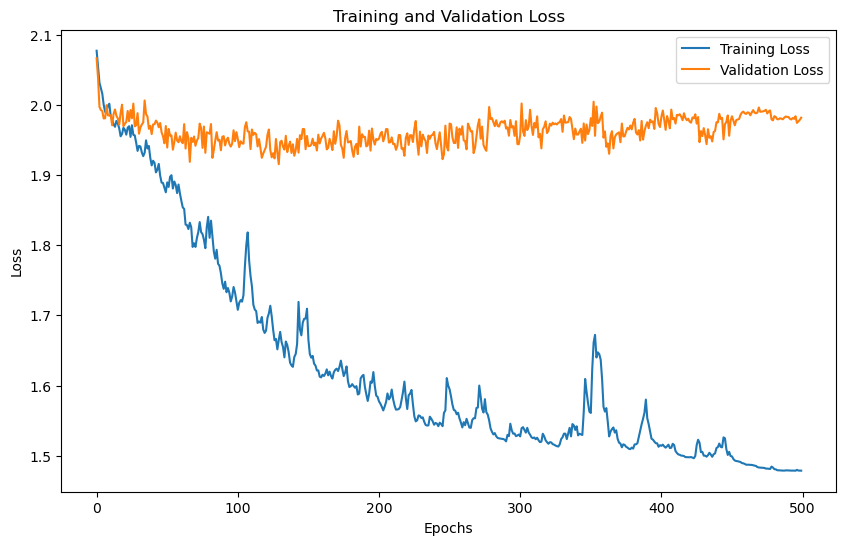

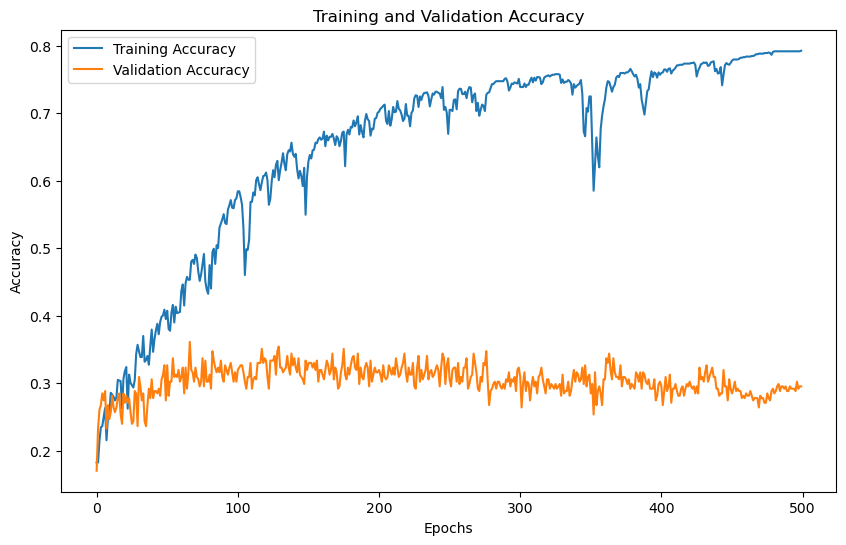

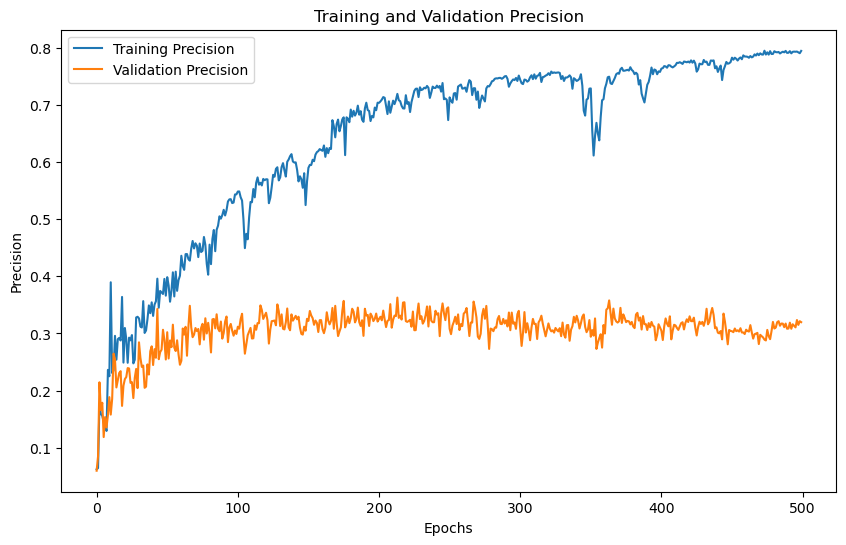

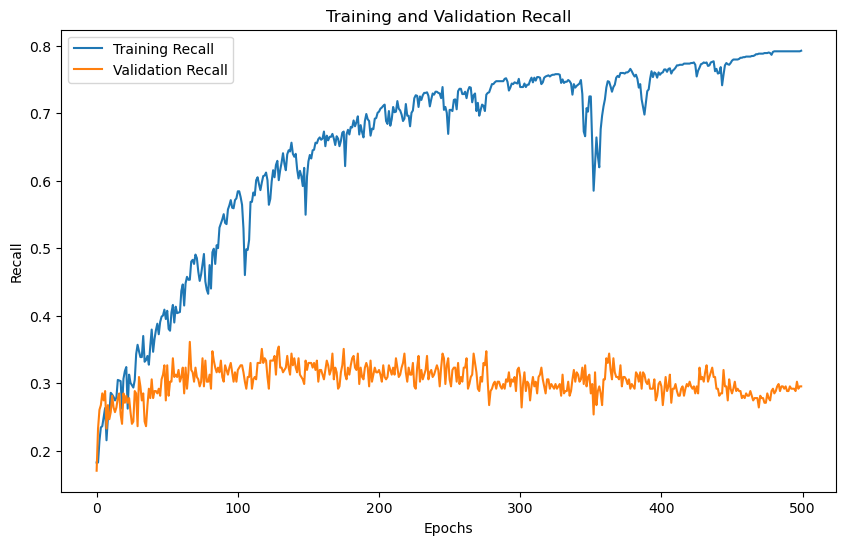

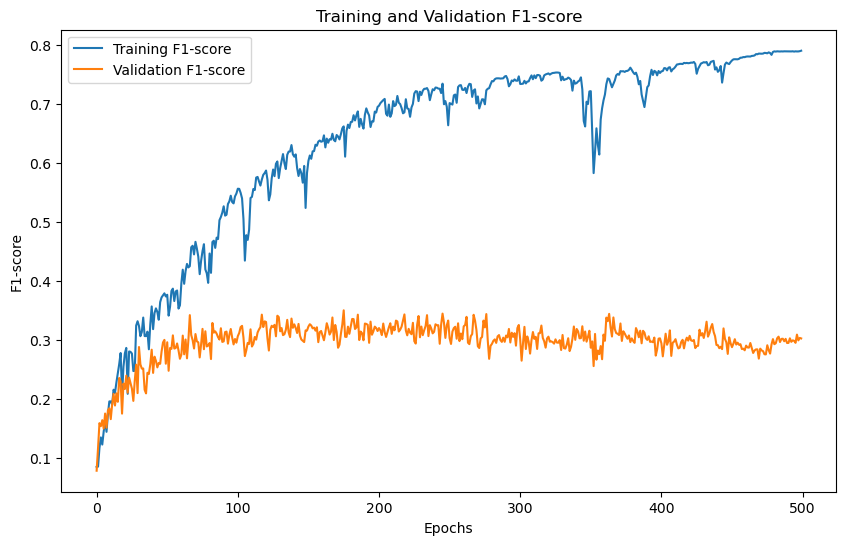

'Model Training and Evaluation Successfully completed'

In [22]:
train_model()

# dwt 3

# 500 epochs

Enter dataset name:
tess, savee, crema, ravdess
 ravdess
Enter dwt level:  3
No. of classes 8
Input size : 1
Hidden Size : 256
Model Name: LSTMModel

X Shape : (1440, 160, 1)
Y Shape : (1440, 8)
Training with DWT level: 3
Enter no. of epochs 500
Epoch [1/500],
Training Loss: 2.0778, Training Accuracy: 0.1701, Training Precision:0.0911,Training Recall:0.1701,Training F1-Score:0.0871
Validation Loss: 2.0734, Validation Accuracy: 0.1944, Validation Precision:0.1357,Validation Recall:0.1944,Validation F1-Score:0.1154
Epoch [2/500],
Training Loss: 2.0597, Training Accuracy: 0.2109, Training Precision:0.1045,Training Recall:0.2109,Training F1-Score:0.1071
Validation Loss: 2.0268, Validation Accuracy: 0.2500, Validation Precision:0.1249,Validation Recall:0.2500,Validation F1-Score:0.1343
Epoch [3/500],
Training Loss: 2.0280, Training Accuracy: 0.2344, Training Precision:0.1175,Training Recall:0.2344,Training F1-Score:0.1304
Validation Loss: 2.0025, Validation Accuracy: 0.2708, Validation Prec

Epoch [31/500],
Training Loss: 1.9518, Training Accuracy: 0.3108, Training Precision:0.3620,Training Recall:0.3108,Training F1-Score:0.2316
Validation Loss: 1.9929, Validation Accuracy: 0.2535, Validation Precision:0.1918,Validation Recall:0.2535,Validation F1-Score:0.1892
Epoch [32/500],
Training Loss: 1.9495, Training Accuracy: 0.2873, Training Precision:0.2260,Training Recall:0.2873,Training F1-Score:0.2289
Validation Loss: 1.9711, Validation Accuracy: 0.2812, Validation Precision:0.2177,Validation Recall:0.2812,Validation F1-Score:0.2182
Epoch [33/500],
Training Loss: 1.9671, Training Accuracy: 0.3168, Training Precision:0.2852,Training Recall:0.3168,Training F1-Score:0.2408
Validation Loss: 1.9544, Validation Accuracy: 0.2986, Validation Precision:0.3283,Validation Recall:0.2986,Validation F1-Score:0.2440
Epoch [34/500],
Training Loss: 1.9373, Training Accuracy: 0.3281, Training Precision:0.2923,Training Recall:0.3281,Training F1-Score:0.2644
Validation Loss: 1.9424, Validation Ac

Epoch [61/500],
Training Loss: 1.8520, Training Accuracy: 0.4462, Training Precision:0.4213,Training Recall:0.4462,Training F1-Score:0.3992
Validation Loss: 1.9032, Validation Accuracy: 0.3542, Validation Precision:0.3258,Validation Recall:0.3542,Validation F1-Score:0.3155
Epoch [62/500],
Training Loss: 1.8304, Training Accuracy: 0.4401, Training Precision:0.4192,Training Recall:0.4401,Training F1-Score:0.4061
Validation Loss: 1.9065, Validation Accuracy: 0.3507, Validation Precision:0.3160,Validation Recall:0.3507,Validation F1-Score:0.3248
Epoch [63/500],
Training Loss: 1.8427, Training Accuracy: 0.4366, Training Precision:0.4135,Training Recall:0.4366,Training F1-Score:0.3939
Validation Loss: 1.9039, Validation Accuracy: 0.3576, Validation Precision:0.3087,Validation Recall:0.3576,Validation F1-Score:0.3173
Epoch [64/500],
Training Loss: 1.8302, Training Accuracy: 0.4497, Training Precision:0.4207,Training Recall:0.4497,Training F1-Score:0.4025
Validation Loss: 1.8864, Validation Ac

Epoch [91/500],
Training Loss: 1.7698, Training Accuracy: 0.5026, Training Precision:0.4909,Training Recall:0.5026,Training F1-Score:0.4700
Validation Loss: 1.8907, Validation Accuracy: 0.3576, Validation Precision:0.3720,Validation Recall:0.3576,Validation F1-Score:0.3312
Epoch [92/500],
Training Loss: 1.7661, Training Accuracy: 0.5417, Training Precision:0.5164,Training Recall:0.5417,Training F1-Score:0.5103
Validation Loss: 1.8691, Validation Accuracy: 0.4028, Validation Precision:0.3669,Validation Recall:0.4028,Validation F1-Score:0.3713
Epoch [93/500],
Training Loss: 1.7539, Training Accuracy: 0.5503, Training Precision:0.5197,Training Recall:0.5503,Training F1-Score:0.5191
Validation Loss: 1.8930, Validation Accuracy: 0.3646, Validation Precision:0.3297,Validation Recall:0.3646,Validation F1-Score:0.3370
Epoch [94/500],
Training Loss: 1.7421, Training Accuracy: 0.5295, Training Precision:0.5111,Training Recall:0.5295,Training F1-Score:0.4921
Validation Loss: 1.8981, Validation Ac

Epoch [121/500],
Training Loss: 1.6620, Training Accuracy: 0.6233, Training Precision:0.5995,Training Recall:0.6233,Training F1-Score:0.5920
Validation Loss: 1.8816, Validation Accuracy: 0.3889, Validation Precision:0.3730,Validation Recall:0.3889,Validation F1-Score:0.3653
Epoch [122/500],
Training Loss: 1.6656, Training Accuracy: 0.6285, Training Precision:0.5939,Training Recall:0.6285,Training F1-Score:0.5980
Validation Loss: 1.8993, Validation Accuracy: 0.3681, Validation Precision:0.3564,Validation Recall:0.3681,Validation F1-Score:0.3518
Epoch [123/500],
Training Loss: 1.6520, Training Accuracy: 0.6328, Training Precision:0.6042,Training Recall:0.6328,Training F1-Score:0.6016
Validation Loss: 1.8989, Validation Accuracy: 0.3715, Validation Precision:0.3513,Validation Recall:0.3715,Validation F1-Score:0.3547
Epoch [124/500],
Training Loss: 1.6487, Training Accuracy: 0.6259, Training Precision:0.5982,Training Recall:0.6259,Training F1-Score:0.5957
Validation Loss: 1.8785, Validatio

...

Epoch [361/500],
Training Loss: 1.4876, Training Accuracy: 0.7943, Training Precision:0.8019,Training Recall:0.7943,Training F1-Score:0.7934
Validation Loss: 1.9425, Validation Accuracy: 0.3299, Validation Precision:0.3632,Validation Recall:0.3299,Validation F1-Score:0.3344
Epoch [362/500],
Training Loss: 1.4790, Training Accuracy: 0.7977, Training Precision:0.8030,Training Recall:0.7977,Training F1-Score:0.7970
Validation Loss: 1.9489, Validation Accuracy: 0.3160, Validation Precision:0.3394,Validation Recall:0.3160,Validation F1-Score:0.3192
Epoch [363/500],
Training Loss: 1.4758, Training Accuracy: 0.8021, Training Precision:0.8061,Training Recall:0.8021,Training F1-Score:0.8006
Validation Loss: 1.9174, Validation Accuracy: 0.3576, Validation Precision:0.3686,Validation Recall:0.3576,Validation F1-Score:0.3566
Epoch [364/500],
Training Loss: 1.4760, Training Accuracy: 0.8021, Training Precision:0.8089,Training Recall:0.8021,Training F1-Score:0.8007
Validation Loss: 1.9150, Validatio

Epoch [391/500],
Training Loss: 1.4602, Training Accuracy: 0.8108, Training Precision:0.8153,Training Recall:0.8108,Training F1-Score:0.8094
Validation Loss: 1.9344, Validation Accuracy: 0.3333, Validation Precision:0.3587,Validation Recall:0.3333,Validation F1-Score:0.3392
Epoch [392/500],
Training Loss: 1.4602, Training Accuracy: 0.8108, Training Precision:0.8150,Training Recall:0.8108,Training F1-Score:0.8099
Validation Loss: 1.9364, Validation Accuracy: 0.3299, Validation Precision:0.3553,Validation Recall:0.3299,Validation F1-Score:0.3357
Epoch [393/500],
Training Loss: 1.4602, Training Accuracy: 0.8108, Training Precision:0.8190,Training Recall:0.8108,Training F1-Score:0.8108
Validation Loss: 1.9354, Validation Accuracy: 0.3264, Validation Precision:0.3534,Validation Recall:0.3264,Validation F1-Score:0.3336
Epoch [394/500],
Training Loss: 1.4601, Training Accuracy: 0.8108, Training Precision:0.8160,Training Recall:0.8108,Training F1-Score:0.8098
Validation Loss: 1.9360, Validatio

Epoch [421/500],
Training Loss: 1.4718, Training Accuracy: 0.7995, Training Precision:0.8085,Training Recall:0.7995,Training F1-Score:0.7993
Validation Loss: 1.9283, Validation Accuracy: 0.3403, Validation Precision:0.3711,Validation Recall:0.3403,Validation F1-Score:0.3455
Epoch [422/500],
Training Loss: 1.4732, Training Accuracy: 0.8082, Training Precision:0.8133,Training Recall:0.8082,Training F1-Score:0.8072
Validation Loss: 1.9380, Validation Accuracy: 0.3264, Validation Precision:0.3548,Validation Recall:0.3264,Validation F1-Score:0.3317
Epoch [423/500],
Training Loss: 1.4749, Training Accuracy: 0.7986, Training Precision:0.8057,Training Recall:0.7986,Training F1-Score:0.7980
Validation Loss: 1.9329, Validation Accuracy: 0.3333, Validation Precision:0.3548,Validation Recall:0.3333,Validation F1-Score:0.3370
Epoch [424/500],
Training Loss: 1.4758, Training Accuracy: 0.8099, Training Precision:0.8120,Training Recall:0.8099,Training F1-Score:0.8083
Validation Loss: 1.9209, Validatio

Epoch [451/500],
Training Loss: 1.4801, Training Accuracy: 0.7986, Training Precision:0.8061,Training Recall:0.7986,Training F1-Score:0.7982
Validation Loss: 1.9144, Validation Accuracy: 0.3576, Validation Precision:0.3568,Validation Recall:0.3576,Validation F1-Score:0.3549
Epoch [452/500],
Training Loss: 1.4925, Training Accuracy: 0.7995, Training Precision:0.8009,Training Recall:0.7995,Training F1-Score:0.7980
Validation Loss: 1.9297, Validation Accuracy: 0.3438, Validation Precision:0.3701,Validation Recall:0.3438,Validation F1-Score:0.3423
Epoch [453/500],
Training Loss: 1.4762, Training Accuracy: 0.8038, Training Precision:0.8050,Training Recall:0.8038,Training F1-Score:0.8028
Validation Loss: 1.9175, Validation Accuracy: 0.3472, Validation Precision:0.3775,Validation Recall:0.3472,Validation F1-Score:0.3536
Epoch [454/500],
Training Loss: 1.4711, Training Accuracy: 0.8116, Training Precision:0.8150,Training Recall:0.8116,Training F1-Score:0.8106
Validation Loss: 1.9477, Validatio

Epoch [481/500],
Training Loss: 1.4488, Training Accuracy: 0.8316, Training Precision:0.8358,Training Recall:0.8316,Training F1-Score:0.8305
Validation Loss: 1.9140, Validation Accuracy: 0.3472, Validation Precision:0.3569,Validation Recall:0.3472,Validation F1-Score:0.3435
Epoch [482/500],
Training Loss: 1.4445, Training Accuracy: 0.8325, Training Precision:0.8356,Training Recall:0.8325,Training F1-Score:0.8312
Validation Loss: 1.9202, Validation Accuracy: 0.3438, Validation Precision:0.3535,Validation Recall:0.3438,Validation F1-Score:0.3431
Epoch [483/500],
Training Loss: 1.4408, Training Accuracy: 0.8325, Training Precision:0.8343,Training Recall:0.8325,Training F1-Score:0.8311
Validation Loss: 1.9271, Validation Accuracy: 0.3368, Validation Precision:0.3461,Validation Recall:0.3368,Validation F1-Score:0.3362
Epoch [484/500],
Training Loss: 1.4406, Training Accuracy: 0.8325, Training Precision:0.8355,Training Recall:0.8325,Training F1-Score:0.8313
Validation Loss: 1.9288, Validatio

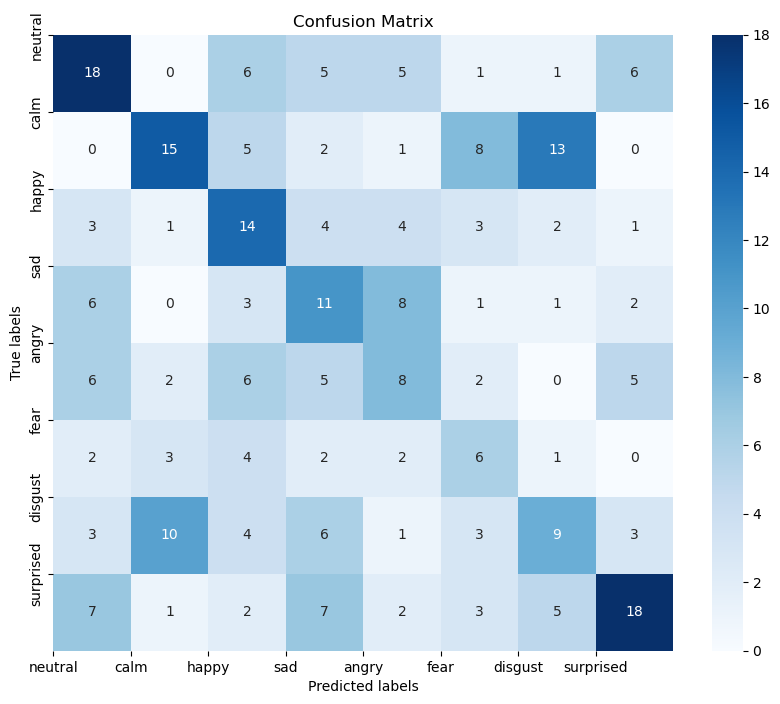

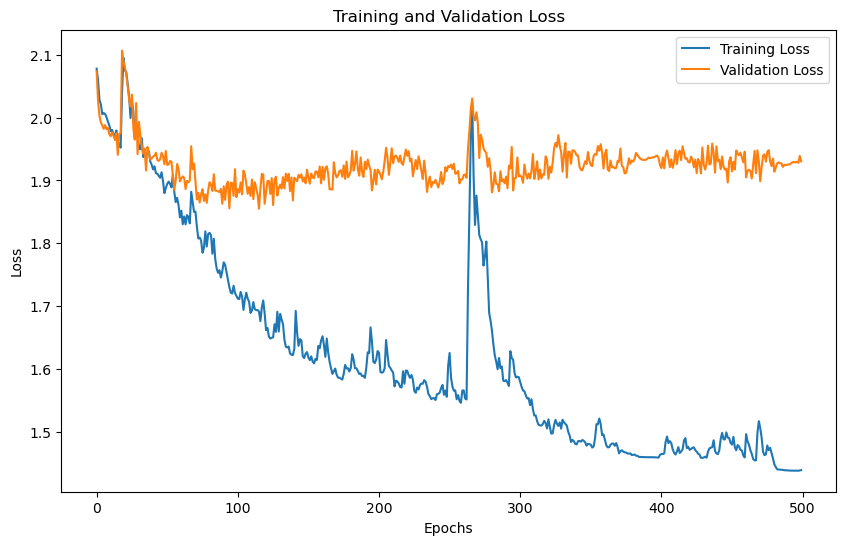

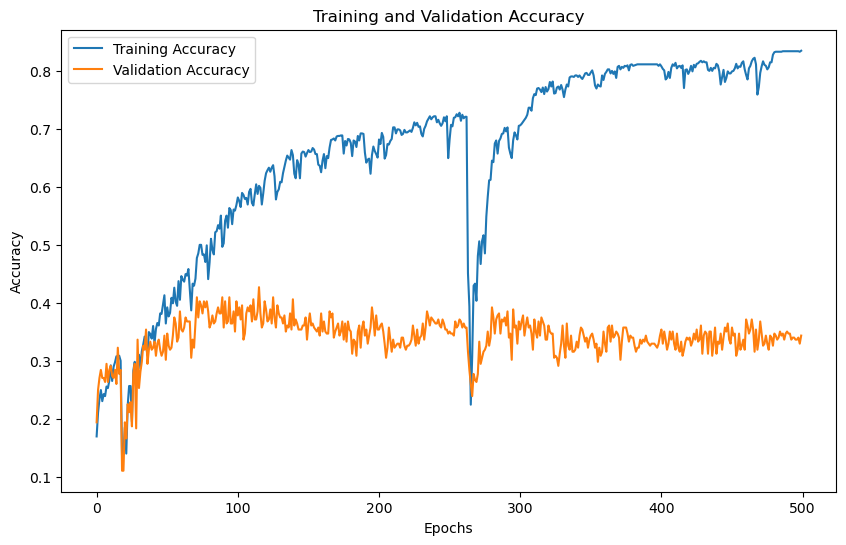

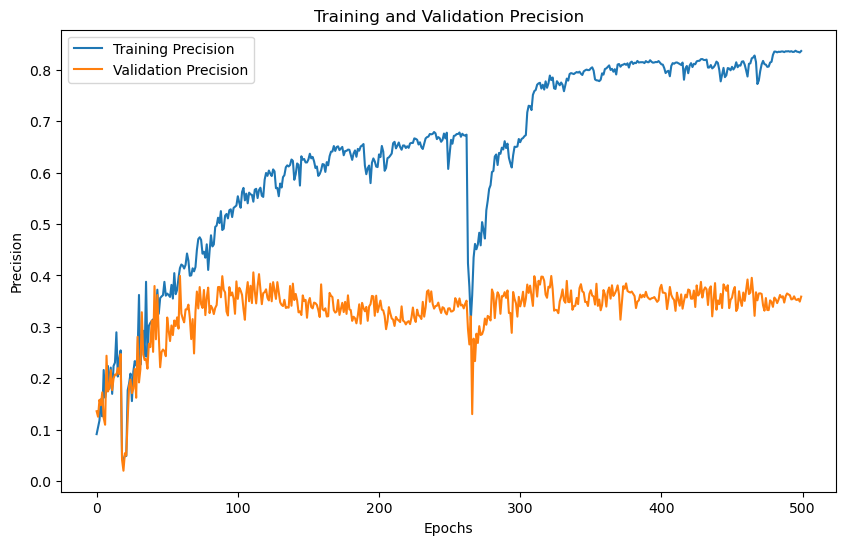

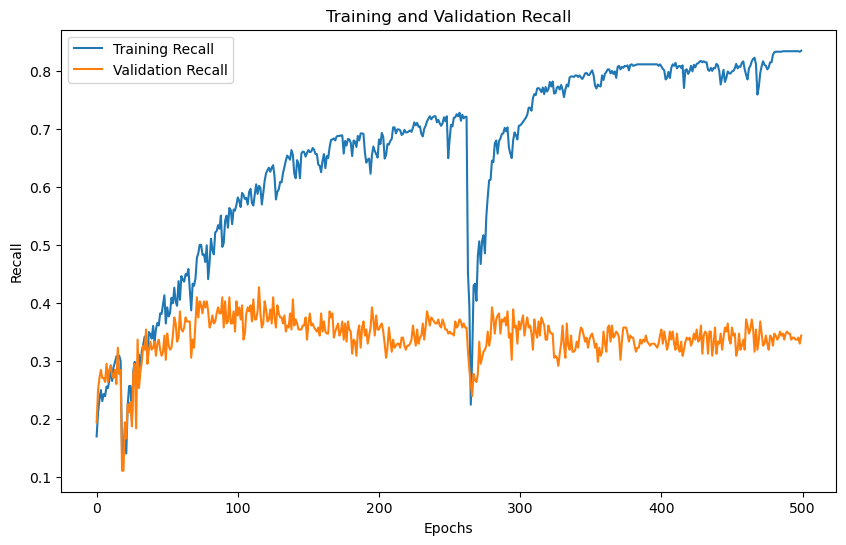

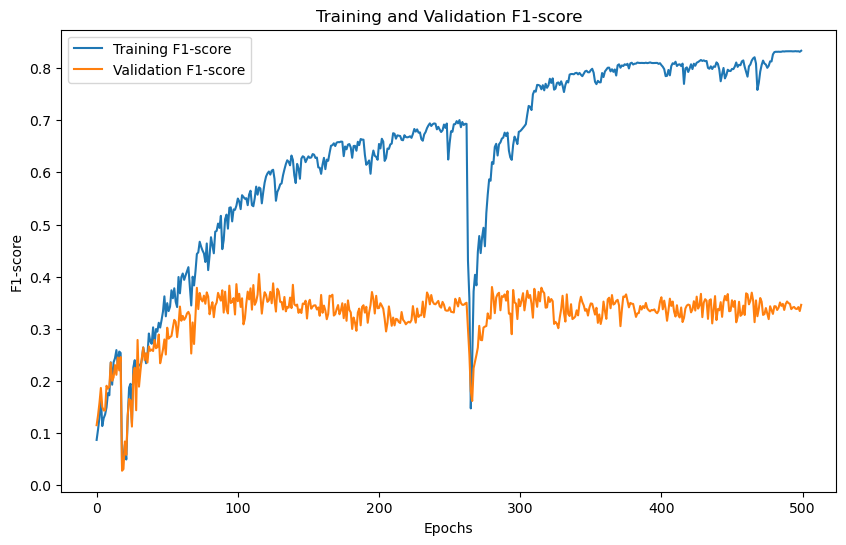

'Model Training and Evaluation Successfully completed'

In [23]:
train_model()

# dwt 4

# 500 epochs

Enter dataset name:
tess, savee, crema, ravdess
 ravdess
Enter dwt level:  4
No. of classes 8
Input size : 1
Hidden Size : 256
Model Name: LSTMModel

X Shape : (1440, 200, 1)
Y Shape : (1440, 8)
Training with DWT level: 4
Enter no. of epochs 500
Epoch [1/500],
Training Loss: 2.0770, Training Accuracy: 0.1580, Training Precision:0.1071,Training Recall:0.1580,Training F1-Score:0.0721
Validation Loss: 2.0735, Validation Accuracy: 0.1354, Validation Precision:0.1138,Validation Recall:0.1354,Validation F1-Score:0.0634
Epoch [2/500],
Training Loss: 2.0546, Training Accuracy: 0.1840, Training Precision:0.1248,Training Recall:0.1840,Training F1-Score:0.1212
Validation Loss: 2.0415, Validation Accuracy: 0.2118, Validation Precision:0.1219,Validation Recall:0.2118,Validation F1-Score:0.1327
Epoch [3/500],
Training Loss: 2.0263, Training Accuracy: 0.2422, Training Precision:0.1757,Training Recall:0.2422,Training F1-Score:0.1686
Validation Loss: 1.9857, Validation Accuracy: 0.2604, Validation Prec

Epoch [31/500],
Training Loss: 1.9431, Training Accuracy: 0.3550, Training Precision:0.3335,Training Recall:0.3550,Training F1-Score:0.3285
Validation Loss: 1.9598, Validation Accuracy: 0.3090, Validation Precision:0.2762,Validation Recall:0.3090,Validation F1-Score:0.2791
Epoch [32/500],
Training Loss: 1.9236, Training Accuracy: 0.3524, Training Precision:0.3300,Training Recall:0.3524,Training F1-Score:0.3168
Validation Loss: 1.9405, Validation Accuracy: 0.3090, Validation Precision:0.2756,Validation Recall:0.3090,Validation F1-Score:0.2635
Epoch [33/500],
Training Loss: 1.9258, Training Accuracy: 0.3637, Training Precision:0.3465,Training Recall:0.3637,Training F1-Score:0.3401
Validation Loss: 1.9544, Validation Accuracy: 0.2951, Validation Precision:0.2644,Validation Recall:0.2951,Validation F1-Score:0.2681
Epoch [34/500],
Training Loss: 1.9050, Training Accuracy: 0.3793, Training Precision:0.3542,Training Recall:0.3793,Training F1-Score:0.3437
Validation Loss: 1.9463, Validation Ac

Epoch [61/500],
Training Loss: 1.8961, Training Accuracy: 0.3628, Training Precision:0.3261,Training Recall:0.3628,Training F1-Score:0.3255
Validation Loss: 1.9590, Validation Accuracy: 0.2986, Validation Precision:0.2508,Validation Recall:0.2986,Validation F1-Score:0.2672
Epoch [62/500],
Training Loss: 1.9048, Training Accuracy: 0.3898, Training Precision:0.3572,Training Recall:0.3898,Training F1-Score:0.3630
Validation Loss: 1.9631, Validation Accuracy: 0.3056, Validation Precision:0.2726,Validation Recall:0.3056,Validation F1-Score:0.2848
Epoch [63/500],
Training Loss: 1.8852, Training Accuracy: 0.3845, Training Precision:0.3554,Training Recall:0.3845,Training F1-Score:0.3571
Validation Loss: 1.9563, Validation Accuracy: 0.2986, Validation Precision:0.2824,Validation Recall:0.2986,Validation F1-Score:0.2794
Epoch [64/500],
Training Loss: 1.8898, Training Accuracy: 0.4028, Training Precision:0.3699,Training Recall:0.4028,Training F1-Score:0.3708
Validation Loss: 1.9340, Validation Ac

Epoch [91/500],
Training Loss: 1.8303, Training Accuracy: 0.4149, Training Precision:0.4124,Training Recall:0.4149,Training F1-Score:0.3896
Validation Loss: 1.9437, Validation Accuracy: 0.3229, Validation Precision:0.3000,Validation Recall:0.3229,Validation F1-Score:0.2928
Epoch [92/500],
Training Loss: 1.8198, Training Accuracy: 0.4557, Training Precision:0.4647,Training Recall:0.4557,Training F1-Score:0.4365
Validation Loss: 1.9270, Validation Accuracy: 0.3299, Validation Precision:0.3120,Validation Recall:0.3299,Validation F1-Score:0.3065
Epoch [93/500],
Training Loss: 1.8187, Training Accuracy: 0.5026, Training Precision:0.5029,Training Recall:0.5026,Training F1-Score:0.4857
Validation Loss: 1.9092, Validation Accuracy: 0.3681, Validation Precision:0.3468,Validation Recall:0.3681,Validation F1-Score:0.3481
Epoch [94/500],
Training Loss: 1.7873, Training Accuracy: 0.4939, Training Precision:0.5105,Training Recall:0.4939,Training F1-Score:0.4747
Validation Loss: 1.9127, Validation Ac

Epoch [121/500],
Training Loss: 1.7868, Training Accuracy: 0.4470, Training Precision:0.4584,Training Recall:0.4470,Training F1-Score:0.4373
Validation Loss: 1.9563, Validation Accuracy: 0.3160, Validation Precision:0.3257,Validation Recall:0.3160,Validation F1-Score:0.3027
Epoch [122/500],
Training Loss: 1.8227, Training Accuracy: 0.4878, Training Precision:0.5073,Training Recall:0.4878,Training F1-Score:0.4740
Validation Loss: 1.9113, Validation Accuracy: 0.3576, Validation Precision:0.3390,Validation Recall:0.3576,Validation F1-Score:0.3329
Epoch [123/500],
Training Loss: 1.7746, Training Accuracy: 0.5113, Training Precision:0.5207,Training Recall:0.5113,Training F1-Score:0.5020
Validation Loss: 1.9333, Validation Accuracy: 0.3333, Validation Precision:0.3328,Validation Recall:0.3333,Validation F1-Score:0.3248
Epoch [124/500],
Training Loss: 1.7559, Training Accuracy: 0.5451, Training Precision:0.5555,Training Recall:0.5451,Training F1-Score:0.5318
Validation Loss: 1.9169, Validatio

...

Epoch [361/500],
Training Loss: 1.5644, Training Accuracy: 0.7170, Training Precision:0.7180,Training Recall:0.7170,Training F1-Score:0.7094
Validation Loss: 1.8987, Validation Accuracy: 0.3681, Validation Precision:0.3567,Validation Recall:0.3681,Validation F1-Score:0.3576
Epoch [362/500],
Training Loss: 1.5520, Training Accuracy: 0.7248, Training Precision:0.7314,Training Recall:0.7248,Training F1-Score:0.7177
Validation Loss: 1.9023, Validation Accuracy: 0.3542, Validation Precision:0.3373,Validation Recall:0.3542,Validation F1-Score:0.3413
Epoch [363/500],
Training Loss: 1.5519, Training Accuracy: 0.7049, Training Precision:0.7160,Training Recall:0.7049,Training F1-Score:0.6984
Validation Loss: 1.9216, Validation Accuracy: 0.3507, Validation Precision:0.3412,Validation Recall:0.3507,Validation F1-Score:0.3418
Epoch [364/500],
Training Loss: 1.5718, Training Accuracy: 0.7005, Training Precision:0.7036,Training Recall:0.7005,Training F1-Score:0.6939
Validation Loss: 1.9221, Validatio

Epoch [391/500],
Training Loss: 2.1369, Training Accuracy: 0.1372, Training Precision:0.0188,Training Recall:0.1372,Training F1-Score:0.0331
Validation Loss: 2.1560, Validation Accuracy: 0.1181, Validation Precision:0.0139,Validation Recall:0.1181,Validation F1-Score:0.0249
Epoch [392/500],
Training Loss: 2.1369, Training Accuracy: 0.1372, Training Precision:0.0188,Training Recall:0.1372,Training F1-Score:0.0331
Validation Loss: 2.1560, Validation Accuracy: 0.1181, Validation Precision:0.0139,Validation Recall:0.1181,Validation F1-Score:0.0249
Epoch [393/500],
Training Loss: 2.1369, Training Accuracy: 0.1372, Training Precision:0.0188,Training Recall:0.1372,Training F1-Score:0.0331
Validation Loss: 2.1560, Validation Accuracy: 0.1181, Validation Precision:0.0139,Validation Recall:0.1181,Validation F1-Score:0.0249
Epoch [394/500],
Training Loss: 2.1369, Training Accuracy: 0.1372, Training Precision:0.0188,Training Recall:0.1372,Training F1-Score:0.0331
Validation Loss: 2.1560, Validatio

Epoch [421/500],
Training Loss: 2.1369, Training Accuracy: 0.1372, Training Precision:0.0188,Training Recall:0.1372,Training F1-Score:0.0331
Validation Loss: 2.1560, Validation Accuracy: 0.1181, Validation Precision:0.0139,Validation Recall:0.1181,Validation F1-Score:0.0249
Epoch [422/500],
Training Loss: 2.1369, Training Accuracy: 0.1372, Training Precision:0.0188,Training Recall:0.1372,Training F1-Score:0.0331
Validation Loss: 2.1560, Validation Accuracy: 0.1181, Validation Precision:0.0139,Validation Recall:0.1181,Validation F1-Score:0.0249
Epoch [423/500],
Training Loss: 2.1369, Training Accuracy: 0.1372, Training Precision:0.0188,Training Recall:0.1372,Training F1-Score:0.0331
Validation Loss: 2.1560, Validation Accuracy: 0.1181, Validation Precision:0.0139,Validation Recall:0.1181,Validation F1-Score:0.0249
Epoch [424/500],
Training Loss: 2.1369, Training Accuracy: 0.1372, Training Precision:0.0188,Training Recall:0.1372,Training F1-Score:0.0331
Validation Loss: 2.1560, Validatio

Epoch [451/500],
Training Loss: 2.1369, Training Accuracy: 0.1372, Training Precision:0.0188,Training Recall:0.1372,Training F1-Score:0.0331
Validation Loss: 2.1560, Validation Accuracy: 0.1181, Validation Precision:0.0139,Validation Recall:0.1181,Validation F1-Score:0.0249
Epoch [452/500],
Training Loss: 2.1369, Training Accuracy: 0.1372, Training Precision:0.0188,Training Recall:0.1372,Training F1-Score:0.0331
Validation Loss: 2.1560, Validation Accuracy: 0.1181, Validation Precision:0.0139,Validation Recall:0.1181,Validation F1-Score:0.0249
Epoch [453/500],
Training Loss: 2.1369, Training Accuracy: 0.1372, Training Precision:0.0188,Training Recall:0.1372,Training F1-Score:0.0331
Validation Loss: 2.1560, Validation Accuracy: 0.1181, Validation Precision:0.0139,Validation Recall:0.1181,Validation F1-Score:0.0249
Epoch [454/500],
Training Loss: 2.1369, Training Accuracy: 0.1372, Training Precision:0.0188,Training Recall:0.1372,Training F1-Score:0.0331
Validation Loss: 2.1560, Validatio

Epoch [481/500],
Training Loss: 2.1369, Training Accuracy: 0.1372, Training Precision:0.0188,Training Recall:0.1372,Training F1-Score:0.0331
Validation Loss: 2.1560, Validation Accuracy: 0.1181, Validation Precision:0.0139,Validation Recall:0.1181,Validation F1-Score:0.0249
Epoch [482/500],
Training Loss: 2.1369, Training Accuracy: 0.1372, Training Precision:0.0188,Training Recall:0.1372,Training F1-Score:0.0331
Validation Loss: 2.1560, Validation Accuracy: 0.1181, Validation Precision:0.0139,Validation Recall:0.1181,Validation F1-Score:0.0249
Epoch [483/500],
Training Loss: 2.1369, Training Accuracy: 0.1372, Training Precision:0.0188,Training Recall:0.1372,Training F1-Score:0.0331
Validation Loss: 2.1560, Validation Accuracy: 0.1181, Validation Precision:0.0139,Validation Recall:0.1181,Validation F1-Score:0.0249
Epoch [484/500],
Training Loss: 2.1369, Training Accuracy: 0.1372, Training Precision:0.0188,Training Recall:0.1372,Training F1-Score:0.0331
Validation Loss: 2.1560, Validatio

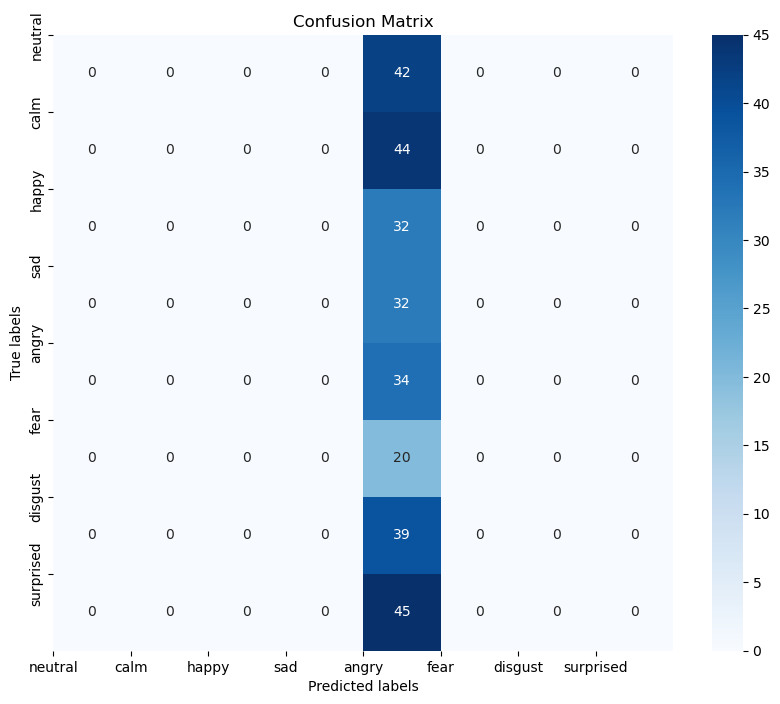

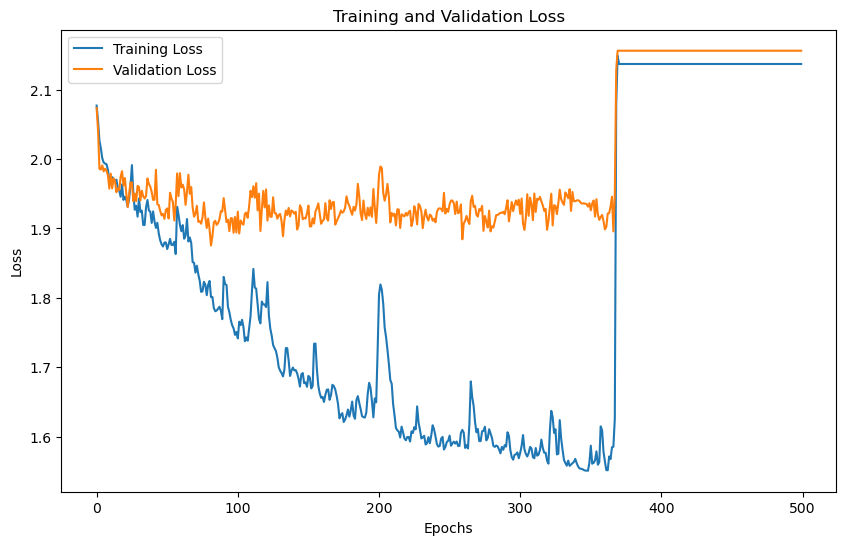

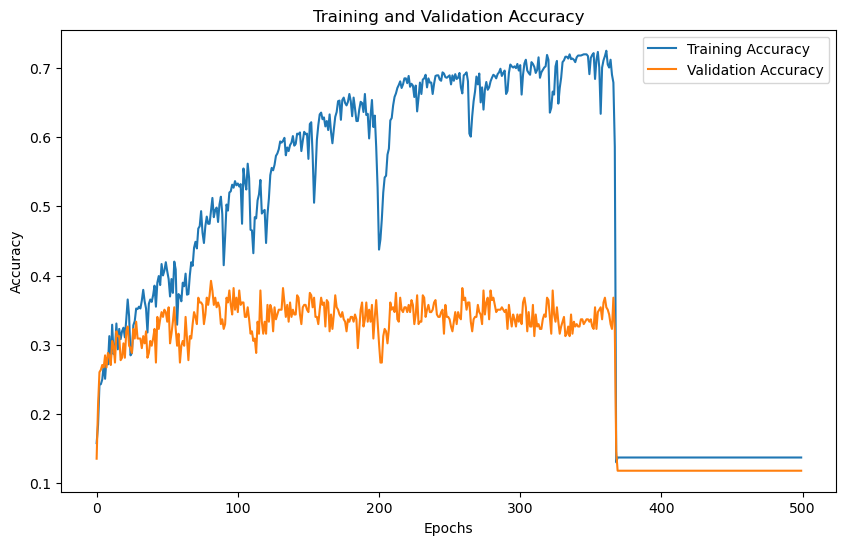

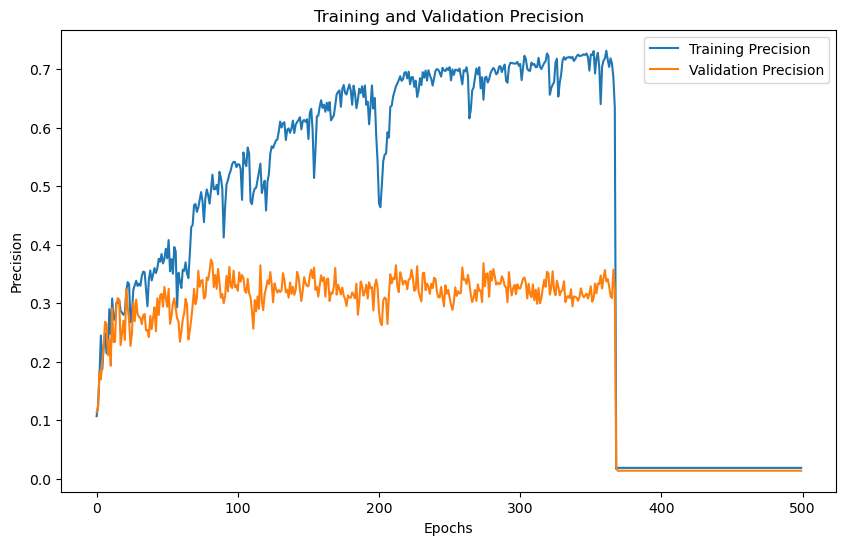

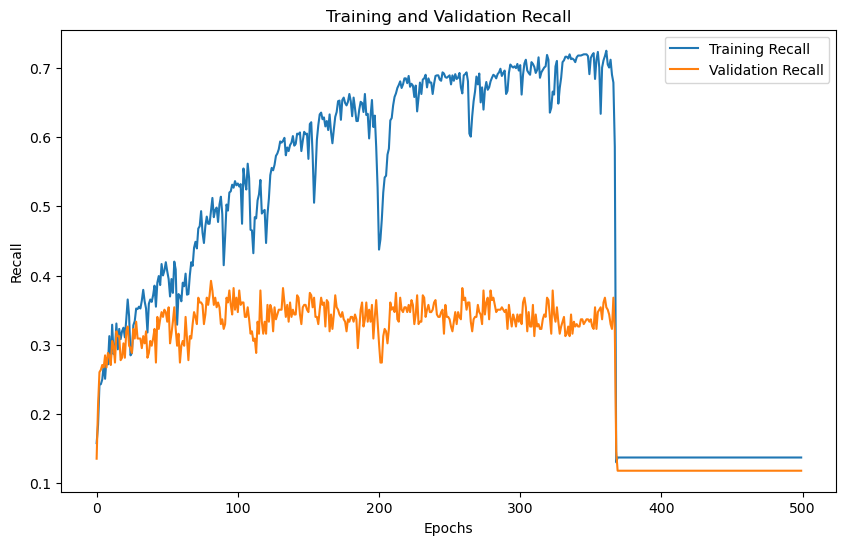

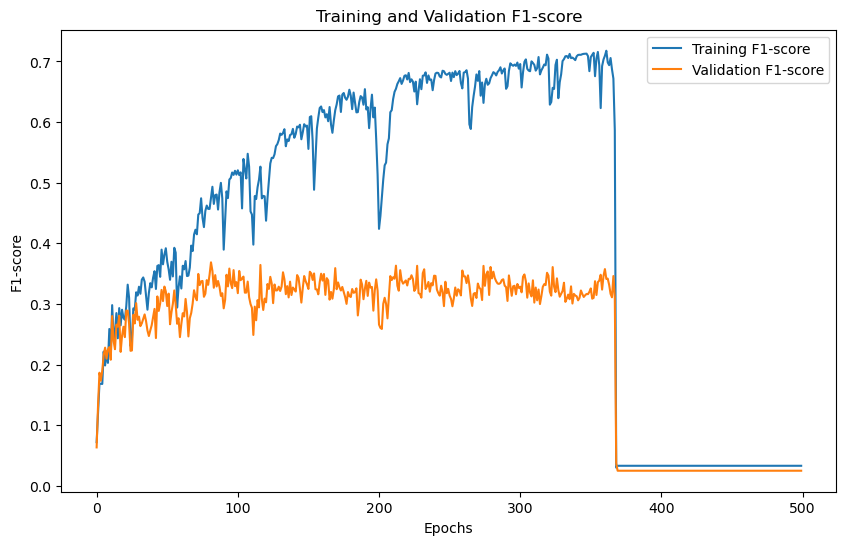

'Model Training and Evaluation Successfully completed'

In [24]:
train_model()

# dwt 5

# 500 epochs

Enter dataset name:
tess, savee, crema, ravdess
 ravdess
Enter dwt level:  5
No. of classes 8
Input size : 1
Hidden Size : 256
Model Name: LSTMModel

X Shape : (1440, 240, 1)
Y Shape : (1440, 8)
Training with DWT level: 5
Enter no. of epochs 500
Epoch [1/500],
Training Loss: 2.0773, Training Accuracy: 0.1701, Training Precision:0.1274,Training Recall:0.1701,Training F1-Score:0.0941
Validation Loss: 2.0718, Validation Accuracy: 0.1354, Validation Precision:0.0721,Validation Recall:0.1354,Validation F1-Score:0.0652
Epoch [2/500],
Training Loss: 2.0571, Training Accuracy: 0.2101, Training Precision:0.1174,Training Recall:0.2101,Training F1-Score:0.1016
Validation Loss: 2.0153, Validation Accuracy: 0.2188, Validation Precision:0.0816,Validation Recall:0.2188,Validation F1-Score:0.1106
Epoch [3/500],
Training Loss: 2.0261, Training Accuracy: 0.2292, Training Precision:0.2141,Training Recall:0.2292,Training F1-Score:0.1450
Validation Loss: 2.0004, Validation Accuracy: 0.2465, Validation Prec

Epoch [31/500],
Training Loss: 1.9404, Training Accuracy: 0.3533, Training Precision:0.3355,Training Recall:0.3533,Training F1-Score:0.3203
Validation Loss: 1.9607, Validation Accuracy: 0.2951, Validation Precision:0.2612,Validation Recall:0.2951,Validation F1-Score:0.2652
Epoch [32/500],
Training Loss: 1.9360, Training Accuracy: 0.3707, Training Precision:0.3530,Training Recall:0.3707,Training F1-Score:0.3405
Validation Loss: 1.9443, Validation Accuracy: 0.3264, Validation Precision:0.3072,Validation Recall:0.3264,Validation F1-Score:0.2993
Epoch [33/500],
Training Loss: 1.9241, Training Accuracy: 0.3602, Training Precision:0.3306,Training Recall:0.3602,Training F1-Score:0.3276
Validation Loss: 1.9459, Validation Accuracy: 0.3299, Validation Precision:0.3035,Validation Recall:0.3299,Validation F1-Score:0.3008
Epoch [34/500],
Training Loss: 1.9339, Training Accuracy: 0.3429, Training Precision:0.3261,Training Recall:0.3429,Training F1-Score:0.3110
Validation Loss: 1.9785, Validation Ac

Epoch [61/500],
Training Loss: 1.9030, Training Accuracy: 0.3490, Training Precision:0.3210,Training Recall:0.3490,Training F1-Score:0.3215
Validation Loss: 1.9472, Validation Accuracy: 0.3229, Validation Precision:0.2914,Validation Recall:0.3229,Validation F1-Score:0.2942
Epoch [62/500],
Training Loss: 1.9325, Training Accuracy: 0.3620, Training Precision:0.3310,Training Recall:0.3620,Training F1-Score:0.3357
Validation Loss: 1.9452, Validation Accuracy: 0.3299, Validation Precision:0.3032,Validation Recall:0.3299,Validation F1-Score:0.3080
Epoch [63/500],
Training Loss: 1.8978, Training Accuracy: 0.3889, Training Precision:0.3625,Training Recall:0.3889,Training F1-Score:0.3549
Validation Loss: 1.9405, Validation Accuracy: 0.3056, Validation Precision:0.2741,Validation Recall:0.3056,Validation F1-Score:0.2769
Epoch [64/500],
Training Loss: 1.8868, Training Accuracy: 0.4193, Training Precision:0.3899,Training Recall:0.4193,Training F1-Score:0.3943
Validation Loss: 1.9463, Validation Ac

Epoch [91/500],
Training Loss: 1.8255, Training Accuracy: 0.4236, Training Precision:0.3908,Training Recall:0.4236,Training F1-Score:0.3941
Validation Loss: 1.9423, Validation Accuracy: 0.3264, Validation Precision:0.3094,Validation Recall:0.3264,Validation F1-Score:0.3032
Epoch [92/500],
Training Loss: 1.8283, Training Accuracy: 0.4696, Training Precision:0.4363,Training Recall:0.4696,Training F1-Score:0.4459
Validation Loss: 1.9236, Validation Accuracy: 0.3299, Validation Precision:0.3045,Validation Recall:0.3299,Validation F1-Score:0.3120
Epoch [93/500],
Training Loss: 1.8125, Training Accuracy: 0.4688, Training Precision:0.4471,Training Recall:0.4688,Training F1-Score:0.4427
Validation Loss: 1.9263, Validation Accuracy: 0.3229, Validation Precision:0.2941,Validation Recall:0.3229,Validation F1-Score:0.2950
Epoch [94/500],
Training Loss: 1.8102, Training Accuracy: 0.5035, Training Precision:0.4703,Training Recall:0.5035,Training F1-Score:0.4800
Validation Loss: 1.9065, Validation Ac

Epoch [121/500],
Training Loss: 1.7368, Training Accuracy: 0.5512, Training Precision:0.5119,Training Recall:0.5512,Training F1-Score:0.5263
Validation Loss: 1.9059, Validation Accuracy: 0.3646, Validation Precision:0.3455,Validation Recall:0.3646,Validation F1-Score:0.3498
Epoch [122/500],
Training Loss: 1.7427, Training Accuracy: 0.5156, Training Precision:0.4837,Training Recall:0.5156,Training F1-Score:0.4919
Validation Loss: 1.9275, Validation Accuracy: 0.3368, Validation Precision:0.3193,Validation Recall:0.3368,Validation F1-Score:0.3248
Epoch [123/500],
Training Loss: 1.7294, Training Accuracy: 0.5521, Training Precision:0.5175,Training Recall:0.5521,Training F1-Score:0.5283
Validation Loss: 1.9223, Validation Accuracy: 0.3438, Validation Precision:0.3321,Validation Recall:0.3438,Validation F1-Score:0.3303
Epoch [124/500],
Training Loss: 1.7252, Training Accuracy: 0.5608, Training Precision:0.5253,Training Recall:0.5608,Training F1-Score:0.5371
Validation Loss: 1.8929, Validatio

...

Epoch [361/500],
Training Loss: 1.6185, Training Accuracy: 0.6641, Training Precision:0.6254,Training Recall:0.6641,Training F1-Score:0.6382
Validation Loss: 1.8928, Validation Accuracy: 0.3854, Validation Precision:0.3629,Validation Recall:0.3854,Validation F1-Score:0.3689
Epoch [362/500],
Training Loss: 1.6331, Training Accuracy: 0.6545, Training Precision:0.6175,Training Recall:0.6545,Training F1-Score:0.6293
Validation Loss: 1.9148, Validation Accuracy: 0.3472, Validation Precision:0.3313,Validation Recall:0.3472,Validation F1-Score:0.3326
Epoch [363/500],
Training Loss: 1.6323, Training Accuracy: 0.6328, Training Precision:0.5943,Training Recall:0.6328,Training F1-Score:0.6072
Validation Loss: 1.9096, Validation Accuracy: 0.3611, Validation Precision:0.3351,Validation Recall:0.3611,Validation F1-Score:0.3398
Epoch [364/500],
Training Loss: 1.6647, Training Accuracy: 0.6181, Training Precision:0.5869,Training Recall:0.6181,Training F1-Score:0.5917
Validation Loss: 1.9199, Validatio

Epoch [391/500],
Training Loss: 1.5687, Training Accuracy: 0.7075, Training Precision:0.6633,Training Recall:0.7075,Training F1-Score:0.6797
Validation Loss: 1.8887, Validation Accuracy: 0.3819, Validation Precision:0.3534,Validation Recall:0.3819,Validation F1-Score:0.3638
Epoch [392/500],
Training Loss: 1.5657, Training Accuracy: 0.7075, Training Precision:0.6638,Training Recall:0.7075,Training F1-Score:0.6797
Validation Loss: 1.8929, Validation Accuracy: 0.3750, Validation Precision:0.3480,Validation Recall:0.3750,Validation F1-Score:0.3576
Epoch [393/500],
Training Loss: 1.5656, Training Accuracy: 0.7083, Training Precision:0.6639,Training Recall:0.7083,Training F1-Score:0.6806
Validation Loss: 1.8843, Validation Accuracy: 0.3854, Validation Precision:0.3600,Validation Recall:0.3854,Validation F1-Score:0.3657
Epoch [394/500],
Training Loss: 1.5658, Training Accuracy: 0.6936, Training Precision:0.6499,Training Recall:0.6936,Training F1-Score:0.6661
Validation Loss: 1.9225, Validatio

Epoch [421/500],
Training Loss: 1.5788, Training Accuracy: 0.7127, Training Precision:0.7206,Training Recall:0.7127,Training F1-Score:0.7070
Validation Loss: 1.9242, Validation Accuracy: 0.3507, Validation Precision:0.3528,Validation Recall:0.3507,Validation F1-Score:0.3437
Epoch [422/500],
Training Loss: 1.5497, Training Accuracy: 0.7413, Training Precision:0.7444,Training Recall:0.7413,Training F1-Score:0.7371
Validation Loss: 1.9181, Validation Accuracy: 0.3542, Validation Precision:0.3697,Validation Recall:0.3542,Validation F1-Score:0.3576
Epoch [423/500],
Training Loss: 1.5367, Training Accuracy: 0.7491, Training Precision:0.7539,Training Recall:0.7491,Training F1-Score:0.7450
Validation Loss: 1.9243, Validation Accuracy: 0.3507, Validation Precision:0.3600,Validation Recall:0.3507,Validation F1-Score:0.3498
Epoch [424/500],
Training Loss: 1.5599, Training Accuracy: 0.7188, Training Precision:0.7313,Training Recall:0.7188,Training F1-Score:0.7162
Validation Loss: 1.9169, Validatio

Epoch [451/500],
Training Loss: 1.4972, Training Accuracy: 0.7743, Training Precision:0.7810,Training Recall:0.7743,Training F1-Score:0.7714
Validation Loss: 1.8993, Validation Accuracy: 0.3750, Validation Precision:0.3803,Validation Recall:0.3750,Validation F1-Score:0.3726
Epoch [452/500],
Training Loss: 1.4970, Training Accuracy: 0.7743, Training Precision:0.7832,Training Recall:0.7743,Training F1-Score:0.7712
Validation Loss: 1.8990, Validation Accuracy: 0.3750, Validation Precision:0.3816,Validation Recall:0.3750,Validation F1-Score:0.3726
Epoch [453/500],
Training Loss: 1.4970, Training Accuracy: 0.7743, Training Precision:0.7796,Training Recall:0.7743,Training F1-Score:0.7713
Validation Loss: 1.8986, Validation Accuracy: 0.3750, Validation Precision:0.3852,Validation Recall:0.3750,Validation F1-Score:0.3744
Epoch [454/500],
Training Loss: 1.4971, Training Accuracy: 0.7743, Training Precision:0.7822,Training Recall:0.7743,Training F1-Score:0.7709
Validation Loss: 1.8974, Validatio

Epoch [481/500],
Training Loss: 1.4957, Training Accuracy: 0.7752, Training Precision:0.7822,Training Recall:0.7752,Training F1-Score:0.7721
Validation Loss: 1.9037, Validation Accuracy: 0.3681, Validation Precision:0.3685,Validation Recall:0.3681,Validation F1-Score:0.3650
Epoch [482/500],
Training Loss: 1.4956, Training Accuracy: 0.7752, Training Precision:0.7863,Training Recall:0.7752,Training F1-Score:0.7727
Validation Loss: 1.9030, Validation Accuracy: 0.3646, Validation Precision:0.3722,Validation Recall:0.3646,Validation F1-Score:0.3616
Epoch [483/500],
Training Loss: 1.4956, Training Accuracy: 0.7752, Training Precision:0.7842,Training Recall:0.7752,Training F1-Score:0.7723
Validation Loss: 1.9007, Validation Accuracy: 0.3715, Validation Precision:0.3792,Validation Recall:0.3715,Validation F1-Score:0.3697
Epoch [484/500],
Training Loss: 1.4957, Training Accuracy: 0.7752, Training Precision:0.7805,Training Recall:0.7752,Training F1-Score:0.7718
Validation Loss: 1.9019, Validatio

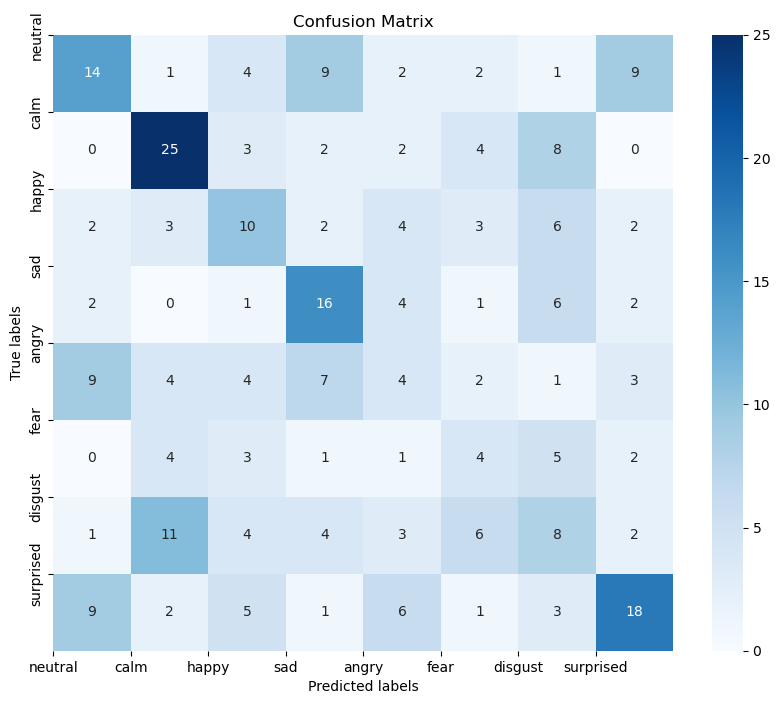

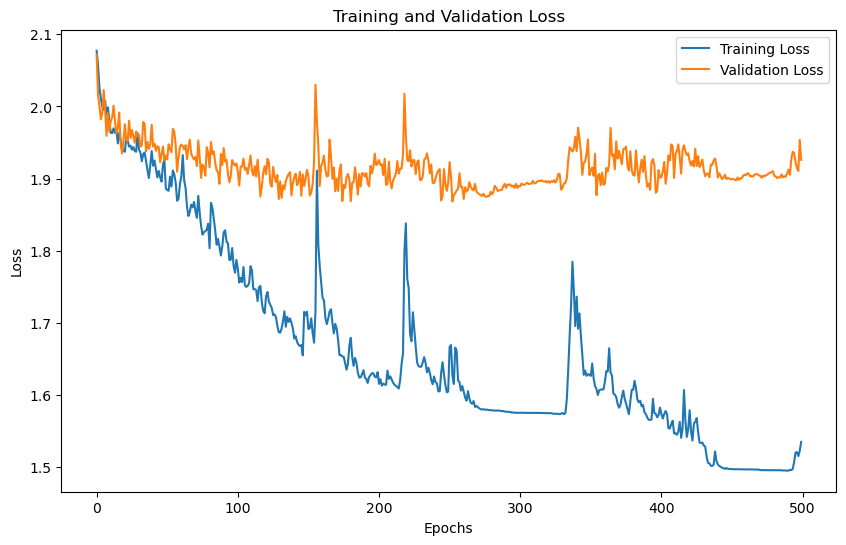

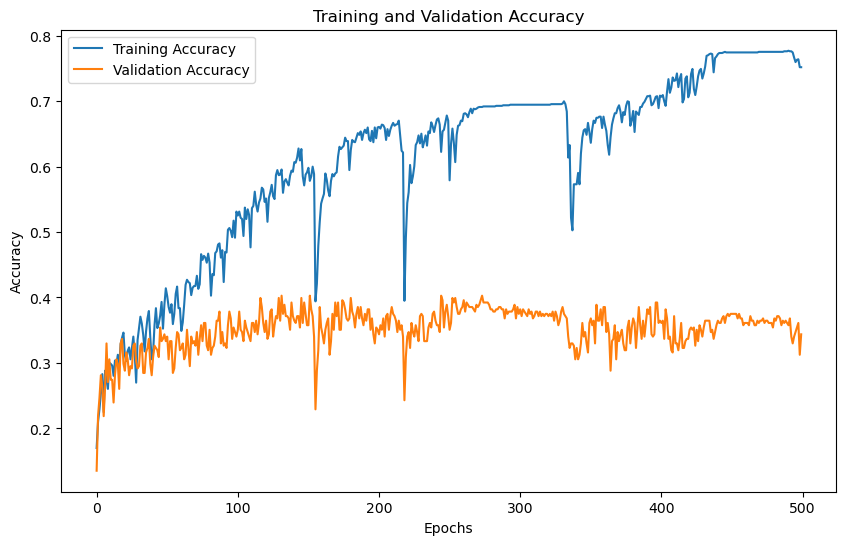

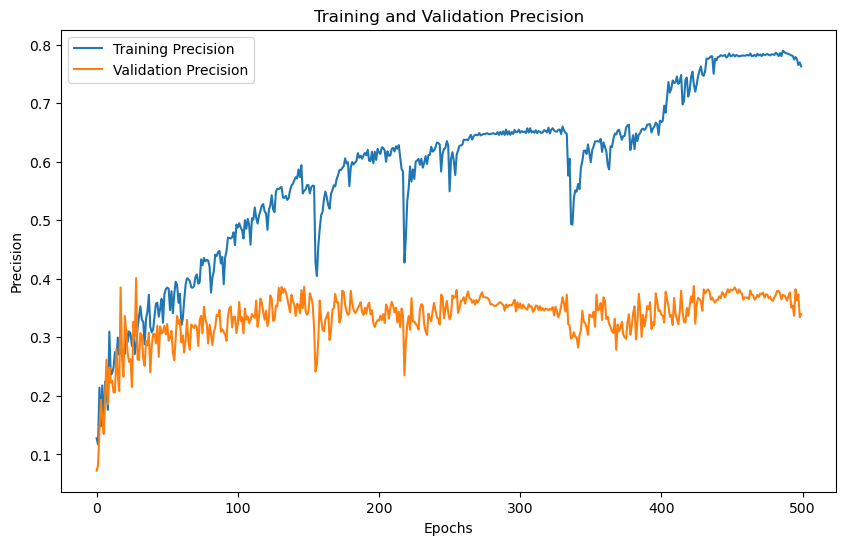

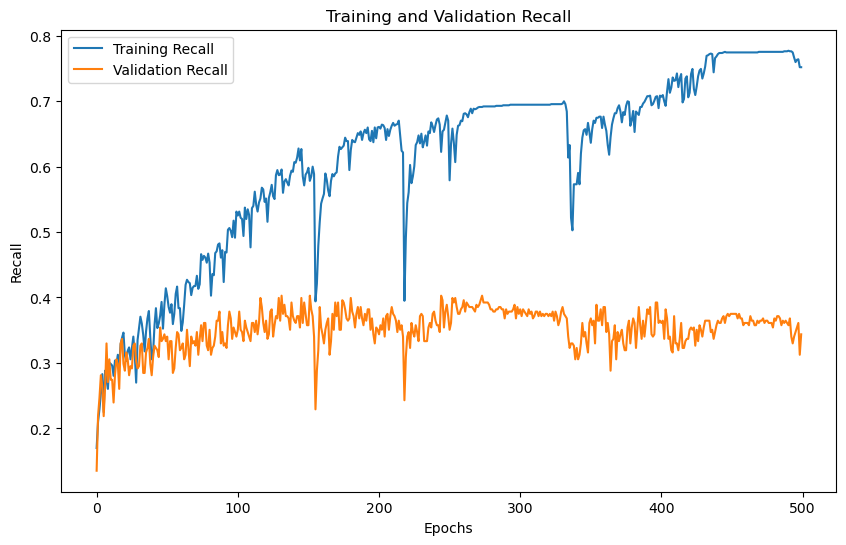

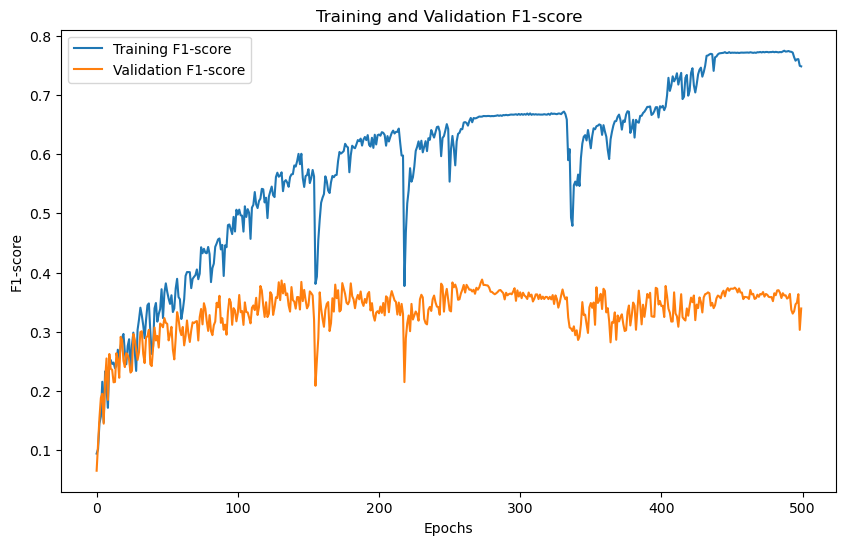

'Model Training and Evaluation Successfully completed'

In [25]:
train_model()

# crema

# dwt 1

# 500 epochs

Enter dataset name:
tess, savee, crema, ravdess
 crema
Enter dwt level:  1
Enter Number of MFCC coefficients : 40
No. of classes 6
Input size for wavelet level 1 = 1
Training with DWT level: 1
Hidden Size : 256
Model Name: LSTMModel

X Shape : (7442, 80, 1)
Y Shape : (7442, 6)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.7886, Training Accuracy: 0.1880, Training Precision:0.1159,Training Recall:0.1880,Training F1-Score:0.1238
Validation Loss: 1.7883, Validation Accuracy: 0.1941, Validation Precision:0.0959,Validation Recall:0.1941,Validation F1-Score:0.1252
Epoch [2/500],
Training Loss: 1.7834, Training Accuracy: 0.1910, Training Precision:0.1118,Training Recall:0.1910,Training F1-Score:0.1072
Validation Loss: 1.7897, Validation Accuracy: 0.1807, Validation Precision:0.1281,Validation Recall:0.1807,Validation F1-Score:0.0999
Epoch [3/500],
Training Loss: 1.7807, Training Accuracy: 0.2165, Training Precision:0.1555,Training Recall:0.2165,Training F1-Score:0.1478
Validation L

Epoch [30/500],
Training Loss: 1.6464, Training Accuracy: 0.3818, Training Precision:0.3671,Training Recall:0.3818,Training F1-Score:0.3371
Validation Loss: 1.6539, Validation Accuracy: 0.3700, Validation Precision:0.3213,Validation Recall:0.3700,Validation F1-Score:0.3252
Epoch [31/500],
Training Loss: 1.6491, Training Accuracy: 0.3835, Training Precision:0.2960,Training Recall:0.3835,Training F1-Score:0.3075
Validation Loss: 1.6575, Validation Accuracy: 0.3694, Validation Precision:0.4396,Validation Recall:0.3694,Validation F1-Score:0.2933
Epoch [32/500],
Training Loss: 1.6458, Training Accuracy: 0.3944, Training Precision:0.3402,Training Recall:0.3944,Training F1-Score:0.3305
Validation Loss: 1.6410, Validation Accuracy: 0.3909, Validation Precision:0.3630,Validation Recall:0.3909,Validation F1-Score:0.3307
Epoch [33/500],
Training Loss: 1.6659, Training Accuracy: 0.3815, Training Precision:0.2981,Training Recall:0.3815,Training F1-Score:0.3105
Validation Loss: 1.6587, Validation Ac

Epoch [60/500],
Training Loss: 1.6344, Training Accuracy: 0.4070, Training Precision:0.3711,Training Recall:0.4070,Training F1-Score:0.3578
Validation Loss: 1.6359, Validation Accuracy: 0.3969, Validation Precision:0.3445,Validation Recall:0.3969,Validation F1-Score:0.3467
Epoch [61/500],
Training Loss: 1.6310, Training Accuracy: 0.3974, Training Precision:0.3731,Training Recall:0.3974,Training F1-Score:0.3755
Validation Loss: 1.6392, Validation Accuracy: 0.3889, Validation Precision:0.3637,Validation Recall:0.3889,Validation F1-Score:0.3693
Epoch [62/500],
Training Loss: 1.6221, Training Accuracy: 0.4161, Training Precision:0.3955,Training Recall:0.4161,Training F1-Score:0.3746
Validation Loss: 1.6297, Validation Accuracy: 0.3996, Validation Precision:0.3666,Validation Recall:0.3996,Validation F1-Score:0.3614
Epoch [63/500],
Training Loss: 1.6214, Training Accuracy: 0.3983, Training Precision:0.3611,Training Recall:0.3983,Training F1-Score:0.3332
Validation Loss: 1.6529, Validation Ac

Epoch [90/500],
Training Loss: 1.6304, Training Accuracy: 0.3899, Training Precision:0.3764,Training Recall:0.3899,Training F1-Score:0.3555
Validation Loss: 1.6502, Validation Accuracy: 0.3680, Validation Precision:0.3232,Validation Recall:0.3680,Validation F1-Score:0.3261
Epoch [91/500],
Training Loss: 1.6323, Training Accuracy: 0.4141, Training Precision:0.3704,Training Recall:0.4141,Training F1-Score:0.3684
Validation Loss: 1.6475, Validation Accuracy: 0.3848, Validation Precision:0.3372,Validation Recall:0.3848,Validation F1-Score:0.3375
Epoch [92/500],
Training Loss: 1.6162, Training Accuracy: 0.4178, Training Precision:0.3909,Training Recall:0.4178,Training F1-Score:0.3796
Validation Loss: 1.6464, Validation Accuracy: 0.3821, Validation Precision:0.3480,Validation Recall:0.3821,Validation F1-Score:0.3439
Epoch [93/500],
Training Loss: 1.6201, Training Accuracy: 0.4062, Training Precision:0.3817,Training Recall:0.4062,Training F1-Score:0.3766
Validation Loss: 1.6450, Validation Ac

Epoch [120/500],
Training Loss: 1.5850, Training Accuracy: 0.4566, Training Precision:0.4378,Training Recall:0.4566,Training F1-Score:0.4326
Validation Loss: 1.6532, Validation Accuracy: 0.3734, Validation Precision:0.3397,Validation Recall:0.3734,Validation F1-Score:0.3425
Epoch [121/500],
Training Loss: 1.5798, Training Accuracy: 0.4690, Training Precision:0.4535,Training Recall:0.4690,Training F1-Score:0.4445
Validation Loss: 1.6368, Validation Accuracy: 0.3936, Validation Precision:0.3582,Validation Recall:0.3936,Validation F1-Score:0.3636
Epoch [122/500],
Training Loss: 1.5862, Training Accuracy: 0.4368, Training Precision:0.4184,Training Recall:0.4368,Training F1-Score:0.4136
Validation Loss: 1.6447, Validation Accuracy: 0.3808, Validation Precision:0.3484,Validation Recall:0.3808,Validation F1-Score:0.3512
Epoch [123/500],
Training Loss: 1.5816, Training Accuracy: 0.4520, Training Precision:0.4399,Training Recall:0.4520,Training F1-Score:0.4348
Validation Loss: 1.6447, Validatio

...

Epoch [360/500],
Training Loss: 1.4859, Training Accuracy: 0.5782, Training Precision:0.5790,Training Recall:0.5782,Training F1-Score:0.5711
Validation Loss: 1.6502, Validation Accuracy: 0.3862, Validation Precision:0.3722,Validation Recall:0.3862,Validation F1-Score:0.3734
Epoch [361/500],
Training Loss: 1.4728, Training Accuracy: 0.5765, Training Precision:0.5837,Training Recall:0.5765,Training F1-Score:0.5687
Validation Loss: 1.6495, Validation Accuracy: 0.3875, Validation Precision:0.3683,Validation Recall:0.3875,Validation F1-Score:0.3719
Epoch [362/500],
Training Loss: 1.4725, Training Accuracy: 0.5878, Training Precision:0.5898,Training Recall:0.5878,Training F1-Score:0.5808
Validation Loss: 1.6582, Validation Accuracy: 0.3754, Validation Precision:0.3565,Validation Recall:0.3754,Validation F1-Score:0.3608
Epoch [363/500],
Training Loss: 1.4793, Training Accuracy: 0.5160, Training Precision:0.5178,Training Recall:0.5160,Training F1-Score:0.5094
Validation Loss: 1.6665, Validatio

Epoch [390/500],
Training Loss: 1.4575, Training Accuracy: 0.6061, Training Precision:0.6120,Training Recall:0.6061,Training F1-Score:0.6030
Validation Loss: 1.6504, Validation Accuracy: 0.3855, Validation Precision:0.3789,Validation Recall:0.3855,Validation F1-Score:0.3794
Epoch [391/500],
Training Loss: 1.4399, Training Accuracy: 0.6244, Training Precision:0.6248,Training Recall:0.6244,Training F1-Score:0.6211
Validation Loss: 1.6566, Validation Accuracy: 0.3754, Validation Precision:0.3655,Validation Recall:0.3754,Validation F1-Score:0.3680
Epoch [392/500],
Training Loss: 1.4300, Training Accuracy: 0.6140, Training Precision:0.6198,Training Recall:0.6140,Training F1-Score:0.6087
Validation Loss: 1.6419, Validation Accuracy: 0.3962, Validation Precision:0.3807,Validation Recall:0.3962,Validation F1-Score:0.3804
Epoch [393/500],
Training Loss: 1.4367, Training Accuracy: 0.6210, Training Precision:0.6200,Training Recall:0.6210,Training F1-Score:0.6188
Validation Loss: 1.6565, Validatio

Epoch [420/500],
Training Loss: 1.4267, Training Accuracy: 0.6140, Training Precision:0.6221,Training Recall:0.6140,Training F1-Score:0.6112
Validation Loss: 1.6662, Validation Accuracy: 0.3700, Validation Precision:0.3589,Validation Recall:0.3700,Validation F1-Score:0.3588
Epoch [421/500],
Training Loss: 1.4353, Training Accuracy: 0.6140, Training Precision:0.6258,Training Recall:0.6140,Training F1-Score:0.6121
Validation Loss: 1.6616, Validation Accuracy: 0.3747, Validation Precision:0.3696,Validation Recall:0.3747,Validation F1-Score:0.3658
Epoch [422/500],
Training Loss: 1.4155, Training Accuracy: 0.6513, Training Precision:0.6527,Training Recall:0.6513,Training F1-Score:0.6488
Validation Loss: 1.6607, Validation Accuracy: 0.3794, Validation Precision:0.3691,Validation Recall:0.3794,Validation F1-Score:0.3715
Epoch [423/500],
Training Loss: 1.3972, Training Accuracy: 0.6365, Training Precision:0.6424,Training Recall:0.6365,Training F1-Score:0.6331
Validation Loss: 1.6547, Validatio

Epoch [450/500],
Training Loss: 1.4020, Training Accuracy: 0.6672, Training Precision:0.6730,Training Recall:0.6672,Training F1-Score:0.6648
Validation Loss: 1.6602, Validation Accuracy: 0.3747, Validation Precision:0.3598,Validation Recall:0.3747,Validation F1-Score:0.3640
Epoch [451/500],
Training Loss: 1.3781, Training Accuracy: 0.6687, Training Precision:0.6717,Training Recall:0.6687,Training F1-Score:0.6676
Validation Loss: 1.6792, Validation Accuracy: 0.3593, Validation Precision:0.3519,Validation Recall:0.3593,Validation F1-Score:0.3533
Epoch [452/500],
Training Loss: 1.3627, Training Accuracy: 0.6970, Training Precision:0.7021,Training Recall:0.6970,Training F1-Score:0.6951
Validation Loss: 1.6539, Validation Accuracy: 0.3848, Validation Precision:0.3718,Validation Recall:0.3848,Validation F1-Score:0.3713
Epoch [453/500],
Training Loss: 1.3565, Training Accuracy: 0.6571, Training Precision:0.6616,Training Recall:0.6571,Training F1-Score:0.6546
Validation Loss: 1.6774, Validatio

Epoch [480/500],
Training Loss: 1.5799, Training Accuracy: 0.5001, Training Precision:0.5141,Training Recall:0.5001,Training F1-Score:0.4730
Validation Loss: 1.6991, Validation Accuracy: 0.3412, Validation Precision:0.3200,Validation Recall:0.3412,Validation F1-Score:0.3068
Epoch [481/500],
Training Loss: 1.6372, Training Accuracy: 0.4022, Training Precision:0.4070,Training Recall:0.4022,Training F1-Score:0.3646
Validation Loss: 1.7280, Validation Accuracy: 0.3123, Validation Precision:0.2995,Validation Recall:0.3123,Validation F1-Score:0.2738
Epoch [482/500],
Training Loss: 1.6497, Training Accuracy: 0.3966, Training Precision:0.3911,Training Recall:0.3966,Training F1-Score:0.3754
Validation Loss: 1.7234, Validation Accuracy: 0.3130, Validation Precision:0.2943,Validation Recall:0.3130,Validation F1-Score:0.2879
Epoch [483/500],
Training Loss: 1.6985, Training Accuracy: 0.3642, Training Precision:0.3891,Training Recall:0.3642,Training F1-Score:0.3326
Validation Loss: 1.7431, Validatio

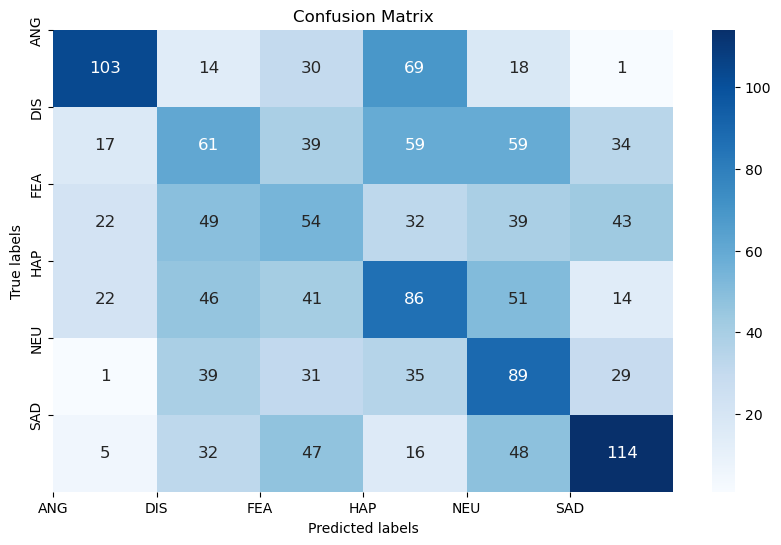

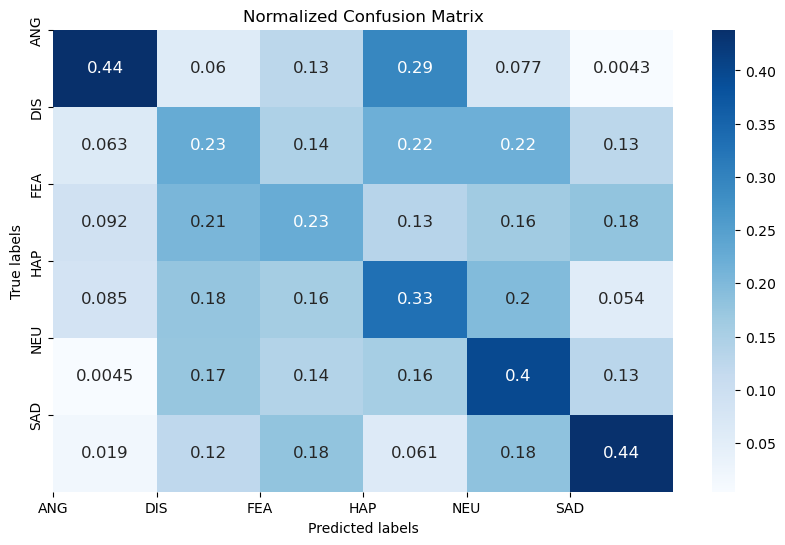

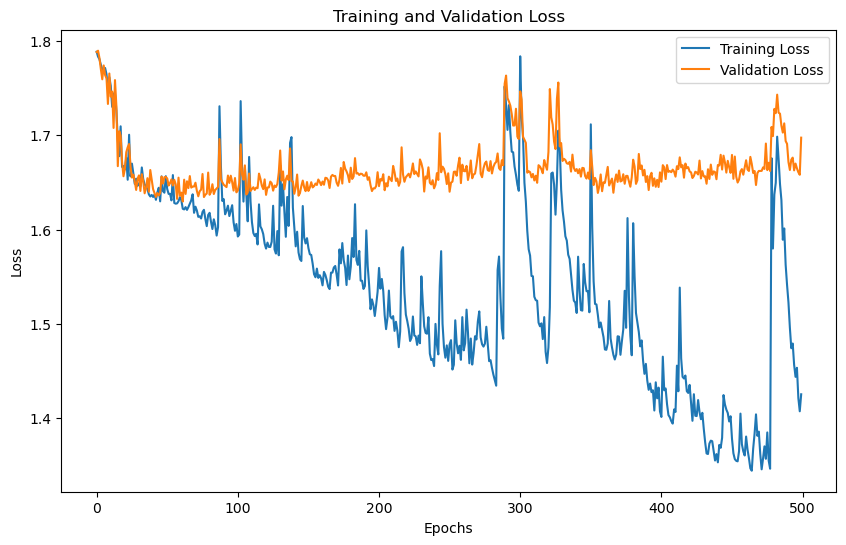

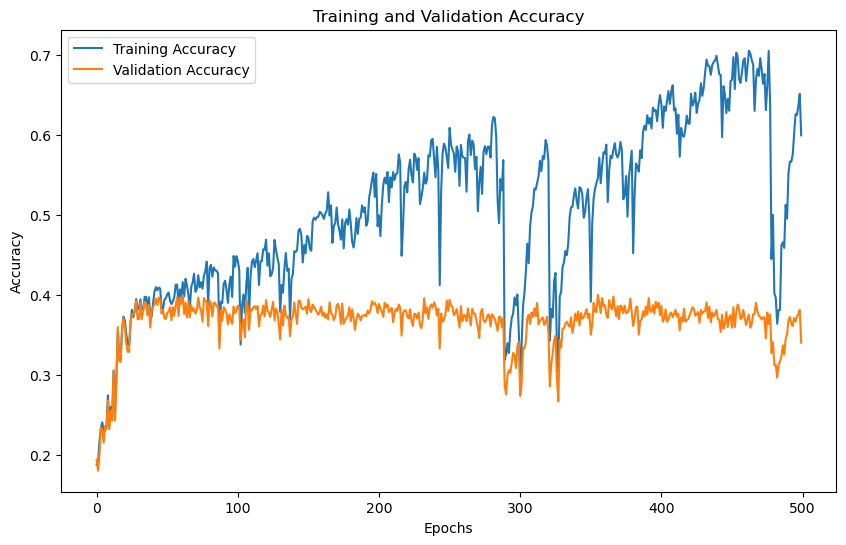

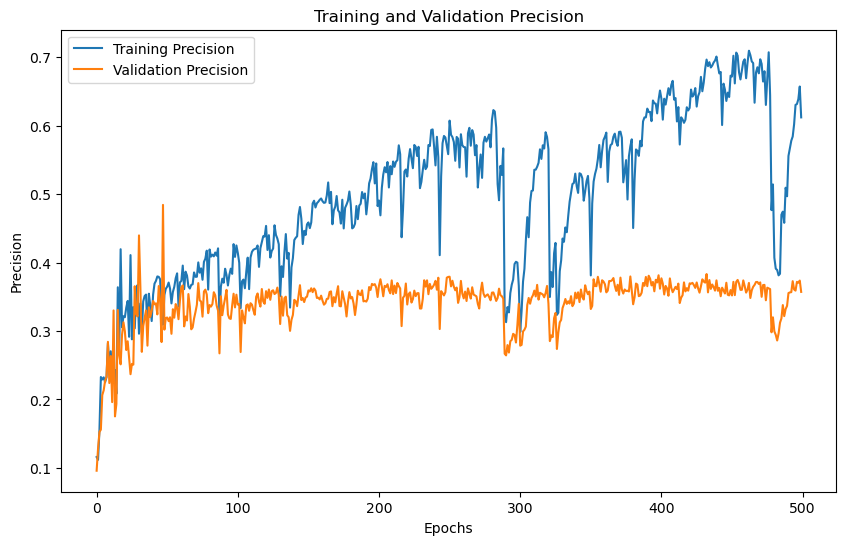

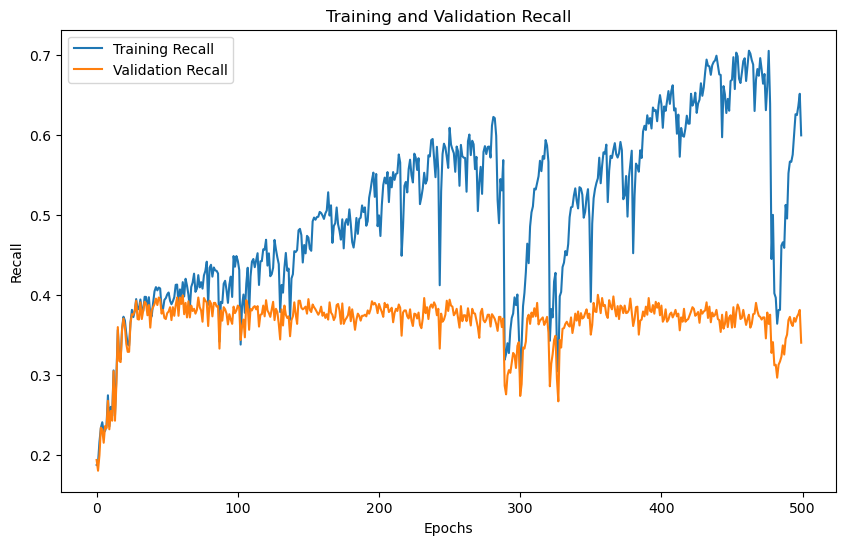

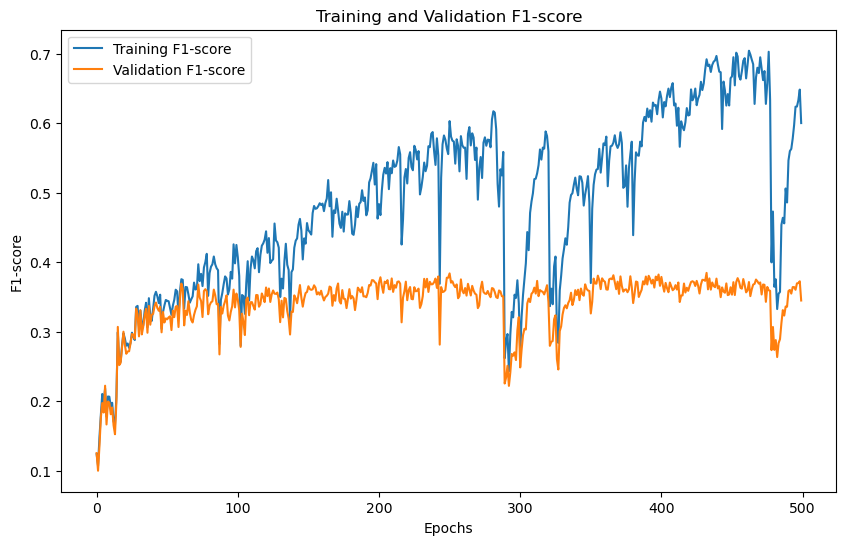

'Model Training and Evaluation Successfully completed'

In [13]:
train_model()

# dwt 2
# 500 epochs

Enter dataset name:
tess, savee, crema, ravdess
 crema
Enter dwt level:  2
No. of classes 6
Input size : 1
Hidden Size : 256
Model Name: LSTMModel

X Shape : (7442, 120, 1)
Y Shape : (7442, 6)
Training with DWT level: 2
Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.7900, Training Accuracy: 0.2034, Training Precision:0.1695,Training Recall:0.2034,Training F1-Score:0.1600
Validation Loss: 1.7865, Validation Accuracy: 0.1941, Validation Precision:0.1553,Validation Recall:0.1941,Validation F1-Score:0.1491
Epoch [2/500],
Training Loss: 1.7387, Training Accuracy: 0.1801, Training Precision:0.0752,Training Recall:0.1801,Training F1-Score:0.0699
Validation Loss: 1.8333, Validation Accuracy: 0.1887, Validation Precision:0.1046,Validation Recall:0.1887,Validation F1-Score:0.0772
Epoch [3/500],
Training Loss: 1.7443, Training Accuracy: 0.3225, Training Precision:0.3808,Training Recall:0.3225,Training F1-Score:0.2056
Validation Loss: 1.7028, Validation Accuracy: 0.3190, Validation Precis

Epoch [31/500],
Training Loss: 1.6485, Training Accuracy: 0.3855, Training Precision:0.2831,Training Recall:0.3855,Training F1-Score:0.3052
Validation Loss: 1.6375, Validation Accuracy: 0.3942, Validation Precision:0.3321,Validation Recall:0.3942,Validation F1-Score:0.3144
Epoch [32/500],
Training Loss: 1.6452, Training Accuracy: 0.3630, Training Precision:0.2837,Training Recall:0.3630,Training F1-Score:0.2969
Validation Loss: 1.6579, Validation Accuracy: 0.3741, Validation Precision:0.2964,Validation Recall:0.3741,Validation F1-Score:0.3072
Epoch [33/500],
Training Loss: 1.6781, Training Accuracy: 0.3617, Training Precision:0.2842,Training Recall:0.3617,Training F1-Score:0.3022
Validation Loss: 1.6526, Validation Accuracy: 0.3680, Validation Precision:0.2929,Validation Recall:0.3680,Validation F1-Score:0.3068
Epoch [34/500],
Training Loss: 1.6507, Training Accuracy: 0.3796, Training Precision:0.2942,Training Recall:0.3796,Training F1-Score:0.3129
Validation Loss: 1.6393, Validation Ac

Epoch [61/500],
Training Loss: 1.6545, Training Accuracy: 0.3889, Training Precision:0.3055,Training Recall:0.3889,Training F1-Score:0.3223
Validation Loss: 1.6386, Validation Accuracy: 0.3922, Validation Precision:0.3055,Validation Recall:0.3922,Validation F1-Score:0.3278
Epoch [62/500],
Training Loss: 1.6404, Training Accuracy: 0.3959, Training Precision:0.3085,Training Recall:0.3959,Training F1-Score:0.3275
Validation Loss: 1.6353, Validation Accuracy: 0.3956, Validation Precision:0.3011,Validation Recall:0.3956,Validation F1-Score:0.3290
Epoch [63/500],
Training Loss: 1.6364, Training Accuracy: 0.3854, Training Precision:0.2915,Training Recall:0.3854,Training F1-Score:0.3190
Validation Loss: 1.6382, Validation Accuracy: 0.3875, Validation Precision:0.2904,Validation Recall:0.3875,Validation F1-Score:0.3208
Epoch [64/500],
Training Loss: 1.6552, Training Accuracy: 0.3845, Training Precision:0.2866,Training Recall:0.3845,Training F1-Score:0.3109
Validation Loss: 1.6393, Validation Ac

Epoch [91/500],
Training Loss: 1.6497, Training Accuracy: 0.3465, Training Precision:0.3208,Training Recall:0.3465,Training F1-Score:0.2724
Validation Loss: 1.6880, Validation Accuracy: 0.3392, Validation Precision:0.2399,Validation Recall:0.3392,Validation F1-Score:0.2634
Epoch [92/500],
Training Loss: 1.7244, Training Accuracy: 0.3237, Training Precision:0.2878,Training Recall:0.3237,Training F1-Score:0.2583
Validation Loss: 1.6830, Validation Accuracy: 0.3385, Validation Precision:0.3086,Validation Recall:0.3385,Validation F1-Score:0.2792
Epoch [93/500],
Training Loss: 1.7192, Training Accuracy: 0.3513, Training Precision:0.2969,Training Recall:0.3513,Training F1-Score:0.2992
Validation Loss: 1.6717, Validation Accuracy: 0.3479, Validation Precision:0.3091,Validation Recall:0.3479,Validation F1-Score:0.2956
Epoch [94/500],
Training Loss: 1.6563, Training Accuracy: 0.3796, Training Precision:0.3380,Training Recall:0.3796,Training F1-Score:0.3108
Validation Loss: 1.6475, Validation Ac

Epoch [121/500],
Training Loss: 1.7136, Training Accuracy: 0.3649, Training Precision:0.3271,Training Recall:0.3649,Training F1-Score:0.2913
Validation Loss: 1.6732, Validation Accuracy: 0.3593, Validation Precision:0.3294,Validation Recall:0.3593,Validation F1-Score:0.2872
Epoch [122/500],
Training Loss: 1.6510, Training Accuracy: 0.3780, Training Precision:0.3992,Training Recall:0.3780,Training F1-Score:0.2994
Validation Loss: 1.6540, Validation Accuracy: 0.3734, Validation Precision:0.2729,Validation Recall:0.3734,Validation F1-Score:0.2936
Epoch [123/500],
Training Loss: 1.6468, Training Accuracy: 0.3948, Training Precision:0.3347,Training Recall:0.3948,Training F1-Score:0.3207
Validation Loss: 1.6477, Validation Accuracy: 0.3788, Validation Precision:0.2786,Validation Recall:0.3788,Validation F1-Score:0.3057
Epoch [124/500],
Training Loss: 1.6394, Training Accuracy: 0.3860, Training Precision:0.3383,Training Recall:0.3860,Training F1-Score:0.3185
Validation Loss: 1.6486, Validatio

...

Epoch [361/500],
Training Loss: 1.5222, Training Accuracy: 0.5134, Training Precision:0.5031,Training Recall:0.5134,Training F1-Score:0.4969
Validation Loss: 1.6318, Validation Accuracy: 0.4077, Validation Precision:0.3829,Validation Recall:0.4077,Validation F1-Score:0.3888
Epoch [362/500],
Training Loss: 1.5534, Training Accuracy: 0.5061, Training Precision:0.5010,Training Recall:0.5061,Training F1-Score:0.4853
Validation Loss: 1.6471, Validation Accuracy: 0.3842, Validation Precision:0.3660,Validation Recall:0.3842,Validation F1-Score:0.3662
Epoch [363/500],
Training Loss: 1.5969, Training Accuracy: 0.4796, Training Precision:0.4754,Training Recall:0.4796,Training F1-Score:0.4666
Validation Loss: 1.6457, Validation Accuracy: 0.3875, Validation Precision:0.3701,Validation Recall:0.3875,Validation F1-Score:0.3726
Epoch [364/500],
Training Loss: 1.5727, Training Accuracy: 0.4870, Training Precision:0.4701,Training Recall:0.4870,Training F1-Score:0.4717
Validation Loss: 1.6417, Validatio

Epoch [391/500],
Training Loss: 1.4850, Training Accuracy: 0.5515, Training Precision:0.5455,Training Recall:0.5515,Training F1-Score:0.5444
Validation Loss: 1.6527, Validation Accuracy: 0.3828, Validation Precision:0.3745,Validation Recall:0.3828,Validation F1-Score:0.3755
Epoch [392/500],
Training Loss: 1.4854, Training Accuracy: 0.5770, Training Precision:0.5747,Training Recall:0.5770,Training F1-Score:0.5674
Validation Loss: 1.6337, Validation Accuracy: 0.3983, Validation Precision:0.3776,Validation Recall:0.3983,Validation F1-Score:0.3839
Epoch [393/500],
Training Loss: 1.4769, Training Accuracy: 0.5648, Training Precision:0.5633,Training Recall:0.5648,Training F1-Score:0.5560
Validation Loss: 1.6301, Validation Accuracy: 0.4056, Validation Precision:0.3848,Validation Recall:0.4056,Validation F1-Score:0.3898
Epoch [394/500],
Training Loss: 1.4713, Training Accuracy: 0.5752, Training Precision:0.5737,Training Recall:0.5752,Training F1-Score:0.5671
Validation Loss: 1.6341, Validatio

Epoch [421/500],
Training Loss: 1.4911, Training Accuracy: 0.5626, Training Precision:0.5663,Training Recall:0.5626,Training F1-Score:0.5517
Validation Loss: 1.6344, Validation Accuracy: 0.4023, Validation Precision:0.3799,Validation Recall:0.4023,Validation F1-Score:0.3822
Epoch [422/500],
Training Loss: 1.4817, Training Accuracy: 0.5701, Training Precision:0.5678,Training Recall:0.5701,Training F1-Score:0.5635
Validation Loss: 1.6419, Validation Accuracy: 0.3889, Validation Precision:0.3707,Validation Recall:0.3889,Validation F1-Score:0.3758
Epoch [423/500],
Training Loss: 1.4870, Training Accuracy: 0.4947, Training Precision:0.4957,Training Recall:0.4947,Training F1-Score:0.4914
Validation Loss: 1.6349, Validation Accuracy: 0.4023, Validation Precision:0.3983,Validation Recall:0.4023,Validation F1-Score:0.3968
Epoch [424/500],
Training Loss: 1.5196, Training Accuracy: 0.5658, Training Precision:0.5634,Training Recall:0.5658,Training F1-Score:0.5581
Validation Loss: 1.6370, Validatio

Epoch [451/500],
Training Loss: 1.5363, Training Accuracy: 0.5554, Training Precision:0.5545,Training Recall:0.5554,Training F1-Score:0.5507
Validation Loss: 1.6466, Validation Accuracy: 0.3895, Validation Precision:0.3831,Validation Recall:0.3895,Validation F1-Score:0.3845
Epoch [452/500],
Training Loss: 1.4874, Training Accuracy: 0.5690, Training Precision:0.5720,Training Recall:0.5690,Training F1-Score:0.5609
Validation Loss: 1.6278, Validation Accuracy: 0.4056, Validation Precision:0.3933,Validation Recall:0.4056,Validation F1-Score:0.3932
Epoch [453/500],
Training Loss: 1.4679, Training Accuracy: 0.5595, Training Precision:0.5580,Training Recall:0.5595,Training F1-Score:0.5508
Validation Loss: 1.6390, Validation Accuracy: 0.3942, Validation Precision:0.3742,Validation Recall:0.3942,Validation F1-Score:0.3775
Epoch [454/500],
Training Loss: 1.4717, Training Accuracy: 0.6000, Training Precision:0.6016,Training Recall:0.6000,Training F1-Score:0.5961
Validation Loss: 1.6387, Validatio

Epoch [481/500],
Training Loss: 1.4629, Training Accuracy: 0.5752, Training Precision:0.5744,Training Recall:0.5752,Training F1-Score:0.5661
Validation Loss: 1.6342, Validation Accuracy: 0.3996, Validation Precision:0.3721,Validation Recall:0.3996,Validation F1-Score:0.3800
Epoch [482/500],
Training Loss: 1.4662, Training Accuracy: 0.5824, Training Precision:0.5820,Training Recall:0.5824,Training F1-Score:0.5793
Validation Loss: 1.6528, Validation Accuracy: 0.3842, Validation Precision:0.3787,Validation Recall:0.3842,Validation F1-Score:0.3802
Epoch [483/500],
Training Loss: 1.4679, Training Accuracy: 0.5643, Training Precision:0.5658,Training Recall:0.5643,Training F1-Score:0.5573
Validation Loss: 1.6367, Validation Accuracy: 0.3976, Validation Precision:0.3828,Validation Recall:0.3976,Validation F1-Score:0.3871
Epoch [484/500],
Training Loss: 1.4649, Training Accuracy: 0.6007, Training Precision:0.6011,Training Recall:0.6007,Training F1-Score:0.5940
Validation Loss: 1.6362, Validatio

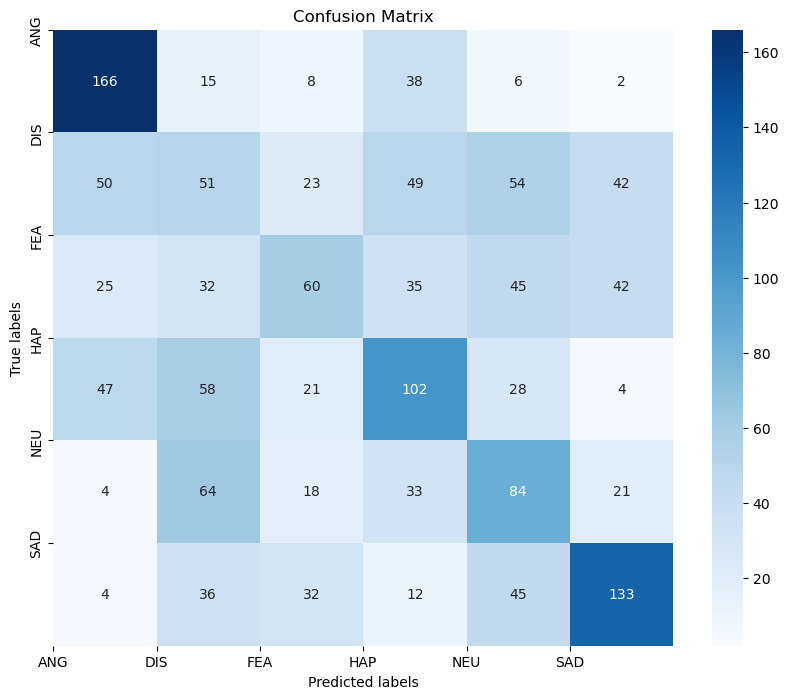

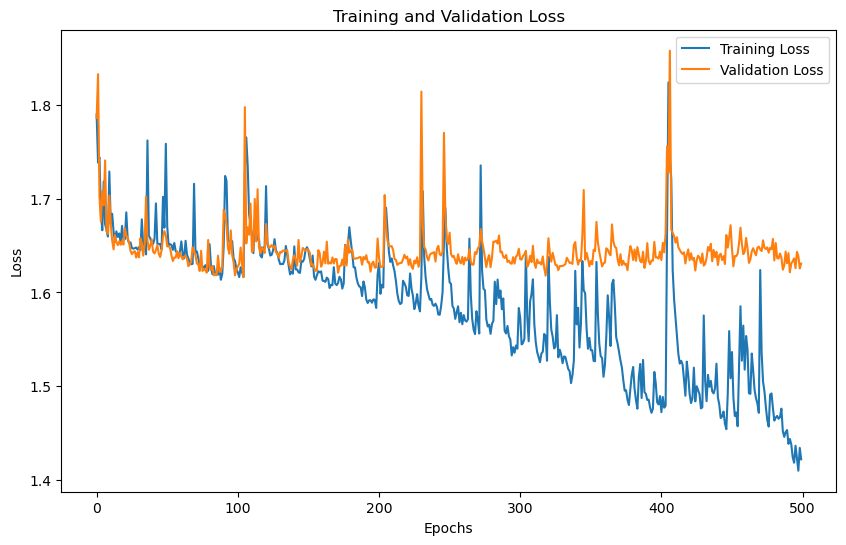

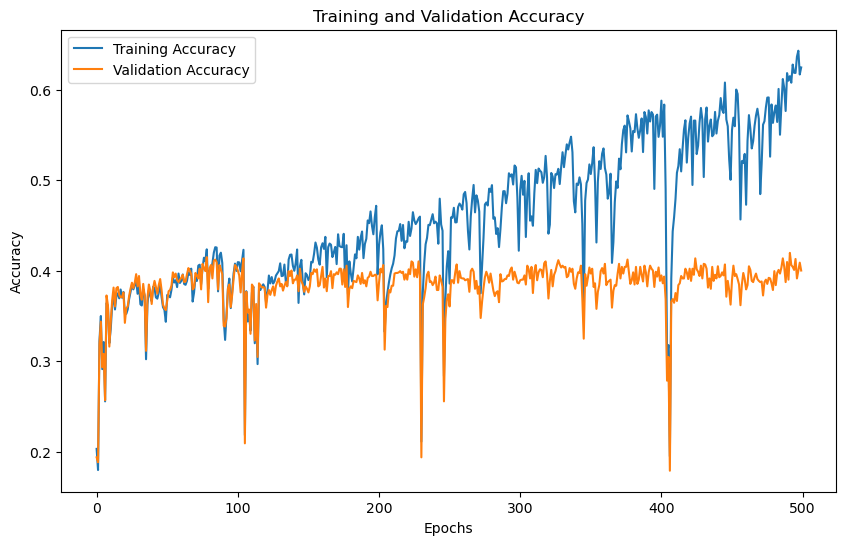

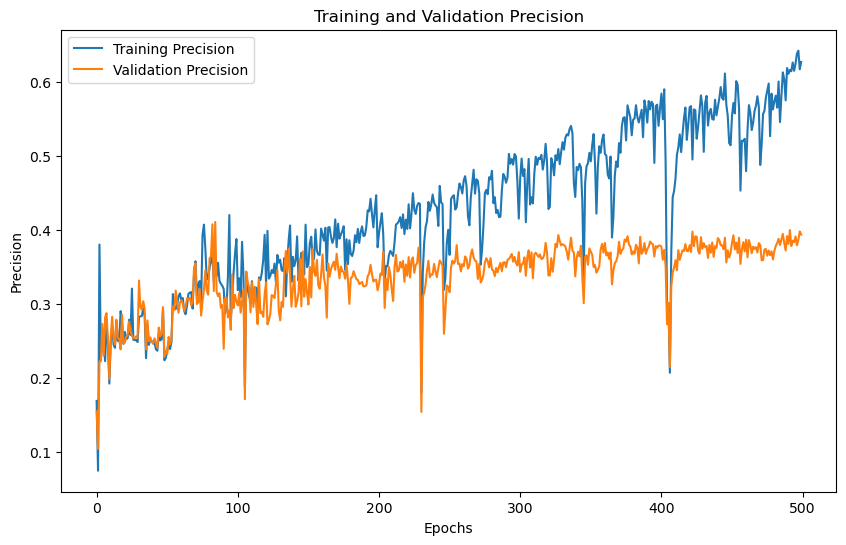

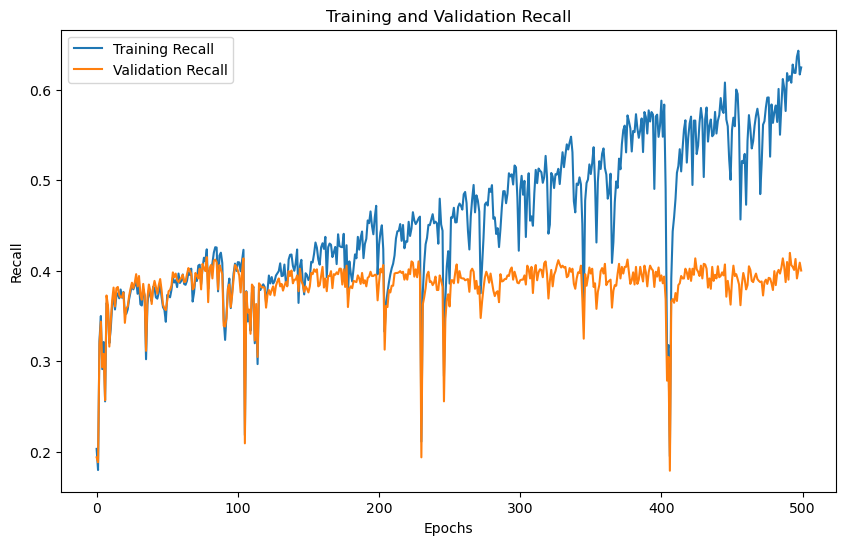

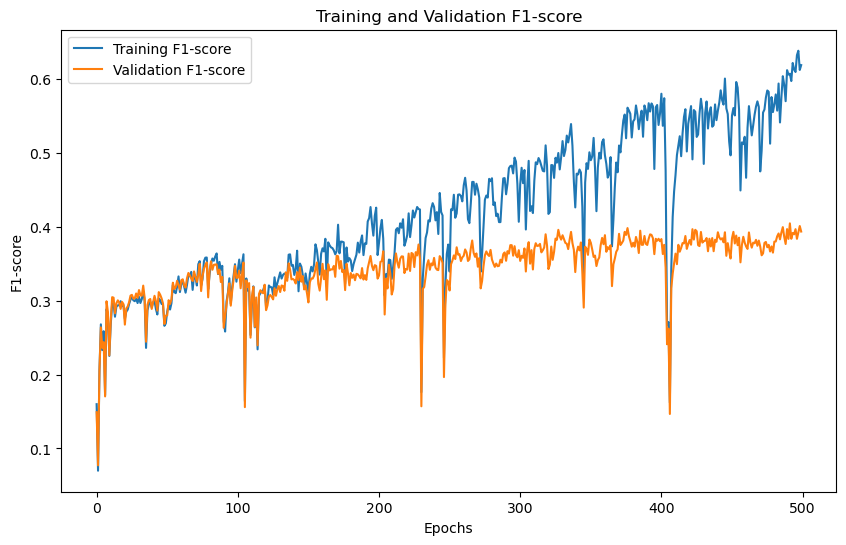

'Model Training and Evaluation Successfully completed'

In [27]:
train_model()

# dwt 3

# 500 epochs

In [ ]:
train_model()

Enter dataset name:
tess, savee, crema, ravdess
 crema
Enter dwt level:  3


# dwt 4

# 500 epochs

Enter dataset name:
tess, savee, crema, ravdess
 crema
Enter dwt level:  4
No. of classes 6
Input size : 1
Hidden Size : 256
Model Name: LSTMModel

X Shape : (7442, 200, 1)
Y Shape : (7442, 6)
Training with DWT level: 4
Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.7905, Training Accuracy: 0.1942, Training Precision:0.1637,Training Recall:0.1942,Training F1-Score:0.1522
Validation Loss: 1.7880, Validation Accuracy: 0.1807, Validation Precision:0.1450,Validation Recall:0.1807,Validation F1-Score:0.1328
Epoch [2/500],
Training Loss: 1.7849, Training Accuracy: 0.2115, Training Precision:0.1374,Training Recall:0.2115,Training F1-Score:0.1352
Validation Loss: 1.7816, Validation Accuracy: 0.2035, Validation Precision:0.2007,Validation Recall:0.2035,Validation F1-Score:0.1326
Epoch [3/500],
Training Loss: 1.7895, Training Accuracy: 0.1860, Training Precision:0.1045,Training Recall:0.1860,Training F1-Score:0.1213
Validation Loss: 1.7897, Validation Accuracy: 0.1813, Validation Precis

Epoch [31/500],
Training Loss: 1.6585, Training Accuracy: 0.3812, Training Precision:0.2834,Training Recall:0.3812,Training F1-Score:0.3019
Validation Loss: 1.6429, Validation Accuracy: 0.3909, Validation Precision:0.2848,Validation Recall:0.3909,Validation F1-Score:0.3096
Epoch [32/500],
Training Loss: 1.6586, Training Accuracy: 0.3746, Training Precision:0.3474,Training Recall:0.3746,Training F1-Score:0.2939
Validation Loss: 1.6529, Validation Accuracy: 0.3754, Validation Precision:0.3937,Validation Recall:0.3754,Validation F1-Score:0.2969
Epoch [33/500],
Training Loss: 1.6625, Training Accuracy: 0.3838, Training Precision:0.3401,Training Recall:0.3838,Training F1-Score:0.3170
Validation Loss: 1.6461, Validation Accuracy: 0.3828, Validation Precision:0.3365,Validation Recall:0.3828,Validation F1-Score:0.3183
Epoch [34/500],
Training Loss: 1.6529, Training Accuracy: 0.3687, Training Precision:0.2970,Training Recall:0.3687,Training F1-Score:0.3254
Validation Loss: 1.6499, Validation Ac

Epoch [61/500],
Training Loss: 1.6565, Training Accuracy: 0.3697, Training Precision:0.3271,Training Recall:0.3697,Training F1-Score:0.2998
Validation Loss: 1.6483, Validation Accuracy: 0.3647, Validation Precision:0.2936,Validation Recall:0.3647,Validation F1-Score:0.2867
Epoch [62/500],
Training Loss: 1.6500, Training Accuracy: 0.3571, Training Precision:0.3347,Training Recall:0.3571,Training F1-Score:0.2949
Validation Loss: 1.6697, Validation Accuracy: 0.3526, Validation Precision:0.3239,Validation Recall:0.3526,Validation F1-Score:0.2890
Epoch [63/500],
Training Loss: 1.6605, Training Accuracy: 0.3722, Training Precision:0.3362,Training Recall:0.3722,Training F1-Score:0.3273
Validation Loss: 1.6490, Validation Accuracy: 0.3734, Validation Precision:0.3364,Validation Recall:0.3734,Validation F1-Score:0.3280
Epoch [64/500],
Training Loss: 1.6528, Training Accuracy: 0.3890, Training Precision:0.3474,Training Recall:0.3890,Training F1-Score:0.3420
Validation Loss: 1.6403, Validation Ac

Epoch [91/500],
Training Loss: 1.6213, Training Accuracy: 0.4183, Training Precision:0.4058,Training Recall:0.4183,Training F1-Score:0.3919
Validation Loss: 1.6319, Validation Accuracy: 0.3848, Validation Precision:0.3616,Validation Recall:0.3848,Validation F1-Score:0.3589
Epoch [92/500],
Training Loss: 1.6137, Training Accuracy: 0.4053, Training Precision:0.3911,Training Recall:0.4053,Training F1-Score:0.3704
Validation Loss: 1.6361, Validation Accuracy: 0.3942, Validation Precision:0.3754,Validation Recall:0.3942,Validation F1-Score:0.3570
Epoch [93/500],
Training Loss: 1.6224, Training Accuracy: 0.4198, Training Precision:0.4117,Training Recall:0.4198,Training F1-Score:0.3964
Validation Loss: 1.6348, Validation Accuracy: 0.3956, Validation Precision:0.3812,Validation Recall:0.3956,Validation F1-Score:0.3681
Epoch [94/500],
Training Loss: 1.6182, Training Accuracy: 0.4097, Training Precision:0.4254,Training Recall:0.4097,Training F1-Score:0.3842
Validation Loss: 1.6395, Validation Ac

Epoch [121/500],
Training Loss: 1.6444, Training Accuracy: 0.3919, Training Precision:0.4003,Training Recall:0.3919,Training F1-Score:0.3483
Validation Loss: 1.6370, Validation Accuracy: 0.3929, Validation Precision:0.3614,Validation Recall:0.3929,Validation F1-Score:0.3458
Epoch [122/500],
Training Loss: 1.6531, Training Accuracy: 0.3780, Training Precision:0.3680,Training Recall:0.3780,Training F1-Score:0.3482
Validation Loss: 1.6474, Validation Accuracy: 0.3674, Validation Precision:0.3545,Validation Recall:0.3674,Validation F1-Score:0.3414
Epoch [123/500],
Training Loss: 1.6506, Training Accuracy: 0.3840, Training Precision:0.3569,Training Recall:0.3840,Training F1-Score:0.3463
Validation Loss: 1.6545, Validation Accuracy: 0.3747, Validation Precision:0.3496,Validation Recall:0.3747,Validation F1-Score:0.3400
Epoch [124/500],
Training Loss: 1.6452, Training Accuracy: 0.3675, Training Precision:0.3798,Training Recall:0.3675,Training F1-Score:0.3583
Validation Loss: 1.6568, Validatio

...

Epoch [361/500],
Training Loss: 1.4778, Training Accuracy: 0.6143, Training Precision:0.6214,Training Recall:0.6143,Training F1-Score:0.6104
Validation Loss: 1.6497, Validation Accuracy: 0.3895, Validation Precision:0.3879,Validation Recall:0.3895,Validation F1-Score:0.3825
Epoch [362/500],
Training Loss: 1.4008, Training Accuracy: 0.6773, Training Precision:0.6882,Training Recall:0.6773,Training F1-Score:0.6714
Validation Loss: 1.6338, Validation Accuracy: 0.4056, Validation Precision:0.3924,Validation Recall:0.4056,Validation F1-Score:0.3878
Epoch [363/500],
Training Loss: 1.3482, Training Accuracy: 0.7178, Training Precision:0.7166,Training Recall:0.7178,Training F1-Score:0.7164
Validation Loss: 1.6398, Validation Accuracy: 0.3983, Validation Precision:0.3917,Validation Recall:0.3983,Validation F1-Score:0.3943
Epoch [364/500],
Training Loss: 1.3238, Training Accuracy: 0.7369, Training Precision:0.7398,Training Recall:0.7369,Training F1-Score:0.7349
Validation Loss: 1.6507, Validatio

Epoch [391/500],
Training Loss: 1.2583, Training Accuracy: 0.7882, Training Precision:0.7922,Training Recall:0.7882,Training F1-Score:0.7872
Validation Loss: 1.6397, Validation Accuracy: 0.3956, Validation Precision:0.3838,Validation Recall:0.3956,Validation F1-Score:0.3857
Epoch [392/500],
Training Loss: 1.2702, Training Accuracy: 0.7677, Training Precision:0.7708,Training Recall:0.7677,Training F1-Score:0.7667
Validation Loss: 1.6346, Validation Accuracy: 0.4056, Validation Precision:0.3955,Validation Recall:0.4056,Validation F1-Score:0.3990
Epoch [393/500],
Training Loss: 1.2687, Training Accuracy: 0.7863, Training Precision:0.7871,Training Recall:0.7863,Training F1-Score:0.7852
Validation Loss: 1.6460, Validation Accuracy: 0.3909, Validation Precision:0.3852,Validation Recall:0.3909,Validation F1-Score:0.3873
Epoch [394/500],
Training Loss: 1.2568, Training Accuracy: 0.7774, Training Precision:0.7815,Training Recall:0.7774,Training F1-Score:0.7761
Validation Loss: 1.6388, Validatio

Epoch [421/500],
Training Loss: 1.2472, Training Accuracy: 0.7981, Training Precision:0.8010,Training Recall:0.7981,Training F1-Score:0.7975
Validation Loss: 1.6397, Validation Accuracy: 0.3989, Validation Precision:0.3900,Validation Recall:0.3989,Validation F1-Score:0.3929
Epoch [422/500],
Training Loss: 1.2506, Training Accuracy: 0.8014, Training Precision:0.8042,Training Recall:0.8014,Training F1-Score:0.8007
Validation Loss: 1.6402, Validation Accuracy: 0.3962, Validation Precision:0.3910,Validation Recall:0.3962,Validation F1-Score:0.3928
Epoch [423/500],
Training Loss: 1.2508, Training Accuracy: 0.7984, Training Precision:0.8003,Training Recall:0.7984,Training F1-Score:0.7976
Validation Loss: 1.6280, Validation Accuracy: 0.4130, Validation Precision:0.4091,Validation Recall:0.4130,Validation F1-Score:0.4100
Epoch [424/500],
Training Loss: 1.2498, Training Accuracy: 0.7875, Training Precision:0.7888,Training Recall:0.7875,Training F1-Score:0.7869
Validation Loss: 1.6505, Validatio

Epoch [451/500],
Training Loss: 1.2494, Training Accuracy: 0.7868, Training Precision:0.7928,Training Recall:0.7868,Training F1-Score:0.7858
Validation Loss: 1.6410, Validation Accuracy: 0.3983, Validation Precision:0.3834,Validation Recall:0.3983,Validation F1-Score:0.3863
Epoch [452/500],
Training Loss: 1.2495, Training Accuracy: 0.8003, Training Precision:0.8021,Training Recall:0.8003,Training F1-Score:0.8000
Validation Loss: 1.6530, Validation Accuracy: 0.3821, Validation Precision:0.3831,Validation Recall:0.3821,Validation F1-Score:0.3814
Epoch [453/500],
Training Loss: 1.2483, Training Accuracy: 0.8014, Training Precision:0.8016,Training Recall:0.8014,Training F1-Score:0.8008
Validation Loss: 1.6451, Validation Accuracy: 0.3909, Validation Precision:0.3846,Validation Recall:0.3909,Validation F1-Score:0.3873
Epoch [454/500],
Training Loss: 1.2394, Training Accuracy: 0.8085, Training Precision:0.8113,Training Recall:0.8085,Training F1-Score:0.8079
Validation Loss: 1.6444, Validatio

Epoch [481/500],
Training Loss: 1.2226, Training Accuracy: 0.8213, Training Precision:0.8227,Training Recall:0.8213,Training F1-Score:0.8208
Validation Loss: 1.6485, Validation Accuracy: 0.3902, Validation Precision:0.3872,Validation Recall:0.3902,Validation F1-Score:0.3881
Epoch [482/500],
Training Loss: 1.2261, Training Accuracy: 0.8248, Training Precision:0.8258,Training Recall:0.8248,Training F1-Score:0.8242
Validation Loss: 1.6511, Validation Accuracy: 0.3882, Validation Precision:0.3842,Validation Recall:0.3882,Validation F1-Score:0.3852
Epoch [483/500],
Training Loss: 1.2282, Training Accuracy: 0.8187, Training Precision:0.8199,Training Recall:0.8187,Training F1-Score:0.8183
Validation Loss: 1.6527, Validation Accuracy: 0.3862, Validation Precision:0.3837,Validation Recall:0.3862,Validation F1-Score:0.3845
Epoch [484/500],
Training Loss: 1.2275, Training Accuracy: 0.8226, Training Precision:0.8236,Training Recall:0.8226,Training F1-Score:0.8220
Validation Loss: 1.6392, Validatio

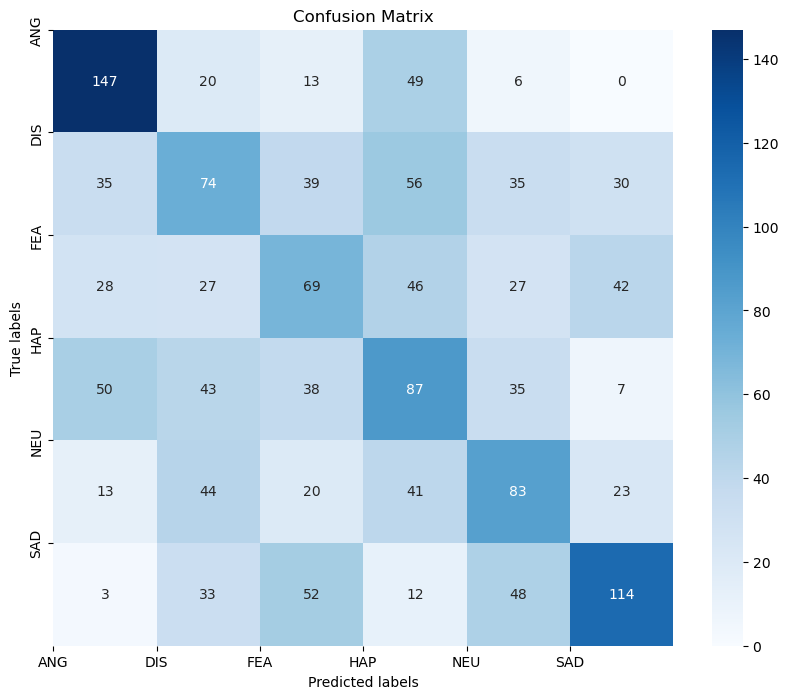

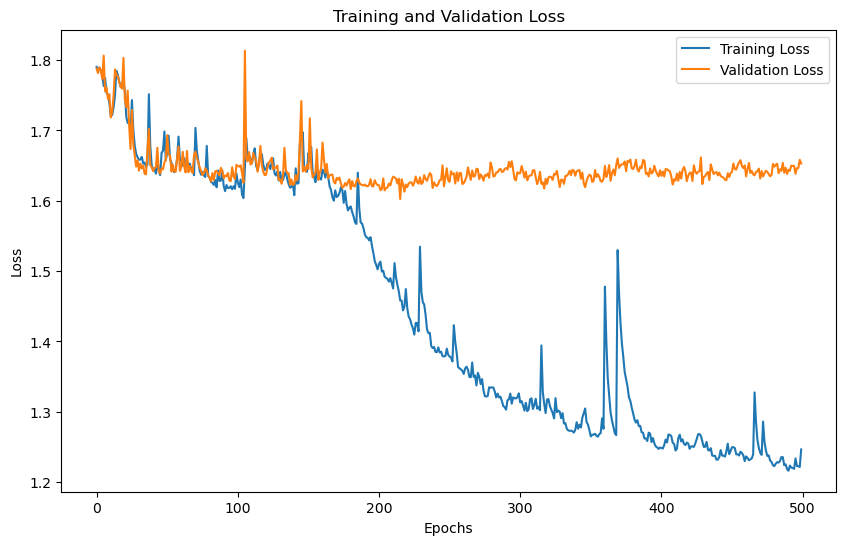

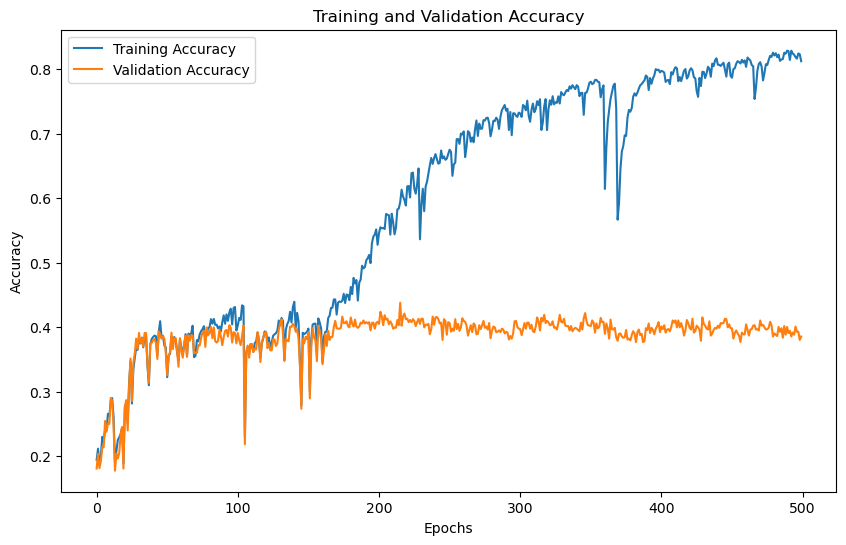

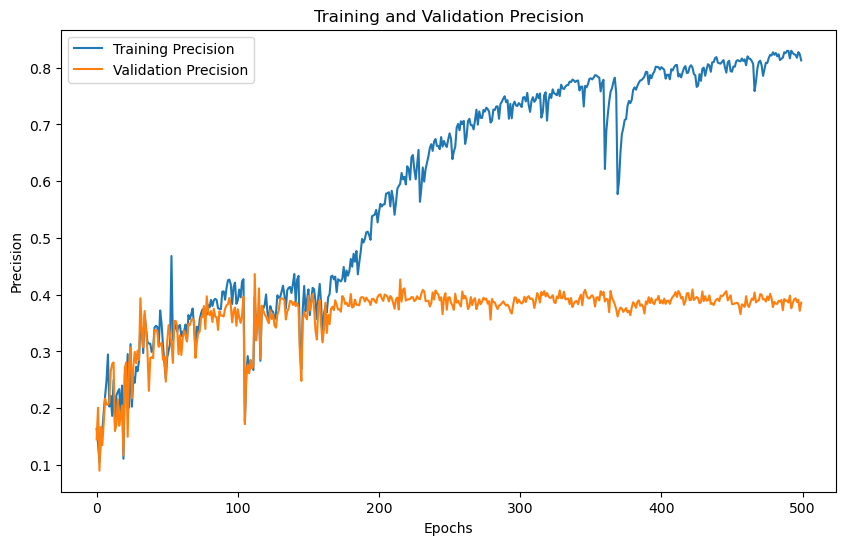

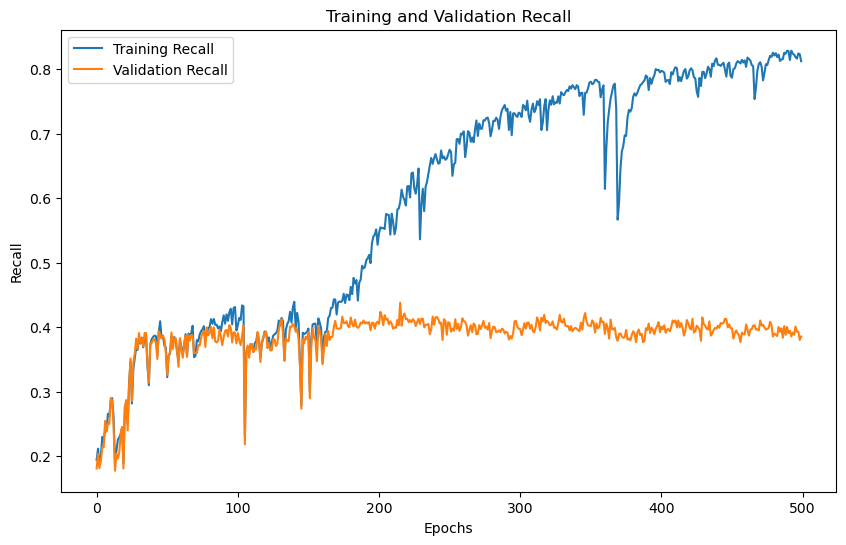

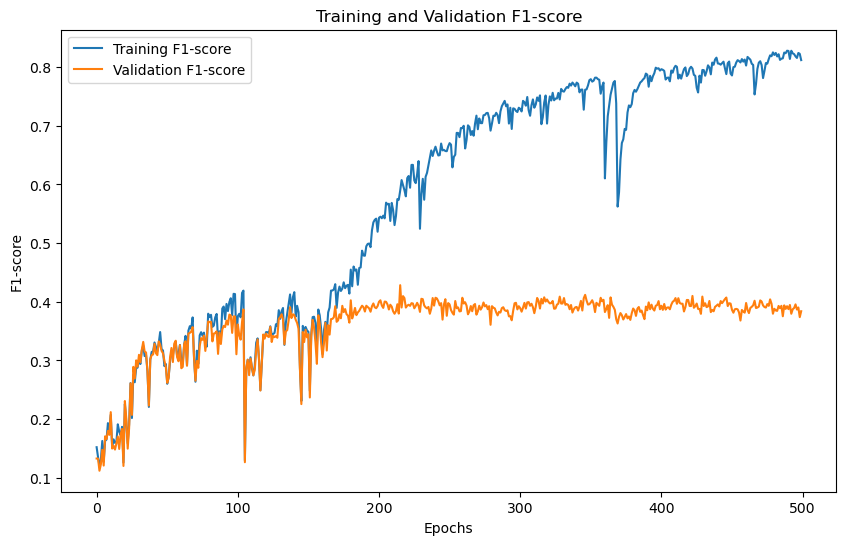

'Model Training and Evaluation Successfully completed'

In [11]:
train_model()

# dwt 5

# 500 epochs

Enter dataset name:
tess, savee, crema, ravdess
 crema
Enter dwt level:  5
No. of classes 6
Input size : 1
Hidden Size : 256
Model Name: LSTMModel

X Shape : (7442, 240, 1)
Y Shape : (7442, 6)
Training with DWT level: 5
Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.7876, Training Accuracy: 0.2023, Training Precision:0.1111,Training Recall:0.2023,Training F1-Score:0.1170
Validation Loss: 1.7867, Validation Accuracy: 0.1813, Validation Precision:0.1098,Validation Recall:0.1813,Validation F1-Score:0.1025
Epoch [2/500],
Training Loss: 1.7799, Training Accuracy: 0.1975, Training Precision:0.1407,Training Recall:0.1975,Training F1-Score:0.1336
Validation Loss: 1.7841, Validation Accuracy: 0.1887, Validation Precision:0.1608,Validation Recall:0.1887,Validation F1-Score:0.1311
Epoch [3/500],
Training Loss: 1.7766, Training Accuracy: 0.2227, Training Precision:0.1152,Training Recall:0.2227,Training F1-Score:0.1471
Validation Loss: 1.7725, Validation Accuracy: 0.2116, Validation Precis

Epoch [31/500],
Training Loss: 1.6644, Training Accuracy: 0.3219, Training Precision:0.2665,Training Recall:0.3219,Training F1-Score:0.2070
Validation Loss: 1.7136, Validation Accuracy: 0.3170, Validation Precision:0.2332,Validation Recall:0.3170,Validation F1-Score:0.1983
Epoch [32/500],
Training Loss: 1.6715, Training Accuracy: 0.3702, Training Precision:0.3340,Training Recall:0.3702,Training F1-Score:0.3195
Validation Loss: 1.6564, Validation Accuracy: 0.3606, Validation Precision:0.2981,Validation Recall:0.3606,Validation F1-Score:0.3065
Epoch [33/500],
Training Loss: 1.6641, Training Accuracy: 0.3306, Training Precision:0.2887,Training Recall:0.3306,Training F1-Score:0.2692
Validation Loss: 1.6751, Validation Accuracy: 0.3459, Validation Precision:0.3047,Validation Recall:0.3459,Validation F1-Score:0.2835
Epoch [34/500],
Training Loss: 1.6646, Training Accuracy: 0.3675, Training Precision:0.3063,Training Recall:0.3675,Training F1-Score:0.3045
Validation Loss: 1.6576, Validation Ac

Epoch [61/500],
Training Loss: 1.6509, Training Accuracy: 0.3781, Training Precision:0.2575,Training Recall:0.3781,Training F1-Score:0.3035
Validation Loss: 1.6411, Validation Accuracy: 0.3889, Validation Precision:0.2673,Validation Recall:0.3889,Validation F1-Score:0.3136
Epoch [62/500],
Training Loss: 1.6572, Training Accuracy: 0.3775, Training Precision:0.2917,Training Recall:0.3775,Training F1-Score:0.3039
Validation Loss: 1.6395, Validation Accuracy: 0.3942, Validation Precision:0.2719,Validation Recall:0.3942,Validation F1-Score:0.3186
Epoch [63/500],
Training Loss: 1.6511, Training Accuracy: 0.3778, Training Precision:0.2628,Training Recall:0.3778,Training F1-Score:0.3048
Validation Loss: 1.6451, Validation Accuracy: 0.3781, Validation Precision:0.2646,Validation Recall:0.3781,Validation F1-Score:0.3057
Epoch [64/500],
Training Loss: 1.6504, Training Accuracy: 0.3827, Training Precision:0.2502,Training Recall:0.3827,Training F1-Score:0.3016
Validation Loss: 1.6377, Validation Ac

Epoch [91/500],
Training Loss: 1.6337, Training Accuracy: 0.4000, Training Precision:0.3719,Training Recall:0.4000,Training F1-Score:0.3499
Validation Loss: 1.6281, Validation Accuracy: 0.3976, Validation Precision:0.3436,Validation Recall:0.3976,Validation F1-Score:0.3432
Epoch [92/500],
Training Loss: 1.6342, Training Accuracy: 0.4011, Training Precision:0.3826,Training Recall:0.4011,Training F1-Score:0.3596
Validation Loss: 1.6298, Validation Accuracy: 0.3855, Validation Precision:0.3635,Validation Recall:0.3855,Validation F1-Score:0.3426
Epoch [93/500],
Training Loss: 1.6298, Training Accuracy: 0.4090, Training Precision:0.3886,Training Recall:0.4090,Training F1-Score:0.3607
Validation Loss: 1.6305, Validation Accuracy: 0.3915, Validation Precision:0.3396,Validation Recall:0.3915,Validation F1-Score:0.3394
Epoch [94/500],
Training Loss: 1.6277, Training Accuracy: 0.3936, Training Precision:0.3725,Training Recall:0.3936,Training F1-Score:0.3304
Validation Loss: 1.6331, Validation Ac

Epoch [121/500],
Training Loss: 1.5855, Training Accuracy: 0.4460, Training Precision:0.4384,Training Recall:0.4460,Training F1-Score:0.4334
Validation Loss: 1.6258, Validation Accuracy: 0.3962, Validation Precision:0.3819,Validation Recall:0.3962,Validation F1-Score:0.3821
Epoch [122/500],
Training Loss: 1.5782, Training Accuracy: 0.4591, Training Precision:0.4499,Training Recall:0.4591,Training F1-Score:0.4393
Validation Loss: 1.6194, Validation Accuracy: 0.4157, Validation Precision:0.4004,Validation Recall:0.4157,Validation F1-Score:0.3979
Epoch [123/500],
Training Loss: 1.5737, Training Accuracy: 0.4799, Training Precision:0.4713,Training Recall:0.4799,Training F1-Score:0.4668
Validation Loss: 1.6169, Validation Accuracy: 0.4124, Validation Precision:0.3958,Validation Recall:0.4124,Validation F1-Score:0.3981
Epoch [124/500],
Training Loss: 1.5755, Training Accuracy: 0.4749, Training Precision:0.4801,Training Recall:0.4749,Training F1-Score:0.4485
Validation Loss: 1.6191, Validatio

...

Epoch [361/500],
Training Loss: 1.4052, Training Accuracy: 0.7183, Training Precision:0.7205,Training Recall:0.7183,Training F1-Score:0.7179
Validation Loss: 1.6460, Validation Accuracy: 0.3942, Validation Precision:0.3960,Validation Recall:0.3942,Validation F1-Score:0.3942
Epoch [362/500],
Training Loss: 1.3273, Training Accuracy: 0.7475, Training Precision:0.7516,Training Recall:0.7475,Training F1-Score:0.7470
Validation Loss: 1.6387, Validation Accuracy: 0.3996, Validation Precision:0.4018,Validation Recall:0.3996,Validation F1-Score:0.3974
Epoch [363/500],
Training Loss: 1.3069, Training Accuracy: 0.7201, Training Precision:0.7232,Training Recall:0.7201,Training F1-Score:0.7195
Validation Loss: 1.6395, Validation Accuracy: 0.4009, Validation Precision:0.3976,Validation Recall:0.4009,Validation F1-Score:0.3974
Epoch [364/500],
Training Loss: 1.3019, Training Accuracy: 0.7487, Training Precision:0.7542,Training Recall:0.7487,Training F1-Score:0.7488
Validation Loss: 1.6458, Validatio

Epoch [391/500],
Training Loss: 1.2635, Training Accuracy: 0.7825, Training Precision:0.7838,Training Recall:0.7825,Training F1-Score:0.7820
Validation Loss: 1.6291, Validation Accuracy: 0.4083, Validation Precision:0.4052,Validation Recall:0.4083,Validation F1-Score:0.4063
Epoch [392/500],
Training Loss: 1.2630, Training Accuracy: 0.7880, Training Precision:0.7892,Training Recall:0.7880,Training F1-Score:0.7876
Validation Loss: 1.6295, Validation Accuracy: 0.4103, Validation Precision:0.4081,Validation Recall:0.4103,Validation F1-Score:0.4083
Epoch [393/500],
Training Loss: 1.2613, Training Accuracy: 0.7857, Training Precision:0.7892,Training Recall:0.7857,Training F1-Score:0.7855
Validation Loss: 1.6347, Validation Accuracy: 0.4023, Validation Precision:0.4002,Validation Recall:0.4023,Validation F1-Score:0.3997
Epoch [394/500],
Training Loss: 1.2546, Training Accuracy: 0.7893, Training Precision:0.7909,Training Recall:0.7893,Training F1-Score:0.7891
Validation Loss: 1.6330, Validatio

Epoch [421/500],
Training Loss: 1.2523, Training Accuracy: 0.7895, Training Precision:0.7919,Training Recall:0.7895,Training F1-Score:0.7893
Validation Loss: 1.6447, Validation Accuracy: 0.3936, Validation Precision:0.3980,Validation Recall:0.3936,Validation F1-Score:0.3934
Epoch [422/500],
Training Loss: 1.2545, Training Accuracy: 0.7941, Training Precision:0.7970,Training Recall:0.7941,Training F1-Score:0.7938
Validation Loss: 1.6337, Validation Accuracy: 0.4063, Validation Precision:0.4042,Validation Recall:0.4063,Validation F1-Score:0.4040
Epoch [423/500],
Training Loss: 1.2469, Training Accuracy: 0.7996, Training Precision:0.8006,Training Recall:0.7996,Training F1-Score:0.7992
Validation Loss: 1.6380, Validation Accuracy: 0.3996, Validation Precision:0.3991,Validation Recall:0.3996,Validation F1-Score:0.3985
Epoch [424/500],
Training Loss: 1.2514, Training Accuracy: 0.7899, Training Precision:0.7920,Training Recall:0.7899,Training F1-Score:0.7898
Validation Loss: 1.6461, Validatio

Epoch [451/500],
Training Loss: 1.2506, Training Accuracy: 0.7967, Training Precision:0.7982,Training Recall:0.7967,Training F1-Score:0.7964
Validation Loss: 1.6333, Validation Accuracy: 0.4077, Validation Precision:0.4050,Validation Recall:0.4077,Validation F1-Score:0.4050
Epoch [452/500],
Training Loss: 1.2453, Training Accuracy: 0.8021, Training Precision:0.8055,Training Recall:0.8021,Training F1-Score:0.8020
Validation Loss: 1.6417, Validation Accuracy: 0.3949, Validation Precision:0.3919,Validation Recall:0.3949,Validation F1-Score:0.3923
Epoch [453/500],
Training Loss: 1.2401, Training Accuracy: 0.7983, Training Precision:0.8014,Training Recall:0.7983,Training F1-Score:0.7982
Validation Loss: 1.6406, Validation Accuracy: 0.3969, Validation Precision:0.4020,Validation Recall:0.3969,Validation F1-Score:0.3976
Epoch [454/500],
Training Loss: 1.2415, Training Accuracy: 0.8056, Training Precision:0.8101,Training Recall:0.8056,Training F1-Score:0.8057
Validation Loss: 1.6323, Validatio

Epoch [481/500],
Training Loss: 1.2373, Training Accuracy: 0.8061, Training Precision:0.8080,Training Recall:0.8061,Training F1-Score:0.8061
Validation Loss: 1.6267, Validation Accuracy: 0.4137, Validation Precision:0.4151,Validation Recall:0.4137,Validation F1-Score:0.4135
Epoch [482/500],
Training Loss: 1.2477, Training Accuracy: 0.8055, Training Precision:0.8067,Training Recall:0.8055,Training F1-Score:0.8053
Validation Loss: 1.6347, Validation Accuracy: 0.4009, Validation Precision:0.4061,Validation Recall:0.4009,Validation F1-Score:0.4024
Epoch [483/500],
Training Loss: 1.2412, Training Accuracy: 0.8100, Training Precision:0.8129,Training Recall:0.8100,Training F1-Score:0.8100
Validation Loss: 1.6240, Validation Accuracy: 0.4157, Validation Precision:0.4127,Validation Recall:0.4157,Validation F1-Score:0.4137
Epoch [484/500],
Training Loss: 1.2340, Training Accuracy: 0.8117, Training Precision:0.8153,Training Recall:0.8117,Training F1-Score:0.8117
Validation Loss: 1.6324, Validatio

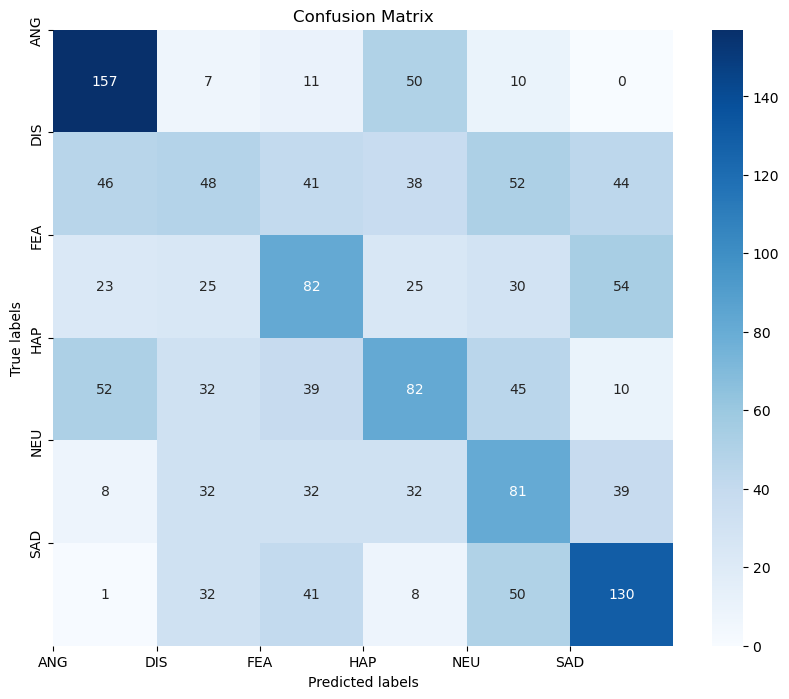

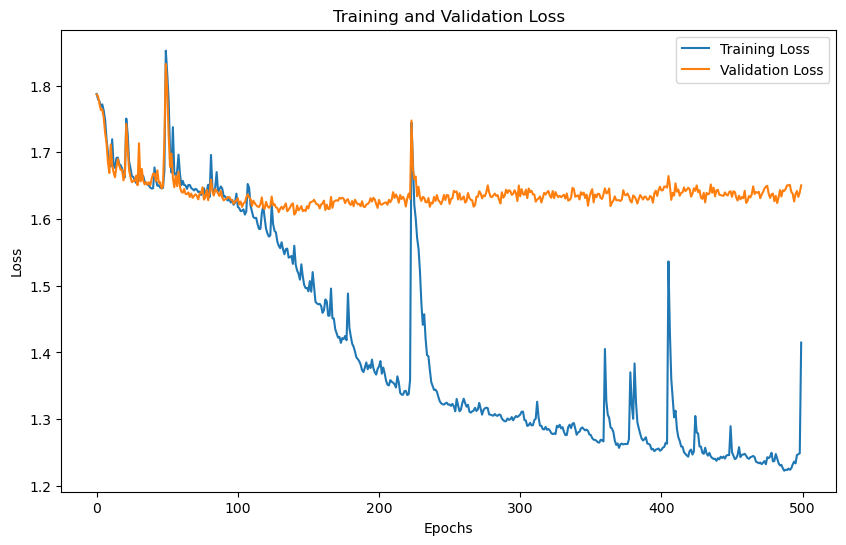

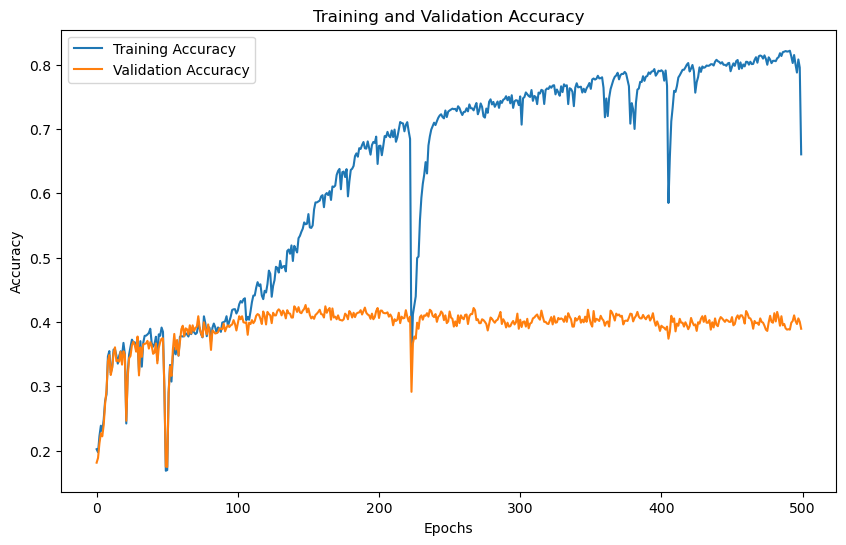

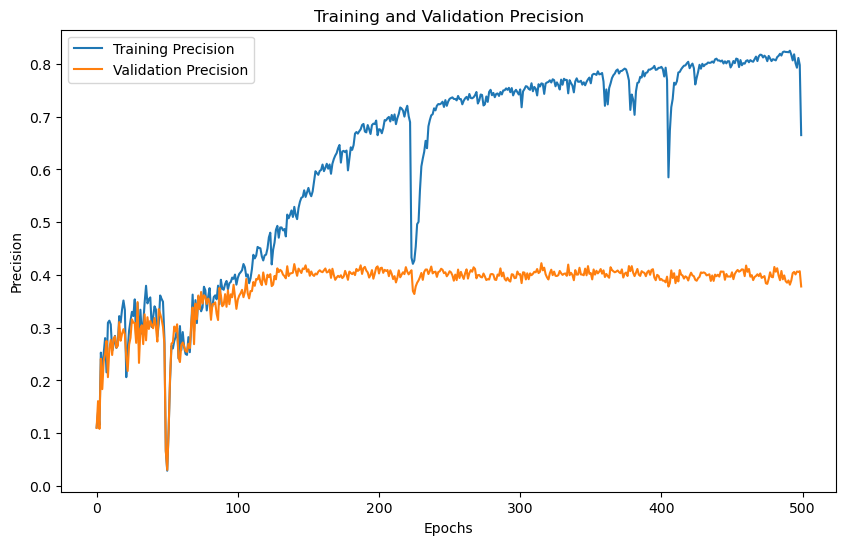

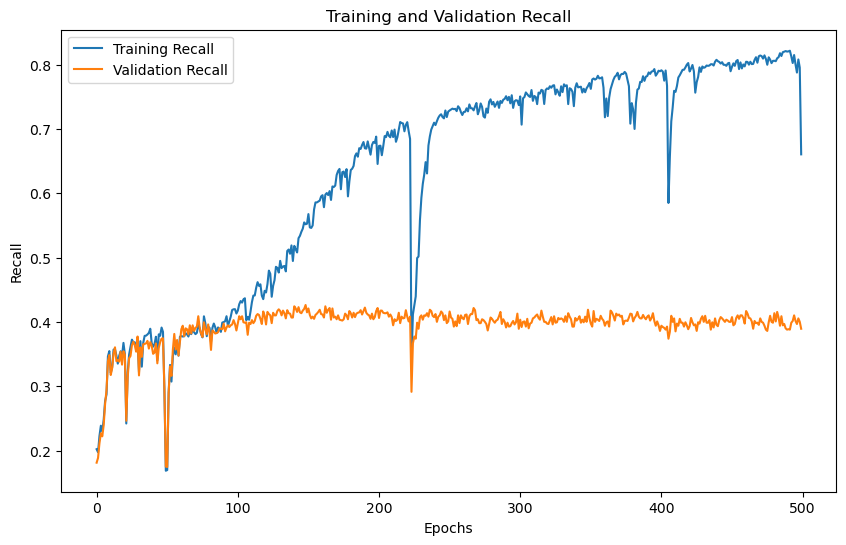

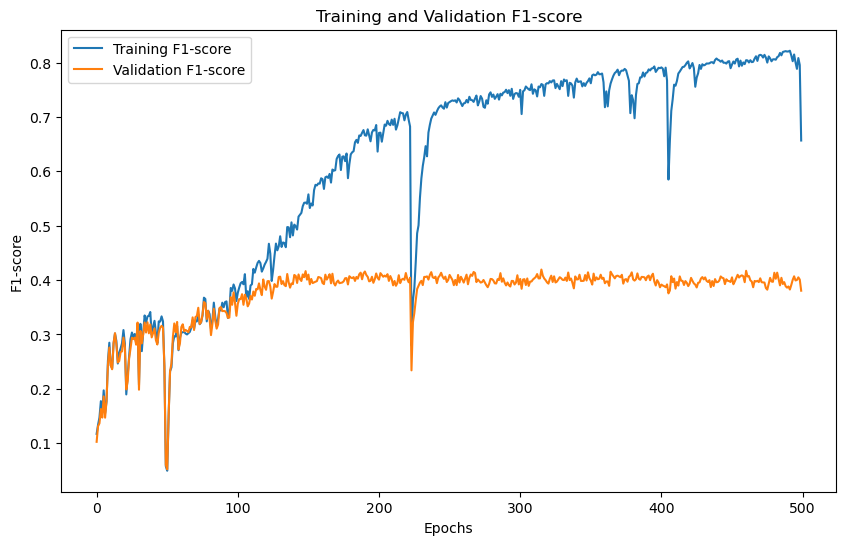

'Model Training and Evaluation Successfully completed'

In [12]:
train_model()

# TESS

# dwt 1

# 500 epoch

Enter dataset name:
tess, savee, crema, ravdess
 tess
Enter dwt level:  1
No. of classes 7
Input size : 1
Hidden Size : 256
Model Name: LSTMModel

X Shape : (2800, 80, 1)
Y Shape : (2800, 7)
Training with DWT level: 1
Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.8290, Training Accuracy: 0.3915, Training Precision:0.2523,Training Recall:0.3915,Training F1-Score:0.2696
Validation Loss: 1.7436, Validation Accuracy: 0.3750, Validation Precision:0.2033,Validation Recall:0.3750,Validation F1-Score:0.2473
Epoch [2/500],
Training Loss: 1.6729, Training Accuracy: 0.5143, Training Precision:0.4361,Training Recall:0.5143,Training F1-Score:0.4193
Validation Loss: 1.6754, Validation Accuracy: 0.4857, Validation Precision:0.4381,Validation Recall:0.4857,Validation F1-Score:0.3954
Epoch [3/500],
Training Loss: 1.5713, Training Accuracy: 0.6853, Training Precision:0.7063,Training Recall:0.6853,Training F1-Score:0.6637
Validation Loss: 1.5054, Validation Accuracy: 0.6786, Validation Precisio

Epoch [31/500],
Training Loss: 1.2219, Training Accuracy: 0.9491, Training Precision:0.9501,Training Recall:0.9491,Training F1-Score:0.9490
Validation Loss: 1.2385, Validation Accuracy: 0.9268, Validation Precision:0.9291,Validation Recall:0.9268,Validation F1-Score:0.9270
Epoch [32/500],
Training Loss: 1.2245, Training Accuracy: 0.9442, Training Precision:0.9457,Training Recall:0.9442,Training F1-Score:0.9440
Validation Loss: 1.2380, Validation Accuracy: 0.9286, Validation Precision:0.9327,Validation Recall:0.9286,Validation F1-Score:0.9286
Epoch [33/500],
Training Loss: 1.2371, Training Accuracy: 0.9263, Training Precision:0.9301,Training Recall:0.9263,Training F1-Score:0.9265
Validation Loss: 1.2708, Validation Accuracy: 0.8964, Validation Precision:0.9044,Validation Recall:0.8964,Validation F1-Score:0.8972
Epoch [34/500],
Training Loss: 1.2352, Training Accuracy: 0.9509, Training Precision:0.9523,Training Recall:0.9509,Training F1-Score:0.9506
Validation Loss: 1.2423, Validation Ac

Epoch [61/500],
Training Loss: 1.2020, Training Accuracy: 0.9701, Training Precision:0.9703,Training Recall:0.9701,Training F1-Score:0.9701
Validation Loss: 1.2315, Validation Accuracy: 0.9357, Validation Precision:0.9370,Validation Recall:0.9357,Validation F1-Score:0.9356
Epoch [62/500],
Training Loss: 1.1975, Training Accuracy: 0.9732, Training Precision:0.9733,Training Recall:0.9732,Training F1-Score:0.9732
Validation Loss: 1.2126, Validation Accuracy: 0.9518, Validation Precision:0.9526,Validation Recall:0.9518,Validation F1-Score:0.9520
Epoch [63/500],
Training Loss: 1.1969, Training Accuracy: 0.9701, Training Precision:0.9706,Training Recall:0.9701,Training F1-Score:0.9701
Validation Loss: 1.2187, Validation Accuracy: 0.9446, Validation Precision:0.9459,Validation Recall:0.9446,Validation F1-Score:0.9449
Epoch [64/500],
Training Loss: 1.2065, Training Accuracy: 0.9656, Training Precision:0.9658,Training Recall:0.9656,Training F1-Score:0.9655
Validation Loss: 1.2314, Validation Ac

Epoch [91/500],
Training Loss: 1.1879, Training Accuracy: 0.9812, Training Precision:0.9813,Training Recall:0.9812,Training F1-Score:0.9812
Validation Loss: 1.2143, Validation Accuracy: 0.9518, Validation Precision:0.9518,Validation Recall:0.9518,Validation F1-Score:0.9516
Epoch [92/500],
Training Loss: 1.1896, Training Accuracy: 0.9817, Training Precision:0.9817,Training Recall:0.9817,Training F1-Score:0.9817
Validation Loss: 1.2166, Validation Accuracy: 0.9482, Validation Precision:0.9492,Validation Recall:0.9482,Validation F1-Score:0.9483
Epoch [93/500],
Training Loss: 1.1862, Training Accuracy: 0.9808, Training Precision:0.9808,Training Recall:0.9808,Training F1-Score:0.9808
Validation Loss: 1.2123, Validation Accuracy: 0.9536, Validation Precision:0.9552,Validation Recall:0.9536,Validation F1-Score:0.9535
Epoch [94/500],
Training Loss: 1.1917, Training Accuracy: 0.9804, Training Precision:0.9804,Training Recall:0.9804,Training F1-Score:0.9804
Validation Loss: 1.2114, Validation Ac

Epoch [121/500],
Training Loss: 1.2042, Training Accuracy: 0.9491, Training Precision:0.9520,Training Recall:0.9491,Training F1-Score:0.9480
Validation Loss: 1.2567, Validation Accuracy: 0.9071, Validation Precision:0.9109,Validation Recall:0.9071,Validation F1-Score:0.9053
Epoch [122/500],
Training Loss: 1.2005, Training Accuracy: 0.9759, Training Precision:0.9764,Training Recall:0.9759,Training F1-Score:0.9759
Validation Loss: 1.2318, Validation Accuracy: 0.9339, Validation Precision:0.9378,Validation Recall:0.9339,Validation F1-Score:0.9341
Epoch [123/500],
Training Loss: 1.1917, Training Accuracy: 0.9763, Training Precision:0.9771,Training Recall:0.9763,Training F1-Score:0.9763
Validation Loss: 1.2229, Validation Accuracy: 0.9429, Validation Precision:0.9432,Validation Recall:0.9429,Validation F1-Score:0.9426
Epoch [124/500],
Training Loss: 1.1951, Training Accuracy: 0.9469, Training Precision:0.9518,Training Recall:0.9469,Training F1-Score:0.9461
Validation Loss: 1.2546, Validatio

...

Epoch [361/500],
Training Loss: 1.1735, Training Accuracy: 0.9920, Training Precision:0.9920,Training Recall:0.9920,Training F1-Score:0.9920
Validation Loss: 1.1983, Validation Accuracy: 0.9679, Validation Precision:0.9682,Validation Recall:0.9679,Validation F1-Score:0.9678
Epoch [362/500],
Training Loss: 1.1735, Training Accuracy: 0.9920, Training Precision:0.9920,Training Recall:0.9920,Training F1-Score:0.9920
Validation Loss: 1.1983, Validation Accuracy: 0.9679, Validation Precision:0.9682,Validation Recall:0.9679,Validation F1-Score:0.9678
Epoch [363/500],
Training Loss: 1.1735, Training Accuracy: 0.9920, Training Precision:0.9920,Training Recall:0.9920,Training F1-Score:0.9920
Validation Loss: 1.1983, Validation Accuracy: 0.9679, Validation Precision:0.9682,Validation Recall:0.9679,Validation F1-Score:0.9678
Epoch [364/500],
Training Loss: 1.1735, Training Accuracy: 0.9920, Training Precision:0.9920,Training Recall:0.9920,Training F1-Score:0.9920
Validation Loss: 1.1983, Validatio

Epoch [391/500],
Training Loss: 1.1735, Training Accuracy: 0.9920, Training Precision:0.9920,Training Recall:0.9920,Training F1-Score:0.9920
Validation Loss: 1.1982, Validation Accuracy: 0.9679, Validation Precision:0.9682,Validation Recall:0.9679,Validation F1-Score:0.9678
Epoch [392/500],
Training Loss: 1.1735, Training Accuracy: 0.9920, Training Precision:0.9920,Training Recall:0.9920,Training F1-Score:0.9920
Validation Loss: 1.1982, Validation Accuracy: 0.9679, Validation Precision:0.9682,Validation Recall:0.9679,Validation F1-Score:0.9678
Epoch [393/500],
Training Loss: 1.1735, Training Accuracy: 0.9920, Training Precision:0.9920,Training Recall:0.9920,Training F1-Score:0.9920
Validation Loss: 1.1982, Validation Accuracy: 0.9679, Validation Precision:0.9682,Validation Recall:0.9679,Validation F1-Score:0.9678
Epoch [394/500],
Training Loss: 1.1735, Training Accuracy: 0.9920, Training Precision:0.9920,Training Recall:0.9920,Training F1-Score:0.9920
Validation Loss: 1.1982, Validatio

Epoch [421/500],
Training Loss: 1.1735, Training Accuracy: 0.9920, Training Precision:0.9920,Training Recall:0.9920,Training F1-Score:0.9920
Validation Loss: 1.1982, Validation Accuracy: 0.9679, Validation Precision:0.9682,Validation Recall:0.9679,Validation F1-Score:0.9678
Epoch [422/500],
Training Loss: 1.1735, Training Accuracy: 0.9920, Training Precision:0.9920,Training Recall:0.9920,Training F1-Score:0.9920
Validation Loss: 1.1982, Validation Accuracy: 0.9679, Validation Precision:0.9682,Validation Recall:0.9679,Validation F1-Score:0.9678
Epoch [423/500],
Training Loss: 1.1735, Training Accuracy: 0.9920, Training Precision:0.9920,Training Recall:0.9920,Training F1-Score:0.9920
Validation Loss: 1.1982, Validation Accuracy: 0.9679, Validation Precision:0.9682,Validation Recall:0.9679,Validation F1-Score:0.9678
Epoch [424/500],
Training Loss: 1.1735, Training Accuracy: 0.9920, Training Precision:0.9920,Training Recall:0.9920,Training F1-Score:0.9920
Validation Loss: 1.1982, Validatio

Epoch [451/500],
Training Loss: 1.1971, Training Accuracy: 0.9665, Training Precision:0.9669,Training Recall:0.9665,Training F1-Score:0.9664
Validation Loss: 1.2274, Validation Accuracy: 0.9375, Validation Precision:0.9396,Validation Recall:0.9375,Validation F1-Score:0.9374
Epoch [452/500],
Training Loss: 1.1954, Training Accuracy: 0.9652, Training Precision:0.9657,Training Recall:0.9652,Training F1-Score:0.9651
Validation Loss: 1.2313, Validation Accuracy: 0.9339, Validation Precision:0.9365,Validation Recall:0.9339,Validation F1-Score:0.9337
Epoch [453/500],
Training Loss: 1.2181, Training Accuracy: 0.9750, Training Precision:0.9750,Training Recall:0.9750,Training F1-Score:0.9750
Validation Loss: 1.2077, Validation Accuracy: 0.9589, Validation Precision:0.9597,Validation Recall:0.9589,Validation F1-Score:0.9587
Epoch [454/500],
Training Loss: 1.1938, Training Accuracy: 0.9696, Training Precision:0.9702,Training Recall:0.9696,Training F1-Score:0.9696
Validation Loss: 1.2363, Validatio

Epoch [481/500],
Training Loss: 1.1956, Training Accuracy: 0.9723, Training Precision:0.9732,Training Recall:0.9723,Training F1-Score:0.9724
Validation Loss: 1.2285, Validation Accuracy: 0.9375, Validation Precision:0.9415,Validation Recall:0.9375,Validation F1-Score:0.9377
Epoch [482/500],
Training Loss: 1.1904, Training Accuracy: 0.9647, Training Precision:0.9657,Training Recall:0.9647,Training F1-Score:0.9647
Validation Loss: 1.2245, Validation Accuracy: 0.9411, Validation Precision:0.9443,Validation Recall:0.9411,Validation F1-Score:0.9412
Epoch [483/500],
Training Loss: 1.1903, Training Accuracy: 0.9741, Training Precision:0.9747,Training Recall:0.9741,Training F1-Score:0.9741
Validation Loss: 1.2152, Validation Accuracy: 0.9500, Validation Precision:0.9524,Validation Recall:0.9500,Validation F1-Score:0.9500
Epoch [484/500],
Training Loss: 1.1890, Training Accuracy: 0.9795, Training Precision:0.9795,Training Recall:0.9795,Training F1-Score:0.9794
Validation Loss: 1.2168, Validatio

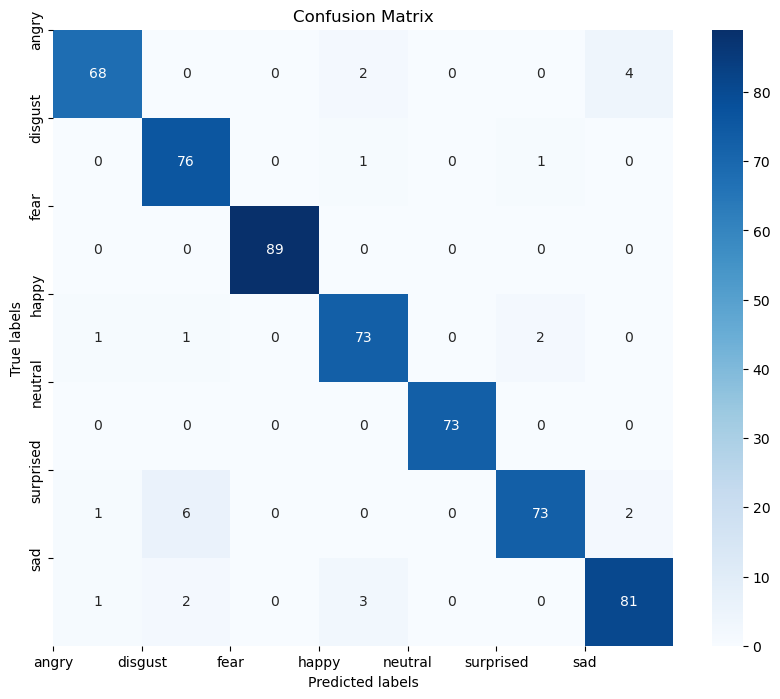

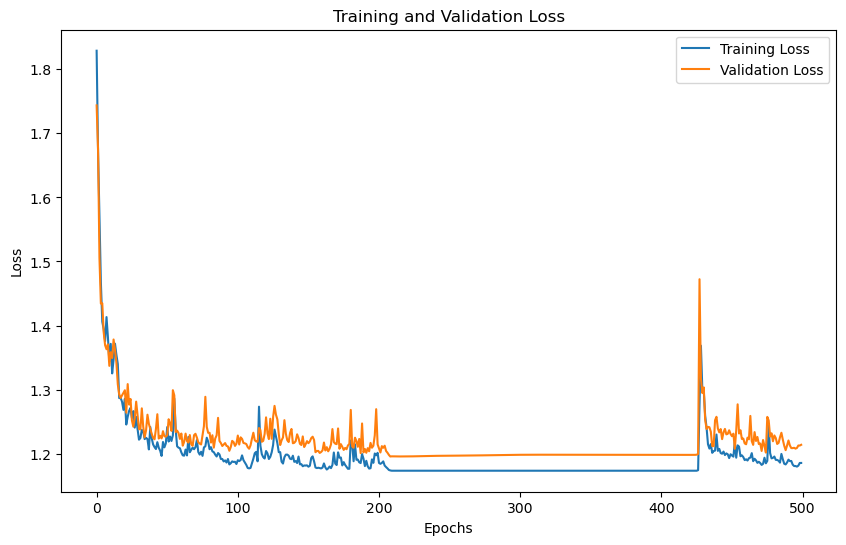

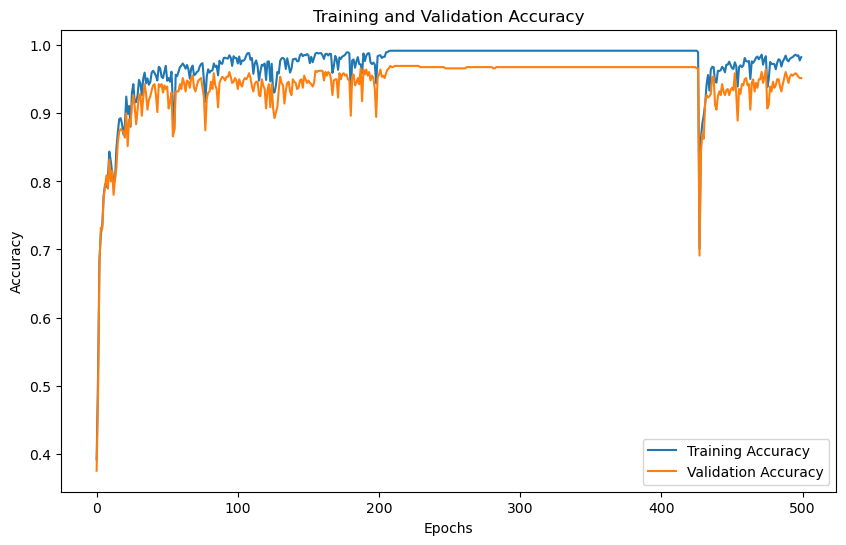

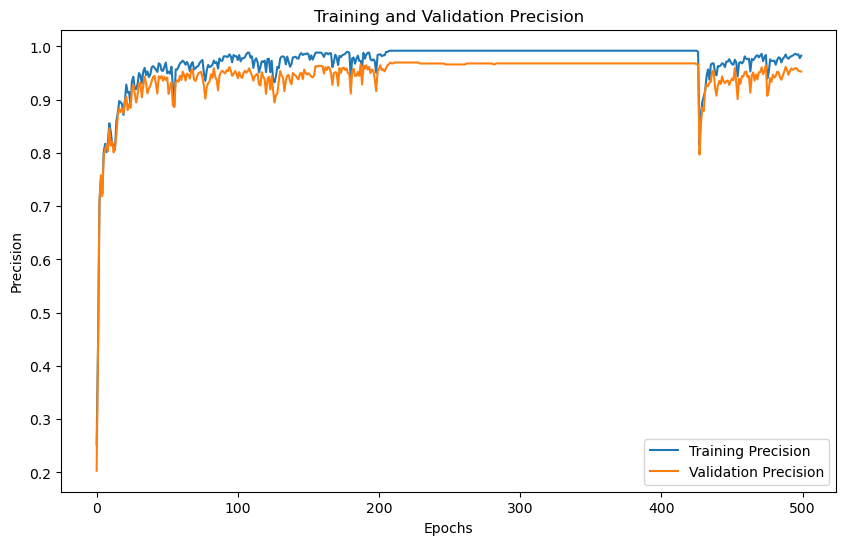

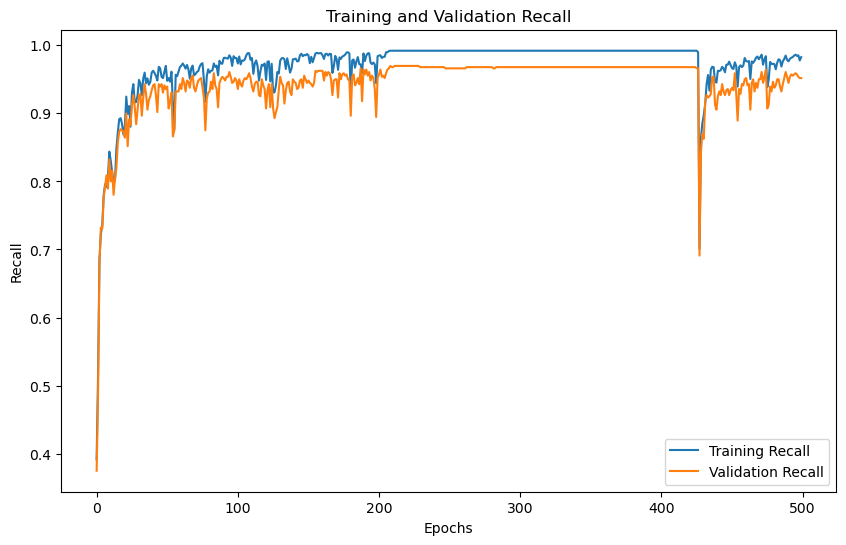

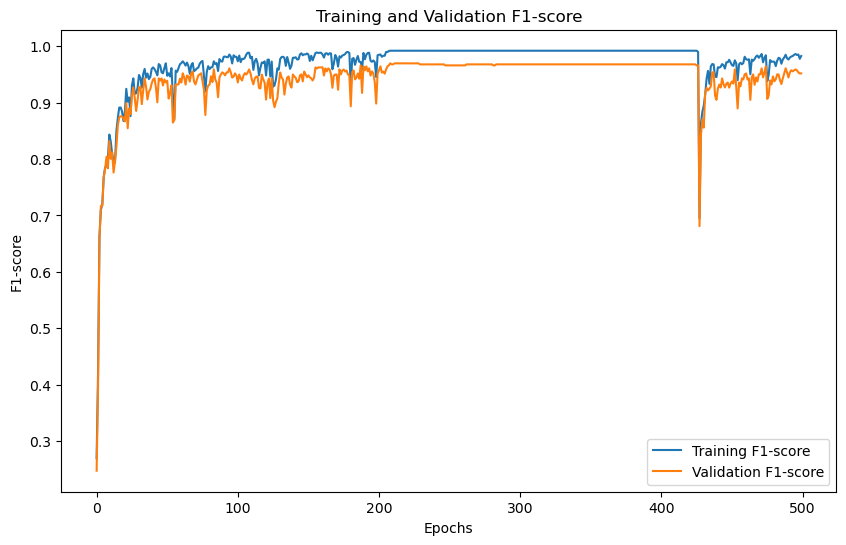

'Model Training and Evaluation Successfully completed'

In [13]:
train_model()

# dwt 2

# 500 epoch

Enter dataset name:
tess, savee, crema, ravdess
 tess
Enter dwt level:  2
No. of classes 7
Input size : 1
Hidden Size : 256
Model Name: LSTMModel

X Shape : (2800, 120, 1)
Y Shape : (2800, 7)
Training with DWT level: 2
Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.8268, Training Accuracy: 0.4679, Training Precision:0.2982,Training Recall:0.4679,Training F1-Score:0.3575
Validation Loss: 1.7260, Validation Accuracy: 0.4375, Validation Precision:0.2678,Validation Recall:0.4375,Validation F1-Score:0.3256
Epoch [2/500],
Training Loss: 1.6585, Training Accuracy: 0.5496, Training Precision:0.4829,Training Recall:0.5496,Training F1-Score:0.4896
Validation Loss: 1.6407, Validation Accuracy: 0.5357, Validation Precision:0.4980,Validation Recall:0.5357,Validation F1-Score:0.4801
Epoch [3/500],
Training Loss: 1.5364, Training Accuracy: 0.6661, Training Precision:0.5739,Training Recall:0.6661,Training F1-Score:0.6079
Validation Loss: 1.5151, Validation Accuracy: 0.6393, Validation Precisi

Epoch [31/500],
Training Loss: 1.2289, Training Accuracy: 0.8607, Training Precision:0.8710,Training Recall:0.8607,Training F1-Score:0.8611
Validation Loss: 1.3300, Validation Accuracy: 0.8393, Validation Precision:0.8537,Validation Recall:0.8393,Validation F1-Score:0.8404
Epoch [32/500],
Training Loss: 1.2535, Training Accuracy: 0.9299, Training Precision:0.9322,Training Recall:0.9299,Training F1-Score:0.9298
Validation Loss: 1.2799, Validation Accuracy: 0.8821, Validation Precision:0.8931,Validation Recall:0.8821,Validation F1-Score:0.8828
Epoch [33/500],
Training Loss: 1.2311, Training Accuracy: 0.9482, Training Precision:0.9493,Training Recall:0.9482,Training F1-Score:0.9483
Validation Loss: 1.2437, Validation Accuracy: 0.9232, Validation Precision:0.9285,Validation Recall:0.9232,Validation F1-Score:0.9239
Epoch [34/500],
Training Loss: 1.2426, Training Accuracy: 0.8491, Training Precision:0.8634,Training Recall:0.8491,Training F1-Score:0.8438
Validation Loss: 1.3402, Validation Ac

Epoch [61/500],
Training Loss: 1.1991, Training Accuracy: 0.9741, Training Precision:0.9744,Training Recall:0.9741,Training F1-Score:0.9741
Validation Loss: 1.2150, Validation Accuracy: 0.9500, Validation Precision:0.9509,Validation Recall:0.9500,Validation F1-Score:0.9500
Epoch [62/500],
Training Loss: 1.1930, Training Accuracy: 0.9674, Training Precision:0.9678,Training Recall:0.9674,Training F1-Score:0.9674
Validation Loss: 1.2180, Validation Accuracy: 0.9482, Validation Precision:0.9490,Validation Recall:0.9482,Validation F1-Score:0.9483
Epoch [63/500],
Training Loss: 1.2146, Training Accuracy: 0.9259, Training Precision:0.9338,Training Recall:0.9259,Training F1-Score:0.9268
Validation Loss: 1.2550, Validation Accuracy: 0.9125, Validation Precision:0.9186,Validation Recall:0.9125,Validation F1-Score:0.9122
Epoch [64/500],
Training Loss: 1.2217, Training Accuracy: 0.9634, Training Precision:0.9653,Training Recall:0.9634,Training F1-Score:0.9634
Validation Loss: 1.2294, Validation Ac

Epoch [91/500],
Training Loss: 1.1917, Training Accuracy: 0.9594, Training Precision:0.9609,Training Recall:0.9594,Training F1-Score:0.9594
Validation Loss: 1.2207, Validation Accuracy: 0.9446, Validation Precision:0.9457,Validation Recall:0.9446,Validation F1-Score:0.9444
Epoch [92/500],
Training Loss: 1.2189, Training Accuracy: 0.9710, Training Precision:0.9714,Training Recall:0.9710,Training F1-Score:0.9709
Validation Loss: 1.2102, Validation Accuracy: 0.9554, Validation Precision:0.9557,Validation Recall:0.9554,Validation F1-Score:0.9552
Epoch [93/500],
Training Loss: 1.1936, Training Accuracy: 0.9763, Training Precision:0.9765,Training Recall:0.9763,Training F1-Score:0.9764
Validation Loss: 1.2235, Validation Accuracy: 0.9411, Validation Precision:0.9415,Validation Recall:0.9411,Validation F1-Score:0.9410
Epoch [94/500],
Training Loss: 1.1888, Training Accuracy: 0.9585, Training Precision:0.9612,Training Recall:0.9585,Training F1-Score:0.9581
Validation Loss: 1.2445, Validation Ac

Epoch [121/500],
Training Loss: 1.1921, Training Accuracy: 0.9830, Training Precision:0.9831,Training Recall:0.9830,Training F1-Score:0.9830
Validation Loss: 1.1981, Validation Accuracy: 0.9679, Validation Precision:0.9682,Validation Recall:0.9679,Validation F1-Score:0.9679
Epoch [122/500],
Training Loss: 1.1834, Training Accuracy: 0.9714, Training Precision:0.9728,Training Recall:0.9714,Training F1-Score:0.9715
Validation Loss: 1.2176, Validation Accuracy: 0.9464, Validation Precision:0.9488,Validation Recall:0.9464,Validation F1-Score:0.9462
Epoch [123/500],
Training Loss: 1.2071, Training Accuracy: 0.9750, Training Precision:0.9751,Training Recall:0.9750,Training F1-Score:0.9750
Validation Loss: 1.2233, Validation Accuracy: 0.9411, Validation Precision:0.9414,Validation Recall:0.9411,Validation F1-Score:0.9410
Epoch [124/500],
Training Loss: 1.1936, Training Accuracy: 0.9629, Training Precision:0.9643,Training Recall:0.9629,Training F1-Score:0.9626
Validation Loss: 1.2199, Validatio

...

Epoch [361/500],
Training Loss: 1.1699, Training Accuracy: 0.9955, Training Precision:0.9955,Training Recall:0.9955,Training F1-Score:0.9955
Validation Loss: 1.1962, Validation Accuracy: 0.9696, Validation Precision:0.9704,Validation Recall:0.9696,Validation F1-Score:0.9697
Epoch [362/500],
Training Loss: 1.1699, Training Accuracy: 0.9955, Training Precision:0.9955,Training Recall:0.9955,Training F1-Score:0.9955
Validation Loss: 1.1962, Validation Accuracy: 0.9696, Validation Precision:0.9704,Validation Recall:0.9696,Validation F1-Score:0.9697
Epoch [363/500],
Training Loss: 1.1699, Training Accuracy: 0.9955, Training Precision:0.9955,Training Recall:0.9955,Training F1-Score:0.9955
Validation Loss: 1.1962, Validation Accuracy: 0.9696, Validation Precision:0.9704,Validation Recall:0.9696,Validation F1-Score:0.9697
Epoch [364/500],
Training Loss: 1.1699, Training Accuracy: 0.9955, Training Precision:0.9955,Training Recall:0.9955,Training F1-Score:0.9955
Validation Loss: 1.1962, Validatio

Epoch [391/500],
Training Loss: 1.1694, Training Accuracy: 0.9960, Training Precision:0.9960,Training Recall:0.9960,Training F1-Score:0.9960
Validation Loss: 1.1978, Validation Accuracy: 0.9679, Validation Precision:0.9685,Validation Recall:0.9679,Validation F1-Score:0.9679
Epoch [392/500],
Training Loss: 1.1694, Training Accuracy: 0.9960, Training Precision:0.9960,Training Recall:0.9960,Training F1-Score:0.9960
Validation Loss: 1.1978, Validation Accuracy: 0.9679, Validation Precision:0.9685,Validation Recall:0.9679,Validation F1-Score:0.9679
Epoch [393/500],
Training Loss: 1.1694, Training Accuracy: 0.9960, Training Precision:0.9960,Training Recall:0.9960,Training F1-Score:0.9960
Validation Loss: 1.1978, Validation Accuracy: 0.9679, Validation Precision:0.9685,Validation Recall:0.9679,Validation F1-Score:0.9679
Epoch [394/500],
Training Loss: 1.1694, Training Accuracy: 0.9960, Training Precision:0.9960,Training Recall:0.9960,Training F1-Score:0.9960
Validation Loss: 1.1978, Validatio

Epoch [421/500],
Training Loss: 1.1694, Training Accuracy: 0.9960, Training Precision:0.9960,Training Recall:0.9960,Training F1-Score:0.9960
Validation Loss: 1.1978, Validation Accuracy: 0.9679, Validation Precision:0.9685,Validation Recall:0.9679,Validation F1-Score:0.9679
Epoch [422/500],
Training Loss: 1.1694, Training Accuracy: 0.9960, Training Precision:0.9960,Training Recall:0.9960,Training F1-Score:0.9960
Validation Loss: 1.1978, Validation Accuracy: 0.9679, Validation Precision:0.9685,Validation Recall:0.9679,Validation F1-Score:0.9679
Epoch [423/500],
Training Loss: 1.1694, Training Accuracy: 0.9960, Training Precision:0.9960,Training Recall:0.9960,Training F1-Score:0.9960
Validation Loss: 1.1978, Validation Accuracy: 0.9679, Validation Precision:0.9685,Validation Recall:0.9679,Validation F1-Score:0.9679
Epoch [424/500],
Training Loss: 1.1694, Training Accuracy: 0.9960, Training Precision:0.9960,Training Recall:0.9960,Training F1-Score:0.9960
Validation Loss: 1.1978, Validatio

Epoch [451/500],
Training Loss: 1.1694, Training Accuracy: 0.9960, Training Precision:0.9960,Training Recall:0.9960,Training F1-Score:0.9960
Validation Loss: 1.1978, Validation Accuracy: 0.9679, Validation Precision:0.9685,Validation Recall:0.9679,Validation F1-Score:0.9679
Epoch [452/500],
Training Loss: 1.1694, Training Accuracy: 0.9960, Training Precision:0.9960,Training Recall:0.9960,Training F1-Score:0.9960
Validation Loss: 1.1978, Validation Accuracy: 0.9679, Validation Precision:0.9685,Validation Recall:0.9679,Validation F1-Score:0.9679
Epoch [453/500],
Training Loss: 1.1694, Training Accuracy: 0.9960, Training Precision:0.9960,Training Recall:0.9960,Training F1-Score:0.9960
Validation Loss: 1.1978, Validation Accuracy: 0.9679, Validation Precision:0.9685,Validation Recall:0.9679,Validation F1-Score:0.9679
Epoch [454/500],
Training Loss: 1.1694, Training Accuracy: 0.9960, Training Precision:0.9960,Training Recall:0.9960,Training F1-Score:0.9960
Validation Loss: 1.1978, Validatio

Epoch [481/500],
Training Loss: 1.2559, Training Accuracy: 0.9103, Training Precision:0.9106,Training Recall:0.9103,Training F1-Score:0.9100
Validation Loss: 1.2858, Validation Accuracy: 0.8804, Validation Precision:0.8820,Validation Recall:0.8804,Validation F1-Score:0.8805
Epoch [482/500],
Training Loss: 1.2585, Training Accuracy: 0.9237, Training Precision:0.9242,Training Recall:0.9237,Training F1-Score:0.9235
Validation Loss: 1.2615, Validation Accuracy: 0.9036, Validation Precision:0.9063,Validation Recall:0.9036,Validation F1-Score:0.9039
Epoch [483/500],
Training Loss: 1.2448, Training Accuracy: 0.9161, Training Precision:0.9222,Training Recall:0.9161,Training F1-Score:0.9161
Validation Loss: 1.2886, Validation Accuracy: 0.8768, Validation Precision:0.8929,Validation Recall:0.8768,Validation F1-Score:0.8768
Epoch [484/500],
Training Loss: 1.2479, Training Accuracy: 0.9259, Training Precision:0.9260,Training Recall:0.9259,Training F1-Score:0.9257
Validation Loss: 1.2687, Validatio

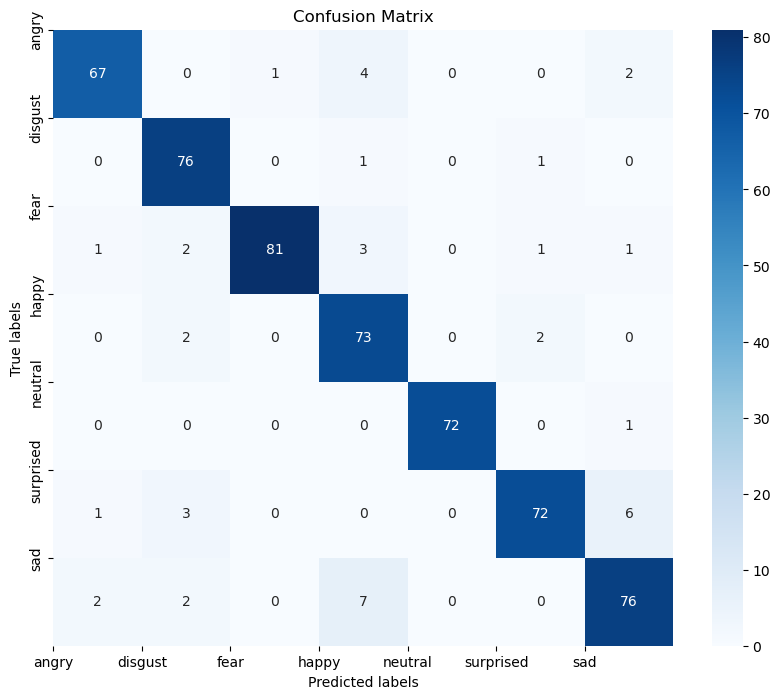

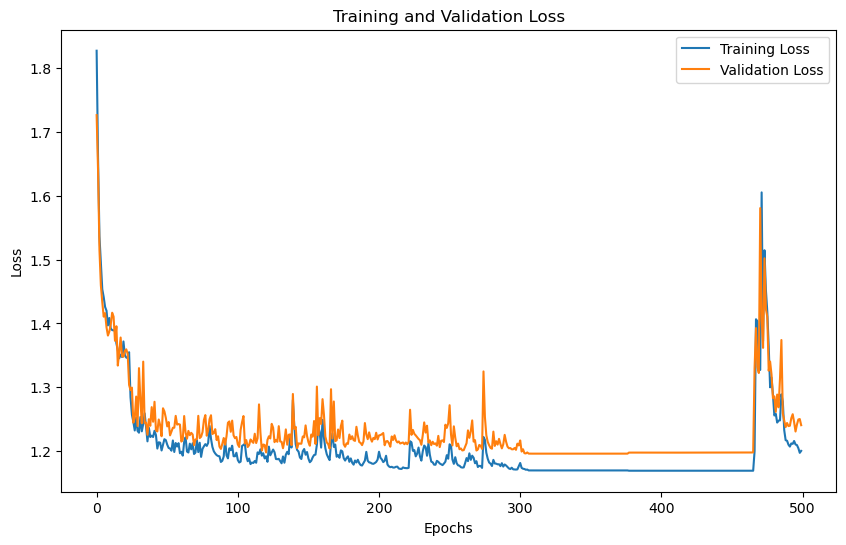

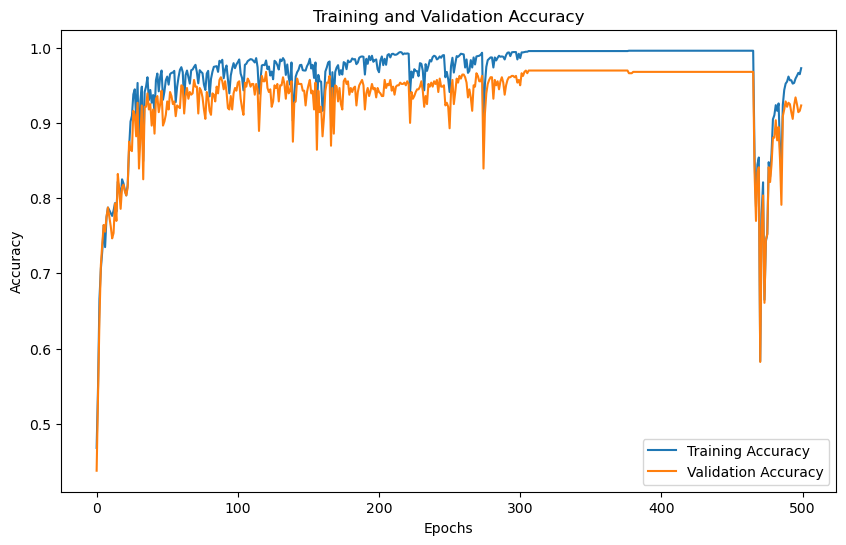

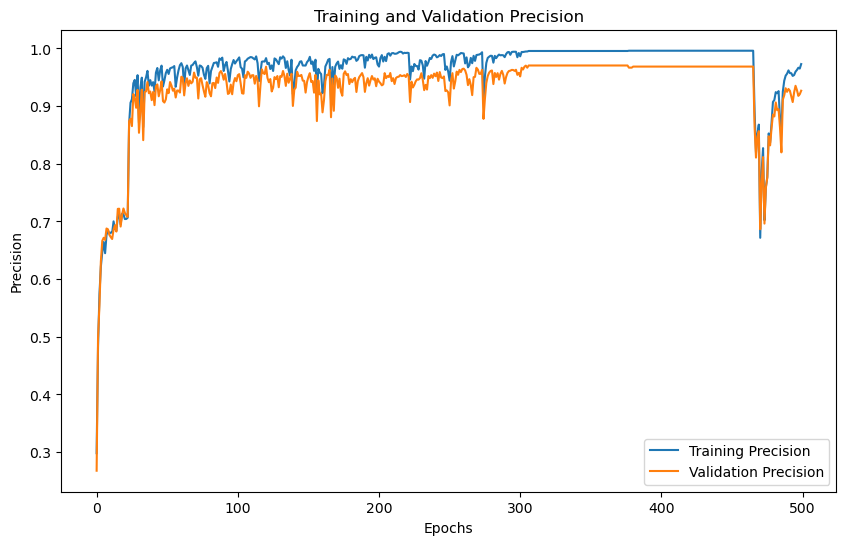

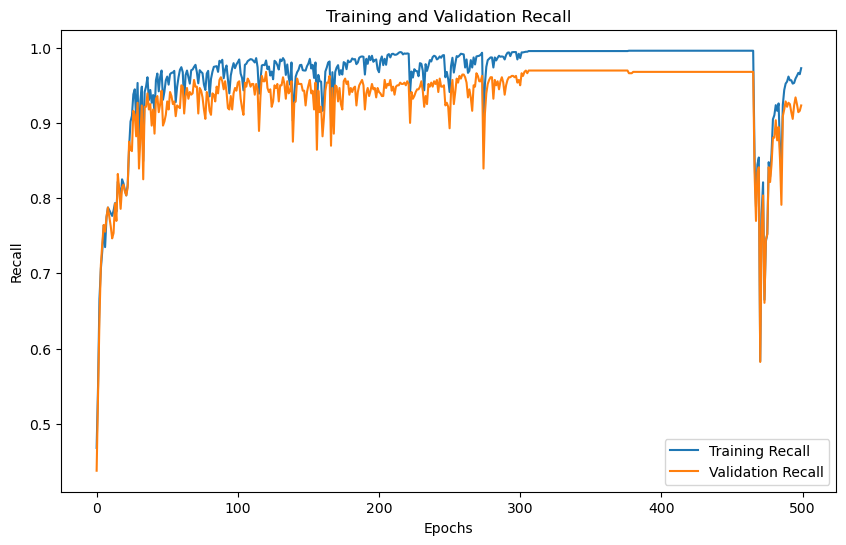

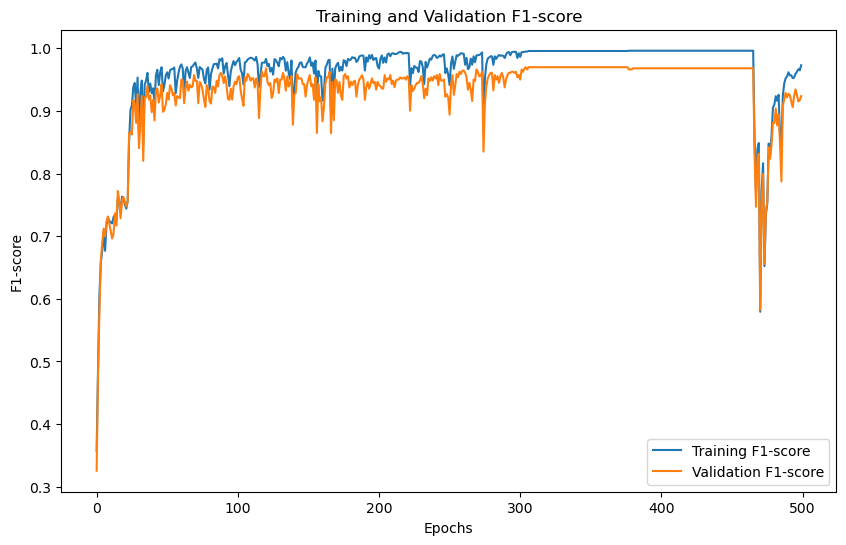

'Model Training and Evaluation Successfully completed'

In [15]:
train_model()

# dwt 3

# 500 epoch

Enter dataset name:
tess, savee, crema, ravdess
 tess
Enter dwt level:  3
No. of classes 7
Input size : 1
Hidden Size : 256
Model Name: LSTMModel

X Shape : (2800, 160, 1)
Y Shape : (2800, 7)
Training with DWT level: 3
Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.8453, Training Accuracy: 0.3688, Training Precision:0.4155,Training Recall:0.3688,Training F1-Score:0.2775
Validation Loss: 1.7839, Validation Accuracy: 0.3375, Validation Precision:0.2135,Validation Recall:0.3375,Validation F1-Score:0.2396
Epoch [2/500],
Training Loss: 1.6881, Training Accuracy: 0.5107, Training Precision:0.5745,Training Recall:0.5107,Training F1-Score:0.4543
Validation Loss: 1.6411, Validation Accuracy: 0.4857, Validation Precision:0.4087,Validation Recall:0.4857,Validation F1-Score:0.4293
Epoch [3/500],
Training Loss: 1.5875, Training Accuracy: 0.6205, Training Precision:0.6738,Training Recall:0.6205,Training F1-Score:0.5905
Validation Loss: 1.5701, Validation Accuracy: 0.5893, Validation Precisi

Epoch [31/500],
Training Loss: 1.2669, Training Accuracy: 0.9013, Training Precision:0.9185,Training Recall:0.9013,Training F1-Score:0.8931
Validation Loss: 1.2769, Validation Accuracy: 0.8875, Validation Precision:0.9011,Validation Recall:0.8875,Validation F1-Score:0.8788
Epoch [32/500],
Training Loss: 1.2646, Training Accuracy: 0.8964, Training Precision:0.9163,Training Recall:0.8964,Training F1-Score:0.8897
Validation Loss: 1.2805, Validation Accuracy: 0.8839, Validation Precision:0.9039,Validation Recall:0.8839,Validation F1-Score:0.8791
Epoch [33/500],
Training Loss: 1.2722, Training Accuracy: 0.9022, Training Precision:0.9051,Training Recall:0.9022,Training F1-Score:0.8970
Validation Loss: 1.2824, Validation Accuracy: 0.8857, Validation Precision:0.8845,Validation Recall:0.8857,Validation F1-Score:0.8821
Epoch [34/500],
Training Loss: 1.2651, Training Accuracy: 0.9152, Training Precision:0.9166,Training Recall:0.9152,Training F1-Score:0.9146
Validation Loss: 1.2792, Validation Ac

Epoch [61/500],
Training Loss: 1.1969, Training Accuracy: 0.9723, Training Precision:0.9723,Training Recall:0.9723,Training F1-Score:0.9723
Validation Loss: 1.2092, Validation Accuracy: 0.9589, Validation Precision:0.9590,Validation Recall:0.9589,Validation F1-Score:0.9588
Epoch [62/500],
Training Loss: 1.1934, Training Accuracy: 0.9692, Training Precision:0.9701,Training Recall:0.9692,Training F1-Score:0.9693
Validation Loss: 1.2177, Validation Accuracy: 0.9482, Validation Precision:0.9499,Validation Recall:0.9482,Validation F1-Score:0.9484
Epoch [63/500],
Training Loss: 1.1969, Training Accuracy: 0.9723, Training Precision:0.9723,Training Recall:0.9723,Training F1-Score:0.9723
Validation Loss: 1.2068, Validation Accuracy: 0.9589, Validation Precision:0.9590,Validation Recall:0.9589,Validation F1-Score:0.9586
Epoch [64/500],
Training Loss: 1.2099, Training Accuracy: 0.9527, Training Precision:0.9554,Training Recall:0.9527,Training F1-Score:0.9526
Validation Loss: 1.2404, Validation Ac

Epoch [91/500],
Training Loss: 1.2142, Training Accuracy: 0.9696, Training Precision:0.9696,Training Recall:0.9696,Training F1-Score:0.9696
Validation Loss: 1.2270, Validation Accuracy: 0.9375, Validation Precision:0.9382,Validation Recall:0.9375,Validation F1-Score:0.9376
Epoch [92/500],
Training Loss: 1.2141, Training Accuracy: 0.9549, Training Precision:0.9576,Training Recall:0.9549,Training F1-Score:0.9552
Validation Loss: 1.2324, Validation Accuracy: 0.9321, Validation Precision:0.9358,Validation Recall:0.9321,Validation F1-Score:0.9321
Epoch [93/500],
Training Loss: 1.2038, Training Accuracy: 0.9455, Training Precision:0.9488,Training Recall:0.9455,Training F1-Score:0.9444
Validation Loss: 1.2326, Validation Accuracy: 0.9321, Validation Precision:0.9347,Validation Recall:0.9321,Validation F1-Score:0.9306
Epoch [94/500],
Training Loss: 1.2093, Training Accuracy: 0.9696, Training Precision:0.9710,Training Recall:0.9696,Training F1-Score:0.9696
Validation Loss: 1.2197, Validation Ac

Epoch [121/500],
Training Loss: 1.1923, Training Accuracy: 0.9857, Training Precision:0.9859,Training Recall:0.9857,Training F1-Score:0.9857
Validation Loss: 1.2117, Validation Accuracy: 0.9518, Validation Precision:0.9537,Validation Recall:0.9518,Validation F1-Score:0.9522
Epoch [122/500],
Training Loss: 1.1844, Training Accuracy: 0.9835, Training Precision:0.9838,Training Recall:0.9835,Training F1-Score:0.9835
Validation Loss: 1.2130, Validation Accuracy: 0.9518, Validation Precision:0.9532,Validation Recall:0.9518,Validation F1-Score:0.9519
Epoch [123/500],
Training Loss: 1.1852, Training Accuracy: 0.9768, Training Precision:0.9775,Training Recall:0.9768,Training F1-Score:0.9766
Validation Loss: 1.2326, Validation Accuracy: 0.9321, Validation Precision:0.9353,Validation Recall:0.9321,Validation F1-Score:0.9316
Epoch [124/500],
Training Loss: 1.1944, Training Accuracy: 0.9455, Training Precision:0.9481,Training Recall:0.9455,Training F1-Score:0.9451
Validation Loss: 1.2552, Validatio

...

Epoch [361/500],
Training Loss: 1.1717, Training Accuracy: 0.9938, Training Precision:0.9938,Training Recall:0.9938,Training F1-Score:0.9937
Validation Loss: 1.2064, Validation Accuracy: 0.9589, Validation Precision:0.9594,Validation Recall:0.9589,Validation F1-Score:0.9590
Epoch [362/500],
Training Loss: 1.1716, Training Accuracy: 0.9942, Training Precision:0.9942,Training Recall:0.9942,Training F1-Score:0.9942
Validation Loss: 1.2062, Validation Accuracy: 0.9589, Validation Precision:0.9594,Validation Recall:0.9589,Validation F1-Score:0.9590
Epoch [363/500],
Training Loss: 1.1713, Training Accuracy: 0.9938, Training Precision:0.9938,Training Recall:0.9938,Training F1-Score:0.9937
Validation Loss: 1.2068, Validation Accuracy: 0.9589, Validation Precision:0.9598,Validation Recall:0.9589,Validation F1-Score:0.9591
Epoch [364/500],
Training Loss: 1.1769, Training Accuracy: 0.9804, Training Precision:0.9808,Training Recall:0.9804,Training F1-Score:0.9803
Validation Loss: 1.2014, Validatio

Epoch [391/500],
Training Loss: 1.1770, Training Accuracy: 0.9830, Training Precision:0.9835,Training Recall:0.9830,Training F1-Score:0.9829
Validation Loss: 1.2273, Validation Accuracy: 0.9375, Validation Precision:0.9417,Validation Recall:0.9375,Validation F1-Score:0.9368
Epoch [392/500],
Training Loss: 1.2321, Training Accuracy: 0.9460, Training Precision:0.9464,Training Recall:0.9460,Training F1-Score:0.9456
Validation Loss: 1.2494, Validation Accuracy: 0.9179, Validation Precision:0.9200,Validation Recall:0.9179,Validation F1-Score:0.9170
Epoch [393/500],
Training Loss: 1.2118, Training Accuracy: 0.9656, Training Precision:0.9678,Training Recall:0.9656,Training F1-Score:0.9648
Validation Loss: 1.2290, Validation Accuracy: 0.9357, Validation Precision:0.9418,Validation Recall:0.9357,Validation F1-Score:0.9351
Epoch [394/500],
Training Loss: 1.1958, Training Accuracy: 0.9705, Training Precision:0.9721,Training Recall:0.9705,Training F1-Score:0.9699
Validation Loss: 1.2190, Validatio

Epoch [421/500],
Training Loss: 1.1798, Training Accuracy: 0.9879, Training Precision:0.9881,Training Recall:0.9879,Training F1-Score:0.9879
Validation Loss: 1.2138, Validation Accuracy: 0.9518, Validation Precision:0.9538,Validation Recall:0.9518,Validation F1-Score:0.9519
Epoch [422/500],
Training Loss: 1.1810, Training Accuracy: 0.9786, Training Precision:0.9789,Training Recall:0.9786,Training F1-Score:0.9785
Validation Loss: 1.2217, Validation Accuracy: 0.9446, Validation Precision:0.9458,Validation Recall:0.9446,Validation F1-Score:0.9445
Epoch [423/500],
Training Loss: 1.1831, Training Accuracy: 0.9871, Training Precision:0.9871,Training Recall:0.9871,Training F1-Score:0.9870
Validation Loss: 1.2011, Validation Accuracy: 0.9643, Validation Precision:0.9652,Validation Recall:0.9643,Validation F1-Score:0.9644
Epoch [424/500],
Training Loss: 1.1798, Training Accuracy: 0.9866, Training Precision:0.9867,Training Recall:0.9866,Training F1-Score:0.9866
Validation Loss: 1.2073, Validatio

Epoch [451/500],
Training Loss: 1.1868, Training Accuracy: 0.9857, Training Precision:0.9858,Training Recall:0.9857,Training F1-Score:0.9857
Validation Loss: 1.2158, Validation Accuracy: 0.9500, Validation Precision:0.9509,Validation Recall:0.9500,Validation F1-Score:0.9498
Epoch [452/500],
Training Loss: 1.1782, Training Accuracy: 0.9871, Training Precision:0.9872,Training Recall:0.9871,Training F1-Score:0.9871
Validation Loss: 1.2183, Validation Accuracy: 0.9464, Validation Precision:0.9478,Validation Recall:0.9464,Validation F1-Score:0.9464
Epoch [453/500],
Training Loss: 1.1794, Training Accuracy: 0.9879, Training Precision:0.9881,Training Recall:0.9879,Training F1-Score:0.9880
Validation Loss: 1.2081, Validation Accuracy: 0.9589, Validation Precision:0.9597,Validation Recall:0.9589,Validation F1-Score:0.9591
Epoch [454/500],
Training Loss: 1.1780, Training Accuracy: 0.9875, Training Precision:0.9876,Training Recall:0.9875,Training F1-Score:0.9875
Validation Loss: 1.2083, Validatio

Epoch [481/500],
Training Loss: 1.1757, Training Accuracy: 0.9897, Training Precision:0.9898,Training Recall:0.9897,Training F1-Score:0.9897
Validation Loss: 1.2085, Validation Accuracy: 0.9571, Validation Precision:0.9580,Validation Recall:0.9571,Validation F1-Score:0.9572
Epoch [482/500],
Training Loss: 1.1757, Training Accuracy: 0.9897, Training Precision:0.9898,Training Recall:0.9897,Training F1-Score:0.9897
Validation Loss: 1.2085, Validation Accuracy: 0.9571, Validation Precision:0.9580,Validation Recall:0.9571,Validation F1-Score:0.9572
Epoch [483/500],
Training Loss: 1.1757, Training Accuracy: 0.9897, Training Precision:0.9898,Training Recall:0.9897,Training F1-Score:0.9897
Validation Loss: 1.2085, Validation Accuracy: 0.9571, Validation Precision:0.9580,Validation Recall:0.9571,Validation F1-Score:0.9572
Epoch [484/500],
Training Loss: 1.1757, Training Accuracy: 0.9897, Training Precision:0.9898,Training Recall:0.9897,Training F1-Score:0.9897
Validation Loss: 1.2085, Validatio

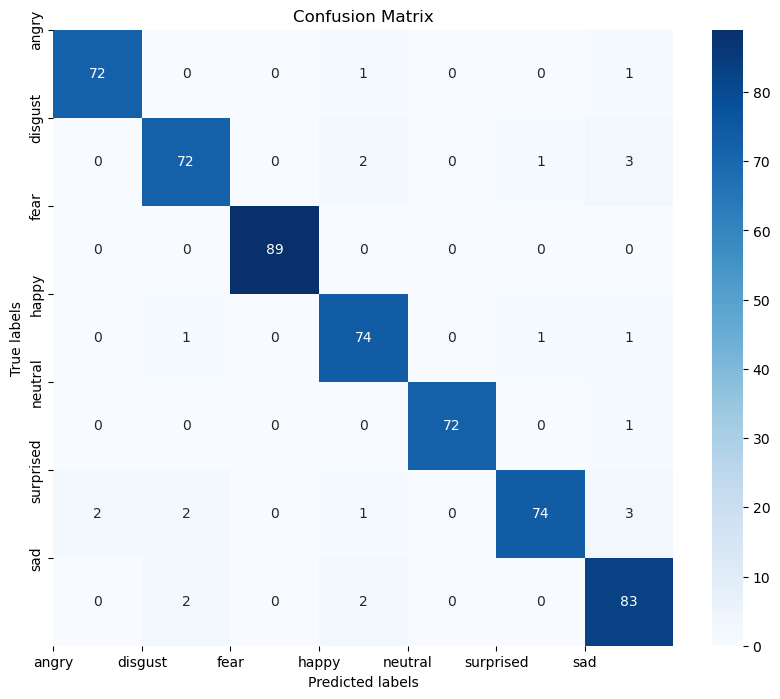

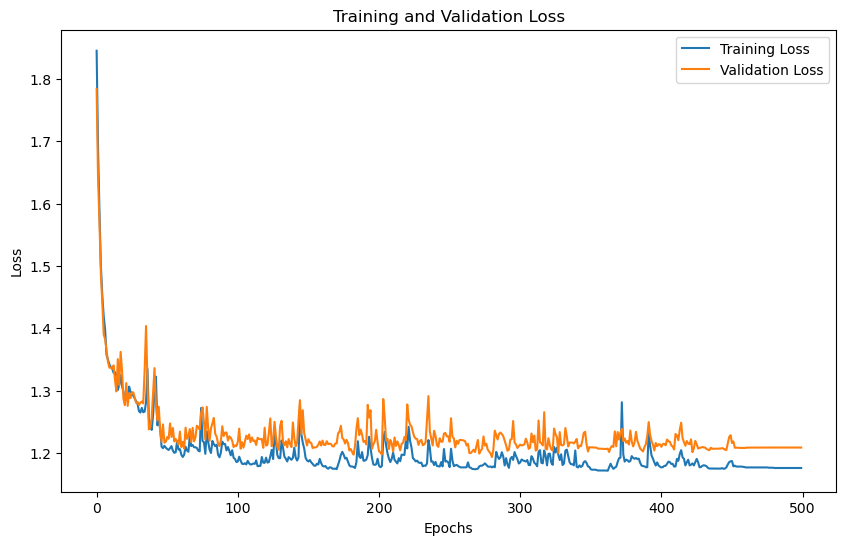

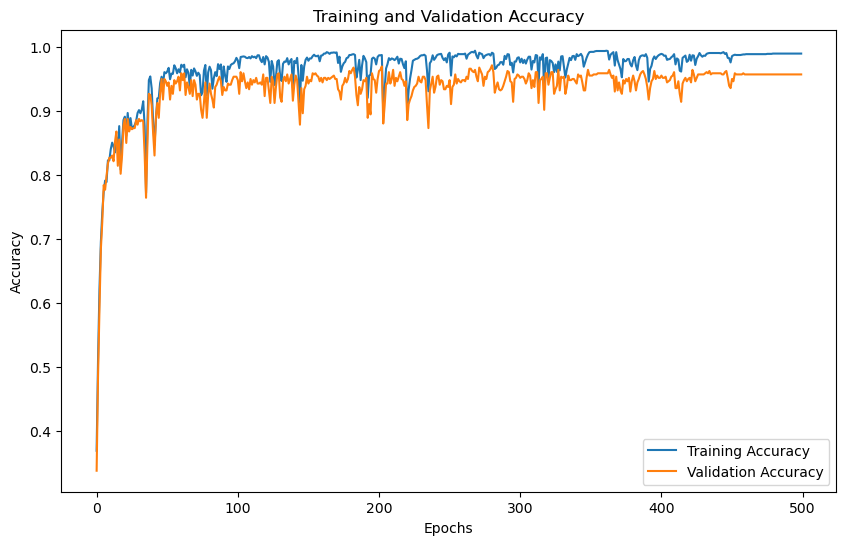

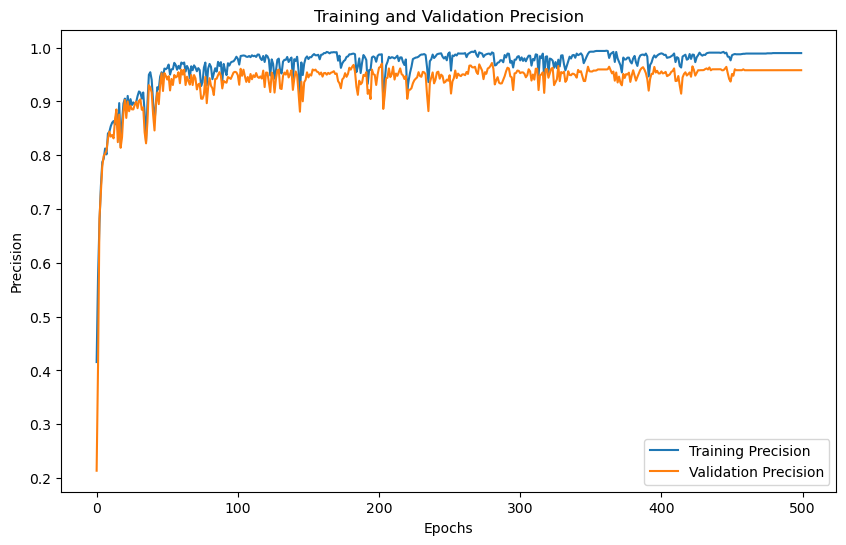

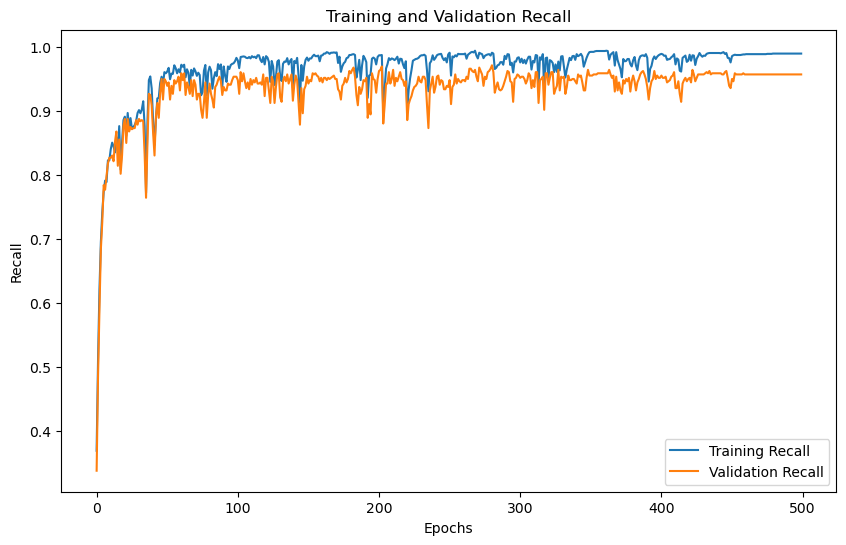

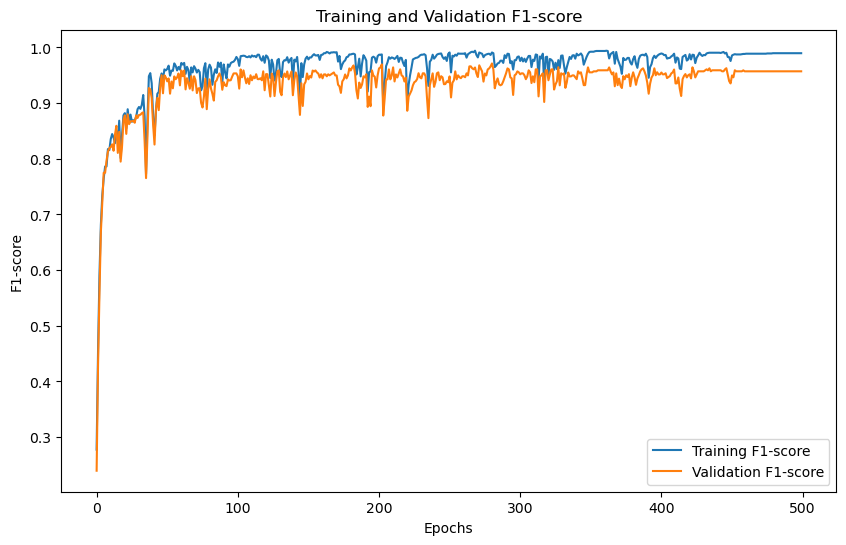

'Model Training and Evaluation Successfully completed'

In [16]:
train_model()

# dwt 4

# 500 epoch

Enter dataset name:
tess, savee, crema, ravdess
 tess
Enter dwt level:  4
No. of classes 7
Input size : 1
Hidden Size : 256
Model Name: LSTMModel

X Shape : (2800, 200, 1)
Y Shape : (2800, 7)
Training with DWT level: 4
Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.8458, Training Accuracy: 0.3723, Training Precision:0.2918,Training Recall:0.3723,Training F1-Score:0.2603
Validation Loss: 1.7671, Validation Accuracy: 0.3643, Validation Precision:0.3697,Validation Recall:0.3643,Validation F1-Score:0.2521
Epoch [2/500],
Training Loss: 1.6546, Training Accuracy: 0.6384, Training Precision:0.6574,Training Recall:0.6384,Training F1-Score:0.5947
Validation Loss: 1.5337, Validation Accuracy: 0.6536, Validation Precision:0.6902,Validation Recall:0.6536,Validation F1-Score:0.6166
Epoch [3/500],
Training Loss: 1.5443, Training Accuracy: 0.6433, Training Precision:0.5607,Training Recall:0.6433,Training F1-Score:0.5933
Validation Loss: 1.5100, Validation Accuracy: 0.6518, Validation Precisi

Epoch [31/500],
Training Loss: 1.3330, Training Accuracy: 0.8308, Training Precision:0.8494,Training Recall:0.8308,Training F1-Score:0.8192
Validation Loss: 1.3520, Validation Accuracy: 0.8125, Validation Precision:0.8201,Validation Recall:0.8125,Validation F1-Score:0.8029
Epoch [32/500],
Training Loss: 1.3272, Training Accuracy: 0.8473, Training Precision:0.8798,Training Recall:0.8473,Training F1-Score:0.8453
Validation Loss: 1.3319, Validation Accuracy: 0.8321, Validation Precision:0.8600,Validation Recall:0.8321,Validation F1-Score:0.8310
Epoch [33/500],
Training Loss: 1.3266, Training Accuracy: 0.8379, Training Precision:0.8534,Training Recall:0.8379,Training F1-Score:0.8304
Validation Loss: 1.3210, Validation Accuracy: 0.8429, Validation Precision:0.8497,Validation Recall:0.8429,Validation F1-Score:0.8375
Epoch [34/500],
Training Loss: 1.3243, Training Accuracy: 0.8496, Training Precision:0.8759,Training Recall:0.8496,Training F1-Score:0.8449
Validation Loss: 1.3331, Validation Ac

Epoch [61/500],
Training Loss: 1.5524, Training Accuracy: 0.6701, Training Precision:0.7788,Training Recall:0.6701,Training F1-Score:0.6427
Validation Loss: 1.4979, Validation Accuracy: 0.6643, Validation Precision:0.7551,Validation Recall:0.6643,Validation F1-Score:0.6337
Epoch [62/500],
Training Loss: 1.4418, Training Accuracy: 0.8049, Training Precision:0.8189,Training Recall:0.8049,Training F1-Score:0.7929
Validation Loss: 1.3448, Validation Accuracy: 0.8232, Validation Precision:0.8375,Validation Recall:0.8232,Validation F1-Score:0.8116
Epoch [63/500],
Training Loss: 1.3571, Training Accuracy: 0.8129, Training Precision:0.8188,Training Recall:0.8129,Training F1-Score:0.8088
Validation Loss: 1.3546, Validation Accuracy: 0.8125, Validation Precision:0.8214,Validation Recall:0.8125,Validation F1-Score:0.8099
Epoch [64/500],
Training Loss: 1.3121, Training Accuracy: 0.8598, Training Precision:0.8712,Training Recall:0.8598,Training F1-Score:0.8529
Validation Loss: 1.2989, Validation Ac

Epoch [91/500],
Training Loss: 1.2026, Training Accuracy: 0.9661, Training Precision:0.9665,Training Recall:0.9661,Training F1-Score:0.9661
Validation Loss: 1.2238, Validation Accuracy: 0.9429, Validation Precision:0.9437,Validation Recall:0.9429,Validation F1-Score:0.9430
Epoch [92/500],
Training Loss: 1.1979, Training Accuracy: 0.9554, Training Precision:0.9588,Training Recall:0.9554,Training F1-Score:0.9553
Validation Loss: 1.2306, Validation Accuracy: 0.9357, Validation Precision:0.9402,Validation Recall:0.9357,Validation F1-Score:0.9354
Epoch [93/500],
Training Loss: 1.1948, Training Accuracy: 0.9670, Training Precision:0.9673,Training Recall:0.9670,Training F1-Score:0.9669
Validation Loss: 1.2249, Validation Accuracy: 0.9429, Validation Precision:0.9435,Validation Recall:0.9429,Validation F1-Score:0.9426
Epoch [94/500],
Training Loss: 1.1982, Training Accuracy: 0.9696, Training Precision:0.9698,Training Recall:0.9696,Training F1-Score:0.9696
Validation Loss: 1.2122, Validation Ac

Epoch [121/500],
Training Loss: 1.1916, Training Accuracy: 0.9772, Training Precision:0.9772,Training Recall:0.9772,Training F1-Score:0.9772
Validation Loss: 1.2278, Validation Accuracy: 0.9357, Validation Precision:0.9363,Validation Recall:0.9357,Validation F1-Score:0.9356
Epoch [122/500],
Training Loss: 1.1970, Training Accuracy: 0.9763, Training Precision:0.9767,Training Recall:0.9763,Training F1-Score:0.9763
Validation Loss: 1.2251, Validation Accuracy: 0.9411, Validation Precision:0.9437,Validation Recall:0.9411,Validation F1-Score:0.9412
Epoch [123/500],
Training Loss: 1.1939, Training Accuracy: 0.9826, Training Precision:0.9827,Training Recall:0.9826,Training F1-Score:0.9826
Validation Loss: 1.2065, Validation Accuracy: 0.9589, Validation Precision:0.9594,Validation Recall:0.9589,Validation F1-Score:0.9588
Epoch [124/500],
Training Loss: 1.1865, Training Accuracy: 0.9772, Training Precision:0.9776,Training Recall:0.9772,Training F1-Score:0.9772
Validation Loss: 1.2139, Validatio

...

Epoch [361/500],
Training Loss: 1.1744, Training Accuracy: 0.9911, Training Precision:0.9911,Training Recall:0.9911,Training F1-Score:0.9911
Validation Loss: 1.1964, Validation Accuracy: 0.9679, Validation Precision:0.9679,Validation Recall:0.9679,Validation F1-Score:0.9678
Epoch [362/500],
Training Loss: 1.1744, Training Accuracy: 0.9911, Training Precision:0.9911,Training Recall:0.9911,Training F1-Score:0.9911
Validation Loss: 1.1964, Validation Accuracy: 0.9679, Validation Precision:0.9679,Validation Recall:0.9679,Validation F1-Score:0.9678
Epoch [363/500],
Training Loss: 1.1744, Training Accuracy: 0.9911, Training Precision:0.9911,Training Recall:0.9911,Training F1-Score:0.9911
Validation Loss: 1.1964, Validation Accuracy: 0.9679, Validation Precision:0.9679,Validation Recall:0.9679,Validation F1-Score:0.9678
Epoch [364/500],
Training Loss: 1.1744, Training Accuracy: 0.9911, Training Precision:0.9911,Training Recall:0.9911,Training F1-Score:0.9911
Validation Loss: 1.1964, Validatio

Epoch [391/500],
Training Loss: 1.1744, Training Accuracy: 0.9911, Training Precision:0.9911,Training Recall:0.9911,Training F1-Score:0.9911
Validation Loss: 1.1963, Validation Accuracy: 0.9679, Validation Precision:0.9679,Validation Recall:0.9679,Validation F1-Score:0.9678
Epoch [392/500],
Training Loss: 1.1744, Training Accuracy: 0.9911, Training Precision:0.9911,Training Recall:0.9911,Training F1-Score:0.9911
Validation Loss: 1.1963, Validation Accuracy: 0.9679, Validation Precision:0.9679,Validation Recall:0.9679,Validation F1-Score:0.9678
Epoch [393/500],
Training Loss: 1.1744, Training Accuracy: 0.9911, Training Precision:0.9911,Training Recall:0.9911,Training F1-Score:0.9911
Validation Loss: 1.1962, Validation Accuracy: 0.9679, Validation Precision:0.9679,Validation Recall:0.9679,Validation F1-Score:0.9678
Epoch [394/500],
Training Loss: 1.1744, Training Accuracy: 0.9911, Training Precision:0.9911,Training Recall:0.9911,Training F1-Score:0.9911
Validation Loss: 1.1962, Validatio

Epoch [421/500],
Training Loss: 1.1744, Training Accuracy: 0.9911, Training Precision:0.9911,Training Recall:0.9911,Training F1-Score:0.9911
Validation Loss: 1.1960, Validation Accuracy: 0.9679, Validation Precision:0.9679,Validation Recall:0.9679,Validation F1-Score:0.9678
Epoch [422/500],
Training Loss: 1.1744, Training Accuracy: 0.9911, Training Precision:0.9911,Training Recall:0.9911,Training F1-Score:0.9911
Validation Loss: 1.1960, Validation Accuracy: 0.9679, Validation Precision:0.9679,Validation Recall:0.9679,Validation F1-Score:0.9678
Epoch [423/500],
Training Loss: 1.1744, Training Accuracy: 0.9911, Training Precision:0.9911,Training Recall:0.9911,Training F1-Score:0.9911
Validation Loss: 1.1960, Validation Accuracy: 0.9679, Validation Precision:0.9679,Validation Recall:0.9679,Validation F1-Score:0.9678
Epoch [424/500],
Training Loss: 1.1744, Training Accuracy: 0.9911, Training Precision:0.9911,Training Recall:0.9911,Training F1-Score:0.9911
Validation Loss: 1.1960, Validatio

Epoch [451/500],
Training Loss: 1.1744, Training Accuracy: 0.9911, Training Precision:0.9911,Training Recall:0.9911,Training F1-Score:0.9911
Validation Loss: 1.1957, Validation Accuracy: 0.9679, Validation Precision:0.9679,Validation Recall:0.9679,Validation F1-Score:0.9678
Epoch [452/500],
Training Loss: 1.1744, Training Accuracy: 0.9911, Training Precision:0.9911,Training Recall:0.9911,Training F1-Score:0.9911
Validation Loss: 1.1957, Validation Accuracy: 0.9679, Validation Precision:0.9679,Validation Recall:0.9679,Validation F1-Score:0.9678
Epoch [453/500],
Training Loss: 1.1744, Training Accuracy: 0.9911, Training Precision:0.9911,Training Recall:0.9911,Training F1-Score:0.9911
Validation Loss: 1.1957, Validation Accuracy: 0.9679, Validation Precision:0.9679,Validation Recall:0.9679,Validation F1-Score:0.9678
Epoch [454/500],
Training Loss: 1.1744, Training Accuracy: 0.9911, Training Precision:0.9911,Training Recall:0.9911,Training F1-Score:0.9911
Validation Loss: 1.1956, Validatio

Epoch [481/500],
Training Loss: 1.1744, Training Accuracy: 0.9911, Training Precision:0.9911,Training Recall:0.9911,Training F1-Score:0.9911
Validation Loss: 1.1953, Validation Accuracy: 0.9679, Validation Precision:0.9679,Validation Recall:0.9679,Validation F1-Score:0.9678
Epoch [482/500],
Training Loss: 1.1744, Training Accuracy: 0.9911, Training Precision:0.9911,Training Recall:0.9911,Training F1-Score:0.9911
Validation Loss: 1.1953, Validation Accuracy: 0.9696, Validation Precision:0.9697,Validation Recall:0.9696,Validation F1-Score:0.9696
Epoch [483/500],
Training Loss: 1.1744, Training Accuracy: 0.9911, Training Precision:0.9911,Training Recall:0.9911,Training F1-Score:0.9911
Validation Loss: 1.1953, Validation Accuracy: 0.9696, Validation Precision:0.9697,Validation Recall:0.9696,Validation F1-Score:0.9696
Epoch [484/500],
Training Loss: 1.1744, Training Accuracy: 0.9911, Training Precision:0.9911,Training Recall:0.9911,Training F1-Score:0.9911
Validation Loss: 1.1953, Validatio

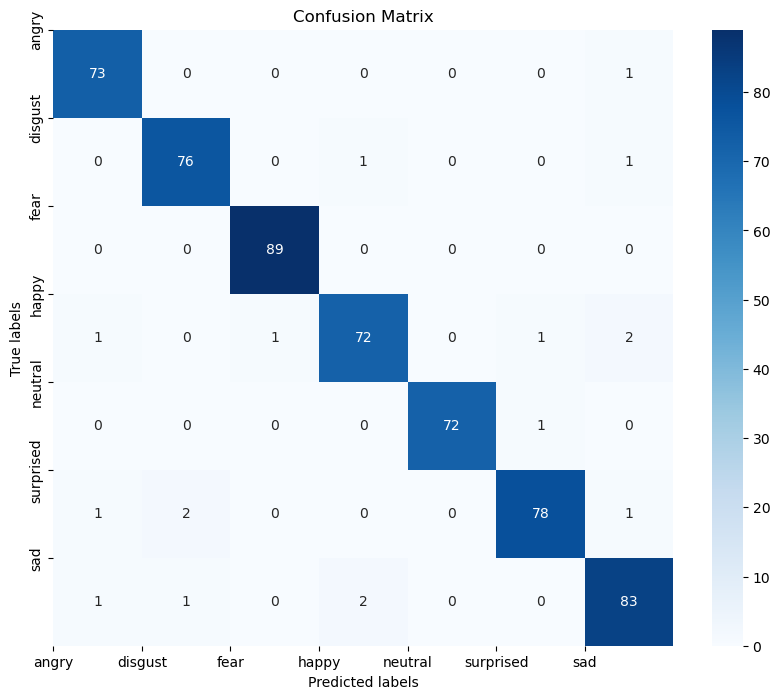

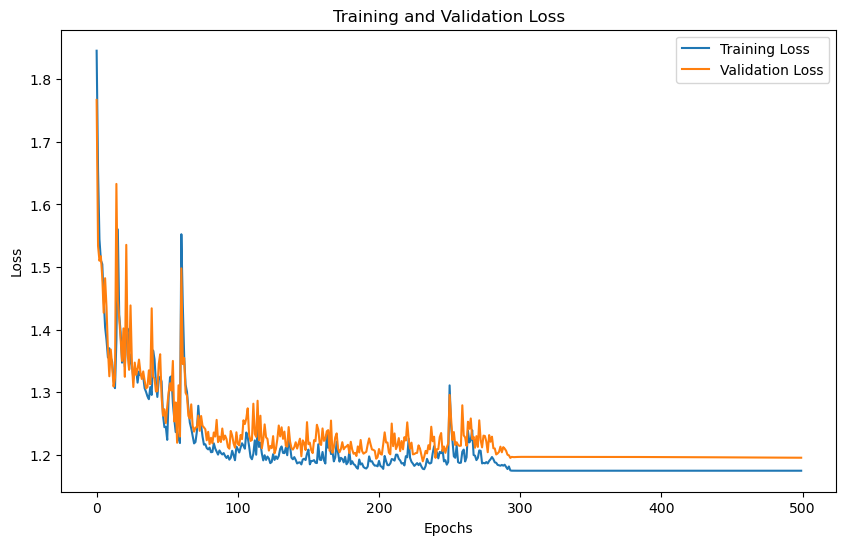

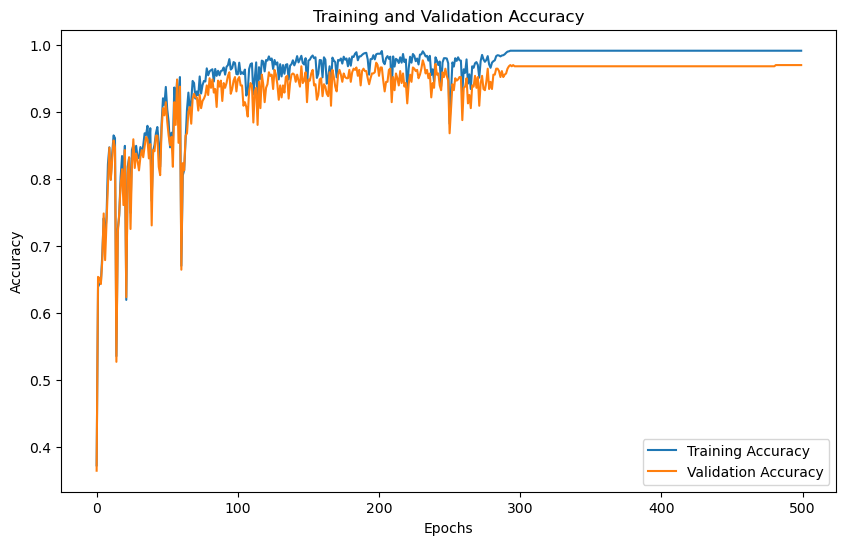

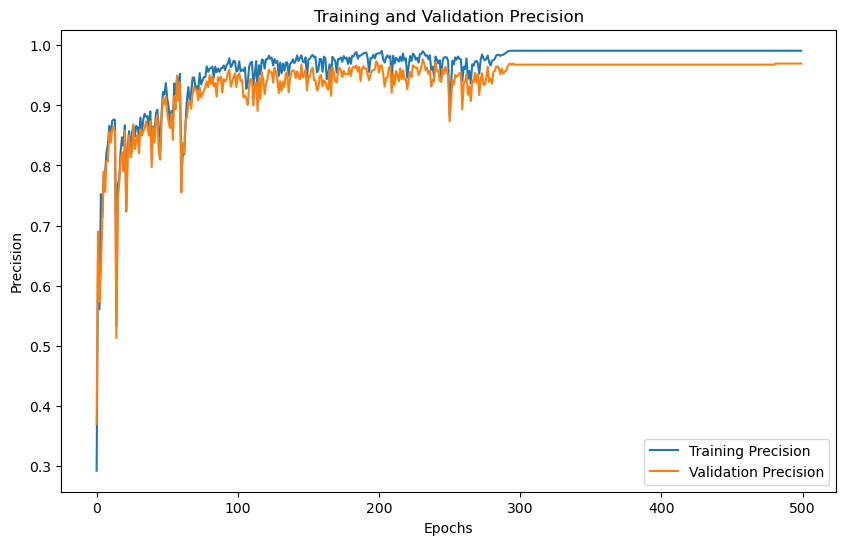

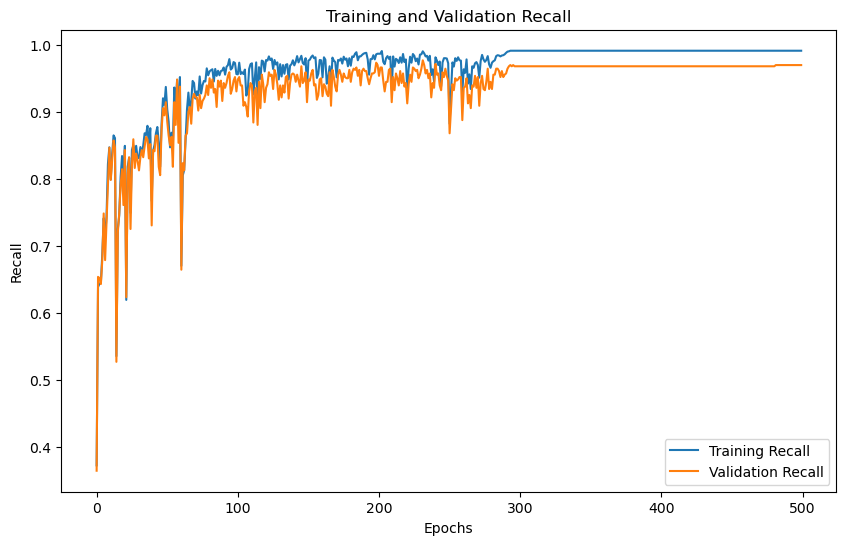

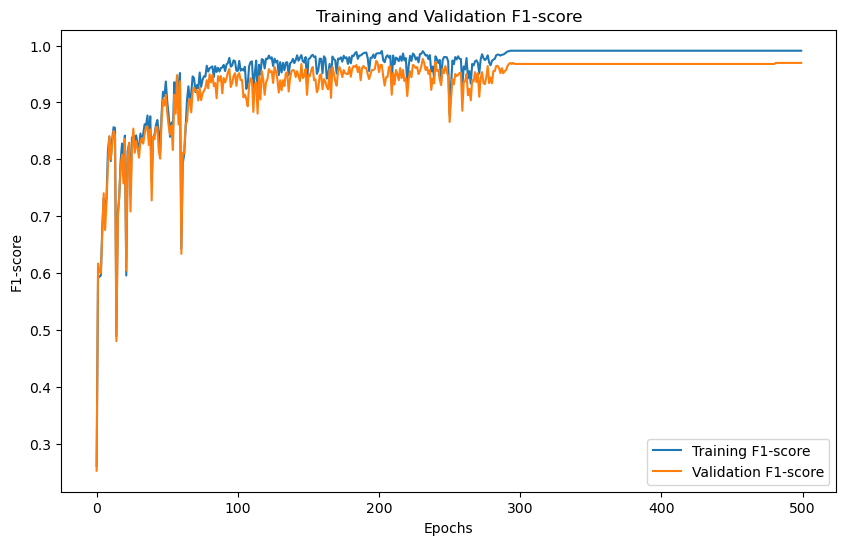

'Model Training and Evaluation Successfully completed'

In [13]:
train_model()

# dwt 5

# 500 epoch

Enter dataset name:
tess, savee, crema, ravdess
 tess
Enter dwt level:  5
No. of classes 7
Input size : 1
Hidden Size : 256
Model Name: LSTMModel

X Shape : (2800, 240, 1)
Y Shape : (2800, 7)
Training with DWT level: 5
Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.8389, Training Accuracy: 0.3455, Training Precision:0.2933,Training Recall:0.3455,Training F1-Score:0.2567
Validation Loss: 1.8747, Validation Accuracy: 0.3036, Validation Precision:0.2053,Validation Recall:0.3036,Validation F1-Score:0.2243
Epoch [2/500],
Training Loss: 1.6664, Training Accuracy: 0.5915, Training Precision:0.5333,Training Recall:0.5915,Training F1-Score:0.5410
Validation Loss: 1.6116, Validation Accuracy: 0.5839, Validation Precision:0.5181,Validation Recall:0.5839,Validation F1-Score:0.5291
Epoch [3/500],
Training Loss: 1.5486, Training Accuracy: 0.6518, Training Precision:0.6453,Training Recall:0.6518,Training F1-Score:0.5876
Validation Loss: 1.5304, Validation Accuracy: 0.6375, Validation Precisi

Epoch [31/500],
Training Loss: 1.3404, Training Accuracy: 0.8290, Training Precision:0.7278,Training Recall:0.8290,Training F1-Score:0.7713
Validation Loss: 1.3602, Validation Accuracy: 0.8036, Validation Precision:0.6989,Validation Recall:0.8036,Validation F1-Score:0.7422
Epoch [32/500],
Training Loss: 1.3433, Training Accuracy: 0.8348, Training Precision:0.7298,Training Recall:0.8348,Training F1-Score:0.7759
Validation Loss: 1.3541, Validation Accuracy: 0.8107, Validation Precision:0.6987,Validation Recall:0.8107,Validation F1-Score:0.7471
Epoch [33/500],
Training Loss: 1.3387, Training Accuracy: 0.8313, Training Precision:0.7278,Training Recall:0.8313,Training F1-Score:0.7730
Validation Loss: 1.3602, Validation Accuracy: 0.8018, Validation Precision:0.6919,Validation Recall:0.8018,Validation F1-Score:0.7392
Epoch [34/500],
Training Loss: 1.3412, Training Accuracy: 0.8313, Training Precision:0.7260,Training Recall:0.8313,Training F1-Score:0.7726
Validation Loss: 1.3556, Validation Ac

Epoch [61/500],
Training Loss: 1.3287, Training Accuracy: 0.8460, Training Precision:0.7376,Training Recall:0.8460,Training F1-Score:0.7856
Validation Loss: 1.3438, Validation Accuracy: 0.8214, Validation Precision:0.7057,Validation Recall:0.8214,Validation F1-Score:0.7561
Epoch [62/500],
Training Loss: 1.3304, Training Accuracy: 0.8433, Training Precision:0.7369,Training Recall:0.8433,Training F1-Score:0.7837
Validation Loss: 1.3501, Validation Accuracy: 0.8179, Validation Precision:0.7042,Validation Recall:0.8179,Validation F1-Score:0.7535
Epoch [63/500],
Training Loss: 1.3207, Training Accuracy: 0.8451, Training Precision:0.7380,Training Recall:0.8451,Training F1-Score:0.7851
Validation Loss: 1.3461, Validation Accuracy: 0.8179, Validation Precision:0.7055,Validation Recall:0.8179,Validation F1-Score:0.7537
Epoch [64/500],
Training Loss: 1.3233, Training Accuracy: 0.8384, Training Precision:0.7307,Training Recall:0.8384,Training F1-Score:0.7785
Validation Loss: 1.3652, Validation Ac

Epoch [91/500],
Training Loss: 1.1979, Training Accuracy: 0.9540, Training Precision:0.9568,Training Recall:0.9540,Training F1-Score:0.9541
Validation Loss: 1.2386, Validation Accuracy: 0.9250, Validation Precision:0.9273,Validation Recall:0.9250,Validation F1-Score:0.9249
Epoch [92/500],
Training Loss: 1.2062, Training Accuracy: 0.9607, Training Precision:0.9627,Training Recall:0.9607,Training F1-Score:0.9609
Validation Loss: 1.2428, Validation Accuracy: 0.9232, Validation Precision:0.9301,Validation Recall:0.9232,Validation F1-Score:0.9241
Epoch [93/500],
Training Loss: 1.2332, Training Accuracy: 0.9549, Training Precision:0.9555,Training Recall:0.9549,Training F1-Score:0.9548
Validation Loss: 1.2419, Validation Accuracy: 0.9232, Validation Precision:0.9278,Validation Recall:0.9232,Validation F1-Score:0.9234
Epoch [94/500],
Training Loss: 1.2026, Training Accuracy: 0.9522, Training Precision:0.9539,Training Recall:0.9522,Training F1-Score:0.9515
Validation Loss: 1.2294, Validation Ac

Epoch [121/500],
Training Loss: 1.1781, Training Accuracy: 0.9902, Training Precision:0.9902,Training Recall:0.9902,Training F1-Score:0.9902
Validation Loss: 1.2100, Validation Accuracy: 0.9518, Validation Precision:0.9524,Validation Recall:0.9518,Validation F1-Score:0.9520
Epoch [122/500],
Training Loss: 1.1778, Training Accuracy: 0.9866, Training Precision:0.9867,Training Recall:0.9866,Training F1-Score:0.9866
Validation Loss: 1.2199, Validation Accuracy: 0.9464, Validation Precision:0.9483,Validation Recall:0.9464,Validation F1-Score:0.9465
Epoch [123/500],
Training Loss: 1.1767, Training Accuracy: 0.9902, Training Precision:0.9902,Training Recall:0.9902,Training F1-Score:0.9902
Validation Loss: 1.2094, Validation Accuracy: 0.9571, Validation Precision:0.9579,Validation Recall:0.9571,Validation F1-Score:0.9573
Epoch [124/500],
Training Loss: 1.1870, Training Accuracy: 0.9830, Training Precision:0.9832,Training Recall:0.9830,Training F1-Score:0.9830
Validation Loss: 1.2090, Validatio

...

Epoch [361/500],
Training Loss: 1.1721, Training Accuracy: 0.9933, Training Precision:0.9933,Training Recall:0.9933,Training F1-Score:0.9933
Validation Loss: 1.2162, Validation Accuracy: 0.9500, Validation Precision:0.9508,Validation Recall:0.9500,Validation F1-Score:0.9500
Epoch [362/500],
Training Loss: 1.1721, Training Accuracy: 0.9933, Training Precision:0.9933,Training Recall:0.9933,Training F1-Score:0.9933
Validation Loss: 1.2161, Validation Accuracy: 0.9500, Validation Precision:0.9508,Validation Recall:0.9500,Validation F1-Score:0.9500
Epoch [363/500],
Training Loss: 1.1721, Training Accuracy: 0.9933, Training Precision:0.9933,Training Recall:0.9933,Training F1-Score:0.9933
Validation Loss: 1.2161, Validation Accuracy: 0.9500, Validation Precision:0.9508,Validation Recall:0.9500,Validation F1-Score:0.9500
Epoch [364/500],
Training Loss: 1.1721, Training Accuracy: 0.9933, Training Precision:0.9933,Training Recall:0.9933,Training F1-Score:0.9933
Validation Loss: 1.2161, Validatio

Epoch [391/500],
Training Loss: 1.1721, Training Accuracy: 0.9933, Training Precision:0.9933,Training Recall:0.9933,Training F1-Score:0.9933
Validation Loss: 1.2152, Validation Accuracy: 0.9518, Validation Precision:0.9525,Validation Recall:0.9518,Validation F1-Score:0.9517
Epoch [392/500],
Training Loss: 1.1721, Training Accuracy: 0.9933, Training Precision:0.9933,Training Recall:0.9933,Training F1-Score:0.9933
Validation Loss: 1.2152, Validation Accuracy: 0.9518, Validation Precision:0.9525,Validation Recall:0.9518,Validation F1-Score:0.9517
Epoch [393/500],
Training Loss: 1.1721, Training Accuracy: 0.9933, Training Precision:0.9933,Training Recall:0.9933,Training F1-Score:0.9933
Validation Loss: 1.2152, Validation Accuracy: 0.9518, Validation Precision:0.9525,Validation Recall:0.9518,Validation F1-Score:0.9517
Epoch [394/500],
Training Loss: 1.1721, Training Accuracy: 0.9933, Training Precision:0.9933,Training Recall:0.9933,Training F1-Score:0.9933
Validation Loss: 1.2151, Validatio

Epoch [421/500],
Training Loss: 1.1721, Training Accuracy: 0.9933, Training Precision:0.9933,Training Recall:0.9933,Training F1-Score:0.9933
Validation Loss: 1.2146, Validation Accuracy: 0.9518, Validation Precision:0.9525,Validation Recall:0.9518,Validation F1-Score:0.9517
Epoch [422/500],
Training Loss: 1.1721, Training Accuracy: 0.9933, Training Precision:0.9933,Training Recall:0.9933,Training F1-Score:0.9933
Validation Loss: 1.2146, Validation Accuracy: 0.9518, Validation Precision:0.9525,Validation Recall:0.9518,Validation F1-Score:0.9517
Epoch [423/500],
Training Loss: 1.1721, Training Accuracy: 0.9933, Training Precision:0.9933,Training Recall:0.9933,Training F1-Score:0.9933
Validation Loss: 1.2146, Validation Accuracy: 0.9518, Validation Precision:0.9525,Validation Recall:0.9518,Validation F1-Score:0.9517
Epoch [424/500],
Training Loss: 1.1721, Training Accuracy: 0.9933, Training Precision:0.9933,Training Recall:0.9933,Training F1-Score:0.9933
Validation Loss: 1.2146, Validatio

Epoch [451/500],
Training Loss: 1.1721, Training Accuracy: 0.9933, Training Precision:0.9933,Training Recall:0.9933,Training F1-Score:0.9933
Validation Loss: 1.2142, Validation Accuracy: 0.9518, Validation Precision:0.9525,Validation Recall:0.9518,Validation F1-Score:0.9517
Epoch [452/500],
Training Loss: 1.1721, Training Accuracy: 0.9933, Training Precision:0.9933,Training Recall:0.9933,Training F1-Score:0.9933
Validation Loss: 1.2142, Validation Accuracy: 0.9518, Validation Precision:0.9525,Validation Recall:0.9518,Validation F1-Score:0.9517
Epoch [453/500],
Training Loss: 1.1721, Training Accuracy: 0.9933, Training Precision:0.9933,Training Recall:0.9933,Training F1-Score:0.9933
Validation Loss: 1.2142, Validation Accuracy: 0.9518, Validation Precision:0.9525,Validation Recall:0.9518,Validation F1-Score:0.9517
Epoch [454/500],
Training Loss: 1.1721, Training Accuracy: 0.9933, Training Precision:0.9933,Training Recall:0.9933,Training F1-Score:0.9933
Validation Loss: 1.2142, Validatio

Epoch [481/500],
Training Loss: 1.2053, Training Accuracy: 0.9411, Training Precision:0.9457,Training Recall:0.9411,Training F1-Score:0.9414
Validation Loss: 1.2576, Validation Accuracy: 0.9089, Validation Precision:0.9170,Validation Recall:0.9089,Validation F1-Score:0.9095
Epoch [482/500],
Training Loss: 1.2359, Training Accuracy: 0.9433, Training Precision:0.9442,Training Recall:0.9433,Training F1-Score:0.9433
Validation Loss: 1.2515, Validation Accuracy: 0.9107, Validation Precision:0.9143,Validation Recall:0.9107,Validation F1-Score:0.9110
Epoch [483/500],
Training Loss: 1.2183, Training Accuracy: 0.9500, Training Precision:0.9515,Training Recall:0.9500,Training F1-Score:0.9498
Validation Loss: 1.2284, Validation Accuracy: 0.9375, Validation Precision:0.9407,Validation Recall:0.9375,Validation F1-Score:0.9372
Epoch [484/500],
Training Loss: 1.2194, Training Accuracy: 0.9589, Training Precision:0.9613,Training Recall:0.9589,Training F1-Score:0.9591
Validation Loss: 1.2357, Validatio

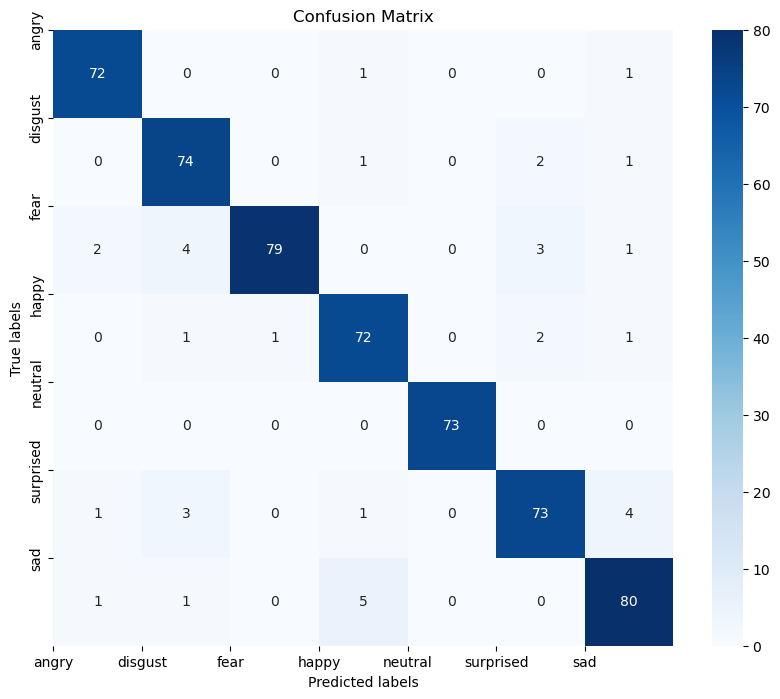

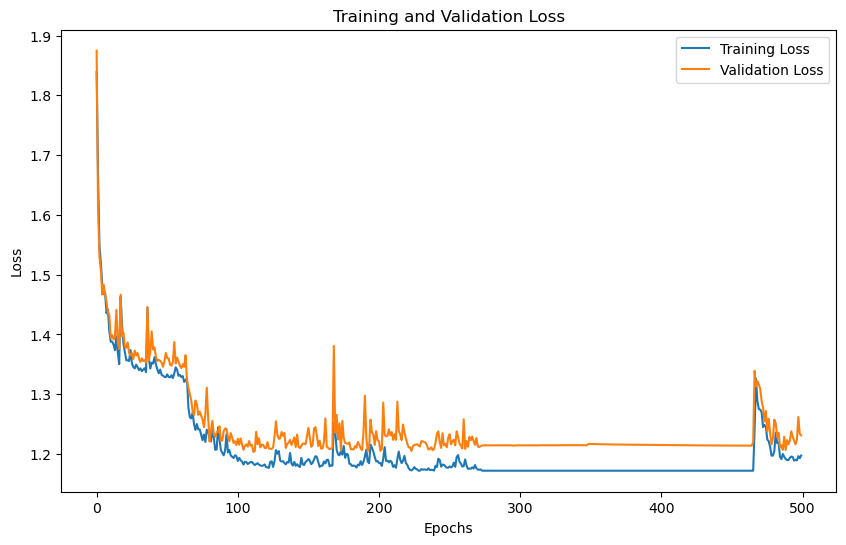

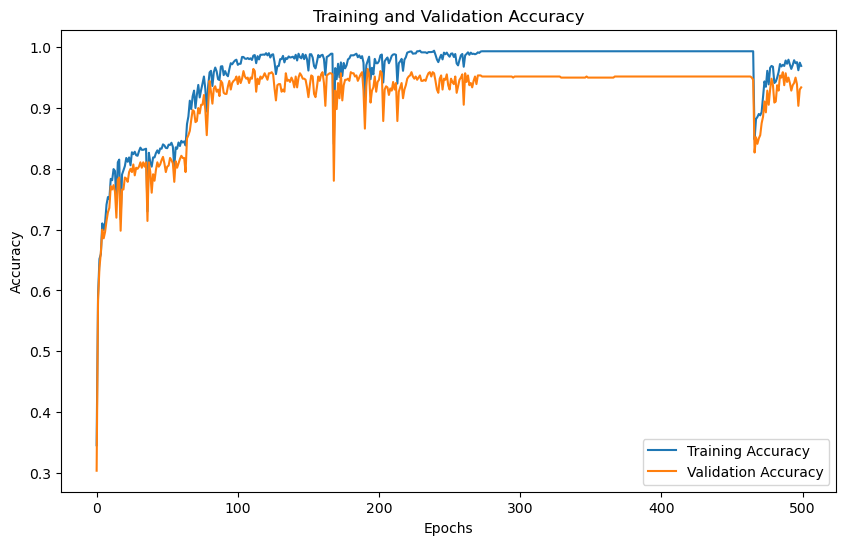

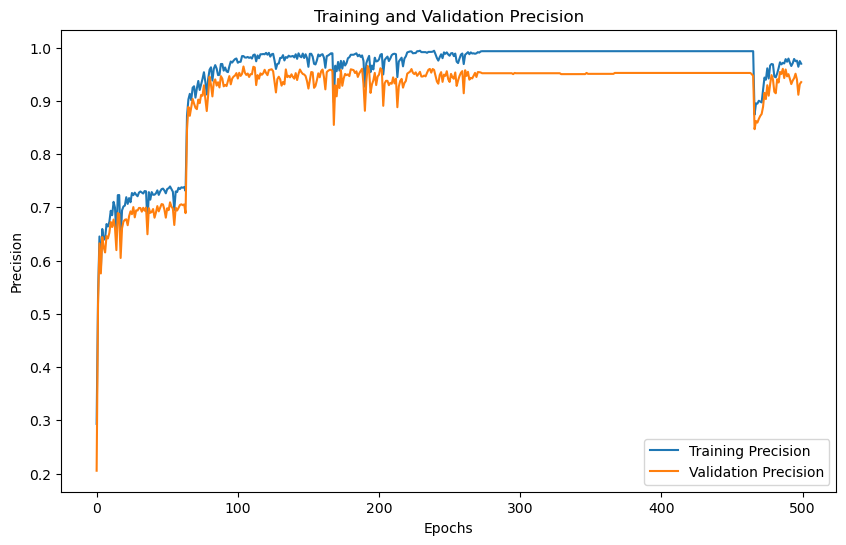

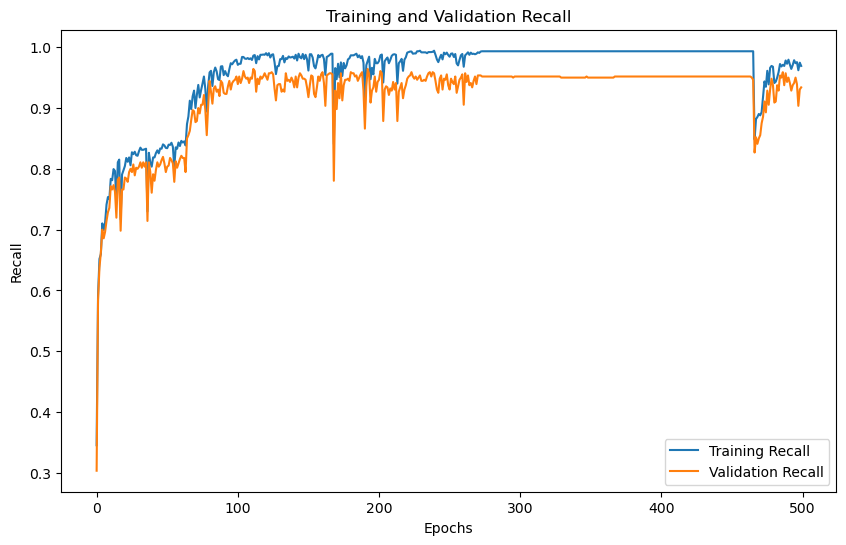

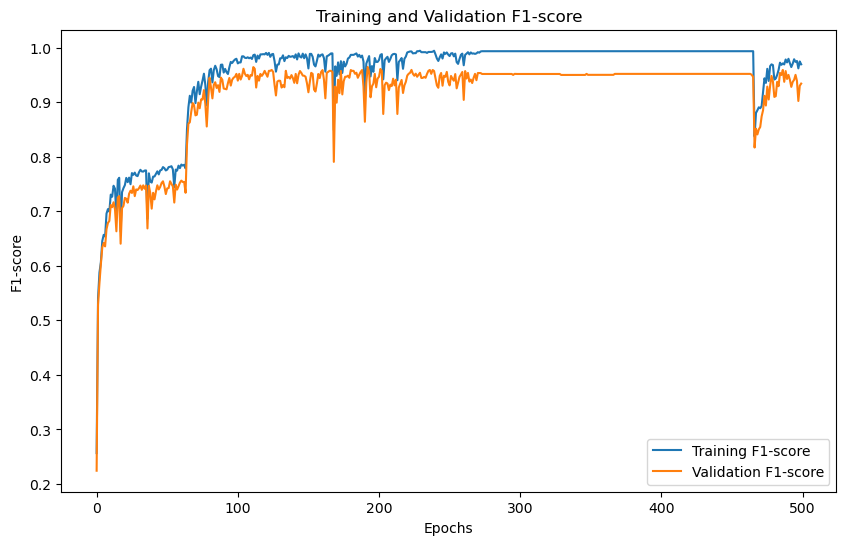

'Model Training and Evaluation Successfully completed'

In [14]:
train_model()